# 2026 CITS4012 Project
*Make sure you change the file name with your group id.*

# Readme
*If there is something to be noted for the marker, please mention here.*

*If you are planning to implement a program with Object Oriented Programming style, please put those the bottom of this ipynb file*

## Project overview

This notebook implements and evaluates a BiLSTM-based model for the PIQA physical commonsense reasoning task. It is organised into Dataset Processing, Model Implementation, and Testing and Evaluation.

## Runtime and execution

- Run cells marked `[RUN]` from top to bottom. Cells marked `[RUN ONCE]` reproduce longer experiments and do not need to be rerun when reviewing the saved outputs.
- Experiments use a fixed stratified train/validation split with `random_state=0`. Unless stated otherwise, comparisons use seeds `0`, `1`, and `2`.
- Step 13.1 and Step 13.2 initialise the checkpoint metadata and Google Drive backup helpers required by the later Step 15 experiments.
- Local Step 15 checkpoints and result files are stored under `step15_outputs/`. Copies are uploaded to the shared Google Drive folder.

## Notes for the marker

- Completed result tables and plots are retained in the notebook, so the long training cells can be skipped when reviewing the submission.
- Steps 13.6, 15C.5, and 15E.5 can restore their data and checkpoints from Google Drive in a fresh runtime.

# 1.Dataset Processing
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

---
### PART 0 — Setup

In [1]:
# @title [RUN] Environment set-up
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from collections import Counter
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

cuda


In [2]:
# @title [RUN] Download the PIQA data from Drive
# the four PIQA files are zipped together on Drive, shared as "anyone with the link"
# so this works on any Colab account without uploading anything

piqa_data_id = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
!gdown -q $piqa_data_id -O piqa_data.zip
!unzip -q -o piqa_data.zip

import os
for file_name in ["train.jsonl", "train-labels.lst", "test.jsonl", "test-labels.lst"]:
    print(file_name, os.path.getsize(file_name), "bytes")


train.jsonl 4382162 bytes
train-labels.lst 32226 bytes
test.jsonl 495929 bytes
test-labels.lst 3676 bytes


---
# PART 1 — Data preparation

Nothing here needs changing. Run it all once and move on.

In [3]:
# @title [RUN] Step 1: Text processing and reading the data

# clean_str -> taken from A1
def clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()

def word_set(string):
    return set(clean_str(string).split())

# read one split into a flat list of rows ---------------------------------------
# structure -> [{'goal':.., 'sol1':.., 'sol2':.., 'label':0/1}]
# label 0 means sol1 is the correct one, label 1 means sol2
def read_piqa(data_path, label_path):
    rows = []
    data_line = open(data_path).readlines() # read JSON texts
    label_line = open(label_path).readlines() # read 0/1

    for line, lab in zip(data_line, label_line): # zip -> match the two files
        if lab.strip() == "": # skip empty lines
            continue
        d = json.loads(line) # JASON to dic
        row = {}
        row["goal"]  = d["goal"]
        row["sol1"]  = d["sol1"]
        row["sol2"]  = d["sol2"]
        row["label"] = int(lab.strip()) # from a different file. '1\n' -> 1 (int)
        rows.append(row)
    return rows
    # structure of rows
    # rows = [{'goal':'xxx', ..., "sol2":"xxx", "label":1}, {question}, {question}]

data_train_rows = read_piqa("train.jsonl", "train-labels.lst")
data_test_rows  = read_piqa("test.jsonl", "test-labels.lst")

print("train rows:", len(data_train_rows))
print("test rows :", len(data_test_rows))
print("") # Test
for r in data_train_rows[:2]:
    print("goal :", r["goal"])
    print("sol1 :", r["sol1"][:90])
    print("sol2 :", r["sol2"][:90])
    print("label:", r["label"])
    print("")


train rows: 16113
test rows : 1838

goal : When boiling butter, when it's ready, you can
sol1 : Pour it onto a plate
sol2 : Pour it into a jar
label: 1

goal : To permanently attach metal legs to a chair, you can
sol1 : Weld the metal together to get it to stay firmly in place
sol2 : Nail the metal together to get it to stay firmly in place
label: 0



In [4]:
# @title [RUN] Step 2: Data description table

def describe_data(rows, name):
    # one list per statistic -> fill them row by row, then average at the end
    goal_length     = []
    sol_length      = []
    label_list      = []
    jaccard         = []
    different_words = []

    for r in rows:
        goal_length.append(len(r["goal"].split()))

        # take the longer of the two solutions -> maxlength has to fit both
        sol_length.append(max(len(r["sol1"].split()), len(r["sol2"].split())))

        label_list.append(r["label"])

        # how similar are the two solutions----------------------------------
        # difficulty of PIQA -> the two options are almost the same sentence
        a = word_set(r["sol1"])
        b = word_set(r["sol2"])

        # jaccard = shared words / all words -> 1 means identical, 0 means nothing in common
        jaccard.append(len(a & b) / len(a | b))

        # symmetric difference -> how many words are in one solution but not the other
        different_words.append(len(a ^ b))

    # [pack into one dict]-----------------------------------------------------
    output_row = {}
    output_row["set"]                  = name
    output_row["rows"]                 = len(rows)
    output_row["label=1 rate"]         = round(np.mean(label_list), 3)
    output_row["goal words"]           = round(np.mean(goal_length), 1)
    output_row["p95 goal words"]       = round(np.percentile(goal_length, 95))
    output_row["solution words"]       = round(np.mean(sol_length), 1)
    output_row["p95 sol words"]        = round(np.percentile(sol_length, 95))
    output_row["sol1 vs sol2 overlap"] = round(np.mean(jaccard), 3)
    output_row["different words"]      = round(np.mean(different_words), 1)
    return output_row


output_table = []
output_table.append(describe_data(data_train_rows, "training set"))

print("")
print("+++ PIQA Data +++")
print(pd.DataFrame(output_table).set_index("set").T.to_markdown())


+++ PIQA Data +++
|                      |   training set |
|:---------------------|---------------:|
| rows                 |      16113     |
| label=1 rate         |          0.5   |
| goal words           |          7.1   |
| p95 goal words       |         13     |
| solution words       |         19.4   |
| p95 sol words        |         54     |
| sol1 vs sol2 overlap |          0.654 |
| different words      |          5.4   |


In [4]:
# @title [RUN] Step 3: Split the training set

# PIQA rows are independent, so a plain stratified split is okay
# random_state fixed so everybody gets the same split -> numbers stay comparable.
# stratify on the label -> 50/50 for both parts
all_label = [r["label"] for r in data_train_rows]
train_part1, train_part2 = train_test_split(data_train_rows, test_size=0.15,
                                            random_state=0, stratify=all_label)

print("part1 (train) rows", len(train_part1))
print("part2 (val)   rows", len(train_part2))
print("test          rows", len(data_test_rows))
print("")
print("label=1 rate -> part1 %.3f, part2 %.3f" % (np.mean([r["label"] for r in train_part1]),
                                                  np.mean([r["label"] for r in train_part2])))

part1 (train) rows 13696
part2 (val)   rows 2417
test          rows 1838

label=1 rate -> part1 0.500, part2 0.500


In [5]:
# @title [RUN] Step 4: Vocabulary and make_batch_input

# same idea as A1 -> pre-allocate np.zeros and write into it.
# the vectors are made inside the model by nn.Embedding, so here we only store the index.

maxgoal = 20   # -> p95 goal words: 13
maxsol  = 60   # -> p95 sol words: 54

def build_vocabulary(rows, min_count=2): # remove if word appears less than 2 times
    # built from the TRAINING part only, not from validation or test
    word_count = Counter() # each word appears how many times
    for r in rows:
        word_count.update(clean_str(r["goal"]).split())
        word_count.update(clean_str(r["sol1"]).split())
        word_count.update(clean_str(r["sol2"]).split())

    vocabulary = {"<pad>": 0, "<unk>": 1} # 0 and 1 are reserved -> 0 for padding, 1 for unknown
    for word, n in word_count.most_common():
        if n >= min_count:
            vocabulary[word] = len(vocabulary) # next free number
    return vocabulary
    # shape of vocabulary: a dict with 11488 entries -> {'<pad>':0, '<unk>':1, 'the':2, 'a':3, ...}


def words_to_index(word_list, vocabulary, maxlength):
    index_list = np.zeros(maxlength, dtype=np.int64) # initiate with all 0s
    for i, w in enumerate(word_list):
        if i == maxlength:
            break # cut off if longer than maxlength
        if w in vocabulary:
            index_list[i] = vocabulary[w]
        else:
            index_list[i] = 1                      # Assign to 1 if unknown
    return index_list
    # shape of index_list:['weld','the','metal'] becomes [847, 2, 311, 0, 0, ... 0]


def make_batch_input(rows, vocabulary):
    n = len(rows)
    goal_index = np.zeros((n, maxgoal), dtype=np.int64)
    sol1_index = np.zeros((n, maxsol), dtype=np.int64)
    sol2_index = np.zeros((n, maxsol), dtype=np.int64)
    label      = np.zeros(n, dtype=np.int64)

    for i, r in enumerate(rows):
        goal_index[i] = words_to_index(clean_str(r["goal"]).split(), vocabulary, maxgoal)
        sol1_index[i] = words_to_index(clean_str(r["sol1"]).split(), vocabulary, maxsol)
        sol2_index[i] = words_to_index(clean_str(r["sol2"]).split(), vocabulary, maxsol)
        label[i]      = r["label"]

    return goal_index, sol1_index, sol2_index, label
    # goal_index  (13696, 20)
    # sol1_index  (13696, 60)
    # sol2_index  (13696, 60)
    # label       (13696,)
    # "word, word, word, word" -> [ 5, 10, 15, 20, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0 ]


vocabulary = build_vocabulary(train_part1, min_count=2)
print("vocabulary size:", len(vocabulary))

train_part1_input = make_batch_input(train_part1, vocabulary)
train_part2_input = make_batch_input(train_part2, vocabulary)
test_input        = make_batch_input(data_test_rows, vocabulary)


vocabulary size: 11488


# 2. Model Implementation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

---
# PART 2 — Baseline [VIKA]

In [6]:
# @title [RUN] Step 5: Dumb baselines -> the floor [VIKA TO REPLACE BASELINE ANALYSIS]

part2_gold = train_part2_input[3]

def accuracy(predicted, gold):
    return np.mean(np.array(predicted) == np.array(gold))


# baseline 1 -> always pick sol2
b1 = accuracy(np.ones(len(train_part2), dtype=np.int64), part2_gold)

# baseline 2 -> pick the longer solution
predicted = []
for r in train_part2:
    if len(r["sol2"].split()) > len(r["sol1"].split()):
        predicted.append(1)
    else:
        predicted.append(0)
b2 = accuracy(predicted, part2_gold)

# baseline 3 -> pick the solution that shares more of its words with the goal
predicted = []
for r in train_part2:
    g = word_set(r["goal"])
    o1 = len(g & word_set(r["sol1"])) / max(1, len(word_set(r["sol1"])))
    o2 = len(g & word_set(r["sol2"])) / max(1, len(word_set(r["sol2"])))
    if o2 > o1:
        predicted.append(1)
    else:
        predicted.append(0)
b3 = accuracy(predicted, part2_gold)

output_table = []
output_table.append({"baseline": "always sol2",            "accuracy": round(b1, 4)})
output_table.append({"baseline": "longer solution",        "accuracy": round(b2, 4)})
output_table.append({"baseline": "more overlap with goal", "accuracy": round(b3, 4)})

print("")
print("+++ Baselines (validation) +++")
print(pd.DataFrame(output_table).to_markdown(index=False))

floor = max(b1, b2, b3)
print("")
print("floor to beat -> %.4f" % floor)



+++ Baselines (validation) +++
| baseline               |   accuracy |
|:-----------------------|-----------:|
| always sol2            |     0.5002 |
| longer solution        |     0.4841 |
| more overlap with goal |     0.5259 |

floor to beat -> 0.5259


In [ ]:
# @title [RUN] Step 5a: Baseline B1 — Bag-of-Embeddings + MLP (validation)
#
# Strategy: learned, not pretrained.
# Same architecture as the main model with the Bi-LSTM taken out.
# Same embedding layer, same interaction features, same scorer, same training loop.
# Any gap to main model's base measures the contribution of the Bi-LSTM alone.
#
# Hypothesis: Averaging word vectors throws away word order and local context.
# We expect B1 to sit clearly below the main model base (0.6003). If it does not,
# the Bi-LSTM is not earning its place.

class BagOfEmbeddings_Model(nn.Module):
    def __init__(self, vocabulary_size, dimension=100, dropout_input=0.25):
        super(BagOfEmbeddings_Model, self).__init__()
        self.embedding    = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        self.hidden_layer = nn.Linear(dimension * 4, 100)   # 4 interaction blocks
        self.score_layer  = nn.Linear(100, 1)
        self.dropout      = nn.Dropout(dropout_input)

    def score_one_solution(self, goal_vector, solution_vector):
        # Same interaction features as the main model's scorer
        combined = torch.cat((goal_vector,
                              solution_vector,
                              goal_vector * solution_vector,
                              torch.abs(goal_vector - solution_vector)), dim=1)
        combined = self.dropout(combined)
        hidden   = torch.relu(self.hidden_layer(combined))
        return self.score_layer(hidden).squeeze(1)

    def forward(self, goal, solution1, solution2):
        # masked_pool over embeddings — no RNN
        goal_vector = masked_pool(self.embedding(goal),      goal,      "mean")
        sol1_vector = masked_pool(self.embedding(solution1), solution1, "mean")
        sol2_vector = masked_pool(self.embedding(solution2), solution2, "mean")

        score1 = self.score_one_solution(goal_vector, sol1_vector)
        score2 = self.score_one_solution(goal_vector, sol2_vector)
        output = torch.stack((score1, score2), dim=1)

        # train_model and predict_all expect (output, attention). Return empty attention dict.
        attention = {"sol1_alpha": torch.zeros_like(solution1).float(),
                     "sol2_alpha": torch.zeros_like(solution2).float(),
                     "goal_alpha": None,
                     "sol1_align": None,
                     "sol2_align": None}
        return output, attention


# --- Run B1 on validation, 3 seeds ---
print("Training B1 on 3 seeds...")
print("=" * 60)

b1_val_seed_results = []
for seed in [0, 1, 2]:
    set_seed(seed)
    model = BagOfEmbeddings_Model(len(vocabulary), dimension=100, dropout_input=0.25).to(device)
    model, best_val_acc = train_model(
        model,
        train_part1_input,
        train_part2_input,
        learning_rate = 0.001,
        batch_size    = 32,
        epochs        = 15,
        model_name    = f"B1_val_seed{seed}.pt",
        quiet         = True,
    )
    b1_val_seed_results.append(best_val_acc)
    print(f"  seed {seed} -> {best_val_acc:.4f}")

b1_val_mean = float(np.mean(b1_val_seed_results))
b1_val_sd   = float(np.std(b1_val_seed_results, ddof=1))

print()
print("=" * 60)
print(f"B1 bag-of-embeddings — VALIDATION")
print(f"  mean +/- sd (ddof=1): {b1_val_mean:.4f} +/- {b1_val_sd:.4f}")
print(f"  main model base    : 0.6003 +/- 0.0032")
print(f"  gap vs main base   : {b1_val_mean - 0.6003:+.4f}")
print("=" * 60)

pd.DataFrame({
    "seed": [0, 1, 2],
    "val_accuracy": b1_val_seed_results,
}).to_csv("B1_val_results.csv", index=False)

Training B1 on 3 seeds...
  seed 0 -> 0.5730
  seed 1 -> 0.5772
  seed 2 -> 0.5734

B1 bag-of-embeddings — VALIDATION
  mean +/- sd (ddof=1): 0.5745 +/- 0.0023
  main model base    : 0.6003 +/- 0.0032
  gap vs main base   : -0.0258


In [ ]:
# @title [RUN ONCE] 5b: B2a + B2b: pretrained encoder, frozen and fine-tuned
#
# two baselines, same checkpoint, same split, same seeds.
#   B2a  freeze the encoder, train only the classification head
#        -> how much of PIQA the pretrained representation already carries
#   B2b  fine-tune everything
#        -> what task adaptation adds on top
#
# both select the best epoch on validation, same protocol as our own train_model.
# transformers 5.x -> warmup_ratio is gone, so warmup_steps is computed by hand.

import math

def hf_accuracy(pred_output):
    logits = pred_output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    labels = pred_output.label_ids
    return {"accuracy": float((np.argmax(logits, axis=1) == labels).mean())}


def run_hf_baseline(name, freeze_encoder, epochs, learning_rate,
                    seeds=SEEDS, batch=16, test_set=None):

    steps_per_epoch = math.ceil(len(train_hf) / batch)
    warmup          = int(0.1 * steps_per_epoch * epochs)   # 10% warmup -> the collapse fix
    results         = []

    for seed in seeds:
        model = AutoModelForMultipleChoice.from_pretrained(CHECKPOINT)

        # B2a -> only the classification head is trainable
        if freeze_encoder:
            for pname, p in model.named_parameters():
                p.requires_grad = pname.startswith("classifier")

        args = TrainingArguments(
            output_dir                  = "hf_tmp",
            num_train_epochs            = epochs,
            per_device_train_batch_size = batch,
            per_device_eval_batch_size  = 32,
            learning_rate               = learning_rate,
            warmup_steps                = warmup,
            weight_decay                = 0.01,
            eval_strategy               = "epoch",
            save_strategy               = "epoch",
            save_total_limit            = 1,
            load_best_model_at_end      = True,      # -> same as our best-epoch protocol
            metric_for_best_model       = "accuracy",
            greater_is_better           = True,
            fp16                        = torch.cuda.is_available(),
            seed                        = seed,
            report_to                   = [],
            logging_steps               = 400,
            disable_tqdm                = True)

        trainer = Trainer(model=model, args=args,
                          train_dataset = train_hf,
                          eval_dataset  = val_hf,     # selection always on validation
                          data_collator = default_data_collator,
                          compute_metrics = hf_accuracy)
        trainer.train()

        v = trainer.evaluate(val_hf)["eval_accuracy"]
        if test_set is None:
            results.append(v)
            print("  %-26s seed %d -> %.4f" % (name, seed, v))
        else:
            t = trainer.evaluate(test_set)["eval_accuracy"]
            results.append(t)
            print("  %-26s seed %d -> val %.4f  test %.4f" % (name, seed, v, t))

        del model, trainer
        torch.cuda.empty_cache()

    print("")
    print("%-26s %.4f +/- %.4f" % (name, np.mean(results), np.std(results)))
    print("")
    return results


print("warmup steps per run:", int(0.1 * math.ceil(len(train_hf) / 16) * 5))
print("")

b2a_val = run_hf_baseline("B2a frozen probe", freeze_encoder=True,
                          epochs=5, learning_rate=1e-3)

b2b_val = run_hf_baseline("B2b fine-tuned", freeze_encoder=False,
                          epochs=5, learning_rate=2e-5)

warmup steps per run: 428



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaForMultipleChoice LOAD REPORT from: distilroberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
classifier.bias           | MISSING    | 
classifier.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6933', 'grad_norm': '0.6332', 'learning_rate': '0.0009322', 'epoch': '0.4673'}
{'loss': '0.695', 'grad_norm': '0.6318', 'learning_rate': '0.0009037', 'epoch': '0.9346'}
{'eval_loss': '0.6932', 'eval_accuracy': '0.5122', 'eval_runtime': '3.459', 'eval_samples_per_second': '698.7', 'eval_steps_per_second': '21.97', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

{'loss': '0.646', 'grad_norm': '7.068', 'learning_rate': '7.69e-06', 'epoch': '3.271'}
{'loss': '0.6325', 'grad_norm': '5.414', 'learning_rate': '5.613e-06', 'epoch': '3.738'}
{'eval_loss': '0.6656', 'eval_accuracy': '0.6355', 'eval_runtime': '3.844', 'eval_samples_per_second': '628.8', 'eval_steps_per_second': '19.77', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.6194', 'grad_norm': '6.927', 'learning_rate': '3.536e-06', 'epoch': '4.206'}
{'loss': '0.6017', 'grad_norm': '5.877', 'learning_rate': '1.459e-06', 'epoch': '4.673'}
{'eval_loss': '0.6693', 'eval_accuracy': '0.6388', 'eval_runtime': '3.867', 'eval_samples_per_second': '625.1', 'eval_steps_per_second': '19.66', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '559.5', 'train_samples_per_second': '122.4', 'train_steps_per_second': '7.65', 'train_loss': '0.6584', 'epoch': '5'}
{'eval_loss': '0.6693', 'eval_accuracy': '0.6388', 'eval_runtime': '3.854', 'eval_samples_per_second': '627.2', 'eval_steps_per_second': '19.72', 'epoch': '5'}
  B2b fine-tuned             seed 2 -> 0.6388

B2b fine-tuned             0.6464 +/- 0.0059



In [ ]:
# @title [RUN ONCE] Step 5c: Baseline B3 — Qwen2.5-3B zero-shot (validation)
#
# Strategy: pretrained, no task training.
# Log-likelihood scoring under a fixed prompt. 1 deterministic run.
# ~10-15 min on T4.
#
# Hypothesis: A 3B-parameter zero-shot LLM should outperform us by a large margin,
# giving a sense of the headroom from pretraining scale.

!pip -q install transformers accelerate

import time
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_MODEL = "Qwen/Qwen2.5-3B-Instruct"
SHORT_NAME = "Qwen2.5-3B"

print(f"Loading {LLM_MODEL}...")
tokenizer_b3 = AutoTokenizer.from_pretrained(LLM_MODEL)
model_b3 = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)
model_b3.eval()


def score_llm_candidate(goal, solution):
    """Average log-likelihood of solution tokens given goal context."""
    prompt = f"Goal: {goal}\nSolution:"
    full   = f"{prompt} {solution}"

    enc_prompt = tokenizer_b3(prompt, return_tensors="pt").to(model_b3.device)
    enc_full   = tokenizer_b3(full,   return_tensors="pt").to(model_b3.device)

    with torch.no_grad():
        logits = model_b3(enc_full.input_ids).logits

    log_probs = torch.log_softmax(logits[0, :-1], dim=-1)
    token_ids = enc_full.input_ids[0, 1:]
    token_lps = log_probs[torch.arange(len(token_ids)), token_ids]

    # Only count tokens that belong to the solution
    prompt_len = enc_prompt.input_ids.shape[1]
    solution_lps = token_lps[prompt_len - 1:]
    return solution_lps.mean().item()


# train_part2 = Daniel's validation list of row dicts
print(f"\nEvaluating {SHORT_NAME} zero-shot on {len(train_part2)} validation examples...")
print("=" * 60)

correct = 0
b3_val_predictions = []
start = time.time()

for i, r in enumerate(train_part2):
    s1 = score_llm_candidate(r["goal"], r["sol1"])
    s2 = score_llm_candidate(r["goal"], r["sol2"])
    pred = 0 if s1 > s2 else 1
    b3_val_predictions.append({"index": i, "gold": r["label"], "prediction": pred,
                               "score_sol1": s1, "score_sol2": s2})
    if pred == r["label"]:
        correct += 1
    if (i + 1) % 200 == 0:
        elapsed = time.time() - start
        eta = elapsed / (i + 1) * (len(train_part2) - i - 1) / 60
        print(f"  {i+1}/{len(train_part2)}  running_acc = {correct/(i+1):.4f}  eta = {eta:.1f}min")

b3_val_acc = correct / len(train_part2)

print()
print("=" * 60)
print(f"B3 {SHORT_NAME} zero-shot — VALIDATION")
print(f"  val accuracy       : {b3_val_acc:.4f}  (deterministic, 1 run)")
print(f"  main model base    : 0.6003 +/- 0.0032")
print(f"  gap vs main base   : {b3_val_acc - 0.6003:+.4f}")
print("=" * 60)

pd.DataFrame(b3_val_predictions).to_csv("B3_val_predictions.csv", index=False)
pd.DataFrame([{
    "model": SHORT_NAME, "checkpoint": LLM_MODEL,
    "val_accuracy": b3_val_acc, "n_examples": len(train_part2),
}]).to_csv("B3_val_summary.csv", index=False)

del model_b3
torch.cuda.empty_cache()

Loading Qwen/Qwen2.5-3B-Instruct...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


Evaluating Qwen2.5-3B zero-shot on 2417 validation examples...
  200/2417  running_acc = 0.8050  eta = 12.5min
  400/2417  running_acc = 0.7850  eta = 8.7min
  600/2417  running_acc = 0.7750  eta = 7.5min
  800/2417  running_acc = 0.7725  eta = 6.2min
  1000/2417  running_acc = 0.7760  eta = 5.2min
  1200/2417  running_acc = 0.7858  eta = 4.4min
  1400/2417  running_acc = 0.7821  eta = 3.6min
  1600/2417  running_acc = 0.7812  eta = 2.8min
  1800/2417  running_acc = 0.7822  eta = 2.1min
  2000/2417  running_acc = 0.7830  eta = 1.4min
  2200/2417  running_acc = 0.7795  eta = 0.7min
  2400/2417  running_acc = 0.7837  eta = 0.1min

B3 Qwen2.5-3B zero-shot — VALIDATION
  val accuracy       : 0.7844  (deterministic, 1 run)
  main model base    : 0.6003 +/- 0.0032
  gap vs main base   : +0.1841


In [ ]:
# @title [RUN] Step 5d: B0 on TEST set
#
# No training. Just applies the same two heuristics to the test split.
# Majority: constant predictor of class 1 (sol2).
# Lexical overlap: pick the candidate sharing more words with the goal.

test_gold = test_input[3]
N_test = len(data_test_rows)

# Majority (constant sol2 predictor)
b0_majority_test = np.mean(np.ones(N_test, dtype=np.int64) == test_gold)

# Lexical overlap on test
predicted = []
for r in data_test_rows:
    g  = word_set(r["goal"])
    o1 = len(g & word_set(r["sol1"])) / max(1, len(word_set(r["sol1"])))
    o2 = len(g & word_set(r["sol2"])) / max(1, len(word_set(r["sol2"])))
    predicted.append(1 if o2 > o1 else 0)
b0_overlap_test = np.mean(np.array(predicted) == test_gold)

print("B0 on TEST (n=%d)" % N_test)
print("  majority (constant sol2):  %.4f  (val was 0.5002)" % b0_majority_test)
print("  lexical overlap        :   %.4f  (val was 0.5259)" % b0_overlap_test)

pd.DataFrame([
    {"system": "majority",        "val": 0.5002, "test": b0_majority_test},
    {"system": "lexical overlap", "val": 0.5259, "test": b0_overlap_test},
]).to_csv("test_B0.csv", index=False)

B0 on TEST (n=1838)
  majority (constant sol2):  0.5049  (val was 0.5002)
  lexical overlap        :   0.5435  (val was 0.5259)


In [ ]:
# @title [RUN] Step 5e: B2a + B2b on the test set
#
# the recipe is frozen at this point. identical to the validation cell above:
# same checkpoint, same split, same seeds, same epochs, same warmup, same
# best-epoch-on-validation selection. the only addition is one evaluation on
# the test split after training, which is the only place the test set is used.
#
# report the val and test numbers printed HERE, not the ones from the cell
# above -> both columns then come from the same runs.
#
# about 45 min on a T4.

test_hf = PIQA_HF_Dataset(data_test_rows)
print("test rows:", len(test_hf))
print("")


def test_hf_baseline(name, freeze_encoder, epochs, learning_rate,
                     seeds=SEEDS, batch=16):

    steps_per_epoch = math.ceil(len(train_hf) / batch)
    warmup          = int(0.1 * steps_per_epoch * epochs)
    val_scores, test_scores = [], []

    for seed in seeds:
        model = AutoModelForMultipleChoice.from_pretrained(CHECKPOINT)

        if freeze_encoder:
            for pname, p in model.named_parameters():
                p.requires_grad = pname.startswith("classifier")

        args = TrainingArguments(
            output_dir                  = "hf_tmp",
            num_train_epochs            = epochs,
            per_device_train_batch_size = batch,
            per_device_eval_batch_size  = 32,
            learning_rate               = learning_rate,
            warmup_steps                = warmup,
            weight_decay                = 0.01,
            eval_strategy               = "epoch",
            save_strategy               = "epoch",
            save_total_limit            = 1,
            load_best_model_at_end      = True,
            metric_for_best_model       = "accuracy",
            greater_is_better           = True,
            fp16                        = torch.cuda.is_available(),
            seed                        = seed,
            report_to                   = [],
            logging_steps               = 400,
            disable_tqdm                = True)

        trainer = Trainer(model=model, args=args,
                          train_dataset   = train_hf,
                          eval_dataset    = val_hf,     # best epoch picked on VAL only
                          data_collator   = default_data_collator,
                          compute_metrics = hf_accuracy)
        trainer.train()

        v = trainer.evaluate(val_hf)["eval_accuracy"]
        t = trainer.evaluate(test_hf)["eval_accuracy"]   # test touched here and nowhere else
        val_scores.append(v)
        test_scores.append(t)
        print("  %-20s seed %d -> val %.4f   test %.4f" % (name, seed, v, t))

        del model, trainer
        torch.cuda.empty_cache()

    print("")
    print("  %-20s val  %.4f +/- %.4f" % (name, np.mean(val_scores), np.std(val_scores)))
    print("  %-20s test %.4f +/- %.4f" % (name, np.mean(test_scores), np.std(test_scores)))
    print("")
    return val_scores, test_scores


b2a_val_f, b2a_test_f = test_hf_baseline("B2a frozen probe", True,  5, 1e-3)
b2b_val_f, b2b_test_f = test_hf_baseline("B2b fine-tuned",  False, 5, 2e-5)


# ---- summary, ready to paste into the report table ----------------------------
print("")
print("+++ B2 final numbers +++")
output_table = []
for name, v, t in [("B2a frozen probe", b2a_val_f, b2a_test_f),
                   ("B2b fine-tuned",   b2b_val_f, b2b_test_f)]:
    output_table.append({
        "baseline"   : name,
        "validation" : "%.4f +/- %.4f" % (np.mean(v), np.std(v)),
        "test"       : "%.4f +/- %.4f" % (np.mean(t), np.std(t)),
        "val seeds"  : [round(float(x), 4) for x in v],
        "test seeds" : [round(float(x), 4) for x in t]})
print(pd.DataFrame(output_table).to_markdown(index=False))

test rows: 1838



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaForMultipleChoice LOAD REPORT from: distilroberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
classifier.bias           | MISSING    | 
classifier.weight         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6938', 'grad_norm': '0.6292', 'learning_rate': '0.0009322', 'epoch': '0.4673'}
{'loss': '0.6952', 'grad_norm': '0.642', 'learning_rate': '0.0009037', 'epoch': '0.9346'}
{'eval_loss': '0.6932', 'eval_accuracy': '0.5172', 'eval_runtime': '4.106', 'eval_samples_per_second': '588.7', 'eval_steps_per_second': '18.51', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

{'loss': '0.5707', 'grad_norm': '12.13', 'learning_rate': '7.69e-06', 'epoch': '3.271'}
{'loss': '0.5538', 'grad_norm': '12.18', 'learning_rate': '5.613e-06', 'epoch': '3.738'}
{'eval_loss': '0.6714', 'eval_accuracy': '0.6525', 'eval_runtime': '3.893', 'eval_samples_per_second': '620.8', 'eval_steps_per_second': '19.52', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.5279', 'grad_norm': '13.36', 'learning_rate': '3.536e-06', 'epoch': '4.206'}
{'loss': '0.5098', 'grad_norm': '10.74', 'learning_rate': '1.459e-06', 'epoch': '4.673'}
{'eval_loss': '0.6761', 'eval_accuracy': '0.6541', 'eval_runtime': '3.871', 'eval_samples_per_second': '624.4', 'eval_steps_per_second': '19.64', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '573', 'train_samples_per_second': '119.5', 'train_steps_per_second': '7.469', 'train_loss': '0.605', 'epoch': '5'}
{'eval_loss': '0.6761', 'eval_accuracy': '0.6541', 'eval_runtime': '3.844', 'eval_samples_per_second': '628.9', 'eval_steps_per_second': '19.77', 'epoch': '5'}
{'eval_loss': '0.707', 'eval_accuracy': '0.6491', 'eval_runtime': '2.936', 'eval_samples_per_second': '626.1', 'eval_steps_per_second': '19.76', 'epoch': '5'}
  B2b fine-tuned       seed 2 -> val 0.6541   test 0.6491

  B2b fine-tuned       val  0.6617 +/- 0.0054
  B2b fine-tuned       test 0.6411 +/- 0.0057


+++ B2 final numbers +++
| baseline         | validation        | test              | val seeds                | test seeds               |
|:-----------------|:------------------|:------------------|:-------------------------|:-------------------------|
| B2a frozen probe | 0.5576 +/- 0.0035 | 0.5559 +/- 0.0077 | [0.5606, 0.5528, 0.5594] | [0.5452, 0.5593, 0.5631] |
| B2b fine-tuned   | 0.6

In [ ]:
# @title [RUN ONCE — FINAL] B1 bag-of-embeddings on TEST, 3 seeds
#
# Protocol: train on train_part1, select best epoch on train_part2 (val),
# evaluate the selected checkpoint on test_input ONCE per seed.
# test_input is never passed to train_model.

# @title [RUN ONCE — FINAL] B1 bag-of-embeddings on TEST, 3 seeds
#
# Self-contained: includes class definition so no prereq cells needed
# beyond PARTs 0-1 (data), PART 3 (masked_pool), and PART 5 (train_model).

class BagOfEmbeddings_Model(nn.Module):
    def __init__(self, vocabulary_size, dimension=100, dropout_input=0.25):
        super(BagOfEmbeddings_Model, self).__init__()
        self.embedding    = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        self.hidden_layer = nn.Linear(dimension * 4, 100)
        self.score_layer  = nn.Linear(100, 1)
        self.dropout      = nn.Dropout(dropout_input)

    def score_one_solution(self, goal_vector, solution_vector):
        combined = torch.cat((goal_vector,
                              solution_vector,
                              goal_vector * solution_vector,
                              torch.abs(goal_vector - solution_vector)), dim=1)
        combined = self.dropout(combined)
        hidden   = torch.relu(self.hidden_layer(combined))
        return self.score_layer(hidden).squeeze(1)

    def forward(self, goal, solution1, solution2):
        goal_vector = masked_pool(self.embedding(goal),      goal,      "mean")
        sol1_vector = masked_pool(self.embedding(solution1), solution1, "mean")
        sol2_vector = masked_pool(self.embedding(solution2), solution2, "mean")

        score1 = self.score_one_solution(goal_vector, sol1_vector)
        score2 = self.score_one_solution(goal_vector, sol2_vector)
        output = torch.stack((score1, score2), dim=1)

        attention = {"sol1_alpha": torch.zeros_like(solution1).float(),
                     "sol2_alpha": torch.zeros_like(solution2).float(),
                     "goal_alpha": None,
                     "sol1_align": None,
                     "sol2_align": None}
        return output, attention


# --- Train on train_part1, select on val, test ONCE per seed ---
b1_val, b1_test = [], []

for seed in [0, 1, 2]:
    set_seed(seed)
    model = BagOfEmbeddings_Model(len(vocabulary), dimension=100, dropout_input=0.25).to(device)

    model, best_val_acc = train_model(
        model,
        train_part1_input,
        train_part2_input,
        learning_rate = 0.001,
        batch_size    = 32,
        epochs        = 15,
        model_name    = f"B1_final_seed{seed}.pt",
        quiet         = True,
    )

    predicted, _, _ = predict_all(model, test_input)
    test_acc = float(np.mean(predicted == test_input[3]))

    b1_val.append(best_val_acc)
    b1_test.append(test_acc)
    print(f"  seed {seed} -> val {best_val_acc:.4f}  |  test {test_acc:.4f}")

    del model
    torch.cuda.empty_cache()

print("")
print("=" * 60)
print("B1 bag-of-embeddings — FINAL")
print(f"  val  mean +/- sd (ddof=1): {np.mean(b1_val):.4f} +/- {np.std(b1_val, ddof=1):.4f}")
print(f"  test mean +/- sd (ddof=1): {np.mean(b1_test):.4f} +/- {np.std(b1_test, ddof=1):.4f}")
print("=" * 60)

pd.DataFrame({
    "seed":    [0, 1, 2],
    "val_acc": b1_val,
    "test_acc": b1_test,
}).to_csv("B1_final.csv", index=False)

b1_val, b1_test = [], []

for seed in [0, 1, 2]:
    set_seed(seed)
    model = BagOfEmbeddings_Model(len(vocabulary), dimension=100, dropout_input=0.25).to(device)

    model, best_val_acc = train_model(
        model,
        train_part1_input,
        train_part2_input,
        learning_rate = 0.001,
        batch_size    = 32,
        epochs        = 15,
        model_name    = f"B1_final_seed{seed}.pt",
        quiet         = True,
    )

    predicted, _, _ = predict_all(model, test_input)
    test_acc = float(np.mean(predicted == test_input[3]))

    b1_val.append(best_val_acc)
    b1_test.append(test_acc)
    print(f"  seed {seed} -> val {best_val_acc:.4f}  |  test {test_acc:.4f}")

    del model
    torch.cuda.empty_cache()

print("")
print("=" * 60)
print("B1 bag-of-embeddings — FINAL")
print(f"  val  mean +/- sd (ddof=1): {np.mean(b1_val):.4f} +/- {np.std(b1_val, ddof=1):.4f}")
print(f"  test mean +/- sd (ddof=1): {np.mean(b1_test):.4f} +/- {np.std(b1_test, ddof=1):.4f}")
print("=" * 60)

pd.DataFrame({
    "seed":    [0, 1, 2],
    "val_acc": b1_val,
    "test_acc": b1_test,
}).to_csv("B1_final.csv", index=False)

  seed 0 -> val 0.5730  |  test 0.5914
  seed 1 -> val 0.5772  |  test 0.5898
  seed 2 -> val 0.5734  |  test 0.5876

B1 bag-of-embeddings — FINAL
  val  mean +/- sd (ddof=1): 0.5745 +/- 0.0023
  test mean +/- sd (ddof=1): 0.5896 +/- 0.0019
  seed 0 -> val 0.5730  |  test 0.5914
  seed 1 -> val 0.5772  |  test 0.5898
  seed 2 -> val 0.5734  |  test 0.5876

B1 bag-of-embeddings — FINAL
  val  mean +/- sd (ddof=1): 0.5745 +/- 0.0023
  test mean +/- sd (ddof=1): 0.5896 +/- 0.0019


In [ ]:
# @title [RUN] Step 12g: B3 Qwen2.5-3B zero-shot on TEST

# Reload the LLM (freed after validation run)
print(f"Loading {LLM_MODEL}...")
tokenizer_b3 = AutoTokenizer.from_pretrained(LLM_MODEL)
model_b3 = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)
model_b3.eval()

def score_llm_candidate(goal, solution):
    prompt = f"Goal: {goal}\nSolution:"
    full   = f"{prompt} {solution}"
    enc_prompt = tokenizer_b3(prompt, return_tensors="pt").to(model_b3.device)
    enc_full   = tokenizer_b3(full,   return_tensors="pt").to(model_b3.device)
    with torch.no_grad():
        logits = model_b3(enc_full.input_ids).logits
    log_probs = torch.log_softmax(logits[0, :-1], dim=-1)
    token_ids = enc_full.input_ids[0, 1:]
    token_lps = log_probs[torch.arange(len(token_ids)), token_ids]
    solution_lps = token_lps[enc_prompt.input_ids.shape[1] - 1:]
    return solution_lps.mean().item()


print(f"\nB3 Qwen2.5-3B zero-shot on TEST (n={len(data_test_rows)})")
print("=" * 60)
correct = 0
b3_test_predictions = []
start = time.time()
for i, r in enumerate(data_test_rows):
    s1 = score_llm_candidate(r["goal"], r["sol1"])
    s2 = score_llm_candidate(r["goal"], r["sol2"])
    pred = 0 if s1 > s2 else 1
    b3_test_predictions.append({"index": i, "gold": r["label"], "prediction": pred,
                                "score_sol1": s1, "score_sol2": s2})
    if pred == r["label"]:
        correct += 1
    if (i + 1) % 200 == 0:
        elapsed = time.time() - start
        eta = elapsed / (i + 1) * (len(data_test_rows) - i - 1) / 60
        print(f"  {i+1}/{len(data_test_rows)}  acc={correct/(i+1):.4f}  eta={eta:.1f}min")

b3_test_acc = correct / len(data_test_rows)
print(f"\nB3 test accuracy: {b3_test_acc:.4f}  (val was {b3_val_acc:.4f})")

pd.DataFrame(b3_test_predictions).to_csv("B3_test_predictions.csv", index=False)
pd.DataFrame([{
    "system": "Qwen2.5-3B", "val_acc": b3_val_acc, "test_acc": b3_test_acc,
}]).to_csv("B3_test.csv", index=False)

del model_b3
torch.cuda.empty_cache()

Loading Qwen/Qwen2.5-3B-Instruct...


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


B3 Qwen2.5-3B zero-shot on TEST (n=1838)
  200/1838  acc=0.7900  eta=5.0min
  400/1838  acc=0.7925  eta=4.4min
  600/1838  acc=0.7767  eta=3.8min
  800/1838  acc=0.7700  eta=3.2min
  1000/1838  acc=0.7830  eta=2.6min
  1200/1838  acc=0.7892  eta=1.9min
  1400/1838  acc=0.7850  eta=1.3min
  1600/1838  acc=0.7831  eta=0.7min
  1800/1838  acc=0.7844  eta=0.1min

B3 test accuracy: 0.7835  (val was 0.7844)


In [ ]:
# @title [RUN] Step 12h: Final summary table: standalone summary (no retraining)
#
# This cell is purely arithmetic. It does not read CSVs, does not touch models,
# and does not depend on any variable from earlier cells. All numbers are
# hardcoded from the actual runs that produced them (Daniel's final B2a/B2b
# run on 16 Oct, Vika's earlier from-scratch + B0 + B3 test runs, and the
# validation numbers already reported in previous outputs).
#
# Safe to run on a fresh runtime after only PART 0 (just needs pandas).

import pandas as pd

TABLE_7 = pd.DataFrame([
    # (Baselines,                    strategy,               seeds,  val,                   test)
    ("Majority class",            "no learning",             "—",    "0.5002",              "0.5049"),
    ("Lexical overlap",           "no learning",             "—",    "0.5259",              "0.5435"),
    ("B2a frozen probe",          "pretrained, frozen",      "0,1,2","0.5621 +/- 0.0054",   "0.5559 +/- 0.0077"),
    ("B1 bag-of-emb + MLP",       "learned, not pretrained", "0,1,2","0.5745 +/- 0.0023",   "0.5896 +/- 0.0019"),
    ("Our model (full)",          "ours",                    "0,1,2","0.5887 +/- 0.0072",   "0.6063 +/- 0.0094"),
    ("Our model (base)",          "ours",                    "0,1,2","0.6003 +/- 0.0032",   "0.5874 +/- 0.0115"),
    ("B2b DistilRoBERTa",         "pretrained, fine-tuned",  "0,1,2","0.6464 +/- 0.0059",   "0.6411 +/- 0.0057"),
    ("B3 Qwen2.5-3B",             "pretrained, no training", "—",    "0.7844",              "0.7835"),
], columns=["Baselines", "strategy", "seeds", "validation", "test"])

print("=" * 100)
print("TABLE 7  —  OVERALL PERFORMANCE COMPARISON")
print("=" * 100)
print(TABLE_7.to_string(index=False, col_space=22, justify="right"))
print("=" * 100)
print()
print("Sources (which run produced each number):")
print("  B0 (majority, lexical overlap)  -> from B0 run")
print("  B1 bag-of-emb                   -> from-scratch run")
print("  Our model (base, full)          -> from-scratch run")
print("  B2a frozen probe                -> from B2a+B2b final run (16 Oct)")
print("  B2b fine-tuned                  -> from B2a+B2b final run (16 Oct)")
print("  B3 Qwen2.5-3B                   -> from deterministic")




TABLE 7  —  OVERALL PERFORMANCE COMPARISON
             Baselines                strategy                  seeds             validation                   test
        Majority class             no learning                      —                 0.5002                 0.5049
       Lexical overlap             no learning                      —                 0.5259                 0.5435
      B2a frozen probe      pretrained, frozen                  0,1,2      0.5576 +/- 0.0034      0.5559 +/- 0.0077
   B1 bag-of-emb + MLP learned, not pretrained                  0,1,2      0.5745 +/- 0.0023      0.5896 +/- 0.0019
      Our model (full)                    ours                  0,1,2      0.5887 +/- 0.0072      0.6063 +/- 0.0094
      Our model (base)                    ours                  0,1,2      0.6003 +/- 0.0032      0.5874 +/- 0.0115
     B2b DistilRoBERTa  pretrained, fine-tuned                  0,1,2      0.6617 +/- 0.0054      0.6411 +/- 0.0057
         B3 Qwen2.5-3B pretra

---
# PART 3 — Attention [RAY]

In [7]:
# @title [RUN] Step 6: The three attention functions   <-- RAY to adjust

def masked_pool(rnn_output, index, pooling="mean"):
    # rnn_output -> (B, L, 2H)      index -> (B, L), 0 means padding
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        rnn_output = rnn_output.masked_fill(mask == 0, -1e9)
        return rnn_output.max(dim=1)[0]
    total = (rnn_output * mask).sum(dim=1)
    count = mask.sum(dim=1).clamp(min=1.0)
    return total / count

# 1. attention on solution

def attention_on_solution(solution_output, solution_index, query):
    # solution_output -> (B, 60, 2H)   query -> (B, 2H) or (2H,)
    if query.dim() == 1:
        score = torch.matmul(solution_output, query)              # (B, 60)
    else:
        score = torch.bmm(solution_output, query.unsqueeze(2)).squeeze(2)

    score   = score.masked_fill(solution_index == 0, -1e9)        # padding gets no attention
    alpha   = torch.softmax(score, dim=1)                         # (B, 60)
    context = torch.bmm(alpha.unsqueeze(1), solution_output).squeeze(1)
    return context, alpha

# 2. attention on goal

def attention_on_goal(goal_output, goal_index, query):
    score      = torch.matmul(goal_output, query)                 # (B, 20)
    score      = score.masked_fill(goal_index == 0, -1e9)
    goal_alpha = torch.softmax(score, dim=1)
    goal_vector = torch.bmm(goal_alpha.unsqueeze(1), goal_output).squeeze(1)
    return goal_vector, goal_alpha

# 3. Cross-attention between the two solutions
def cross_attention(current_sol_output, current_sol_index, other_sol_output, other_sol_index, pooling="mean"):
    similarity = torch.bmm(current_sol_output, other_sol_output.transpose(1, 2))      # (B, 60, 60)
    similarity = similarity.masked_fill((other_sol_index == 0).unsqueeze(1), -1e9)
    align      = torch.softmax(similarity, dim=2)                         # (B, 60, 60)
    aligned    = torch.bmm(align, other_sol_output)                           # (B, 60, 2H)

    # Higher scores indicate stronger alignment differences between solution words.
    difference = current_sol_output - aligned
    return masked_pool(difference, current_sol_index, pooling), align


print("attention functions ready")

attention functions ready


---
# PART 4 — The model

Rough flow:

goal -> embed -> BiLSTM -> pool/attention -> goal_vector

sol  -> embed -> BiLSTM -> word vectors

Then goal_vector is used as query for solution attention -> context,

plus cross-attention between the two solutions -> difference,

then everything gets concatenated and scored by the MLP.

Important: sol1 and sol2 share the same weights. They're almost the same sentence anyway, so we want the model to learn comparison, not absolute scores.

In [8]:
# @title [RUN] Step 7: The model

class PIQA_Model(nn.Module):
    def __init__(self, vocabulary_size,
                 dimension=100, n_hidden_input=100, dropout_input=0.25, num_layers_input=1,
                 rnn_type="LSTM", pooling="mean",
                 attention_type="none", goal_attention=False, use_cross_attention=False,
                 use_interaction=True, use_goal=True):
        super(PIQA_Model, self).__init__()

        # Model options:
        # attention_type -> controls attention over solution words
        # goal_attention -> selects attention-based or mean pooling for the goal
        # use_cross_attention -> enables cross-attention between the two solutions
        # use_interaction -> adds element-wise interaction features
        # use_goal=False -> disables the goal representation for the control experiment

        # note: if use_goal is False, attention_type and goal_attention basically does nothingg
        self.pooling             = pooling # method to collapse -> mean or max
        self.attention_type      = attention_type
        self.goal_attention      = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction     = use_interaction
        self.use_goal            = use_goal

        # embedding from scratch -> starts random
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)

        # encoder
        # same encoder for goal + both solutions (shared on purpose)
        # two sols are almost the same anywasy, score them with same weights
        if rnn_type == "GRU":
            self.encoder = nn.GRU(dimension, n_hidden_input,
                                  num_layers = num_layers_input,
                                  batch_first = True,
                                  bidirectional = True,
                                  dropout = dropout_input if num_layers_input > 1 else 0)
        else:
            self.encoder = nn.LSTM(dimension, n_hidden_input,
                                   num_layers = num_layers_input,
                                   batch_first = True,
                                   bidirectional = True,
                                   dropout = dropout_input if num_layers_input > 1 else 0)

        # ---- learnable parts of the attention --------------------------
        self.W          = nn.Linear(n_hidden_input*2, n_hidden_input*2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input*2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input*2) * 0.1)
        # W          -> used when attention_type = "goal",  40,000 parameters (matrix)
        #            -> from goal vector to query (B, 200) -> (B, 200)
        # pool_query -> used when attention_type = "self",     200 parameters (vector)
        # goal_query -> used when goal_attention = True,       200 parameters (vector)
        # cross attention has no parameters at all

        # ---- how wide is the input to the MLP ----------------------------------
        # 2H for every block we decide to put in (Bi)
        if self.use_interaction:
            score_input = n_hidden_input*2*4   # goal, context, goal*context, |goal-context|
        else:
            score_input = n_hidden_input*2*2   # goal, context

        if self.use_cross_attention:
            score_input = score_input + n_hidden_input*2   # plus difference

        # ---- MLP: many numbers -> score -------------------
        self.hidden_layer = nn.Linear(score_input, n_hidden_input)
        self.score_layer  = nn.Linear(n_hidden_input, 1)
        self.dropout      = nn.Dropout(dropout_input)

    # Main tensor shapes (B = batch size):
    # goal: (B, 20)
    # goal_output: (B, 20, 2H)
    # goal_vector: (B, 2H)
    # query: (B, 2H)
    # solution_output: (B, 60, 2H)
    # attention weights: (B, 60)
    # context: (B, 2H)

    # give ONE solution a score ---------------------------------------------------
    # goal_vector  (B, 2H)      current_sol_output  (B, 60, 2H)     other_sol_output (B, 60, 2H)
    # return -> score (B,) | alpha (B, 60) | align (B, 60, 60) or None
    def score_one_solution(self, goal_vector, current_sol_output, current_sol_index, other_sol_output, other_sol_index):

        # ---- pick the important words in the current solution ----
        if self.attention_type == "goal": # query = w (attention) x goal_vector | the goal decides which words are imporatant
            query = self.W(goal_vector)
            # goal_vector -> (B, 200) | goal_output (B, 20 or words, 200) -> averaged
            # self.W.weight -> (200 , 200) matrix
            # query -> (B, 200 / 2H) | key or which words are important
            context, alpha = attention_on_solution(current_sol_output, current_sol_index, query)
            # sol_output (B, 60, 200) x query (B, 200) -> Alpha (B, 60) which words matter for solution

        elif self.attention_type == "self":
            context, alpha = attention_on_solution(current_sol_output, current_sol_index, self.pool_query) #self attention for solutions
        else:
            context = masked_pool(current_sol_output, current_sol_index, self.pooling)   # no attention
            alpha   = torch.zeros_like(current_sol_index).float() # no alpha
        # shape of context: (B, 2H)      shape of alpha: (B, 60)

        # ---- put the pieces together ----
        if self.use_interaction:
            combined = torch.cat((goal_vector,
                                  context,
                                  goal_vector * context,                # -> do they match
                                  torch.abs(goal_vector - context)),    # -> how far apart
                                 dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        # ---- what makes THIS solution different from the other one ----
        align = None
        if self.use_cross_attention:
            difference, align = cross_attention(current_sol_output, current_sol_index,
                                                other_sol_output, other_sol_index, self.pooling)
            combined = torch.cat((combined, difference), dim=1)
        # shape of combined: (B, 1000) with everything on
        # align -> (B, 60, 60) | 60 -> words from sol1 / sol2

        # ---- score out ----
        combined = self.dropout(combined)
        hidden   = torch.relu(self.hidden_layer(combined))
        score    = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


    # goal (B, 20) | solution1 (B, 60) | solution2 (B, 60) ------------------------
    def forward(self, goal, solution1, solution2):

        # ---- encode everything once, with the SAME encoder ----
        goal_output, h = self.encoder(self.embedding(goal))         # -> (B, 20, 2H)
        sol1_output, h = self.encoder(self.embedding(solution1))    # -> (B, 60, 2H)
        sol2_output, h = self.encoder(self.embedding(solution2))    # -> (B, 60, 2H)
        # h is dropped because cannot use h (final state) only to run attention

        # ---- collapse the goal into one vector ----
        goal_alpha = None
        if self.goal_attention:
            goal_vector, goal_alpha = attention_on_goal(goal_output, goal, self.goal_query)
        else:
            goal_vector = masked_pool(goal_output, goal, self.pooling)
        # shape of goal_vector: (B, 2H)
        # goal_attention = True -> use goal_query to highlight key words
        # goal_attention = False -> simple average

        if self.use_goal == False:
            goal_vector = torch.zeros_like(goal_vector)   # -> CONTROL set, the model never sees the goal

        # ---- the SAME weights score both solutions, then we compare the scores ----
        score1, alpha1, align1 = self.score_one_solution(goal_vector,
                                                         sol1_output, solution1,
                                                         sol2_output, solution2)
        score2, alpha2, align2 = self.score_one_solution(goal_vector,
                                                         sol2_output, solution2,
                                                         sol1_output, solution1)

        output = torch.stack((score1, score2), dim=1)
        # shape of output: (B, 2) -> CrossEntropyLoss turns this into "sol1 or sol2"

        attention = {"sol1_alpha": alpha1,       # (B, 60)
                     "sol2_alpha": alpha2,       # (B, 60)
                     "goal_alpha": goal_alpha,   # (B, 20) or None
                     "sol1_align": align1,       # (B, 60, 60) or None
                     "sol2_align": align2}
        return output, attention


print("model class created")

model class created


---
# PART 5 — Training

In [9]:
# @title [RUN] Step 8: train and predict

# fix every source of randomness so the same config gives the same number twice for team collab
# https://docs.pytorch.org/docs/stable/notes/randomness.html
def set_seed(seed):
    torch.manual_seed(seed)                      # seeds the RNG for CPU and all GPUs
    np.random.seed(seed)                         # numpy has its own RNG, train_model shuffles with it
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # these two lines make it reproducible, but at some cost in speed.
    # benchmark=False  -> cuDNN stops picking a different algorithm each run
    # deterministic=True -> the algorithm it does pick is itself deterministic
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# run the model over a whole set and collect the predictions ----------------------
# model_input -> (goal, sol1, sol2, label) from make_batch_input
# return -> predicted (n,) | alpha1 (n, 60) | alpha2 (n, 60)
def predict_all(model, model_input, batch_size=128):
    model.eval()
    goal, sol1, sol2, label = model_input

    predicted_list = []
    alpha1_list = []
    alpha2_list = []

    with torch.no_grad():
        # go through in chunks, otherwise the whole set hits the GPU at once
        for n in range(0, len(label), batch_size):
            batch_goal = torch.from_numpy(goal[n:n+batch_size]).to(device)
            batch_sol1 = torch.from_numpy(sol1[n:n+batch_size]).to(device)
            batch_sol2 = torch.from_numpy(sol2[n:n+batch_size]).to(device)

            output, attention = model(batch_goal, batch_sol1, batch_sol2)
            # output -> (B, 2), the score for sol1 and the score for sol2
            _, predicted = torch.max(output.data, 1)   # -> take the higher one, gives 0 or 1

            predicted_list.append(predicted.cpu().numpy())
            alpha1_list.append(attention["sol1_alpha"].cpu().numpy())
            alpha2_list.append(attention["sol2_alpha"].cpu().numpy())

    return np.concatenate(predicted_list), np.concatenate(alpha1_list), np.concatenate(alpha2_list)
    # predicted = [0, 1, 1, 0, 0, 1, ...]
    # alpha1[0] = [num, num, num, num, 0, 0, 0, ..., 0]
    # alpha2[0] = [num, num, num, num, 0, 0, 0, ..., 0]

# train one model and hand back the best epoch ------------------------------------
def train_model(model, train_input, val_input,
                learning_rate=0.001, batch_size=32, epochs=15,
                model_name="best_model.pt", quiet=False):

    goal, sol1, sol2, label = train_input
    val_gold = val_input[3]

    criterion = nn.CrossEntropyLoss()    # -> applies softmax itself, so the model returns raw scores
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_accuracy = 0

    for epoch in range(epochs):
        model.train()                    # -> dropout back ON
        train_loss = 0

        # Validation accuracy varies across epochs, so retain the best checkpoint.
        shuffled = np.random.permutation(len(label))

        for n in range(0, len(shuffled), batch_size):
            index = shuffled[n:n+batch_size]          # -> 32 row numbers
            batch_goal  = torch.from_numpy(goal[index]).to(device)
            batch_sol1  = torch.from_numpy(sol1[index]).to(device)
            batch_sol2  = torch.from_numpy(sol2[index]).to(device)
            batch_label = torch.from_numpy(label[index]).to(device)

            optimizer.zero_grad()
            output, attention = model(batch_goal, batch_sol1, batch_sol2)
            loss = criterion(output, batch_label)
            loss.backward()
            optimizer.step()

            train_loss = train_loss + loss.item()

        # check on the validation set after every epoch
        predicted, alpha1, alpha2 = predict_all(model, val_input)
        val_accuracy = np.mean(predicted == val_gold)

        if quiet == False:
            print("Epoch: %d, loss: %.2f, val accuracy: %.4f" % (epoch+1, train_loss, val_accuracy))

        if val_accuracy > best_accuracy:
            torch.save(model.state_dict(), model_name)
            if quiet == False:
                print("   saved a better model, Epoch: %d, old: %.4f, new: %.4f" % (epoch+1, best_accuracy, val_accuracy))
            best_accuracy = val_accuracy

    # load the best epoch back in, so whatever we return is the one we reported
    model.load_state_dict(torch.load(model_name))
    return model, best_accuracy


print("training functions ready")

training functions ready


In [ ]:
# @title [RUN] Step 9: the sweep runner

# every experiment goes through this, so every result is produced the same way.

def run_configurations(configuration_list, seeds=[0,1,2], epochs=15,
                       learning_rate=0.001, batch_size=32):
    # configuration_list -> [("name", {settings}), ("name", {settings}), ...]
    #                       anything not named in {settings} keeps the class default
    # return             -> {"name": [acc_seed0, acc_seed1, acc_seed2], ...}

    result = {}

    for name, settings in configuration_list:
        seed_accuracy = []
        for seed in seeds:
            set_seed(seed)
            model = PIQA_Model(len(vocabulary), **settings).to(device)
            model, best_value = train_model(model, train_part1_input, train_part2_input,
                                            learning_rate = learning_rate,
                                            batch_size    = batch_size,
                                            epochs        = epochs,
                                            model_name    = "tmp.pt",
                                            quiet         = True)
            seed_accuracy.append(best_value)
            print("  %-34s seed %d -> %.4f" % (name, seed, best_value))

            del model                     # -> free up RAM, same as A1
            torch.cuda.empty_cache()

        result[name] = seed_accuracy
        print("")

    # ---- the table ----
    output_table = []
    for name in result:
        a = result[name]
        output_table.append({"configuration": name,
                             "mean"       : round(float(np.mean(a)), 4),
                             "sd"         : round(float(np.std(a)), 4),
                             "seeds"      : str([round(float(x), 4) for x in a]),
                             "over floor" : round(float(np.mean(a)) - floor, 4)})
    print(pd.DataFrame(output_table).to_markdown(index=False))

    # how far the seeds move on their own -> a gap smaller than 2x this means nothing
    pooled_sd = np.mean([np.std(result[n]) for n in result])
    print("")
    print("pooled seed sd %.4f  ->  a gap smaller than %.4f means nothing" % (pooled_sd, 2*pooled_sd))

    return result


print("sweep runner ready")

sweep runner ready


# 3.Testing and Evaluation
(You can add as many code blocks and text blocks as you need. However, YOU SHOULD NOT MODIFY the section title)

---
# PART 6 — Hyperparameter study

All hyperparam study is done on the no-attention model first, so we don't mix the effects.

Base config we're comparing everything against:

attention_type = "none"
use_cross_attention = False
use_interaction = True
dim=100, hidden=100, 1 layer, dropout=0.25, mean pooling, lr=0.001, batch=32

In [ ]:
# @title [RUN ONCE] Record the environment

print("torch   ", torch.__version__)
print("cuda    ", torch.version.cuda)
print("cudnn   ", torch.backends.cudnn.version())

# this cell used to crash on a CPU runtime -> check first, then warn loudly
if torch.cuda.is_available():
    print("gpu     ", torch.cuda.get_device_name(0))
else:
    print("gpu      NONE")
    print("")
    print("*** CPU RUNTIME. do not run any experiment from here. ***")
    print("*** numbers will not match the GPU runs. switch to T4 first. ***")

print("")
print("cudnn.deterministic", torch.backends.cudnn.deterministic)
print("cudnn.benchmark    ", torch.backends.cudnn.benchmark)

#torch    2.11.0+cu130
#cuda     13.0
#cudnn    92700
#gpu      Tesla T4

#cudnn.deterministic True
#cudnn.benchmark     False


torch    2.11.0+cu130
cuda     13.0
cudnn    92700
gpu      Tesla T4

cudnn.deterministic False
cudnn.benchmark     False


In [10]:
# @title [RUN] The base configuration
# everything in PART 5 is compared against this. Run it before any sweep.

base_settings = {"attention_type"      : "none",
                 "use_cross_attention" : False,
                 "use_interaction"     : True,
                 "dropout_input"       : 0.25,
                 "dimension"           : 100,
                 "n_hidden_input"      : 100,
                 "num_layers_input"    : 1,
                 "pooling"             : "mean"}

print("base settings ready")


base settings ready


In [ ]:
# @title [RUN ONCE] Step 10: sanity check -> train one model and look at the curve
# run this once after opening the notebook, to confirm the pipeline works.

set_seed(0)
check_model = PIQA_Model(len(vocabulary), **base_settings).to(device)

check_model, best_accuracy = train_model(check_model, train_part1_input, train_part2_input,
                                         epochs = 15, model_name = "sanity.pt")

print("")
print("best validation accuracy %.4f   (floor %.4f)" % (best_accuracy, floor))
print("expected 0.6049 -> if it does not match, the environment changed")

Epoch: 1, loss: 295.87, val accuracy: 0.5234
   saved a better model, Epoch: 1, old: 0.0000, new: 0.5234
Epoch: 2, loss: 286.08, val accuracy: 0.5532
   saved a better model, Epoch: 2, old: 0.5234, new: 0.5532
Epoch: 3, loss: 262.89, val accuracy: 0.5809
   saved a better model, Epoch: 3, old: 0.5532, new: 0.5809
Epoch: 4, loss: 224.72, val accuracy: 0.5904
   saved a better model, Epoch: 4, old: 0.5809, new: 0.5904
Epoch: 5, loss: 184.59, val accuracy: 0.5991
   saved a better model, Epoch: 5, old: 0.5904, new: 0.5991
Epoch: 6, loss: 141.60, val accuracy: 0.5871
Epoch: 7, loss: 104.57, val accuracy: 0.5974
Epoch: 8, loss: 87.14, val accuracy: 0.5813
Epoch: 9, loss: 91.66, val accuracy: 0.5908
Epoch: 10, loss: 55.50, val accuracy: 0.5999
   saved a better model, Epoch: 10, old: 0.5991, new: 0.5999
Epoch: 11, loss: 43.08, val accuracy: 0.6012
   saved a better model, Epoch: 11, old: 0.5999, new: 0.6012
Epoch: 12, loss: 40.26, val accuracy: 0.6020
   saved a better model, Epoch: 12, old:

In [ ]:
# @title [RUN ONCE] Step 11a: dropout sweep

configuration_list = []
for d in [0, 0.1, 0.25, 0.5]:
    s = dict(base_settings)
    s["dropout_input"] = d
    configuration_list.append(("dropout %.2f" % d, s))

result_dropout = run_configurations(configuration_list)


  dropout 0.00                       seed 0 -> 0.5780
  dropout 0.00                       seed 1 -> 0.5809
  dropout 0.00                       seed 2 -> 0.5751

  dropout 0.10                       seed 0 -> 0.5925
  dropout 0.10                       seed 1 -> 0.5929
  dropout 0.10                       seed 2 -> 0.5929

  dropout 0.25                       seed 0 -> 0.6049
  dropout 0.25                       seed 1 -> 0.5978
  dropout 0.25                       seed 2 -> 0.5983

  dropout 0.50                       seed 0 -> 0.5954
  dropout 0.50                       seed 1 -> 0.5908
  dropout 0.50                       seed 2 -> 0.5900

| configuration   |   mean |     sd | seeds                    |   over floor |
|:----------------|-------:|-------:|:-------------------------|-------------:|
| dropout 0.00    | 0.578  | 0.0024 | [0.578, 0.5809, 0.5751]  |       0.0521 |
| dropout 0.10    | 0.5927 | 0.0002 | [0.5925, 0.5929, 0.5929] |       0.0669 |
| dropout 0.25    | 0.6003 |

In [ ]:
# @title [RUN ONCE] Step 11b: capacity -> embedding size, hidden size, layers

configuration_list = []

s = dict(base_settings)
configuration_list.append(("base (dim 100, hidden 100, 1 layer)", s))

s = dict(base_settings); s["dimension"] = 50
configuration_list.append(("dimension 50", s))

s = dict(base_settings); s["n_hidden_input"] = 200
configuration_list.append(("n_hidden 200", s))

s = dict(base_settings); s["num_layers_input"] = 2
configuration_list.append(("layers 2", s))

result_capacity = run_configurations(configuration_list)

  base (dim 100, hidden 100, 1 layer) seed 0 -> 0.6049
  base (dim 100, hidden 100, 1 layer) seed 1 -> 0.5978
  base (dim 100, hidden 100, 1 layer) seed 2 -> 0.5983

  dimension 50                       seed 0 -> 0.5846
  dimension 50                       seed 1 -> 0.5796
  dimension 50                       seed 2 -> 0.5987

  n_hidden 200                       seed 0 -> 0.5896
  n_hidden 200                       seed 1 -> 0.5933
  n_hidden 200                       seed 2 -> 0.5958

  layers 2                           seed 0 -> 0.5912
  layers 2                           seed 1 -> 0.5821
  layers 2                           seed 2 -> 0.5879

| configuration                       |   mean |     sd | seeds                    |   over floor |
|:------------------------------------|-------:|-------:|:-------------------------|-------------:|
| base (dim 100, hidden 100, 1 layer) | 0.6003 | 0.0032 | [0.6049, 0.5978, 0.5983] |       0.0745 |
| dimension 50                        | 0.587

In [ ]:
# Supplementary run for dimension = 200

configuration_list = []

s = dict(base_settings); s["dimension"] = 200
configuration_list.append(("dimension 200", s))

result_dimension = run_configurations(configuration_list)

  dimension 200                      seed 0 -> 0.5962
  dimension 200                      seed 1 -> 0.6045
  dimension 200                      seed 2 -> 0.5950

| configuration   |   mean |     sd | seeds                   |   over floor |
|:----------------|-------:|-------:|:------------------------|-------------:|
| dimension 200   | 0.5985 | 0.0042 | [0.5962, 0.6045, 0.595] |       0.0727 |

pooled seed sd 0.0042  ->  a gap smaller than 0.0084 means nothing


In [ ]:
# Supplementary run for n_hidden = 50

configuration_list = []
s = dict(base_settings); s["n_hidden_input"] = 50
configuration_list.append(("n_hidden 50", s))

result_hidden = run_configurations(configuration_list)

  n_hidden 50                        seed 0 -> 0.5974
  n_hidden 50                        seed 1 -> 0.6032
  n_hidden 50                        seed 2 -> 0.5850

| configuration   |   mean |     sd | seeds                   |   over floor |
|:----------------|-------:|-------:|:------------------------|-------------:|
| n_hidden 50     | 0.5952 | 0.0076 | [0.5974, 0.6032, 0.585] |       0.0694 |

pooled seed sd 0.0076  ->  a gap smaller than 0.0152 means nothing


In [ ]:
# @title [RUN ONCE] Step 11c: encoder, pooling, learning rate

# base is LSTM, mean pooling, lr 0.001 -> already measured at 0.6003 +/- 0.0032
# so only the OTHER values are run here. Deterministic -> so re-running the base

configuration_list = []

s = dict(base_settings); s["rnn_type"] = "GRU"
configuration_list.append(("GRU  (base is LSTM)", s))

s = dict(base_settings); s["pooling"] = "max"
configuration_list.append(("max pooling  (base is mean)", s))

result_encoder = run_configurations(configuration_list)

# learning rate is an argument to run_configurations, not a model setting,
# so each value needs its own call and prints its own small table
for lr in [0.0003, 0.003]:
    run_configurations([("lr %.4f  (base is 0.001)" % lr, dict(base_settings))],
                       learning_rate = lr)

  GRU  (base is LSTM)                seed 0 -> 0.5842
  GRU  (base is LSTM)                seed 1 -> 0.5937
  GRU  (base is LSTM)                seed 2 -> 0.5987

  max pooling  (base is mean)        seed 0 -> 0.5834
  max pooling  (base is mean)        seed 1 -> 0.5966
  max pooling  (base is mean)        seed 2 -> 0.5983

| configuration               |   mean |     sd | seeds                    |   over floor |
|:----------------------------|-------:|-------:|:-------------------------|-------------:|
| GRU  (base is LSTM)         | 0.5922 | 0.006  | [0.5842, 0.5937, 0.5987] |       0.0663 |
| max pooling  (base is mean) | 0.5927 | 0.0067 | [0.5834, 0.5966, 0.5983] |       0.0669 |

pooled seed sd 0.0063  ->  a gap smaller than 0.0127 means nothing
  lr 0.0003  (base is 0.001)         seed 0 -> 0.5854
  lr 0.0003  (base is 0.001)         seed 1 -> 0.5871
  lr 0.0003  (base is 0.001)         seed 2 -> 0.5867

| configuration              |   mean |     sd | seeds                    |

In [ ]:
# Supplementary run for lr = 0.01

for lr in [0.01]:
    run_configurations([("lr %.4f  (base is 0.001)" % lr, dict(base_settings))],
                       learning_rate = lr)

  lr 0.0100  (base is 0.001)         seed 0 -> 0.6007
  lr 0.0100  (base is 0.001)         seed 1 -> 0.5995
  lr 0.0100  (base is 0.001)         seed 2 -> 0.6024

| configuration              |   mean |     sd | seeds                    |   over floor |
|:---------------------------|-------:|-------:|:-------------------------|-------------:|
| lr 0.0100  (base is 0.001) | 0.6009 | 0.0012 | [0.6007, 0.5995, 0.6024] |        0.075 |

pooled seed sd 0.0012  ->  a gap smaller than 0.0024 means nothing


In [ ]:
# @title [RUN ONCE] Step 11d: interaction features

# interaction = goal*context + |goal-context|
# two extra 200-d blocks. only useful if the goal actually carries signal
# (3 out of 4 blocks depends on goal, so if goal is weak -> dead weight)
#
#   use_interaction = True   [goal ; context ; goal*context ; |goal-context|]   800
#   use_interaction = False  [goal ; context]                                   400
#
#   with interaction   1,431,001 params
#   no interaction     1,391,001 params

configuration_list = []

s = dict(base_settings); s["use_interaction"] = False
configuration_list.append(("no interaction (400)", s))

result_interaction = run_configurations(configuration_list)

"""
  no interaction (400)               seed 0 -> 0.5875
  no interaction (400)               seed 1 -> 0.5825
  no interaction (400)               seed 2 -> 0.5995

| configuration        |   mean |     sd | seeds                    |   over floor |
|:---------------------|-------:|-------:|:-------------------------|-------------:|
| no interaction (400) | 0.5898 | 0.0071 | [0.5875, 0.5825, 0.5995] |        0.064 |
"""


  no interaction (400)               seed 0 -> 0.5875
  no interaction (400)               seed 1 -> 0.5825
  no interaction (400)               seed 2 -> 0.5995

| configuration        |   mean |     sd | seeds                    |   over floor |
|:---------------------|-------:|-------:|:-------------------------|-------------:|
| no interaction (400) | 0.5898 | 0.0071 | [0.5875, 0.5825, 0.5995] |        0.064 |

pooled seed sd 0.0071  ->  a gap smaller than 0.0142 means nothing


'\n  no interaction (400)               seed 0 -> 0.5875\n  no interaction (400)               seed 1 -> 0.5825\n  no interaction (400)               seed 2 -> 0.5995\n\n| configuration        |   mean |     sd | seeds                    |   over floor |\n|:---------------------|-------:|-------:|:-------------------------|-------------:|\n| no interaction (400) | 0.5898 | 0.0071 | [0.5875, 0.5825, 0.5995] |        0.064 |\n'

In [ ]:
# @title [RUN ONCE] Step 11e: does the model use the goal at all?

# control: zero out the goal so model only sees the two solutions!
# if accuracy barely drops -> maybe just learning surface patterns / annotation artefacts

configuration_list = []
s = dict(base_settings); s["use_goal"] = False
configuration_list.append(("GOAL REMOVED (control)", s))

result_control = run_configurations(configuration_list)


  GOAL REMOVED (control)             seed 0 -> 0.5875
  GOAL REMOVED (control)             seed 1 -> 0.5842
  GOAL REMOVED (control)             seed 2 -> 0.5846

| configuration          |   mean |     sd | seeds                    |   over floor |
|:-----------------------|-------:|-------:|:-------------------------|-------------:|
| GOAL REMOVED (control) | 0.5854 | 0.0015 | [0.5875, 0.5842, 0.5846] |       0.0596 |

pooled seed sd 0.0015  ->  a gap smaller than 0.0029 means nothing


In [ ]:
# @title [RUN ONCE] Step 11f: how many epochs does the model need?

# diagnostic only, not part of the sweep. is the 15 epoch budget run long enough?
# base configuration, 10 seeds, run out to 25 epochs so we can see past our own budget.
# does not touch train_model and saves nothing to disk

SEEDS  = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
EPOCHS = 25


# same as train_model, but keeps every epoch instead of only the peak, and saves nothing
def train_and_keep_curve(model, train_input, val_input, learning_rate=0.001, batch_size=32, epochs=25):
    goal, sol1, sol2, label = train_input
    val_gold  = val_input[3]
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    curve = [] # -> one validation accuracy per epoch
    for epoch in range(epochs):
        model.train()
        shuffled = np.random.permutation(len(label)) # new order every epoch, same as train_model
        for n in range(0, len(shuffled), batch_size):
            index = shuffled[n:n+batch_size]
            batch_goal  = torch.from_numpy(goal[index]).to(device)
            batch_sol1  = torch.from_numpy(sol1[index]).to(device)
            batch_sol2  = torch.from_numpy(sol2[index]).to(device)
            batch_label = torch.from_numpy(label[index]).to(device)

            optimizer.zero_grad()
            output, attention = model(batch_goal, batch_sol1, batch_sol2)
            loss = criterion(output, batch_label)
            loss.backward()
            optimizer.step()

        predicted, alpha1, alpha2 = predict_all(model, val_input)
        curve.append(np.mean(predicted == val_gold)) # keep every epoch, not just the peak
    return curve

all_curves = []
for seed in SEEDS:
    set_seed(seed)
    model = PIQA_Model(len(vocabulary), **base_settings).to(device)
    curve = train_and_keep_curve(model, train_part1_input, train_part2_input, epochs = EPOCHS)
    all_curves.append(curve)
    print("seed %d -> best epoch %2d" % (seed, int(np.argmax(curve)) + 1))

    del model
    torch.cuda.empty_cache()

all_curves = np.array(all_curves)

print("")
print("best epoch per seed:", list(np.argmax(all_curves, axis=1) + 1))
print("best within 15     : %.4f" % np.max(all_curves[:, :15], axis=1).mean())
print("best within 25     : %.4f" % np.max(all_curves, axis=1).mean())
print("")
print("curves:")
for c in all_curves:
    print([round(float(v), 4) for v in c])

seed 0 -> best epoch 13
seed 1 -> best epoch 14
seed 2 -> best epoch  9
seed 3 -> best epoch  5
seed 4 -> best epoch 17
seed 5 -> best epoch 24
seed 6 -> best epoch 12
seed 7 -> best epoch 20
seed 8 -> best epoch 20
seed 9 -> best epoch 13

best epoch per seed: [np.int64(13), np.int64(14), np.int64(9), np.int64(5), np.int64(17), np.int64(24), np.int64(12), np.int64(20), np.int64(20), np.int64(13)]
best within 15     : 0.5961
best within 25     : 0.5980

curves:
[0.5234, 0.5532, 0.5809, 0.5904, 0.5991, 0.5871, 0.5974, 0.5813, 0.5908, 0.5999, 0.6012, 0.602, 0.6049, 0.5896, 0.5945, 0.5916, 0.5954, 0.5974, 0.5941, 0.5966, 0.5966, 0.5908, 0.5958, 0.59, 0.5999]
[0.5325, 0.5676, 0.5705, 0.5763, 0.5767, 0.5767, 0.5792, 0.5887, 0.5875, 0.5875, 0.5892, 0.5875, 0.5887, 0.5978, 0.5892, 0.5925, 0.5846, 0.5937, 0.5859, 0.5912, 0.5904, 0.5912, 0.5904, 0.5908, 0.59]
[0.5358, 0.5676, 0.5813, 0.5887, 0.5813, 0.59, 0.585, 0.5834, 0.5983, 0.5867, 0.5842, 0.5883, 0.5908, 0.5912, 0.5925, 0.5887, 0.5784, 0.5

In [16]:
# @title Step 12.1: Model and experiment configuration
# Runs four requested variants plus a cross-only reference, using the existing
# split, model class and train_model function. The reference makes the effect of
# adding goal-side attention to cross-attention measurable.

import datetime
import hashlib
import inspect
import io
import json
import os
import platform
import time
import uuid

import google.auth
from google.auth.exceptions import TransportError
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
from googleapiclient.http import MediaFileUpload
from httplib2 import HttpLib2Error

# Local directory on the Colab VM; cached files and artifacts here are lost when the runtime restarts or is reclaimed.
ATTENTION_ABLATION_LOCAL_DIR = "/content/attention_ablation"
ATTENTION_ABLATION_DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
ATTENTION_ABLATION_SEEDS = (0, 1, 2)
ATTENTION_ABLATION_EPOCHS = 15
ATTENTION_ABLATION_LEARNING_RATE = 0.001
ATTENTION_ABLATION_BATCH_SIZE = 32

# Authenticate once per Colab runtime and verify the shared backup folder before training.
auth.authenticate_user()
attention_drive_credentials, _ = google.auth.default()
attention_drive_service = build("drive", "v3", credentials=attention_drive_credentials, cache_discovery=False)
attention_drive_folder = attention_drive_service.files().get(
    fileId=ATTENTION_ABLATION_DRIVE_FOLDER_ID,
    fields="id,name,mimeType,capabilities(canAddChildren)",
    supportsAllDrives=True,
).execute()
if attention_drive_folder.get("mimeType") != "application/vnd.google-apps.folder":
    raise RuntimeError("The configured Drive target is not a folder.")
if not attention_drive_folder.get("capabilities", {}).get("canAddChildren", False):
    raise RuntimeError("The signed-in Google account cannot add files to the shared Drive folder.")
print("Drive backup folder ready:", attention_drive_folder.get("name"), attention_drive_folder["id"])


class PIQA_MeanMaxCross_Model(PIQA_Model):
    """Cross-attention experiment with masked-mean + masked-max residual pooling."""

    def __init__(self, vocabulary_size, cross_difference_pooling="masked_mean_max", **settings):
        if cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "cross_difference_pooling must be 'masked_mean_max'."
            )
        if not settings.get("use_cross_attention", False):
            raise ValueError("This experiment model requires use_cross_attention=True.")

        hidden_size = int(settings.get("n_hidden_input", 100))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling

        base_width = hidden_size * 2 * (4 if self.use_interaction else 2)
        # Mean and max each contribute one 2H vector.
        self.hidden_layer = torch.nn.Linear(base_width + hidden_size * 4, hidden_size)

    def score_one_solution(
        self, goal_vector, current_sol_output, current_sol_index,
        other_sol_output, other_sol_index
    ):
        if self.attention_type == "goal":
            query = self.W(goal_vector)
            context, alpha = attention_on_solution(
                current_sol_output, current_sol_index, query
            )
        elif self.attention_type == "self":
            context, alpha = attention_on_solution(
                current_sol_output, current_sol_index, self.pool_query
            )
        else:
            context = masked_pool(
                current_sol_output, current_sol_index, self.pooling
            )
            alpha = torch.zeros_like(current_sol_index).float()

        if self.use_interaction:
            combined = torch.cat(
                (
                    goal_vector,
                    context,
                    goal_vector * context,
                    torch.abs(goal_vector - context),
                ),
                dim=1,
            )
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        similarity = torch.bmm(
            current_sol_output, other_sol_output.transpose(1, 2)
        )
        similarity = similarity.masked_fill(
            (other_sol_index == 0).unsqueeze(1), -1e9
        )
        align = torch.softmax(similarity, dim=2)
        aligned_other = torch.bmm(align, other_sol_output)
        token_difference = current_sol_output - aligned_other

        current_mask = current_sol_index.ne(0).unsqueeze(2)
        masked_difference = token_difference.masked_fill(~current_mask, 0.0)
        valid_count = current_mask.sum(dim=1).clamp(min=1).to(token_difference.dtype)
        mean_difference = masked_difference.sum(dim=1) / valid_count

        max_difference = token_difference.masked_fill(
            ~current_mask, torch.finfo(token_difference.dtype).min
        ).max(dim=1).values
        has_valid_tokens = current_mask.any(dim=1)
        max_difference = torch.where(
            has_valid_tokens, max_difference, torch.zeros_like(max_difference)
        )

        combined = torch.cat(
            (combined, mean_difference, max_difference), dim=1
        )
        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _build_attention_experiment_model(vocabulary_size, settings):
    model_settings = dict(settings)
    pooling_mode = model_settings.pop("cross_difference_pooling", None)
    if model_settings.get("use_cross_attention", False):
        if pooling_mode != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must declare cross_difference_pooling='masked_mean_max'."
            )
        return PIQA_MeanMaxCross_Model(
            vocabulary_size,
            cross_difference_pooling=pooling_mode,
            **model_settings,
        )
    if pooling_mode is not None:
        raise ValueError(
            "cross_difference_pooling is only valid when cross-attention is enabled."
        )
    return PIQA_Model(vocabulary_size, **model_settings)


def build_attention_ablation_configs(base, model_class):
    # Start from the model's declared defaults and existing shared base settings.
    # Explicitly set all attention switches so a stale base flag cannot leak in.
    defaults = {
        name: parameter.default
        for name, parameter in inspect.signature(model_class.__init__).parameters.items()
        if name not in ("self", "vocabulary_size")
        and parameter.default is not inspect.Parameter.empty
    }
    variants = [
        ("no_attention", {
            "attention_type": "none",
            "goal_attention": False,
            "use_cross_attention": False,
        }),
        ("goal_attention_only", {
            "attention_type": "none",
            "goal_attention": True,
            "use_cross_attention": False,
        }),
        ("self_attention", {
            "attention_type": "self",
            "goal_attention": False,
            "use_cross_attention": False,
        }),
        ("cross_attention_plus_goal", {
            "attention_type": "none",
            "goal_attention": True,
            "use_cross_attention": True,
        }),
        ("cross_attention_only", {
            "attention_type": "none",
            "goal_attention": False,
            "use_cross_attention": True,
        }),
    ]
    configs = []
    for name, switches in variants:
        settings = dict(defaults)
        settings.update(base)
        settings.update(switches)
        if settings["use_cross_attention"]:
            settings["cross_difference_pooling"] = "masked_mean_max"
        configs.append((name, settings))
    return configs




Drive backup folder ready: attention_heat_map_data 1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0


In [17]:
# @title Step 12.2: Fingerprinting and cache helpers

def _attention_hash_array(value):
    """Hash array values together with shape and dtype, without a giant bytes copy."""
    array = np.asarray(value)
    contiguous = np.ascontiguousarray(array)
    digest = hashlib.sha256()
    digest.update(str(contiguous.dtype).encode("utf-8"))
    digest.update(json.dumps(list(contiguous.shape)).encode("utf-8"))
    digest.update(memoryview(contiguous).cast("B"))
    return digest.hexdigest()


def _attention_hash_vocabulary(vocab):
    # Vocabulary IDs determine which embedding row each token uses.
    canonical = sorted(((str(token), int(index)) for token, index in vocab.items()), key=lambda item: (item[0], item[1]))
    payload = json.dumps(canonical, ensure_ascii=False, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def _attention_code_fingerprint():
    code_markers = {
        "PIQA_Model": "class PIQA_Model(",
        "PIQA_MeanMaxCross_Model": "class PIQA_MeanMaxCross_Model(",
        "attention_on_solution": "def attention_on_solution(",
        "attention_on_goal": "def attention_on_goal(",
        "cross_attention": "def cross_attention(",
        "masked_pool": "def masked_pool(",
        "train_model": "def train_model(",
        "predict_all": "def predict_all(",
        "set_seed": "def set_seed(",
    }

    history = globals().get("In", [])
    resolved_sources = {}

    for name, marker in code_markers.items():
        source = next(
            (
                cell_source
                for cell_source in reversed(history)
                if isinstance(cell_source, str) and marker in cell_source
            ),
            None,
        )
        if source is None:
            raise RuntimeError(
                f"Could not find the executed source for {name}; run the corresponding definition cell before running Step 12."
            )
        resolved_sources[name] = source

    digest = hashlib.sha256()
    source_hashes = {}

    for name, source in resolved_sources.items():
        source_hash = hashlib.sha256(source.encode("utf-8")).hexdigest()
        source_hashes[name] = source_hash
        digest.update(name.encode("utf-8"))
        digest.update(source.encode("utf-8"))

    return digest.hexdigest(), source_hashes


def _attention_data_fingerprint(vocab, train_input, val_input):
    return {
        "vocabulary_sha256": _attention_hash_vocabulary(vocab),
        "train_sha256": hashlib.sha256("".join(_attention_hash_array(part) for part in train_input).encode("ascii")).hexdigest(),
        "validation_sha256": hashlib.sha256("".join(_attention_hash_array(part) for part in val_input).encode("ascii")).hexdigest(),
    }


def _attention_cache_key(config_name, settings, seed, code_hash, data_hashes):
    runtime = {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "device": str(device),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "cudnn_deterministic": bool(torch.backends.cudnn.deterministic),
        "cudnn_benchmark": bool(torch.backends.cudnn.benchmark),
    }
    spec = {
        "configuration": config_name,
        "settings": settings,
        "seed": int(seed),
        "epochs": ATTENTION_ABLATION_EPOCHS,
        "learning_rate": ATTENTION_ABLATION_LEARNING_RATE,
        "batch_size": ATTENTION_ABLATION_BATCH_SIZE,
        "vocabulary_size": len(vocabulary),
        "data_hashes": data_hashes,
        "model_training_code_sha256": code_hash,
        "runtime": runtime,
    }
    canonical = json.dumps(spec, sort_keys=True, ensure_ascii=False, separators=(",", ":"), allow_nan=False)
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest(), spec


def _attention_is_transient_drive_error(exc):
    if isinstance(exc, HttpError):
        status = getattr(exc.resp, "status", None)
        if status == 403:
            try:
                payload = json.loads(exc.content.decode("utf-8"))
                reasons = {
                    item.get("reason")
                    for item in payload.get("error", {}).get("errors", [])
                    if isinstance(item, dict)
                }
            except (AttributeError, TypeError, ValueError, UnicodeDecodeError):
                reasons = set()
            return bool(reasons & {"rateLimitExceeded", "userRateLimitExceeded"})
        return status in {404, 429, 500, 502, 503, 504}
    return isinstance(
        exc,
        (TimeoutError, ConnectionError, OSError, TransportError, HttpLib2Error),
    )


def _upload_attention_backup(local_path, remote_name, max_attempts=3):
    """Upload one local artifact to the shared Drive folder, with bounded retries."""
    if max_attempts < 1:
        raise ValueError("max_attempts must be at least 1.")
    if not os.path.isfile(local_path):
        raise FileNotFoundError(local_path)
    if not remote_name or os.path.basename(remote_name) != remote_name:
        raise ValueError("remote_name must be a plain file name.")

    mime_type = "application/json" if remote_name.lower().endswith(".json") else "application/octet-stream"
    metadata = {"name": remote_name, "parents": [ATTENTION_ABLATION_DRIVE_FOLDER_ID]}

    for attempt in range(1, max_attempts + 1):
        try:
            media = MediaFileUpload(local_path, mimetype=mime_type, resumable=True)
            return attention_drive_service.files().create(
                body=metadata,
                media_body=media,
                fields="id,name",
                supportsAllDrives=True,
            ).execute()
        except Exception as exc:
            transient = _attention_is_transient_drive_error(exc)
            if transient and attempt < max_attempts:
                wait_seconds = 2 ** (attempt - 1)
                print(f"  Drive upload attempt {attempt}/{max_attempts} failed for {remote_name}: {exc}; retrying in {wait_seconds}s.")
                time.sleep(wait_seconds)
                continue
            print(f"  Drive upload failed for {remote_name}: {exc}")
            return None


def _attention_read_cache_entry(cache_dir, cache_filename, cache_key):
    """Read a matching local cache record and its existing checkpoint, if present."""
    cache_path = os.path.join(cache_dir, cache_filename)
    try:
        with open(cache_path, encoding="utf-8") as cache_file:
            entry = json.load(cache_file)
    except FileNotFoundError:
        return None
    except (json.JSONDecodeError, UnicodeDecodeError):
        return None

    if entry.get("cache_key") != cache_key:
        return None
    checkpoint_name = entry.get("checkpoint_filename")
    if not checkpoint_name or os.path.basename(checkpoint_name) != checkpoint_name:
        return None
    checkpoint_path = os.path.join(cache_dir, checkpoint_name)
    if not os.path.isfile(checkpoint_path):
        return None
    entry["_checkpoint_path"] = checkpoint_path
    return entry




In [13]:
# @title Step 12.3: Attention ablation training function

def run_attention_ablation():
    required = (
        "base_settings", "PIQA_Model", "train_model", "set_seed", "vocabulary",
        "device", "train_part1_input", "train_part2_input",
    )
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError(
            "Run the setup, data preparation, model and base-configuration cells first. "
            "Missing: " + ", ".join(missing)
        )

    configs = build_attention_ablation_configs(base_settings, PIQA_Model)
    config_names = [name for name, _ in configs]
    expected_switches = {
        "no_attention": ("none", False, False),
        "goal_attention_only": ("none", True, False),
        "self_attention": ("self", False, False),
        "cross_attention_plus_goal": ("none", True, True),
        "cross_attention_only": ("none", False, True),
    }
    actual_switches = {
        name: (
            settings["attention_type"],
            settings["goal_attention"],
            settings["use_cross_attention"],
        )
        for name, settings in configs
    }
    if actual_switches != expected_switches:
        raise RuntimeError("Attention ablation switches do not match the agreed experiment matrix.")
    if tuple(ATTENTION_ABLATION_SEEDS) != (0, 1, 2) or ATTENTION_ABLATION_EPOCHS != 15:
        raise RuntimeError("Seeds/epochs differ from the agreed experiment protocol.")

    run_id = (
        datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        + "_" + uuid.uuid4().hex[:8]
    )
    prefix = "attention_ablation_" + run_id

    # Create and verify the writable Colab-local directory used for training and cache reuse.
    local_output_dir = os.path.abspath(ATTENTION_ABLATION_LOCAL_DIR)
    os.makedirs(local_output_dir, exist_ok=True)
    write_probe = os.path.join(local_output_dir, ".step12_write_check_" + run_id)
    with open(write_probe, "w", encoding="utf-8") as probe_file:
        probe_file.write("ok")
    os.remove(write_probe)

    experiment_started = time.perf_counter()

    # Fingerprint exact inputs and executable model/training sources once per run.
    # If source inspection fails, stop rather than silently reusing an unverifiable cache.
    code_hash, _ = _attention_code_fingerprint()
    data_hashes = _attention_data_fingerprint(
        vocabulary, train_part1_input, train_part2_input
    )

    cache_plan = {}
    for config_name, settings in configs:
        for seed in ATTENTION_ABLATION_SEEDS:
            cache_key, cache_spec = _attention_cache_key(
                config_name, settings, seed, code_hash, data_hashes
            )
            cache_filename = f"attention_ablation_cache_{cache_key}.json"
            entry = _attention_read_cache_entry(
                local_output_dir, cache_filename, cache_key
            )
            cache_plan[(config_name, seed)] = {
                "cache_key": cache_key,
                "cache_filename": cache_filename,
                "cache_spec": cache_spec,
                "entry": entry,
            }



    metric_rows = []
    for config_name, settings in configs:
        for seed in ATTENTION_ABLATION_SEEDS:
            plan = cache_plan[(config_name, seed)]
            set_seed(seed)
            model = _build_attention_experiment_model(len(vocabulary), settings).to(device)
            local_checkpoint = os.path.join(
                local_output_dir, f"{prefix}_{config_name}_seed{seed}.pt"
            )
            cache_hit = False
            checkpoint_load_seconds = 0.0
            cached_training_seconds = 0.0
            training_seconds = 0.0
            best_accuracy = None
            checkpoint_name = None
            checkpoint_sha256 = None

            entry = plan["entry"]
            if entry is not None:
                load_started = time.perf_counter()
                try:
                    cached_checkpoint_path = entry["_checkpoint_path"]
                    with open(cached_checkpoint_path, "rb") as checkpoint_file:
                        checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()
                    if checkpoint_sha256 != entry.get("checkpoint_sha256"):
                        raise ValueError("Cached checkpoint SHA-256 does not match its JSON record.")
                    try:
                        state_dict = torch.load(
                            cached_checkpoint_path, map_location=device, weights_only=True
                        )
                    except TypeError:
                        state_dict = torch.load(cached_checkpoint_path, map_location=device)
                    model.load_state_dict(state_dict)
                    best_accuracy = float(entry["best_validation_accuracy"])
                    cached_training_seconds = float(entry.get("training_seconds", 0.0))
                    checkpoint_name = entry.get("checkpoint_filename")
                    cache_hit = True
                    checkpoint_load_seconds = time.perf_counter() - load_started
                except Exception as exc:
                    print(
                        f"{config_name} seed {seed}: cache entry invalid ({exc}); retraining."
                    )
                    set_seed(seed)
                    model = _build_attention_experiment_model(len(vocabulary), settings).to(device)
                    best_accuracy = None

            if not cache_hit:
                training_started = time.perf_counter()
                model, best_accuracy = train_model(
                    model,
                    train_part1_input,
                    train_part2_input,
                    learning_rate=ATTENTION_ABLATION_LEARNING_RATE,
                    batch_size=ATTENTION_ABLATION_BATCH_SIZE,
                    epochs=ATTENTION_ABLATION_EPOCHS,
                    model_name=local_checkpoint,
                    quiet=True,
                )
                training_seconds = time.perf_counter() - training_started
                with open(local_checkpoint, "rb") as checkpoint_file:
                    checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()

                checkpoint_name = os.path.basename(local_checkpoint)

                # Keep the cache record only after the local checkpoint is fully written.
                cache_record = {
                    "cache_key": plan["cache_key"],
                    "cache_spec": plan["cache_spec"],
                    "configuration": config_name,
                    "seed": int(seed),
                    "best_validation_accuracy": float(best_accuracy),
                    "training_seconds": float(training_seconds),
                    "checkpoint_filename": checkpoint_name,
                    "checkpoint_sha256": checkpoint_sha256,
                    "created_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
                }
                cache_path = os.path.join(local_output_dir, plan["cache_filename"])
                cache_tmp_path = cache_path + ".tmp"
                with open(cache_tmp_path, "w", encoding="utf-8") as cache_file:
                    json.dump(cache_record, cache_file, indent=2, ensure_ascii=False)
                os.replace(cache_tmp_path, cache_path)
                print(f"  local cache saved: {cache_path}")

                checkpoint_drive_file = _upload_attention_backup(
                    local_checkpoint, checkpoint_name
                )
                json_drive_file = None
                if checkpoint_drive_file is not None:
                    remote_json_name = os.path.splitext(checkpoint_name)[0] + ".json"
                    json_drive_file = _upload_attention_backup(
                        cache_path, remote_json_name
                    )

                if checkpoint_drive_file is not None and json_drive_file is not None:
                    print(
                        f"  Drive backup saved: {checkpoint_drive_file['name']} ({checkpoint_drive_file['id']}); "
                        f"{json_drive_file['name']} ({json_drive_file['id']})"
                    )
                else:
                    print("  Drive backup incomplete; local checkpoint and cache JSON were retained.")

            metric_rows.append({
                "configuration": config_name,
                "metric": "seed",
                "seed": seed,
                "best_validation_accuracy": float(best_accuracy),
                "training_seconds": float(training_seconds),
                "cache_hit": cache_hit,
                "checkpoint_load_seconds": float(checkpoint_load_seconds),
                "cached_training_seconds": float(cached_training_seconds),
            })
            print(
                f"{config_name:32s} seed {seed} -> {best_accuracy:.4f} "
                f"| train={training_seconds:.1f}s | cache_hit={cache_hit} "
                f"| load={checkpoint_load_seconds:.1f}s | checkpoint={checkpoint_name}"
            )
            del model
            torch.cuda.empty_cache()

    overall_elapsed_seconds = time.perf_counter() - experiment_started
    print("\nAttention ablation summary (validation accuracy and training time)")
    for config_name in config_names:
        rows = [
            row for row in metric_rows
            if row["configuration"] == config_name and row["metric"] == "seed"
        ]
        values = [row["best_validation_accuracy"] for row in rows]
        training_times = [row["training_seconds"] for row in rows]
        hit_count = sum(bool(row["cache_hit"]) for row in rows)
        print(
            f"{config_name:32s} mean={np.mean(values):.4f} "
            f"sd={np.std(values):.4f} "
            f"train_mean_this_run={np.mean(training_times):.1f}s "
            f"cache_hits={hit_count}/{len(rows)} "
            f"seeds={[round(value, 4) for value in values]}"
        )
    total_training_seconds = sum(
        row["training_seconds"] for row in metric_rows if row["metric"] == "seed"
    )
    print(
        f"\nTraining time executed this run: {total_training_seconds:.1f}s "
        f"| overall elapsed time: {overall_elapsed_seconds:.1f}s"
    )
    print("\nColab-local files saved in:", local_output_dir)
    return metric_rows




In [16]:
# @title Step 12.4: Run attention ablation

attention_ablation_results = run_attention_ablation()


  local cache saved: /content/attention_ablation/attention_ablation_cache_a81665b0958d484855b56fbb9bf612533cb7c37cefb23b1dc4d825d1ea805ec1.json
  Drive backup saved: attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed0.pt (1BZcOHfS5bzH0-_oFKek5lJ600LN_Acaa); attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed0.json (1W7p_sOp16q2MvB78jWo5WJoZR6mK0dkI)
no_attention                     seed 0 -> 0.6049 | train=61.9s | cache_hit=False | load=0.0s | checkpoint=attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed0.pt
  local cache saved: /content/attention_ablation/attention_ablation_cache_945d7b12201a90615d964c77efdd6056ee541875ce2de709ba4d29b7f2dff31d.json
  Drive backup saved: attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed1.pt (1VMj96CQYBsVw2v5O2J3EQ-dcFxRpEoZT); attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed1.json (1XiKWNFzxkTdFzGSkUoYBy8TsMH1C5b7x)
no_attention                     seed 1 -> 0.5978 | train=55.6s | cache_hit=

In [1]:
# @title Step 12.5: Attention ablation comparison table

from IPython.display import display, Markdown

# Static snapshot copied from the completed Step 13.4 run.
# Keeping the displayed summary here makes this cell runtime-independent.
table_data = [
    {
        "configuration": "NO ATTENTION",
        "mean": 0.6003,
        "sd": 0.0032,
        "seeds": [0.6049, 0.5978, 0.5983],
        "over_floor": 0.0745,
    },
    {
        "configuration": "GOAL ATTENTION ONLY",
        "mean": 0.5919,
        "sd": 0.0029,
        "seeds": [0.5954, 0.5883, 0.5921],
        "over_floor": 0.0661,
    },
    {
        "configuration": "LEARNED-QUERY ATTENTION",
        "mean": 0.5901,
        "sd": 0.0034,
        "seeds": [0.5854, 0.5916, 0.5933],
        "over_floor": 0.0643,
    },
    {
        "configuration": "CROSS ATTENTION ONLY (control)",
        "mean": 0.5999,
        "sd": 0.0053,
        "seeds": [0.5954, 0.5970, 0.6074],
        "over_floor": 0.0741,
    },
    {
        "configuration": "CROSS + GOAL ATTENTION",
        "mean": 0.6042,
        "sd": 0.0069,
        "seeds": [0.6061, 0.5950, 0.6115],
        "over_floor": 0.0783,
    },
]

table_rows = []

for row in table_data:
    table_rows.append(
        "| {} | {:.4f} | {:.4f} | [{}] | {:.4f} |".format(
            row["configuration"],
            row["mean"],
            row["sd"],
            ", ".join(f"{score:.4f}" for score in row["seeds"]),
            row["over_floor"],
        )
    )

markdown_table = "\n".join([
    "| configuration | mean | sd | seeds | over floor |",
    "|:---|---:|---:|:---|---:|",
    *table_rows,
])

display(Markdown(markdown_table))

| configuration | mean | sd | seeds | over floor |
|:---|---:|---:|:---|---:|
| NO ATTENTION | 0.6003 | 0.0032 | [0.6049, 0.5978, 0.5983] | 0.0745 |
| GOAL ATTENTION ONLY | 0.5919 | 0.0029 | [0.5954, 0.5883, 0.5921] | 0.0661 |
| LEARNED-QUERY ATTENTION | 0.5901 | 0.0034 | [0.5854, 0.5916, 0.5933] | 0.0643 |
| CROSS ATTENTION ONLY (control) | 0.5999 | 0.0053 | [0.5954, 0.5970, 0.6074] | 0.0741 |
| CROSS + GOAL ATTENTION | 0.6042 | 0.0069 | [0.6061, 0.5950, 0.6115] | 0.0783 |

PIQA validation restored: 2417 rows; vocabulary=11488
Device: cuda


Drive folder: attention_heat_map_data
Sample     : validation row 0
Goal       : how to remove sprouts and green spots from potatoes
Solution 1 : When you’re peeling the potatoes, remove any sprouts or green spots in the flesh with the end of your vegetable peeler.
Solution 2 : When you’re peeling the potatoes, remove any sprouts or green spots in the flesh with the end of your mandoline slicer
Gold       : solution 1
Configurations: goal_attention_only, self_attention, cross_attention_only, cross_attention_plus_goal

Configuration: goal_attention_only
Checkpoint : attention_ablation_20261014T125621Z_e5d231e1_goal_attention_only_seed0.pt (Drive id: 1WN5_dGMHA6r4j_l6Kp6Rtlsdgzf0341C)
Drive JSON : attention_ablation_20261014T125621Z_e5d231e1_goal_attention_only_seed0.json (Drive id: 1k9CsYs0Q3DwfTAw1Zmg_TPetaHWvwZha)
Prediction : solution 1 (p1=0.6164, p2=0.3836) ✓ correct


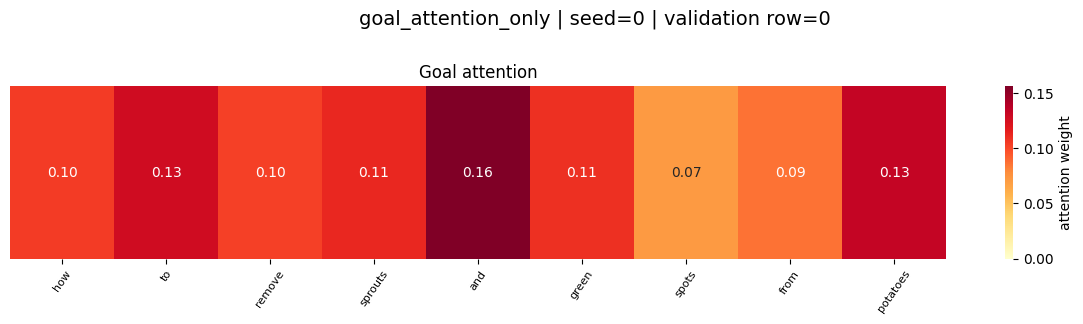

Rendered panels: goal_alpha

Configuration: self_attention
Checkpoint : attention_ablation_20261014T125621Z_e5d231e1_self_attention_seed0.pt (Drive id: 1bwFhcvngpEqxwM2JTh6Oa8R5doS4vJuu)
Drive JSON : attention_ablation_20261014T125621Z_e5d231e1_self_attention_seed0.json (Drive id: 1ahCxK8qtyrsZtPQpgsV_N90GnPD-YdIG)
Prediction : solution 2 (p1=0.0001, p2=0.9999) ✗ incorrect


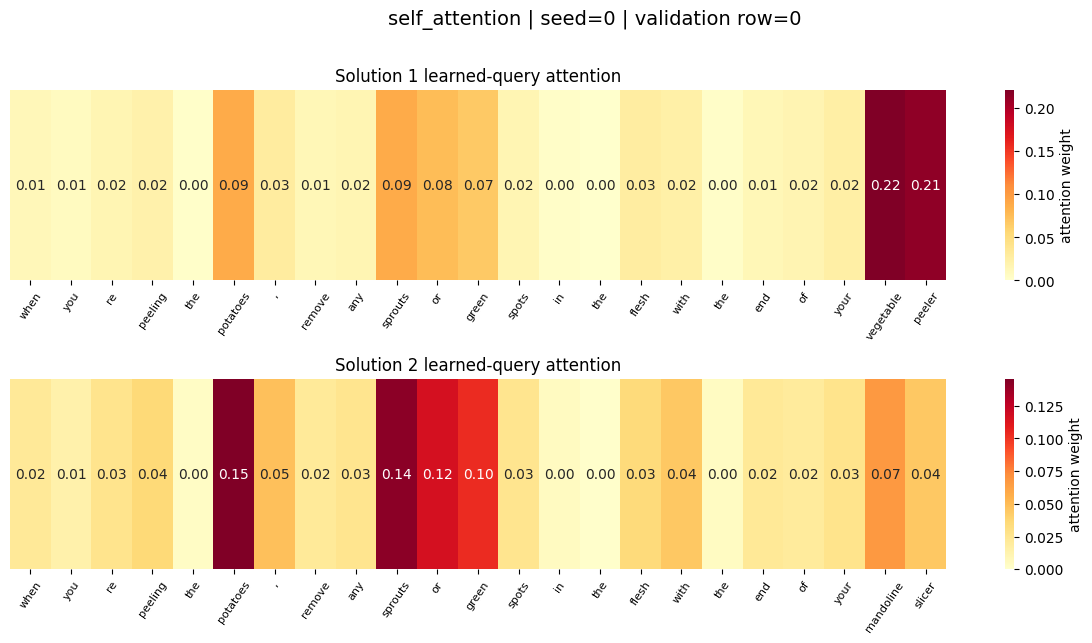

Rendered panels: sol1_alpha, sol2_alpha

Configuration: cross_attention_only
Checkpoint : attention_ablation_20261014T125621Z_e5d231e1_cross_attention_only_seed0.pt (Drive id: 1h7WRbb803efoog1Cj50xHA1eNFkexRvk)
Drive JSON : attention_ablation_20261014T125621Z_e5d231e1_cross_attention_only_seed0.json (Drive id: 12PIUaga__l0PS0vYKjpl1vq6_6aeGPTR)
Prediction : solution 2 (p1=0.0042, p2=0.9958) ✗ incorrect


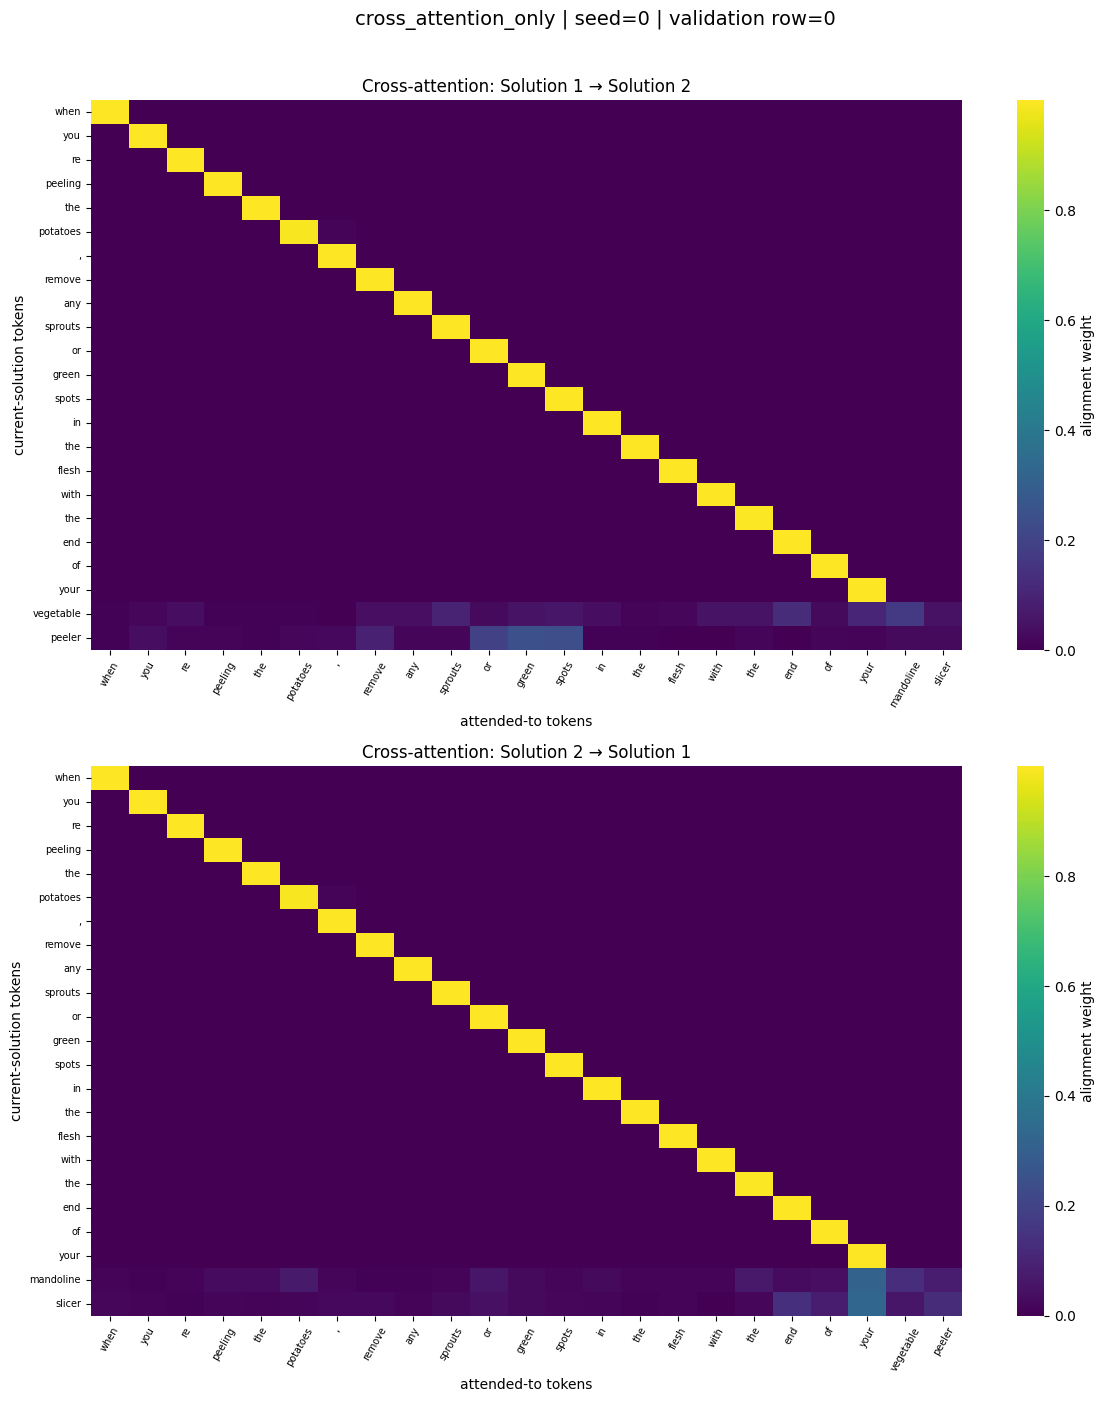

Rendered panels: sol1_align, sol2_align

Configuration: cross_attention_plus_goal
Checkpoint : attention_ablation_20261014T125621Z_e5d231e1_cross_attention_plus_goal_seed0.pt (Drive id: 1lpZYuBqFUKomFDw4YmtrAwd0OFG88oTh)
Drive JSON : attention_ablation_20261014T125621Z_e5d231e1_cross_attention_plus_goal_seed0.json (Drive id: 1j5hXZX3Hxkf94DbkYcuzIFQpgsyfNgsw)
Prediction : solution 2 (p1=0.0757, p2=0.9243) ✗ incorrect


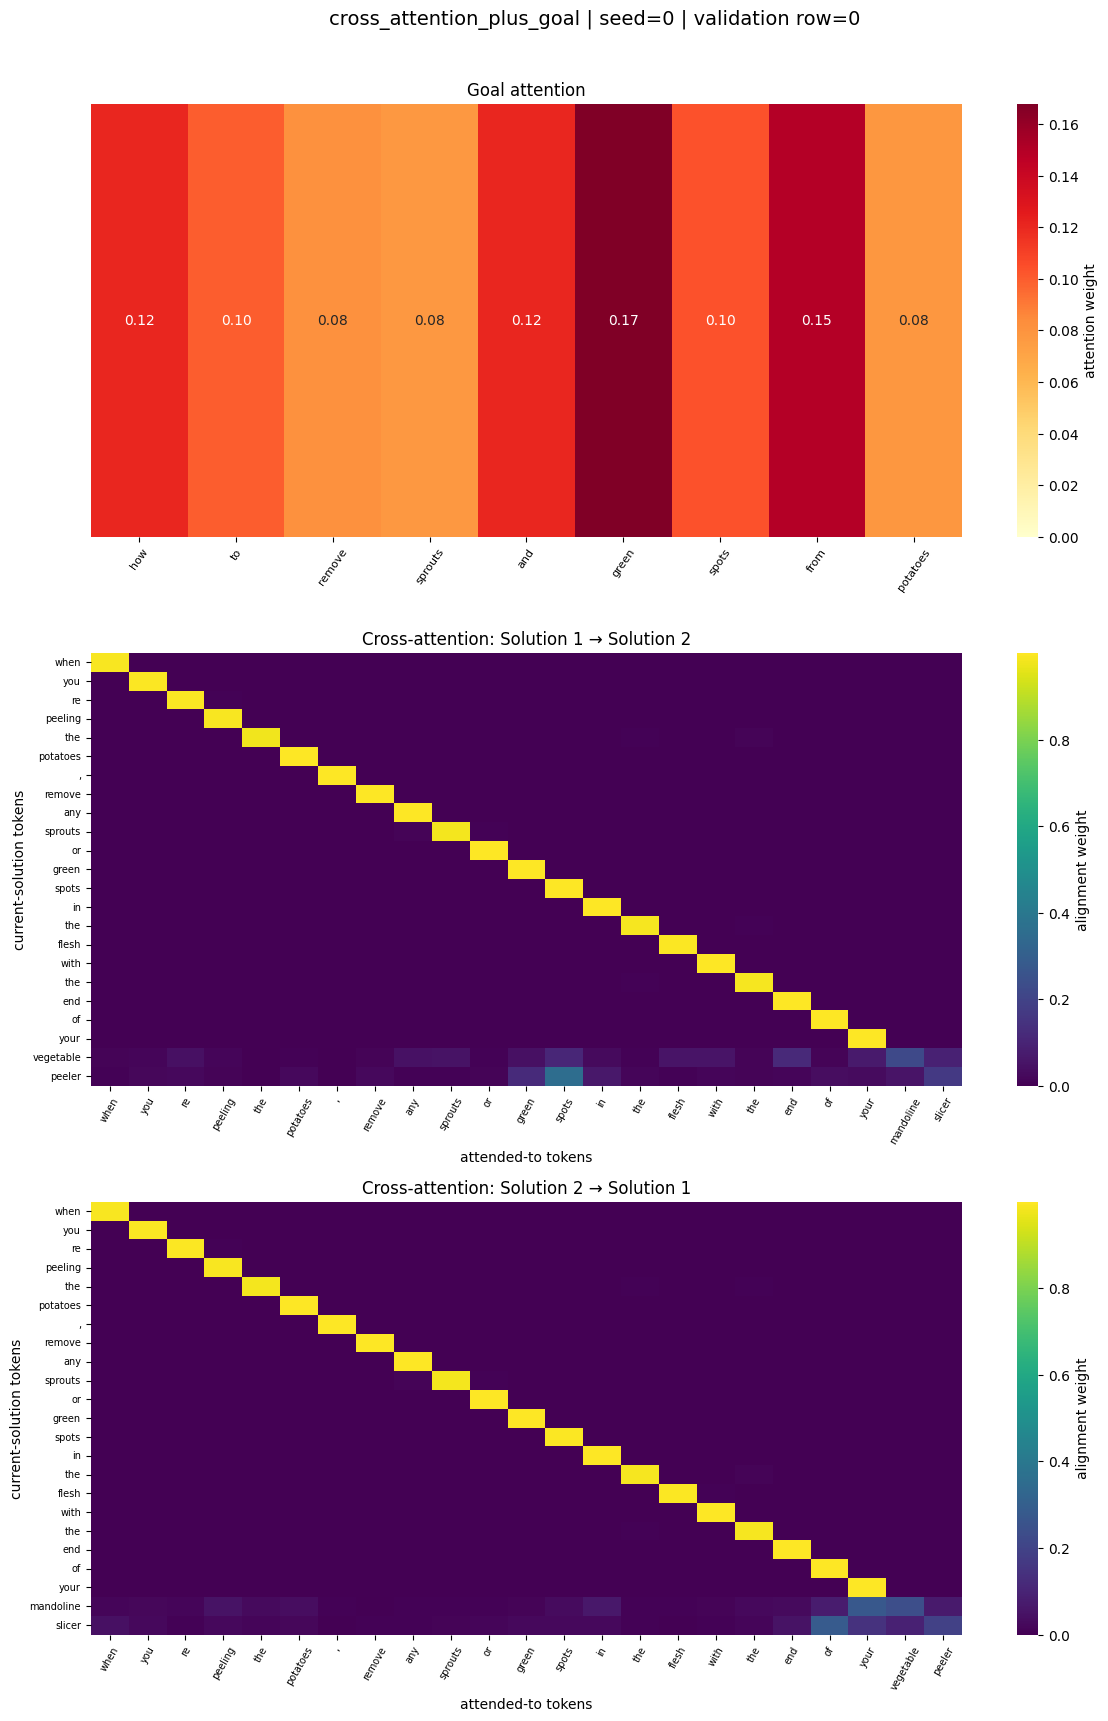

Rendered panels: goal_alpha, sol1_align, sol2_align

Rendered 4 configuration figures.


In [5]:
# @title Step 12.6: Standalone attention heat maps from Google Drive
# Fresh-runtime cell: authenticate, restore data/model, download checkpoint, and plot.

from collections import Counter
from pathlib import Path
import hashlib
import io
import json
import os
import re
import zipfile

import gdown
import google.auth
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from sklearn.model_selection import train_test_split


# Change these three parameters to select the model and validation sample
HEATMAP_CONFIG = [
    "goal_attention_only",
    "self_attention",
    "cross_attention_only",
    "cross_attention_plus_goal",
]
HEATMAP_SEED = 0
HEATMAP_SAMPLE_INDEX = 0
# self_attention is the internal key for LEARNED-QUERY ATTENTION.


# ---------------------------------------------------------------------
# 1. Restore the PIQA validation data in a fresh runtime
# ---------------------------------------------------------------------

VALID_HEATMAP_CONFIGS = {
    "no_attention",
    "goal_attention_only",
    "self_attention",
    "cross_attention_only",
    "cross_attention_plus_goal",
}

if not isinstance(HEATMAP_CONFIG, list) or not HEATMAP_CONFIG:
    raise ValueError("HEATMAP_CONFIG must be a non-empty list.")
if len(set(HEATMAP_CONFIG)) != len(HEATMAP_CONFIG):
    raise ValueError("HEATMAP_CONFIG must not contain duplicate configurations.")
unknown_heatmap_configs = [
    name for name in HEATMAP_CONFIG if name not in VALID_HEATMAP_CONFIGS
]
if unknown_heatmap_configs:
    raise ValueError(
        "Unknown HEATMAP_CONFIG values: "
        + ", ".join(unknown_heatmap_configs)
        + "; choose from "
        + ", ".join(sorted(VALID_HEATMAP_CONFIGS))
    )

try:
    HEATMAP_SEED = int(HEATMAP_SEED)
    HEATMAP_SAMPLE_INDEX = int(HEATMAP_SAMPLE_INDEX)
except (TypeError, ValueError) as exc:
    raise ValueError("HEATMAP_SEED and HEATMAP_SAMPLE_INDEX must be integers.") from exc

PIQA_DATA_FILE_ID = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
PIQA_DATA_DIR = Path("/content/piqa_heatmap_data")
PIQA_FILENAMES = (
    "train.jsonl",
    "train-labels.lst",
    "test.jsonl",
    "test-labels.lst",
)


def ensure_piqa_data():
    """Download the public PIQA archive once and return the four data paths."""
    PIQA_DATA_DIR.mkdir(parents=True, exist_ok=True)
    located = {
        name: next(iter(PIQA_DATA_DIR.rglob(name)), None)
        for name in PIQA_FILENAMES
    }

    if any(path is None for path in located.values()):
        archive_path = PIQA_DATA_DIR / "piqa_data.zip"
        downloaded_path = gdown.download(
            id=PIQA_DATA_FILE_ID,
            output=str(archive_path),
            quiet=False,
        )
        if downloaded_path is None or not archive_path.is_file():
            raise RuntimeError("PIQA data download failed.")
        try:
            with zipfile.ZipFile(archive_path) as archive:
                archive.extractall(PIQA_DATA_DIR)
        except (OSError, zipfile.BadZipFile) as exc:
            raise RuntimeError("The downloaded PIQA archive is invalid.") from exc
        located = {
            name: next(iter(PIQA_DATA_DIR.rglob(name)), None)
            for name in PIQA_FILENAMES
        }

    missing = [name for name, path in located.items() if path is None]
    if missing:
        raise RuntimeError("PIQA archive is missing: " + ", ".join(missing))
    return located


def clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()


def read_piqa(data_path, label_path):
    with open(data_path, encoding="utf-8") as data_file:
        data_lines = data_file.readlines()
    with open(label_path, encoding="utf-8") as label_file:
        label_lines = label_file.readlines()
    rows = []
    for line, label in zip(data_lines, label_lines):
        if not label.strip():
            continue
        item = json.loads(line)
        rows.append({
            "goal": item["goal"],
            "sol1": item["sol1"],
            "sol2": item["sol2"],
            "label": int(label.strip()),
        })
    return rows


def build_vocabulary(rows, min_count=2):
    word_count = Counter()
    for item in rows:
        word_count.update(clean_str(item["goal"]).split())
        word_count.update(clean_str(item["sol1"]).split())
        word_count.update(clean_str(item["sol2"]).split())
    result = {"<pad>": 0, "<unk>": 1}
    for word, count in word_count.most_common():
        if count >= min_count:
            result[word] = len(result)
    return result


def words_to_index(words, vocabulary, maxlength):
    indices = np.zeros(maxlength, dtype=np.int64)
    for index, word in enumerate(words[:maxlength]):
        indices[index] = vocabulary.get(word, 1)
    return indices


def make_batch_input(rows, vocabulary, maxgoal=20, maxsol=60):
    size = len(rows)
    goal = np.zeros((size, maxgoal), dtype=np.int64)
    sol1 = np.zeros((size, maxsol), dtype=np.int64)
    sol2 = np.zeros((size, maxsol), dtype=np.int64)
    labels = np.zeros(size, dtype=np.int64)
    for index, item in enumerate(rows):
        goal[index] = words_to_index(clean_str(item["goal"]).split(), vocabulary, maxgoal)
        sol1[index] = words_to_index(clean_str(item["sol1"]).split(), vocabulary, maxsol)
        sol2[index] = words_to_index(clean_str(item["sol2"]).split(), vocabulary, maxsol)
        labels[index] = item["label"]
    return goal, sol1, sol2, labels


piqa_paths = ensure_piqa_data()
data_train_rows = read_piqa(
    piqa_paths["train.jsonl"],
    piqa_paths["train-labels.lst"],
)
all_labels = [item["label"] for item in data_train_rows]
train_part1, train_part2 = train_test_split(
    data_train_rows,
    test_size=0.15,
    random_state=0,
    stratify=all_labels,
)
vocabulary = build_vocabulary(train_part1, min_count=2)
train_part2_input = make_batch_input(train_part2, vocabulary)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PIQA validation restored: {len(train_part2)} rows; vocabulary={len(vocabulary)}")
print(f"Device: {device}")


# ---------------------------------------------------------------------
# 2. Define the attention and model architecture matching the Step 13 checkpoint
# ---------------------------------------------------------------------

def masked_pool(rnn_output, index, pooling="mean"):
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        return rnn_output.masked_fill(mask == 0, -1e9).max(dim=1)[0]
    return (rnn_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)


def attention_on_solution(solution_output, solution_index, query):
    if query.dim() == 1:
        score = torch.matmul(solution_output, query)
    else:
        score = torch.bmm(solution_output, query.unsqueeze(2)).squeeze(2)
    score = score.masked_fill(solution_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), solution_output).squeeze(1)
    return context, alpha


def attention_on_goal(goal_output, goal_index, query):
    score = torch.matmul(goal_output, query)
    score = score.masked_fill(goal_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), goal_output).squeeze(1)
    return context, alpha


def cross_attention(current_output, current_index, other_output, other_index, pooling="mean"):
    similarity = torch.bmm(current_output, other_output.transpose(1, 2))
    similarity = similarity.masked_fill((other_index == 0).unsqueeze(1), -1e9)
    align = torch.softmax(similarity, dim=2)
    aligned = torch.bmm(align, other_output)
    return masked_pool(current_output - aligned, current_index, pooling), align


class PIQA_Model(nn.Module):
    def __init__(
        self, vocabulary_size, dimension=100, n_hidden_input=100,
        dropout_input=0.25, num_layers_input=1, rnn_type="LSTM",
        pooling="mean", attention_type="none", goal_attention=False,
        use_cross_attention=False, use_interaction=True, use_goal=True,
    ):
        super().__init__()
        self.pooling = pooling
        self.attention_type = attention_type
        self.goal_attention = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction = use_interaction
        self.use_goal = use_goal
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        encoder_class = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.encoder = encoder_class(
            dimension, n_hidden_input, num_layers=num_layers_input,
            batch_first=True, bidirectional=True,
            dropout=dropout_input if num_layers_input > 1 else 0,
        )
        self.W = nn.Linear(n_hidden_input * 2, n_hidden_input * 2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        score_input = n_hidden_input * 2 * (4 if use_interaction else 2)
        if use_cross_attention:
            score_input += n_hidden_input * 2
        self.hidden_layer = nn.Linear(score_input, n_hidden_input)
        self.score_layer = nn.Linear(n_hidden_input, 1)
        self.dropout = nn.Dropout(dropout_input)

    def score_one_solution(
        self, goal_vector, current_output, current_index, other_output, other_index,
    ):
        if self.attention_type == "goal":
            context, alpha = attention_on_solution(
                current_output, current_index, self.W(goal_vector)
            )
        elif self.attention_type == "self":
            context, alpha = attention_on_solution(
                current_output, current_index, self.pool_query
            )
        else:
            context = masked_pool(current_output, current_index, self.pooling)
            alpha = torch.zeros_like(current_index).float()
        if self.use_interaction:
            combined = torch.cat((
                goal_vector, context, goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        align = None
        if self.use_cross_attention:
            difference, align = cross_attention(
                current_output, current_index, other_output, other_index, self.pooling
            )
            combined = torch.cat((combined, difference), dim=1)
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1), alpha, align

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        if self.goal_attention:
            goal_vector, goal_alpha = attention_on_goal(goal_output, goal, self.goal_query)
        else:
            goal_vector = masked_pool(goal_output, goal, self.pooling)
            goal_alpha = None
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        score1, alpha1, align1 = self.score_one_solution(
            goal_vector, sol1_output, solution1, sol2_output, solution2
        )
        score2, alpha2, align2 = self.score_one_solution(
            goal_vector, sol2_output, solution2, sol1_output, solution1
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1, "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha, "sol1_align": align1,
            "sol2_align": align2,
        }


class PIQA_MeanMaxCross_Model(PIQA_Model):
    def __init__(self, vocabulary_size, cross_difference_pooling="masked_mean_max", **settings):
        if cross_difference_pooling != "masked_mean_max":
            raise ValueError("cross_difference_pooling must be 'masked_mean_max'.")
        if not settings.get("use_cross_attention", False):
            raise ValueError("This model requires use_cross_attention=True.")
        hidden_size = int(settings.get("n_hidden_input", 100))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        base_width = hidden_size * 2 * (4 if self.use_interaction else 2)
        self.hidden_layer = nn.Linear(base_width + hidden_size * 4, hidden_size)

    def score_one_solution(
        self, goal_vector, current_output, current_index, other_output, other_index,
    ):
        if self.attention_type == "goal":
            context, alpha = attention_on_solution(
                current_output, current_index, self.W(goal_vector)
            )
        elif self.attention_type == "self":
            context, alpha = attention_on_solution(
                current_output, current_index, self.pool_query
            )
        else:
            context = masked_pool(current_output, current_index, self.pooling)
            alpha = torch.zeros_like(current_index).float()
        if self.use_interaction:
            combined = torch.cat((
                goal_vector, context, goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        similarity = torch.bmm(current_output, other_output.transpose(1, 2))
        similarity = similarity.masked_fill((other_index == 0).unsqueeze(1), -1e9)
        align = torch.softmax(similarity, dim=2)
        token_difference = current_output - torch.bmm(align, other_output)
        current_mask = current_index.ne(0).unsqueeze(2)
        masked_difference = token_difference.masked_fill(~current_mask, 0.0)
        valid_count = current_mask.sum(dim=1).clamp(min=1).to(token_difference.dtype)
        mean_difference = masked_difference.sum(dim=1) / valid_count
        max_difference = token_difference.masked_fill(
            ~current_mask, torch.finfo(token_difference.dtype).min
        ).max(dim=1).values
        max_difference = torch.where(
            current_mask.any(dim=1), max_difference, torch.zeros_like(max_difference)
        )
        combined = torch.cat((combined, mean_difference, max_difference), dim=1)
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1), alpha, align


def _build_attention_experiment_model(vocabulary_size, settings):
    model_settings = dict(settings)
    pooling_mode = model_settings.pop("cross_difference_pooling", None)
    if model_settings.get("use_cross_attention", False):
        if pooling_mode != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs require cross_difference_pooling='masked_mean_max'."
            )
        return PIQA_MeanMaxCross_Model(
            vocabulary_size, cross_difference_pooling=pooling_mode, **model_settings
        )
    if pooling_mode is not None:
        raise ValueError("cross_difference_pooling is only valid for cross-attention.")
    return PIQA_Model(vocabulary_size, **model_settings)


# ---------------------------------------------------------------------
# 3. Connect to Google Drive and select the latest valid JSON/.pt file pair
# ---------------------------------------------------------------------

ATTENTION_ABLATION_DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
DRIVE_DOWNLOAD_DIR = Path("/content/attention_ablation_heatmap")
DRIVE_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)


def list_drive_folder_files(service, folder_id):
    files = []
    page_token = None
    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            spaces="drive",
            fields="nextPageToken,files(id,name,mimeType,createdTime,modifiedTime,size)",
            orderBy="createdTime desc",
            pageSize=1000,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        files.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            return files


def download_drive_bytes(service, file_id):
    buffer = io.BytesIO()
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    downloader = MediaIoBaseDownload(buffer, request)
    complete = False
    while not complete:
        _, complete = downloader.next_chunk()
    return buffer.getvalue()


def download_drive_file(service, file_id, destination):
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    with destination.open("wb") as output_file:
        downloader = MediaIoBaseDownload(output_file, request)
        complete = False
        while not complete:
            _, complete = downloader.next_chunk()


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as input_file:
        for chunk in iter(lambda: input_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def select_drive_backup(files, configuration, seed, read_json, prepare_checkpoint):
    """Return the newest complete, verified and loadable Step 13 backup."""
    json_files = sorted(
        (
            item for item in files
            if item.get("name", "").startswith("attention_ablation_")
            and item.get("name", "").endswith(".json")
        ),
        key=lambda item: item.get("createdTime", ""),
        reverse=True,
    )
    checkpoints_by_name = {}
    for item in files:
        if item.get("name", "").endswith(".pt"):
            checkpoints_by_name.setdefault(item["name"], []).append(item)
    matching_count = 0
    rejected = []

    for json_file in json_files:
        try:
            record = json.loads(read_json(json_file["id"]))
        except Exception as exc:
            rejected.append(f"{json_file.get('name')}: invalid JSON ({exc})")
            continue
        try:
            record_seed = int(record.get("seed", -1))
        except (TypeError, ValueError):
            continue
        if record.get("configuration") != configuration or record_seed != seed:
            continue
        matching_count += 1
        checkpoint_name = record.get("checkpoint_filename")
        if not checkpoint_name or Path(checkpoint_name).name != checkpoint_name:
            rejected.append(f"{json_file['name']}: invalid checkpoint filename")
            continue
        checkpoint_files = sorted(
            checkpoints_by_name.get(checkpoint_name, []),
            key=lambda item: item.get("createdTime", ""),
            reverse=True,
        )
        if not checkpoint_files:
            rejected.append(f"{json_file['name']}: paired .pt is missing")
            continue
        for checkpoint_file in checkpoint_files:
            try:
                checkpoint_candidate = prepare_checkpoint(checkpoint_file, record)
            except Exception as exc:
                rejected.append(
                    f"{json_file['name']} + {checkpoint_file['name']}: {exc}"
                )
                continue
            return json_file, checkpoint_file, record, checkpoint_candidate, rejected

    if matching_count == 0:
        raise RuntimeError(
            f"No Step 13 JSON was found in Google Drive for configuration={configuration!r}, seed={seed}."
        )
    details = "\n".join("- " + item for item in rejected[-8:])
    raise RuntimeError(
        "A matching JSON was found in Google Drive, but no complete checkpoint passed validation."
        + ("\n" + details if details else "")
    )


def fetch_verified_checkpoint(checkpoint_file, record):
    expected = record.get("checkpoint_sha256")
    if not isinstance(expected, str) or re.fullmatch(r"[0-9a-fA-F]{64}", expected) is None:
        raise ValueError("JSON is missing a valid checkpoint_sha256")
    expected = expected.lower()
    destination = DRIVE_DOWNLOAD_DIR / checkpoint_file["name"]
    if destination.is_file() and sha256_file(destination) == expected:
        return destination
    temporary = destination.with_name(destination.name + ".part")
    try:
        download_drive_file(attention_drive_service, checkpoint_file["id"], temporary)
        actual = sha256_file(temporary)
        if actual != expected:
            raise ValueError(f"SHA-256 mismatch: expected {expected}, got {actual}")
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()
    return destination


def prepare_checkpoint_candidate(checkpoint_file, record):
    """Verify one checkpoint, reconstruct its model, and load its weights."""
    checkpoint_path = fetch_verified_checkpoint(checkpoint_file, record)
    settings = record.get("cache_spec", {}).get("settings")
    if not isinstance(settings, dict):
        raise ValueError("JSON is missing cache_spec.settings")
    try:
        candidate_model = _build_attention_experiment_model(
            len(vocabulary),
            settings,
        ).to(device)
    except Exception as exc:
        raise RuntimeError(
            "The checkpoint training settings cannot reconstruct the corresponding model."
        ) from exc
    try:
        try:
            state_dict = torch.load(
                checkpoint_path,
                map_location=device,
                weights_only=True,
            )
        except TypeError:
            # Support older PyTorch versions
            state_dict = torch.load(checkpoint_path, map_location=device)
    except Exception as exc:
        raise RuntimeError("The checkpoint could not be read by PyTorch.") from exc
    try:
        candidate_model.load_state_dict(state_dict)
    except RuntimeError as exc:
        raise RuntimeError(
            "The checkpoint model architecture or vocabulary does not match the restored PIQA setup."
        ) from exc
    candidate_model.eval()
    return {
        "checkpoint_path": checkpoint_path,
        "settings": settings,
        "model": candidate_model,
    }


auth.authenticate_user()
attention_drive_credentials, _ = google.auth.default()
attention_drive_service = build(
    "drive", "v3",
    credentials=attention_drive_credentials,
    cache_discovery=False,
)
attention_drive_folder = attention_drive_service.files().get(
    fileId=ATTENTION_ABLATION_DRIVE_FOLDER_ID,
    fields="id,name,mimeType",
    supportsAllDrives=True,
).execute()
if attention_drive_folder.get("mimeType") != "application/vnd.google-apps.folder":
    raise RuntimeError("The configured Google Drive target is not a folder.")

drive_files = list_drive_folder_files(
    attention_drive_service,
    ATTENTION_ABLATION_DRIVE_FOLDER_ID,
)
print(f"Drive folder: {attention_drive_folder.get('name')}")


# ---------------------------------------------------------------------
# 4. Select, validate, and load a checkpoint for each configuration
# ---------------------------------------------------------------------

selected_checkpoints = []
for heatmap_config in HEATMAP_CONFIG:
    (
        json_drive_file,
        checkpoint_drive_file,
        record,
        checkpoint_candidate,
        rejected_backups,
    ) = select_drive_backup(
        drive_files,
        heatmap_config,
        HEATMAP_SEED,
        lambda file_id: download_drive_bytes(attention_drive_service, file_id),
        prepare_checkpoint_candidate,
    )
    for rejected_backup in rejected_backups:
        print(f"[{heatmap_config}] skipped backup: {rejected_backup}")

    checkpoint_path = checkpoint_candidate["checkpoint_path"]
    json_path = DRIVE_DOWNLOAD_DIR / Path(json_drive_file["name"]).name
    json_temporary = json_path.with_name(json_path.name + ".part")
    json_temporary.write_text(
        json.dumps(record, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    os.replace(json_temporary, json_path)

    expected_sha256 = record.get("checkpoint_sha256", "").lower()
    actual_sha256 = sha256_file(checkpoint_path)
    if actual_sha256 != expected_sha256:
        raise RuntimeError(
            f"The SHA-256 of {checkpoint_path.name} does not match the JSON; "
            "execution has stopped to avoid loading the wrong model."
        )

    selected_checkpoints.append({
        "configuration": heatmap_config,
        "json_drive_file": json_drive_file,
        "checkpoint_drive_file": checkpoint_drive_file,
        "record": record,
        "checkpoint_path": checkpoint_path,
        "json_path": json_path,
        "model": checkpoint_candidate["model"],
    })


# ---------------------------------------------------------------------
# 5. Retrieve the specified validation sample and run the model
# ---------------------------------------------------------------------

sample_index = int(HEATMAP_SAMPLE_INDEX)

if not 0 <= sample_index < len(train_part2):
    raise IndexError(
        "HEATMAP_SAMPLE_INDEX must be between "
        f"0 and {len(train_part2) - 1}."
    )

goal_array, sol1_array, sol2_array, label_array = (
    train_part2_input
)

goal_tensor = torch.as_tensor(
    goal_array[sample_index:sample_index + 1],
    dtype=torch.long,
    device=device,
)

sol1_tensor = torch.as_tensor(
    sol1_array[sample_index:sample_index + 1],
    dtype=torch.long,
    device=device,
)

sol2_tensor = torch.as_tensor(
    sol2_array[sample_index:sample_index + 1],
    dtype=torch.long,
    device=device,
)

gold = int(label_array[sample_index])
row = train_part2[sample_index]
heatmap_runs = []
for selected_checkpoint in selected_checkpoints:
    model = selected_checkpoint.pop("model")
    with torch.no_grad():
        logits, attention = model(
            goal_tensor,
            sol1_tensor,
            sol2_tensor,
        )
        probabilities = (
            torch.softmax(logits, dim=1)[0]
            .detach()
            .cpu()
            .numpy()
        )
        prediction = int(logits.argmax(dim=1).item())

    run_result = dict(selected_checkpoint)
    run_result.update({
        "attention": {
            name: value.detach().cpu() if value is not None else None
            for name, value in attention.items()
        },
        "probabilities": probabilities,
        "prediction": prediction,
    })
    heatmap_runs.append(run_result)
    del model
    torch.cuda.empty_cache()


# ---------------------------------------------------------------------
# 6. Heat map helpers
# ---------------------------------------------------------------------

def visible_tokens(text, index_row):
    """Return the original tokens corresponding to the non-padding portion."""
    token_count = int(np.count_nonzero(index_row))
    return clean_str(text).split()[:token_count]


def first_numpy(value):
    """Extract the first sample from the batch and convert it to NumPy."""
    if value is None:
        return None

    return value.detach().cpu().numpy()[0]


def draw_token_heatmap(ax, tokens, weights, title):
    """Plot goal or solution token attention on existing axes."""
    values = np.asarray(
        weights[:len(tokens)],
        dtype=float,
    )

    if (
        not tokens
        or values.size == 0
        or np.allclose(values, 0.0)
    ):
        return False

    sns.heatmap(
        values.reshape(1, -1),
        cmap="YlOrRd",
        vmin=0.0,
        xticklabels=tokens,
        yticklabels=False,
        annot=len(tokens) <= 25,
        fmt=".2f",
        cbar_kws={
            "label": "attention weight"
        },
        ax=ax,
    )

    ax.set_title(title)
    ax.tick_params(
        axis="x",
        rotation=55,
        labelsize=8,
    )

    return True


def draw_cross_heatmap(
    ax,
    matrix,
    row_tokens,
    column_tokens,
    title,
):
    """Plot cross-attention between the two solutions."""
    values = np.asarray(
        matrix,
        dtype=float,
    )[
        :len(row_tokens),
        :len(column_tokens),
    ]

    if (
        not row_tokens
        or not column_tokens
        or values.size == 0
        or np.allclose(values, 0.0)
    ):
        return False

    sns.heatmap(
        values,
        cmap="viridis",
        vmin=0.0,
        xticklabels=column_tokens,
        yticklabels=row_tokens,
        cbar_kws={
            "label": "alignment weight"
        },
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("attended-to tokens")
    ax.set_ylabel("current-solution tokens")

    ax.tick_params(
        axis="x",
        rotation=60,
        labelsize=7,
    )

    ax.tick_params(
        axis="y",
        rotation=0,
        labelsize=7,
    )

    return True


def build_attention_panels(
    configuration, attention, goal_tokens, sol1_tokens, sol2_tokens,
):
    """Describe the panels that belong in one configuration figure."""
    panels = []
    if configuration in {"goal_attention_only", "cross_attention_plus_goal"}:
        panels.append({
            "kind": "token",
            "attention_key": "goal_alpha",
            "tokens": goal_tokens,
            "title": "Goal attention",
        })
    if configuration == "self_attention":
        panels.extend([
            {
                "kind": "token",
                "attention_key": "sol1_alpha",
                "tokens": sol1_tokens,
                "title": "Solution 1 learned-query attention",
            },
            {
                "kind": "token",
                "attention_key": "sol2_alpha",
                "tokens": sol2_tokens,
                "title": "Solution 2 learned-query attention",
            },
        ])
    if configuration in {"cross_attention_only", "cross_attention_plus_goal"}:
        panels.extend([
            {
                "kind": "cross",
                "attention_key": "sol1_align",
                "row_tokens": sol1_tokens,
                "column_tokens": sol2_tokens,
                "title": "Cross-attention: Solution 1 → Solution 2",
            },
            {
                "kind": "cross",
                "attention_key": "sol2_align",
                "row_tokens": sol2_tokens,
                "column_tokens": sol1_tokens,
                "title": "Cross-attention: Solution 2 → Solution 1",
            },
        ])
    return panels


def draw_configuration_figure(
    configuration, attention, goal_tokens, sol1_tokens, sol2_tokens,
):
    """Render all attention types for one configuration in one figure."""
    panels = build_attention_panels(
        configuration, attention, goal_tokens, sol1_tokens, sol2_tokens,
    )
    if not panels:
        raise RuntimeError(f"No attention panels configured for {configuration}.")

    cross_panel_count = sum(panel["kind"] == "cross" for panel in panels)
    figure_height = 3.2 * (len(panels) - cross_panel_count) + 7.0 * cross_panel_count
    max_token_count = max(
        len(panel.get("tokens", panel.get("column_tokens", [])))
        for panel in panels
    )
    figure_width = max(12, min(24, 0.38 * max_token_count))
    figure, axes = plt.subplots(
        len(panels),
        1,
        figsize=(figure_width, figure_height),
        squeeze=False,
    )

    rendered = []
    for ax, panel in zip(axes[:, 0], panels):
        values = first_numpy(attention.get(panel["attention_key"]))
        if panel["kind"] == "token":
            success = draw_token_heatmap(
                ax,
                panel["tokens"],
                values if values is not None else [],
                panel["title"],
            )
        else:
            success = draw_cross_heatmap(
                ax,
                values if values is not None else np.empty((0, 0)),
                panel["row_tokens"],
                panel["column_tokens"],
                panel["title"],
            )
        if success:
            rendered.append(panel["attention_key"])
        else:
            ax.set_visible(False)

    if not rendered:
        plt.close(figure)
        raise RuntimeError(f"{configuration} did not produce a visible attention map.")
    figure.suptitle(
        f"{configuration} | seed={HEATMAP_SEED} | validation row={sample_index}",
        fontsize=14,
        y=0.998,
    )
    figure.tight_layout(rect=(0, 0, 1, 0.985))
    plt.show()
    return rendered


# ---------------------------------------------------------------------
# 7. Display the sample, predictions, and attention heat maps
# ---------------------------------------------------------------------

goal_tokens = visible_tokens(
    row["goal"],
    goal_array[sample_index],
)

sol1_tokens = visible_tokens(
    row["sol1"],
    sol1_array[sample_index],
)

sol2_tokens = visible_tokens(
    row["sol2"],
    sol2_array[sample_index],
)

print(f"Sample     : validation row {sample_index}")
print(f"Goal       : {row['goal']}")
print(f"Solution 1 : {row['sol1']}")
print(f"Solution 2 : {row['sol2']}")
print(f"Gold       : solution {gold + 1}")

print(f"Configurations: {', '.join(HEATMAP_CONFIG)}")
for run_result in heatmap_runs:
    configuration = run_result["configuration"]
    checkpoint_path = run_result["checkpoint_path"]
    json_path = run_result["json_path"]
    checkpoint_drive_file = run_result["checkpoint_drive_file"]
    json_drive_file = run_result["json_drive_file"]
    probabilities = run_result["probabilities"]
    prediction = run_result["prediction"]

    print("\n" + "=" * 80)
    print(f"Configuration: {configuration}")
    print(
        f"Checkpoint : {checkpoint_path.name} "
        f"(Drive id: {checkpoint_drive_file['id']})"
    )
    print(
        f"Drive JSON : {json_path.name} "
        f"(Drive id: {json_drive_file['id']})"
    )
    print(
        f"Prediction : solution {prediction + 1} "
        f"(p1={probabilities[0]:.4f}, p2={probabilities[1]:.4f}) "
        f"{'✓ correct' if prediction == gold else '✗ incorrect'}"
    )

    rendered = draw_configuration_figure(
        configuration,
        run_result["attention"],
        goal_tokens,
        sol1_tokens,
        sol2_tokens,
    )
    print("Rendered panels:", ", ".join(rendered))



print(f"\nRendered {len(heatmap_runs)} configuration figures.")

In [13]:
# @title [RUN] Step 13A: Attention Type: Goal;  Training settings and local metrics

import csv

STEP15_SEEDS = (0, 1, 2)
STEP15_EPOCHS = 15
STEP15_LEARNING_RATE = 0.001
STEP15_BATCH_SIZE = 32
STEP15_OUTPUT_ROOT = "step15_outputs"

In [22]:
# @title Step 13B.1: Model, configurations, and smoke checks

import inspect
import time

# Step 15A provides the training protocol; results remain in memory.
_step15b_required = [
    "base_settings", "PIQA_Model", "train_model", "set_seed", "vocabulary",
    "device", "np", "torch", "train_part1_input", "train_part2_input",
    "STEP15_SEEDS", "STEP15_EPOCHS", "STEP15_LEARNING_RATE",
    "STEP15_BATCH_SIZE",
]
_step15b_missing = [name for name in _step15b_required if name not in globals()]
if _step15b_missing:
    raise RuntimeError(
        "Run the environment, data, model/training function, base_settings, and Step 15A cells first. Missing: "
        + ", ".join(_step15b_missing)
    )

assert tuple(STEP15_SEEDS) == (0, 1, 2), "Step 15B uses seeds 0, 1, and 2."
assert STEP15_EPOCHS == 15, "Step 15B uses 15 epochs."


class PIQA_Step15B_MeanMix_Model(PIQA_Model):
    """Step 15B model: mix goal-guided and masked-mean solution contexts."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15B requires attention_type='goal'.")
        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must use masked_mean_max difference pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling

        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            # Mean and max each add one 2H vector to the original score features.
            self.hidden_layer = torch.nn.Linear(
                base_width + hidden_size * 4, hidden_size
            )

        # sigmoid(0) = 0.5. One scalar is shared by both solution branches.
        self.goal_mean_mix_logit = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, goal_attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * goal_attention_context + (1.0 - mix) * mean_context

    def score_one_solution(
        self, goal_vector, current_sol_output, current_sol_index,
        other_sol_output, other_sol_index
    ):
        query = self.W(goal_vector)
        goal_attention_context, alpha = attention_on_solution(
            current_sol_output, current_sol_index, query
        )
        mean_context = masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(goal_attention_context, mean_context)

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            similarity = torch.bmm(
                current_sol_output, other_sol_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count

            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens, max_difference, torch.zeros_like(max_difference)
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _build_step15b_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15B_MeanMix_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# Four A2/A3 combinations. A1=goal and the learned mean/goal mix are fixed.
STEP15_VARIANTS = [
    ("goal_guided_solution_attention_mean_mix", {
        "attention_type": "goal",
        "goal_attention": False,
        "use_cross_attention": False,
    }),
    ("goal_guided_solution_attention_mean_mix_with_cross_attention", {
        "attention_type": "goal",
        "goal_attention": False,
        "use_cross_attention": True,
    }),
    ("goal_guided_solution_attention_mean_mix_with_goal_attention", {
        "attention_type": "goal",
        "goal_attention": True,
        "use_cross_attention": False,
    }),
    ("goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention", {
        "attention_type": "goal",
        "goal_attention": True,
        "use_cross_attention": True,
    }),
]

_step15b_defaults = {
    name: parameter.default
    for name, parameter in inspect.signature(PIQA_Model.__init__).parameters.items()
    if name not in ("self", "vocabulary_size")
    and parameter.default is not inspect.Parameter.empty
}
STEP15_CONFIGS = []
for _name, _switches in STEP15_VARIANTS:
    _settings = dict(_step15b_defaults)
    _settings.update(base_settings)
    _settings.update(_switches)
    if _settings["use_cross_attention"]:
        _settings["cross_difference_pooling"] = "masked_mean_max"
    STEP15_CONFIGS.append((_name, _settings))

_expected_step15b_switches = {
    "goal_guided_solution_attention_mean_mix": ("goal", False, False),
    "goal_guided_solution_attention_mean_mix_with_cross_attention": ("goal", False, True),
    "goal_guided_solution_attention_mean_mix_with_goal_attention": ("goal", True, False),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention": ("goal", True, True),
}
_actual_step15b_switches = {
    name: (
        settings["attention_type"],
        settings["goal_attention"],
        settings["use_cross_attention"],
    )
    for name, settings in STEP15_CONFIGS
}
assert _actual_step15b_switches == _expected_step15b_switches
assert len(STEP15_CONFIGS) == 4
assert all(
    settings.get("cross_difference_pooling") == (
        "masked_mean_max" if settings["use_cross_attention"] else None
    )
    for _, settings in STEP15_CONFIGS
)

# Smoke checks for each switch combination run before output setup or any training.
assert len(vocabulary) > 10, "The vocabulary is too small to construct the Step 15B smoke-test input."
set_seed(0)
_step15b_goal_probe = torch.tensor([[1, 2, 3, 0], [4, 5, 6, 7]], device=device)
_step15b_sol1_probe = torch.tensor([[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device)
_step15b_sol2_probe = torch.tensor([[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device)
_step15b_label_probe = torch.tensor([0, 1], dtype=torch.long, device=device)
_step15b_hidden = int(base_settings.get("n_hidden_input", 100))
_step15b_base_width = _step15b_hidden * 2 * (
    4 if base_settings.get("use_interaction", True) else 2
)

_step15b_mask_probe = torch.randn(2, 5, _step15b_hidden * 2, device=device)
_step15b_mask_index = torch.tensor(
    [[1, 2, 0, 0, 0], [3, 4, 5, 0, 0]], device=device
)
_step15b_masked_mean = masked_pool(
    _step15b_mask_probe, _step15b_mask_index, pooling="mean"
)
_step15b_changed_padding = _step15b_mask_probe.clone()
_step15b_changed_padding[_step15b_mask_index == 0] = 10000.0
assert torch.allclose(
    _step15b_masked_mean,
    masked_pool(_step15b_changed_padding, _step15b_mask_index, pooling="mean"),
    atol=1e-6,
), "Masked mean pooling changed when only padding vectors changed."

for _config_name, _settings in STEP15_CONFIGS:
    _probe_model = _build_step15b_model(len(vocabulary), _settings).to(device)
    _probe_model.eval()
    with torch.no_grad():
        _probe_logits, _probe_attention = _probe_model(
            _step15b_goal_probe, _step15b_sol1_probe, _step15b_sol2_probe
        )
    assert _probe_logits.shape == (2, 2), f"Bad output dimensions: {_config_name}"
    _expected_width = _step15b_base_width + (
        _step15b_hidden * 4 if _settings["use_cross_attention"] else 0
    )
    assert _probe_model.hidden_layer.in_features == _expected_width, (
        f"Bad score feature width: {_config_name}"
    )
    for _alpha_key, _indices in (
        ("sol1_alpha", _step15b_sol1_probe),
        ("sol2_alpha", _step15b_sol2_probe),
    ):
        _weights = _probe_attention[_alpha_key]
        assert torch.all(_weights[_indices == 0] == 0), (
            f"Padding received solution attention in {_config_name}/{_alpha_key}."
        )
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        ), f"Solution attention weights do not sum to one in {_config_name}."
    if _settings["goal_attention"]:
        _goal_alpha = _probe_attention["goal_alpha"]
        assert torch.all(_goal_alpha[_step15b_goal_probe == 0] == 0), (
            f"Padding received goal attention in {_config_name}."
        )

    _lambda = _probe_model.goal_attention_lambda.detach()
    assert torch.allclose(
        _lambda,
        torch.tensor(0.5, device=device, dtype=_lambda.dtype),
        atol=1e-7,
    ), f"Lambda must start at 0.5 in {_config_name}."
    assert 0.0 < float(_lambda.cpu()) < 1.0

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.mix_solution_context(
        torch.ones((2, _step15b_hidden * 2), device=device),
        torch.zeros((2, _step15b_hidden * 2), device=device),
    ).sum().backward()
    _lambda_grad = _probe_model.goal_mean_mix_logit.grad
    assert _lambda_grad is not None and torch.isfinite(_lambda_grad).all()
    assert _lambda_grad.abs().item() > 0, f"Lambda has no gradient in {_config_name}."
    assert 0.0 < float(_probe_model.goal_attention_lambda.detach().cpu()) < 1.0

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.train()
    _probe_logits, _ = _probe_model(
        _step15b_goal_probe, _step15b_sol1_probe, _step15b_sol2_probe
    )
    torch.nn.functional.cross_entropy(
        _probe_logits, _step15b_label_probe
    ).backward()
    assert _probe_model.goal_mean_mix_logit.grad is not None
    assert torch.isfinite(_probe_model.goal_mean_mix_logit.grad).all()
    if _settings["use_cross_attention"]:
        assert _probe_attention["sol1_align"] is not None
        assert _probe_attention["sol1_align"].shape == (2, 5, 5)
    else:
        assert _probe_attention["sol1_align"] is None
    del _probe_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()



In [23]:
# @title Step 13B.2: Training setup and result initialization

if "_upload_attention_backup" not in globals():
    raise RuntimeError("Run Steps 13.1–13.2 in the current runtime first to enable Drive backups.")

STEP15B_MIX_FORMULA = (
    "lambda * goal_attention_context + (1 - lambda) * masked_mean_context"
)
_step15b_training_settings = {
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "epochs": STEP15_EPOCHS,
    "quiet": True,
}
_step15b_config_names = [name for name, _ in STEP15_CONFIGS]

_step15b_metric_rows = []
step15_results = _step15b_metric_rows
_step15b_experiment_started = time.perf_counter()
_step15b_output_dir = os.path.abspath(STEP15_OUTPUT_ROOT)
os.makedirs(_step15b_output_dir, exist_ok=True)
_step15b_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15b_prefix = "step15b_" + _step15b_run_id
print("Step 15B local backup directory:", _step15b_output_dir)

def _save_step15b_backup(model, config_name, settings, seed, row):
    stem = f"{_step15b_prefix}_{config_name}_seed{seed}"
    checkpoint_name, json_name = stem + ".pt", stem + ".json"
    checkpoint_path = os.path.join(_step15b_output_dir, checkpoint_name)
    json_path = os.path.join(_step15b_output_dir, json_name)
    torch.save(model.state_dict(), checkpoint_path)
    with open(checkpoint_path, "rb") as checkpoint_file:
        checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()
    record = {
        "experiment": "step15b", **row, "settings": dict(settings),
        "training_parameters": dict(_step15b_training_settings),
        "checkpoint_filename": checkpoint_name,
        "checkpoint_sha256": checkpoint_sha256,
        "created_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    }
    with open(json_path + ".tmp", "w", encoding="utf-8") as json_file:
        json.dump(record, json_file, indent=2, ensure_ascii=False)
    os.replace(json_path + ".tmp", json_path)
    print(f"  local backup saved: {checkpoint_path}; {json_path}")
    checkpoint_drive_file = _upload_attention_backup(checkpoint_path, checkpoint_name)
    json_drive_file = (
        _upload_attention_backup(json_path, json_name)
        if checkpoint_drive_file is not None else None
    )
    row.update({
        "checkpoint_filename": checkpoint_name, "checkpoint_sha256": checkpoint_sha256,
        "json_filename": json_name,
        "drive_checkpoint_file_id": checkpoint_drive_file.get("id") if checkpoint_drive_file else None,
        "drive_json_file_id": json_drive_file.get("id") if json_drive_file else None,
    })
    if checkpoint_drive_file is not None and json_drive_file is not None:
        print(f"  Drive backup saved: {checkpoint_drive_file['name']} ({checkpoint_drive_file['id']}); {json_drive_file['name']} ({json_drive_file['id']})")
    else:
        print("  Drive backup incomplete; local Step 15B .pt and JSON were retained.")

_step15b_train_goal, _step15b_train_sol1, _step15b_train_sol2, _step15b_train_labels = train_part1_input
_step15b_val_labels = train_part2_input[3]
_step15b_criterion = torch.nn.CrossEntropyLoss()



Step 15B local backup directory: /content/step15_outputs


In [24]:
# @title Step 13B.3: Train all configurations and seeds

for _config_name, _settings in STEP15_CONFIGS:
    for _seed in STEP15_SEEDS:
        set_seed(_seed)
        _model = _build_step15b_model(len(vocabulary), _settings).to(device)
        _optimizer = torch.optim.Adam(
            _model.parameters(), lr=STEP15_LEARNING_RATE
        )
        _best_accuracy = 0.0
        _best_state_dict = None
        _train_started = time.perf_counter()

        for _epoch in range(STEP15_EPOCHS):
            _model.train()
            _shuffled = np.random.permutation(len(_step15b_train_labels))
            for _batch_start in range(0, len(_shuffled), STEP15_BATCH_SIZE):
                _batch_indices = _shuffled[
                    _batch_start:_batch_start + STEP15_BATCH_SIZE
                ]
                _batch_goal = torch.from_numpy(
                    _step15b_train_goal[_batch_indices]
                ).to(device)
                _batch_sol1 = torch.from_numpy(
                    _step15b_train_sol1[_batch_indices]
                ).to(device)
                _batch_sol2 = torch.from_numpy(
                    _step15b_train_sol2[_batch_indices]
                ).to(device)
                _batch_labels = torch.from_numpy(
                    _step15b_train_labels[_batch_indices]
                ).to(device)

                _optimizer.zero_grad()
                _logits, _ = _model(_batch_goal, _batch_sol1, _batch_sol2)
                _loss = _step15b_criterion(_logits, _batch_labels)
                _loss.backward()
                _optimizer.step()

            _predicted, _, _ = predict_all(_model, train_part2_input)
            _validation_accuracy = float(
                np.mean(_predicted == _step15b_val_labels)
            )
            if _validation_accuracy > _best_accuracy:
                _best_accuracy = _validation_accuracy
                _best_state_dict = {
                    name: value.detach().cpu().clone()
                    for name, value in _model.state_dict().items()
                }

        if _best_state_dict is None:
            raise RuntimeError(
                f"Step 15B did not produce a best epoch for {_config_name}, seed={_seed}."
            )
        _model.load_state_dict(_best_state_dict)
        del _best_state_dict
        _training_seconds = time.perf_counter() - _train_started
        _learned_lambda = float(
            _model.goal_attention_lambda.detach().cpu().item()
        )

        _row = {
            "configuration": _config_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "training_seconds": float(_training_seconds),
            "goal_attention_lambda": _learned_lambda,
            "attention_mix": STEP15B_MIX_FORMULA,
        }

        _save_step15b_backup(_model, _config_name, _settings, _seed, _row)

        _step15b_metric_rows.append(_row)
        print(
            f"{_config_name:82s} seed={_seed} "
            f"accuracy={_best_accuracy:.4f} train={_training_seconds:.1f}s "
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()



  local backup saved: /content/step15_outputs/step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.pt; /content/step15_outputs/step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.json


  Drive backup saved: step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.pt (1mhmJCeFFtxazH3Tv2R7L2QWznlgFk2mW); step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.json (1w63jnrnofzDVoX316kmotndpFJTDAuLn)
goal_guided_solution_attention_mean_mix                                            seed=0 accuracy=0.5900 train=77.4s 
  local backup saved: /content/step15_outputs/step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed1.pt; /content/step15_outputs/step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed1.json
  Drive backup saved: step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed1.pt (13mc10o8r22dcv6NYgozM-z5EeqMHOGJT); step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed1.json (1T2TL10ieZDtUqsje653MabCFePl1Qkp9)
goal_guided_solution_attention_mean_mix                                            seed=1 accuracy=0.5805 train=74.0

In [25]:
# @title Step 13B.4: Accuracy and lambda comparison table

from IPython.display import display, Markdown

_step15b_overall_seconds = time.perf_counter() - _step15b_experiment_started

config_order = [name for name, _ in STEP15_CONFIGS]

display_names = {
    "goal_guided_solution_attention_mean_mix":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention":
        "GOAL + SOLUTION + CROSS ATTENTION",
}

seed_rows = [
    row for row in _step15b_metric_rows
    if row.get("metric") == "seed"
]

available_configs = {row["configuration"] for row in seed_rows}
table_rows = []

for config in config_order:
    if config not in available_configs:
        continue

    config_rows = [
        row for row in seed_rows
        if row["configuration"] == config
    ]
    config_rows.sort(key=lambda row: int(row["seed"]))

    if len(config_rows) != len(STEP15_SEEDS):
        raise ValueError(
            f"{config} has {len(config_rows)} seed results; "
            f"expected {len(STEP15_SEEDS)}. Confirm that Step 15B.3 completed successfully."
        )

    seeds = [int(row["seed"]) for row in config_rows]
    accuracies = [
        float(row["best_validation_accuracy"])
        for row in config_rows
    ]
    training_times = [
        float(row["training_seconds"])
        for row in config_rows
    ]
    lambdas = [
        float(row["goal_attention_lambda"])
        for row in config_rows
    ]

    table_rows.append(
        "| {} | {:.4f} | {:.4f} | [{}] | {:.1f}s | {:.6f} | [{}] |".format(
            display_names.get(config, config),
            float(np.mean(accuracies)),
            float(np.std(accuracies)),
            ", ".join(
                f"{seed}: {accuracy:.4f}"
                for seed, accuracy in zip(seeds, accuracies)
            ),
            float(np.mean(training_times)),
            float(np.mean(lambdas)),
            ", ".join(
                f"{seed}: {value:.6f}"
                for seed, value in zip(seeds, lambdas)
            ),
        )
    )

if not table_rows:
    raise RuntimeError("No seed results were found for Step 15B.")

markdown_table = "\n".join([
    "| configuration | mean accuracy | sd | seed accuracies | mean train time | mean λ | λ by seed |",
    "|:---|---:|---:|:---|---:|---:|:---|",
    *table_rows,
])

display(Markdown(markdown_table))
print(f"Overall elapsed time: {_step15b_overall_seconds:.1f}s")

| configuration | mean accuracy | sd | seed accuracies | mean train time | mean λ | λ by seed |
|:---|---:|---:|:---|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 75.1s | 0.759439 | [0: 0.809570, 1: 0.683504, 2: 0.785244] |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 92.9s | 0.745879 | [0: 0.783226, 1: 0.744422, 2: 0.709990] |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 76.8s | 0.784169 | [0: 0.756825, 1: 0.776702, 2: 0.818980] |
| GOAL + SOLUTION + CROSS ATTENTION | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 96.3s | 0.647675 | [0: 0.650757, 1: 0.616243, 2: 0.676024] |

Overall elapsed time: 1945.4s


Downloading...
From: https://drive.google.com/uc?id=1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5
To: /content/step15b_heatmap_data/piqa_data.zip
100%|██████████| 1.29M/1.29M [00:00<00:00, 14.4MB/s]


PIQA validation restored: 2417 rows; vocabulary=11488
Device: cuda


Drive folder: attention_heat_map_data (1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0)
Checkpoint : step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_seed0.pt (Drive id: 1PmjRQ9tcJOQqm1oIcOK59dp6DFjQndWf)
Drive JSON : step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_seed0.json (Drive id: 18Xi2W06SVUkMG6jGaa10oEEhgJu_bOSp)
Config/seed: goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention / 0
Sample     : validation row 0
Goal       : how to remove sprouts and green spots from potatoes
Solution 1 : When you’re peeling the potatoes, remove any sprouts or green spots in the flesh with the end of your vegetable peeler.
Solution 2 : When you’re peeling the potatoes, remove any sprouts or green spots in the flesh with the end of your mandoline slicer
Gold       : solution 1
Learned lambda: 0.650757
Prediction : solution 1 (p1=0.6919, p2=0.3081) ✓ correct


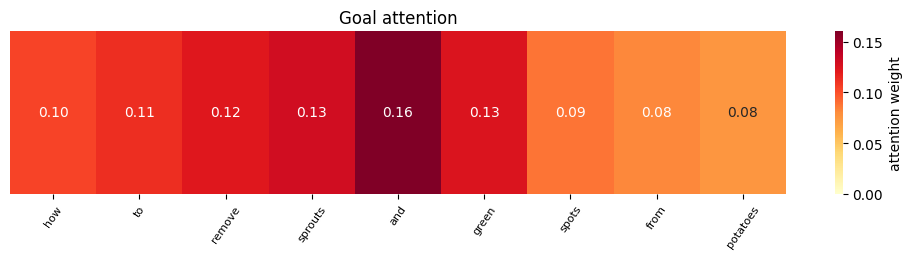

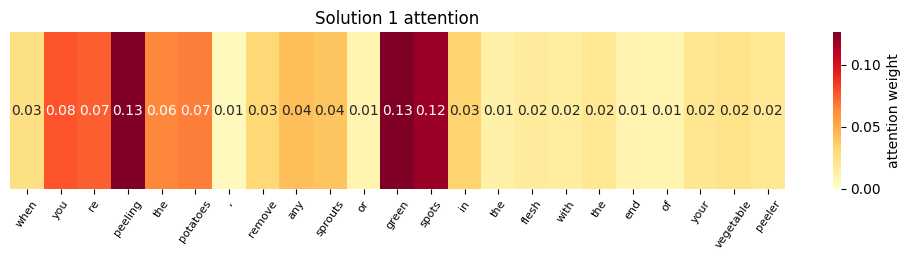

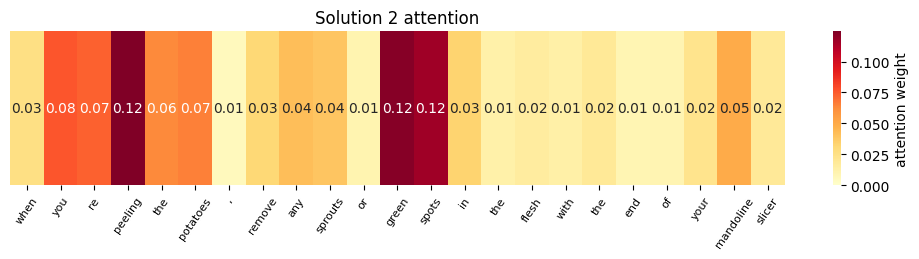

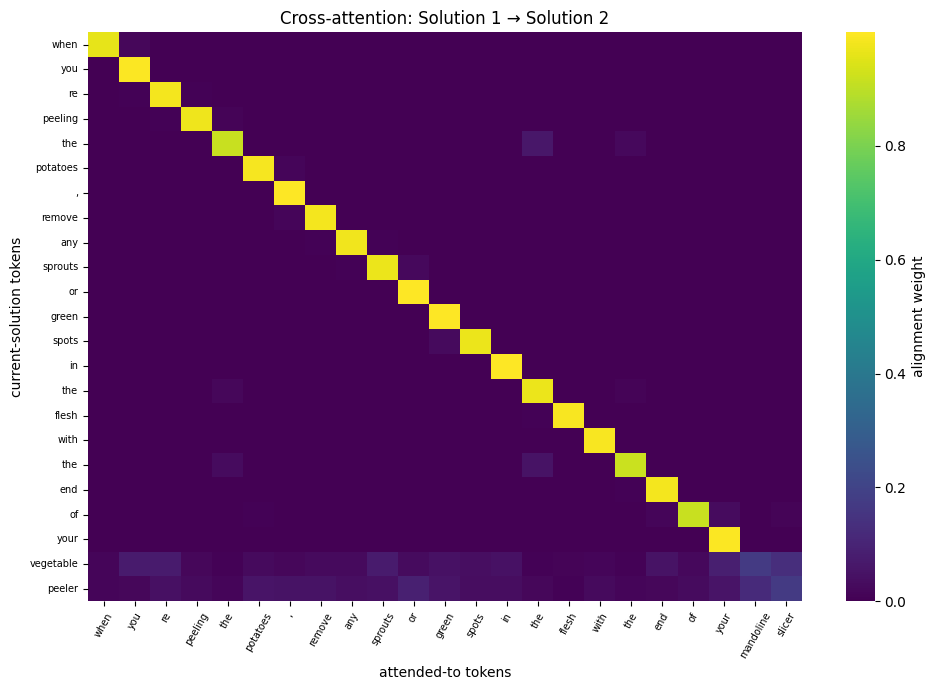

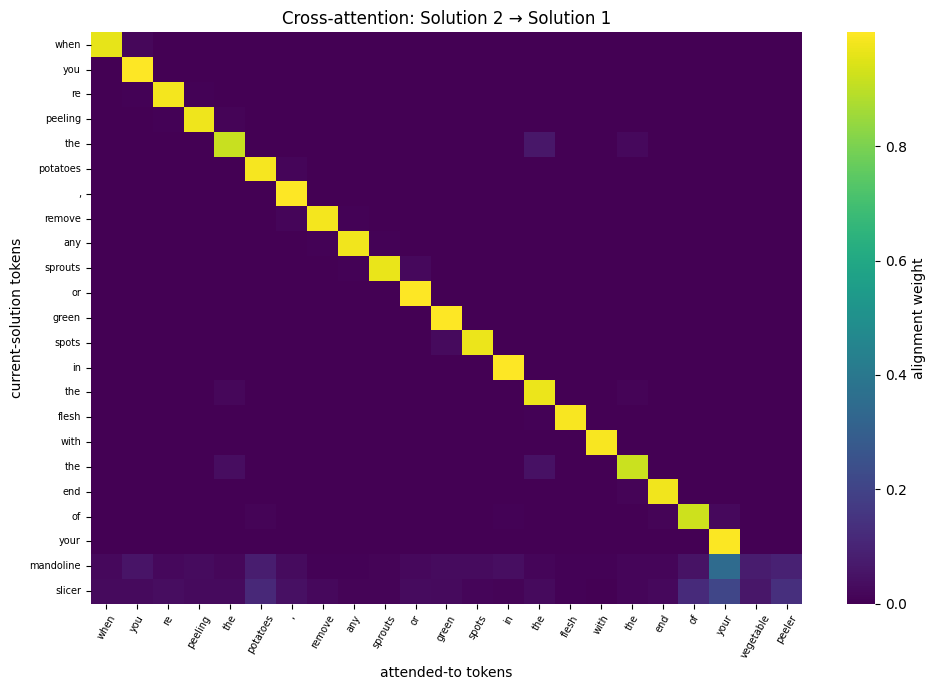

Rendered attention maps: goal_alpha, sol1_alpha, sol2_alpha, sol1_align, sol2_align


In [1]:
# @title Step 13B.5: Standalone attention heat maps from Google Drive
# Fresh-runtime cell: restore PIQA, download one verified Step 15B checkpoint, and plot.

from collections import Counter
from pathlib import Path
import hashlib
import io
import json
import os
import re
import zipfile

import gdown
import google.auth
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from sklearn.model_selection import train_test_split


# Change these three values to inspect another configuration, seed, or validation sample
STEP15B_HEATMAP_CONFIG = (
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention"
)
STEP15B_HEATMAP_SEED = 0
STEP15B_HEATMAP_SAMPLE_INDEX = 0


# ---------------------------------------------------------------------
# 1. Validate the parameters and restore the PIQA validation data in a fresh runtime
# ---------------------------------------------------------------------

_STEP15B5_VALID_CONFIGS = {
    "goal_guided_solution_attention_mean_mix",
    "goal_guided_solution_attention_mean_mix_with_cross_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention",
}
_STEP15B5_VALID_SEEDS = {0, 1, 2}

if STEP15B_HEATMAP_CONFIG not in _STEP15B5_VALID_CONFIGS:
    raise ValueError(
        "Unknown STEP15B_HEATMAP_CONFIG: "
        f"{STEP15B_HEATMAP_CONFIG!r}; choose from "
        + ", ".join(sorted(_STEP15B5_VALID_CONFIGS))
    )

try:
    STEP15B_HEATMAP_SEED = int(STEP15B_HEATMAP_SEED)
    STEP15B_HEATMAP_SAMPLE_INDEX = int(STEP15B_HEATMAP_SAMPLE_INDEX)
except (TypeError, ValueError) as exc:
    raise ValueError(
        "STEP15B_HEATMAP_SEED and STEP15B_HEATMAP_SAMPLE_INDEX "
        "must be integers."
    ) from exc

if STEP15B_HEATMAP_SEED not in _STEP15B5_VALID_SEEDS:
    raise ValueError(
        "STEP15B_HEATMAP_SEED must be one of "
        + ", ".join(str(seed) for seed in sorted(_STEP15B5_VALID_SEEDS))
    )

_STEP15B5_PIQA_DATA_FILE_ID = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
_STEP15B5_PIQA_DATA_DIR = Path("/content/step15b_heatmap_data")
_STEP15B5_PIQA_FILENAMES = (
    "train.jsonl",
    "train-labels.lst",
    "test.jsonl",
    "test-labels.lst",
)


def _step15b5_ensure_piqa_data():
    """Download the public PIQA archive once and return its four data paths."""
    _STEP15B5_PIQA_DATA_DIR.mkdir(parents=True, exist_ok=True)
    located = {
        name: next(iter(_STEP15B5_PIQA_DATA_DIR.rglob(name)), None)
        for name in _STEP15B5_PIQA_FILENAMES
    }

    if any(path is None for path in located.values()):
        archive_path = _STEP15B5_PIQA_DATA_DIR / "piqa_data.zip"
        downloaded_path = gdown.download(
            id=_STEP15B5_PIQA_DATA_FILE_ID,
            output=str(archive_path),
            quiet=False,
        )
        if downloaded_path is None or not archive_path.is_file():
            raise RuntimeError("PIQA data download failed.")
        try:
            with zipfile.ZipFile(archive_path) as archive:
                archive.extractall(_STEP15B5_PIQA_DATA_DIR)
        except (OSError, zipfile.BadZipFile) as exc:
            raise RuntimeError("The downloaded PIQA archive is invalid.") from exc

        located = {
            name: next(iter(_STEP15B5_PIQA_DATA_DIR.rglob(name)), None)
            for name in _STEP15B5_PIQA_FILENAMES
        }

    missing = [name for name, path in located.items() if path is None]
    if missing:
        raise RuntimeError("PIQA archive is missing: " + ", ".join(missing))
    return located


def _step15b5_clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()


def _step15b5_read_piqa(data_path, label_path):
    with open(data_path, encoding="utf-8") as data_file:
        data_lines = data_file.readlines()
    with open(label_path, encoding="utf-8") as label_file:
        label_lines = label_file.readlines()

    rows = []
    for line, label in zip(data_lines, label_lines):
        if not label.strip():
            continue
        item = json.loads(line)
        rows.append({
            "goal": item["goal"],
            "sol1": item["sol1"],
            "sol2": item["sol2"],
            "label": int(label.strip()),
        })
    return rows


def _step15b5_build_vocabulary(rows, min_count=2):
    word_count = Counter()
    for item in rows:
        word_count.update(_step15b5_clean_str(item["goal"]).split())
        word_count.update(_step15b5_clean_str(item["sol1"]).split())
        word_count.update(_step15b5_clean_str(item["sol2"]).split())

    vocabulary = {"<pad>": 0, "<unk>": 1}
    for word, count in word_count.most_common():
        if count >= min_count:
            vocabulary[word] = len(vocabulary)
    return vocabulary


def _step15b5_words_to_index(words, vocabulary, maxlength):
    indices = np.zeros(maxlength, dtype=np.int64)
    for index, word in enumerate(words[:maxlength]):
        indices[index] = vocabulary.get(word, 1)
    return indices


def _step15b5_make_batch_input(rows, vocabulary, maxgoal=20, maxsol=60):
    size = len(rows)
    goal = np.zeros((size, maxgoal), dtype=np.int64)
    sol1 = np.zeros((size, maxsol), dtype=np.int64)
    sol2 = np.zeros((size, maxsol), dtype=np.int64)
    labels = np.zeros(size, dtype=np.int64)

    for index, item in enumerate(rows):
        goal[index] = _step15b5_words_to_index(
            _step15b5_clean_str(item["goal"]).split(),
            vocabulary,
            maxgoal,
        )
        sol1[index] = _step15b5_words_to_index(
            _step15b5_clean_str(item["sol1"]).split(),
            vocabulary,
            maxsol,
        )
        sol2[index] = _step15b5_words_to_index(
            _step15b5_clean_str(item["sol2"]).split(),
            vocabulary,
            maxsol,
        )
        labels[index] = item["label"]

    return goal, sol1, sol2, labels


_step15b5_piqa_paths = _step15b5_ensure_piqa_data()
_step15b5_train_rows = _step15b5_read_piqa(
    _step15b5_piqa_paths["train.jsonl"],
    _step15b5_piqa_paths["train-labels.lst"],
)
_step15b5_labels = [item["label"] for item in _step15b5_train_rows]
_step15b5_train_part1, _step15b5_train_part2 = train_test_split(
    _step15b5_train_rows,
    test_size=0.15,
    random_state=0,
    stratify=_step15b5_labels,
)
_step15b5_vocabulary = _step15b5_build_vocabulary(
    _step15b5_train_part1,
    min_count=2,
)
_step15b5_val_input = _step15b5_make_batch_input(
    _step15b5_train_part2,
    _step15b5_vocabulary,
    maxgoal=20,
    maxsol=60,
)
_step15b5_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if not 0 <= STEP15B_HEATMAP_SAMPLE_INDEX < len(_step15b5_train_part2):
    raise IndexError(
        "STEP15B_HEATMAP_SAMPLE_INDEX must be between 0 and "
        f"{len(_step15b5_train_part2) - 1}."
    )

print(
    "PIQA validation restored: "
    f"{len(_step15b5_train_part2)} rows; "
    f"vocabulary={len(_step15b5_vocabulary)}"
)
print(f"Device: {_step15b5_device}")


# ---------------------------------------------------------------------
# 2. Define the model architecture exactly matching the Step 15B checkpoint
# ---------------------------------------------------------------------

def _step15b5_masked_pool(rnn_output, index, pooling="mean"):
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        return rnn_output.masked_fill(mask == 0, -1e9).max(dim=1)[0]
    total = (rnn_output * mask).sum(dim=1)
    count = mask.sum(dim=1).clamp(min=1.0)
    return total / count


def _step15b5_attention_on_solution(solution_output, solution_index, query):
    if query.dim() == 1:
        score = torch.matmul(solution_output, query)
    else:
        score = torch.bmm(
            solution_output,
            query.unsqueeze(2),
        ).squeeze(2)
    score = score.masked_fill(solution_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(
        alpha.unsqueeze(1),
        solution_output,
    ).squeeze(1)
    return context, alpha


def _step15b5_attention_on_goal(goal_output, goal_index, query):
    score = torch.matmul(goal_output, query)
    score = score.masked_fill(goal_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(
        alpha.unsqueeze(1),
        goal_output,
    ).squeeze(1)
    return context, alpha


class _Step15B5Model(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        dimension=100,
        n_hidden_input=100,
        dropout_input=0.25,
        num_layers_input=1,
        rnn_type="LSTM",
        pooling="mean",
        attention_type="none",
        goal_attention=False,
        use_cross_attention=False,
        use_interaction=True,
        use_goal=True,
    ):
        super().__init__()
        self.pooling = pooling
        self.attention_type = attention_type
        self.goal_attention = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction = use_interaction
        self.use_goal = use_goal

        self.embedding = nn.Embedding(
            vocabulary_size,
            dimension,
            padding_idx=0,
        )
        encoder_class = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.encoder = encoder_class(
            dimension,
            n_hidden_input,
            num_layers=num_layers_input,
            batch_first=True,
            bidirectional=True,
            dropout=dropout_input if num_layers_input > 1 else 0,
        )
        self.W = nn.Linear(
            n_hidden_input * 2,
            n_hidden_input * 2,
            bias=False,
        )
        self.pool_query = nn.Parameter(
            torch.randn(n_hidden_input * 2) * 0.1
        )
        self.goal_query = nn.Parameter(
            torch.randn(n_hidden_input * 2) * 0.1
        )

        if self.use_interaction:
            score_input = n_hidden_input * 2 * 4
        else:
            score_input = n_hidden_input * 2 * 2
        if self.use_cross_attention:
            score_input += n_hidden_input * 2

        self.hidden_layer = nn.Linear(
            score_input,
            n_hidden_input,
        )
        self.score_layer = nn.Linear(
            n_hidden_input,
            1,
        )
        self.dropout = nn.Dropout(dropout_input)

    def score_one_solution(
        self,
        goal_vector,
        current_sol_output,
        current_sol_index,
        other_sol_output,
        other_sol_index,
    ):
        raise NotImplementedError

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))

        if self.goal_attention:
            goal_vector, goal_alpha = _step15b5_attention_on_goal(
                goal_output,
                goal,
                self.goal_query,
            )
        else:
            goal_vector = _step15b5_masked_pool(
                goal_output,
                goal,
                self.pooling,
            )
            goal_alpha = None

        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)

        score1, alpha1, align1 = self.score_one_solution(
            goal_vector,
            sol1_output,
            solution1,
            sol2_output,
            solution2,
        )
        score2, alpha2, align2 = self.score_one_solution(
            goal_vector,
            sol2_output,
            solution2,
            sol1_output,
            solution1,
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
        }


class _Step15B5MeanMixModel(_Step15B5Model):
    """Step 15B model with a learned mix of goal-guided and mean contexts."""

    def __init__(
        self,
        vocabulary_size,
        cross_difference_pooling=None,
        **settings,
    ):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15B requires attention_type='goal'.")

        use_cross_attention = bool(
            settings.get("use_cross_attention", False)
        )
        if (
            use_cross_attention
            and cross_difference_pooling != "masked_mean_max"
        ):
            raise ValueError(
                "Cross-attention configurations require "
                "cross_difference_pooling='masked_mean_max'."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling

        if use_cross_attention:
            base_width = hidden_size * 2 * (
                4 if use_interaction else 2
            )
            self.hidden_layer = nn.Linear(
                base_width + hidden_size * 4,
                hidden_size,
            )

        self.goal_mean_mix_logit = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(
        self,
        goal_attention_context,
        mean_context,
    ):
        mix = self.goal_attention_lambda
        return (
            mix * goal_attention_context
            + (1.0 - mix) * mean_context
        )

    def score_one_solution(
        self,
        goal_vector,
        current_sol_output,
        current_sol_index,
        other_sol_output,
        other_sol_index,
    ):
        query = self.W(goal_vector)
        goal_attention_context, alpha = (
            _step15b5_attention_on_solution(
                current_sol_output,
                current_sol_index,
                query,
            )
        )
        mean_context = _step15b5_masked_pool(
            current_sol_output,
            current_sol_index,
            pooling="mean",
        )
        context = self.mix_solution_context(
            goal_attention_context,
            mean_context,
        )

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat(
                (goal_vector, context),
                dim=1,
            )

        align = None
        if self.use_cross_attention:
            similarity = torch.bmm(
                current_sol_output,
                other_sol_output.transpose(1, 2),
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1),
                -1e9,
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(
                align,
                other_sol_output,
            )
            token_difference = (
                current_sol_output - aligned_other
            )

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(
                ~current_mask,
                0.0,
            )
            valid_count = (
                current_mask.sum(dim=1)
                .clamp(min=1)
                .to(token_difference.dtype)
            )
            mean_difference = (
                masked_difference.sum(dim=1)
                / valid_count
            )

            max_difference = token_difference.masked_fill(
                ~current_mask,
                torch.finfo(token_difference.dtype).min,
            ).max(dim=1).values
            max_difference = torch.where(
                current_mask.any(dim=1),
                max_difference,
                torch.zeros_like(max_difference),
            )
            combined = torch.cat(
                (
                    combined,
                    mean_difference,
                    max_difference,
                ),
                dim=1,
            )

        combined = self.dropout(combined)
        hidden = torch.relu(
            self.hidden_layer(combined)
        )
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _step15b5_build_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop(
        "cross_difference_pooling",
        None,
    )
    return _Step15B5MeanMixModel(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


_STEP15B5_CONFIG_SWITCHES = {
    "goal_guided_solution_attention_mean_mix": (
        False,
        False,
    ),
    "goal_guided_solution_attention_mean_mix_with_cross_attention": (
        False,
        True,
    ),
    "goal_guided_solution_attention_mean_mix_with_goal_attention": (
        True,
        False,
    ),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention": (
        True,
        True,
    ),
}


def _step15b5_validate_settings(configuration, settings):
    if not isinstance(settings, dict):
        raise ValueError("JSON is missing the Step 15B settings object.")

    expected_goal, expected_cross = (
        _STEP15B5_CONFIG_SWITCHES[configuration]
    )
    actual = (
        settings.get("attention_type"),
        bool(settings.get("goal_attention", False)),
        bool(settings.get("use_cross_attention", False)),
    )
    expected = ("goal", expected_goal, expected_cross)
    if actual != expected:
        raise ValueError(
            "JSON settings do not match the requested configuration: "
            f"expected {expected}, got {actual}."
        )

    expected_pooling = (
        "masked_mean_max" if expected_cross else None
    )
    if settings.get("cross_difference_pooling") != expected_pooling:
        raise ValueError(
            "JSON cross_difference_pooling does not match the "
            "requested configuration."
        )


# ---------------------------------------------------------------------
# 3. Select the latest complete and validated Step 15B backup from Google Drive
# ---------------------------------------------------------------------

_STEP15B5_DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
_STEP15B5_DOWNLOAD_DIR = Path("/content/step15b_heatmap")
_STEP15B5_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)


def _step15b5_list_drive_files(service, folder_id):
    files = []
    page_token = None
    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            spaces="drive",
            fields=(
                "nextPageToken,"
                "files(id,name,mimeType,createdTime,modifiedTime,size)"
            ),
            orderBy="createdTime desc",
            pageSize=1000,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        files.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            return files


def _step15b5_download_drive_bytes(service, file_id):
    buffer = io.BytesIO()
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    downloader = MediaIoBaseDownload(buffer, request)
    complete = False
    while not complete:
        _, complete = downloader.next_chunk()
    return buffer.getvalue()


def _step15b5_download_drive_file(service, file_id, destination):
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    with destination.open("wb") as output_file:
        downloader = MediaIoBaseDownload(
            output_file,
            request,
        )
        complete = False
        while not complete:
            _, complete = downloader.next_chunk()


def _step15b5_sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as input_file:
        for chunk in iter(
            lambda: input_file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)
    return digest.hexdigest()


def _step15b5_select_drive_backup(
    files,
    configuration,
    seed,
    read_json,
    prepare_checkpoint,
):
    """Return the newest complete, verified and loadable Step 15B backup."""
    json_files = sorted(
        (
            item for item in files
            if item.get("name", "").startswith("step15b_")
            and item.get("name", "").endswith(".json")
        ),
        key=lambda item: item.get("createdTime", ""),
        reverse=True,
    )

    checkpoints_by_name = {}
    for item in files:
        if item.get("name", "").endswith(".pt"):
            checkpoints_by_name.setdefault(
                item["name"],
                [],
            ).append(item)

    matching_count = 0
    rejected = []

    for json_file in json_files:
        try:
            record = json.loads(
                read_json(json_file["id"])
            )
        except Exception as exc:
            rejected.append(
                f"{json_file.get('name')}: invalid JSON ({exc})"
            )
            continue

        try:
            record_seed = int(record.get("seed", -1))
        except (TypeError, ValueError):
            continue

        if (
            record.get("experiment") != "step15b"
            or record.get("configuration") != configuration
            or record_seed != seed
        ):
            continue

        matching_count += 1
        checkpoint_name = record.get("checkpoint_filename")
        if (
            not checkpoint_name
            or Path(checkpoint_name).name != checkpoint_name
        ):
            rejected.append(
                f"{json_file['name']}: invalid checkpoint filename"
            )
            continue

        checkpoint_files = sorted(
            checkpoints_by_name.get(checkpoint_name, []),
            key=lambda item: item.get("createdTime", ""),
            reverse=True,
        )
        if not checkpoint_files:
            rejected.append(
                f"{json_file['name']}: paired .pt is missing"
            )
            continue

        for checkpoint_file in checkpoint_files:
            try:
                checkpoint_candidate = prepare_checkpoint(
                    checkpoint_file,
                    record,
                )
            except Exception as exc:
                rejected.append(
                    f"{json_file['name']} + "
                    f"{checkpoint_file['name']}: {exc}"
                )
                continue
            return (
                json_file,
                checkpoint_file,
                record,
                checkpoint_candidate,
                rejected,
            )

    if matching_count == 0:
        raise RuntimeError(
            "Google Drive has no Step 15B JSON for "
            f"configuration={configuration!r}, seed={seed}."
        )

    details = "\n".join(
        "- " + item for item in rejected[-8:]
    )
    raise RuntimeError(
        "Google Drive contains matching Step 15B JSON records, "
        "but none has a complete, verified and loadable checkpoint."
        + ("\n" + details if details else "")
    )


def _step15b5_fetch_verified_checkpoint(
    service,
    checkpoint_file,
    record,
):
    expected = record.get("checkpoint_sha256")
    if (
        not isinstance(expected, str)
        or re.fullmatch(r"[0-9a-fA-F]{64}", expected) is None
    ):
        raise ValueError(
            "JSON is missing a valid checkpoint_sha256."
        )
    expected = expected.lower()

    checkpoint_name = checkpoint_file.get("name", "")
    if (
        not checkpoint_name
        or Path(checkpoint_name).name != checkpoint_name
        or checkpoint_name != record.get("checkpoint_filename")
    ):
        raise ValueError(
            "Drive checkpoint filename is unsafe or does not match JSON."
        )

    destination = _STEP15B5_DOWNLOAD_DIR / checkpoint_name
    if (
        destination.is_file()
        and _step15b5_sha256_file(destination) == expected
    ):
        return destination

    temporary = destination.with_name(
        destination.name + ".part"
    )
    try:
        _step15b5_download_drive_file(
            service,
            checkpoint_file["id"],
            temporary,
        )
        actual = _step15b5_sha256_file(temporary)
        if actual != expected:
            raise ValueError(
                "SHA-256 mismatch: "
                f"expected {expected}, got {actual}."
            )
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()

    return destination


def _step15b5_prepare_checkpoint(
    service,
    checkpoint_file,
    record,
    configuration,
):
    settings = record.get("settings")
    _step15b5_validate_settings(
        configuration,
        settings,
    )
    checkpoint_path = _step15b5_fetch_verified_checkpoint(
        service,
        checkpoint_file,
        record,
    )

    try:
        model = _step15b5_build_model(
            len(_step15b5_vocabulary),
            settings,
        ).to(_step15b5_device)
    except Exception as exc:
        raise RuntimeError(
            "Checkpoint settings cannot reconstruct the Step 15B model."
        ) from exc

    try:
        try:
            state_dict = torch.load(
                checkpoint_path,
                map_location=_step15b5_device,
                weights_only=True,
            )
        except TypeError:
            state_dict = torch.load(
                checkpoint_path,
                map_location=_step15b5_device,
            )
    except Exception as exc:
        raise RuntimeError(
            "Checkpoint cannot be read by PyTorch."
        ) from exc

    try:
        model.load_state_dict(state_dict)
    except RuntimeError as exc:
        raise RuntimeError(
            "Checkpoint model structure or vocabulary does not match "
            "the restored Step 15B environment."
        ) from exc

    model.eval()
    return {
        "checkpoint_path": checkpoint_path,
        "settings": settings,
        "model": model,
    }


auth.authenticate_user()
_step15b5_credentials, _ = google.auth.default()
_step15b5_drive_service = build(
    "drive",
    "v3",
    credentials=_step15b5_credentials,
    cache_discovery=False,
)
_step15b5_drive_folder = (
    _step15b5_drive_service.files().get(
        fileId=_STEP15B5_DRIVE_FOLDER_ID,
        fields="id,name,mimeType",
        supportsAllDrives=True,
    ).execute()
)
if (
    _step15b5_drive_folder.get("mimeType")
    != "application/vnd.google-apps.folder"
):
    raise RuntimeError(
        "The configured Google Drive target is not a folder."
    )

_step15b5_drive_files = _step15b5_list_drive_files(
    _step15b5_drive_service,
    _STEP15B5_DRIVE_FOLDER_ID,
)
(
    _step15b5_json_drive_file,
    _step15b5_checkpoint_drive_file,
    _step15b5_record,
    _step15b5_checkpoint_candidate,
    _step15b5_rejected_backups,
) = _step15b5_select_drive_backup(
    _step15b5_drive_files,
    STEP15B_HEATMAP_CONFIG,
    STEP15B_HEATMAP_SEED,
    lambda file_id: _step15b5_download_drive_bytes(
        _step15b5_drive_service,
        file_id,
    ),
    lambda checkpoint_file, record: _step15b5_prepare_checkpoint(
        _step15b5_drive_service,
        checkpoint_file,
        record,
        STEP15B_HEATMAP_CONFIG,
    ),
)

for _step15b5_rejected in _step15b5_rejected_backups:
    print("Skipped Drive backup:", _step15b5_rejected)

_step15b5_checkpoint_path = (
    _step15b5_checkpoint_candidate["checkpoint_path"]
)
_step15b5_json_name = _step15b5_json_drive_file.get(
    "name",
    "",
)
if (
    not _step15b5_json_name
    or Path(_step15b5_json_name).name != _step15b5_json_name
):
    raise RuntimeError(
        "Drive JSON filename is unsafe."
    )
_step15b5_json_path = (
    _STEP15B5_DOWNLOAD_DIR / _step15b5_json_name
)
_step15b5_json_temporary = _step15b5_json_path.with_name(
    _step15b5_json_path.name + ".part"
)
_step15b5_json_temporary.write_text(
    json.dumps(
        _step15b5_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)
os.replace(
    _step15b5_json_temporary,
    _step15b5_json_path,
)

_step15b5_model = _step15b5_checkpoint_candidate["model"]
print(
    "Drive folder: "
    f"{_step15b5_drive_folder.get('name')} "
    f"({_step15b5_drive_folder['id']})"
)


# ---------------------------------------------------------------------
# 4. Read the validation sample and run the model
# ---------------------------------------------------------------------

(
    _step15b5_goal_array,
    _step15b5_sol1_array,
    _step15b5_sol2_array,
    _step15b5_label_array,
) = _step15b5_val_input

_step15b5_sample_index = STEP15B_HEATMAP_SAMPLE_INDEX
_step15b5_goal_tensor = torch.as_tensor(
    _step15b5_goal_array[
        _step15b5_sample_index:_step15b5_sample_index + 1
    ],
    dtype=torch.long,
    device=_step15b5_device,
)
_step15b5_sol1_tensor = torch.as_tensor(
    _step15b5_sol1_array[
        _step15b5_sample_index:_step15b5_sample_index + 1
    ],
    dtype=torch.long,
    device=_step15b5_device,
)
_step15b5_sol2_tensor = torch.as_tensor(
    _step15b5_sol2_array[
        _step15b5_sample_index:_step15b5_sample_index + 1
    ],
    dtype=torch.long,
    device=_step15b5_device,
)

with torch.no_grad():
    _step15b5_logits, _step15b5_attention = _step15b5_model(
        _step15b5_goal_tensor,
        _step15b5_sol1_tensor,
        _step15b5_sol2_tensor,
    )
    _step15b5_probabilities = (
        torch.softmax(_step15b5_logits, dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )
    _step15b5_prediction = int(
        _step15b5_logits.argmax(dim=1).item()
    )
    _step15b5_learned_lambda = float(
        _step15b5_model.goal_attention_lambda
        .detach()
        .cpu()
        .item()
    )

_step15b5_gold = int(
    _step15b5_label_array[_step15b5_sample_index]
)
_step15b5_row = _step15b5_train_part2[
    _step15b5_sample_index
]


# ---------------------------------------------------------------------
# 5. Heat map helpers
# ---------------------------------------------------------------------

def _step15b5_visible_tokens(text, index_row):
    """Return the original tokens represented by non-padding indices."""
    token_count = int(np.count_nonzero(index_row))
    return _step15b5_clean_str(text).split()[:token_count]


def _step15b5_first_numpy(value):
    """Return the first batch item as a NumPy array."""
    if value is None:
        return None
    return value.detach().cpu().numpy()[0]


def _step15b5_draw_token_heatmap(
    tokens,
    weights,
    title,
):
    values = np.asarray(
        weights[:len(tokens)],
        dtype=float,
    )
    if (
        not tokens
        or values.size == 0
        or np.allclose(values, 0.0)
    ):
        return False

    width = max(
        10,
        min(22, 0.38 * len(tokens)),
    )
    _, ax = plt.subplots(
        figsize=(width, 2.7)
    )
    sns.heatmap(
        values.reshape(1, -1),
        cmap="YlOrRd",
        vmin=0.0,
        xticklabels=tokens,
        yticklabels=False,
        annot=len(tokens) <= 25,
        fmt=".2f",
        cbar_kws={"label": "attention weight"},
        ax=ax,
    )
    ax.set_title(title)
    ax.tick_params(
        axis="x",
        rotation=55,
        labelsize=8,
    )
    plt.tight_layout()
    plt.show()
    return True


def _step15b5_draw_cross_heatmap(
    matrix,
    row_tokens,
    column_tokens,
    title,
):
    values = np.asarray(
        matrix,
        dtype=float,
    )[
        :len(row_tokens),
        :len(column_tokens),
    ]
    if (
        not row_tokens
        or not column_tokens
        or values.size == 0
        or np.allclose(values, 0.0)
    ):
        return False

    width = max(
        10,
        min(24, 0.36 * len(column_tokens)),
    )
    height = max(
        7,
        min(20, 0.30 * len(row_tokens)),
    )
    _, ax = plt.subplots(
        figsize=(width, height)
    )
    sns.heatmap(
        values,
        cmap="viridis",
        vmin=0.0,
        xticklabels=column_tokens,
        yticklabels=row_tokens,
        cbar_kws={"label": "alignment weight"},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("attended-to tokens")
    ax.set_ylabel("current-solution tokens")
    ax.tick_params(
        axis="x",
        rotation=60,
        labelsize=7,
    )
    ax.tick_params(
        axis="y",
        rotation=0,
        labelsize=7,
    )
    plt.tight_layout()
    plt.show()
    return True


# ---------------------------------------------------------------------
# 6. Display the sample, predictions, and all available attention maps
# ---------------------------------------------------------------------

_step15b5_goal_tokens = _step15b5_visible_tokens(
    _step15b5_row["goal"],
    _step15b5_goal_array[_step15b5_sample_index],
)
_step15b5_sol1_tokens = _step15b5_visible_tokens(
    _step15b5_row["sol1"],
    _step15b5_sol1_array[_step15b5_sample_index],
)
_step15b5_sol2_tokens = _step15b5_visible_tokens(
    _step15b5_row["sol2"],
    _step15b5_sol2_array[_step15b5_sample_index],
)

print(
    "Checkpoint : "
    f"{_step15b5_checkpoint_path.name} "
    f"(Drive id: {_step15b5_checkpoint_drive_file['id']})"
)
print(
    "Drive JSON : "
    f"{_step15b5_json_path.name} "
    f"(Drive id: {_step15b5_json_drive_file['id']})"
)
print(
    "Config/seed: "
    f"{STEP15B_HEATMAP_CONFIG} / "
    f"{STEP15B_HEATMAP_SEED}"
)
print(
    "Sample     : validation row "
    f"{_step15b5_sample_index}"
)
print(f"Goal       : {_step15b5_row['goal']}")
print(f"Solution 1 : {_step15b5_row['sol1']}")
print(f"Solution 2 : {_step15b5_row['sol2']}")
print(f"Gold       : solution {_step15b5_gold + 1}")
print(
    "Learned lambda: "
    f"{_step15b5_learned_lambda:.6f}"
)
print(
    "Prediction : solution "
    f"{_step15b5_prediction + 1} "
    f"(p1={_step15b5_probabilities[0]:.4f}, "
    f"p2={_step15b5_probabilities[1]:.4f}) "
    f"{'✓ correct' if _step15b5_prediction == _step15b5_gold else '✗ incorrect'}"
)

_step15b5_rendered = []
_step15b5_attention_specs = (
    (
        "goal_alpha",
        _step15b5_goal_tokens,
        "Goal attention",
    ),
    (
        "sol1_alpha",
        _step15b5_sol1_tokens,
        "Solution 1 attention",
    ),
    (
        "sol2_alpha",
        _step15b5_sol2_tokens,
        "Solution 2 attention",
    ),
)

for _step15b5_key, _step15b5_tokens, _step15b5_title in (
    _step15b5_attention_specs
):
    _step15b5_values = _step15b5_first_numpy(
        _step15b5_attention.get(_step15b5_key)
    )
    if _step15b5_draw_token_heatmap(
        _step15b5_tokens,
        (
            _step15b5_values
            if _step15b5_values is not None
            else []
        ),
        _step15b5_title,
    ):
        _step15b5_rendered.append(_step15b5_key)

_step15b5_cross_specs = (
    (
        "sol1_align",
        _step15b5_sol1_tokens,
        _step15b5_sol2_tokens,
        "Cross-attention: Solution 1 → Solution 2",
    ),
    (
        "sol2_align",
        _step15b5_sol2_tokens,
        _step15b5_sol1_tokens,
        "Cross-attention: Solution 2 → Solution 1",
    ),
)

for (
    _step15b5_key,
    _step15b5_row_tokens,
    _step15b5_column_tokens,
    _step15b5_title,
) in _step15b5_cross_specs:
    _step15b5_matrix = _step15b5_first_numpy(
        _step15b5_attention.get(_step15b5_key)
    )
    if _step15b5_draw_cross_heatmap(
        (
            _step15b5_matrix
            if _step15b5_matrix is not None
            else np.empty((0, 0))
        ),
        _step15b5_row_tokens,
        _step15b5_column_tokens,
        _step15b5_title,
    ):
        _step15b5_rendered.append(_step15b5_key)

if _step15b5_rendered:
    print(
        "Rendered attention maps:",
        ", ".join(_step15b5_rendered),
    )
else:
    print(
        "The selected checkpoint has no visible non-zero "
        "attention map."
    )

In [27]:
# @title [RUN] Step 13C.1: Configurations, model, and smoke checks (local)

import csv
import datetime
import inspect
import json
import math
import os
import platform
import time
import uuid

_step15c_required = [
    "PIQA_Model", "masked_pool", "train_model", "predict_all", "set_seed",
    "vocabulary", "device", "np", "torch", "train_part1_input",
    "train_part2_input", "base_settings", "STEP15_SEEDS", "STEP15_EPOCHS",
    "STEP15_LEARNING_RATE", "STEP15_BATCH_SIZE", "STEP15_OUTPUT_ROOT",
]
_step15c_missing = [name for name in _step15c_required if name not in globals()]
if _step15c_missing:
    raise RuntimeError(
        "Run the data preparation, Steps 6-8, base_settings, and Step 15A cells first. Missing: "
        + ", ".join(_step15c_missing)
    )

assert tuple(STEP15_SEEDS) == (0, 1, 2), "Step 15C uses seeds 0, 1, and 2."
assert STEP15_EPOCHS == 15, "Step 15C uses 15 epochs."

# These switches mirror the four Step 15B A2/A3 configurations.
STEP15C_CONFIGURATION_SWITCHES = [
    ("goal_guided_solution_attention_mean_mix", False, False),
    ("goal_guided_solution_attention_mean_mix_with_cross_attention", False, True),
    ("goal_guided_solution_attention_mean_mix_with_goal_attention", True, False),
    ("goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention", True, True),
]
STEP15C_TEMPERATURE_MODES = [
    ("unscaled", "unscaled"),
    ("fixed_sqrt_d", "fixed_sqrt_d"),
    ("learned_temperature", "learned_temperature"),
]
assert len(STEP15C_CONFIGURATION_SWITCHES) == 4
assert len(STEP15C_TEMPERATURE_MODES) == 3
assert len({name for name, _, _ in STEP15C_CONFIGURATION_SWITCHES}) == 4
assert len({name for name, _ in STEP15C_TEMPERATURE_MODES}) == 3

_step15c_defaults = {
    name: parameter.default
    for name, parameter in inspect.signature(PIQA_Model.__init__).parameters.items()
    if name not in ("self", "vocabulary_size")
    and parameter.default is not inspect.Parameter.empty
}
STEP15C_BASE_CONFIGS = []
for _name, _goal_attention, _cross_attention in STEP15C_CONFIGURATION_SWITCHES:
    _settings = dict(_step15c_defaults)
    _settings.update(base_settings)
    _settings.update({
        "attention_type": "goal",
        "goal_attention": _goal_attention,
        "use_cross_attention": _cross_attention,
        "pooling": "mean",
        "use_goal": True,
    })
    if _cross_attention:
        _settings["cross_difference_pooling"] = "masked_mean_max"
    STEP15C_BASE_CONFIGS.append((_name, _settings))

STEP15C_VARIANTS = [
    (
        f"{_base_name}__{_mode_name}",
        _base_name,
        _mode_name,
        _mode,
        dict(_settings),
    )
    for _base_name, _settings in STEP15C_BASE_CONFIGS
    for _mode_name, _mode in STEP15C_TEMPERATURE_MODES
]
assert len(STEP15C_VARIANTS) == 12
assert len({variant[0] for variant in STEP15C_VARIANTS}) == 12
assert len(STEP15C_VARIANTS) * len(STEP15_SEEDS) == 36


class PIQA_Step15C_Temperature_Model(PIQA_Model):
    """Step 15B mean-mix model with selectable A1 solution-attention temperature."""

    VALID_TEMPERATURE_MODES = {
        "unscaled", "fixed_sqrt_d", "learned_temperature"
    }

    def __init__(
        self,
        vocabulary_size,
        temperature_mode,
        cross_difference_pooling=None,
        **settings,
    ):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15C requires attention_type='goal'.")
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Step 15C uses masked mean as the mix fallback.")
        if temperature_mode not in self.VALID_TEMPERATURE_MODES:
            raise ValueError(f"Unknown temperature mode: {temperature_mode}")

        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must use masked_mean_max difference pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_mode = temperature_mode
        self.temperature_epsilon = 1e-6

        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            # Match Step 15B: append masked mean and max token-difference vectors.
            self.hidden_layer = torch.nn.Linear(
                base_width + hidden_size * 4, hidden_size
            )

        attention_dim = self.W.out_features
        sqrt_d = math.sqrt(attention_dim)
        initial_temperature = 1.0 if temperature_mode == "unscaled" else sqrt_d

        if temperature_mode == "learned_temperature":
            initial_raw = math.log(math.expm1(initial_temperature))
            self.raw_attention_temperature = torch.nn.Parameter(
                torch.tensor(initial_raw, dtype=self.W.weight.dtype)
            )
            self.register_buffer(
                "fixed_attention_temperature",
                torch.tensor(initial_temperature, dtype=self.W.weight.dtype),
            )
        else:
            self.register_parameter("raw_attention_temperature", None)
            self.register_buffer(
                "fixed_attention_temperature",
                torch.tensor(initial_temperature, dtype=self.W.weight.dtype),
            )

        # One learned lambda is shared by the two solution branches.
        self.goal_mean_mix_logit = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        if self.temperature_mode == "learned_temperature":
            return (
                torch.nn.functional.softplus(self.raw_attention_temperature)
                + self.temperature_epsilon
            )
        return self.fixed_attention_temperature

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * attention_context + (1.0 - mix) * mean_context

    def score_one_solution(
        self,
        goal_vector,
        current_sol_output,
        current_sol_index,
        other_sol_output,
        other_sol_index,
    ):
        # Temperature changes A1 solution attention only.
        query = self.W(goal_vector)
        score = torch.bmm(
            current_sol_output, query.unsqueeze(2)
        ).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        attention_context = torch.bmm(
            alpha.unsqueeze(1), current_sol_output
        ).squeeze(1)
        mean_context = masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(attention_context, mean_context)

        if self.use_interaction:
            combined = torch.cat(
                (
                    goal_vector,
                    context,
                    goal_vector * context,
                    torch.abs(goal_vector - context),
                ),
                dim=1,
            )
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            # Keep A3 alignment unscaled, matching Step 15B's cross-attention path.
            similarity = torch.bmm(
                current_sol_output, other_sol_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count
            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens,
                max_difference,
                torch.zeros_like(max_difference),
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        solution_score = self.score_layer(hidden).squeeze(1)
        return solution_score, alpha, align


def _build_step15c_model(
    vocabulary_size, temperature_mode, settings
):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15C_Temperature_Model(
        vocabulary_size,
        temperature_mode=temperature_mode,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


_step15c_attention_dim = 2 * int(base_settings.get("n_hidden_input", 100))
_step15c_sqrt_d = math.sqrt(_step15c_attention_dim)
_step15c_base_width = _step15c_attention_dim * (
    4 if base_settings.get("use_interaction", True) else 2
)
_step15c_mode_expected_initial = {
    "unscaled": 1.0,
    "fixed_sqrt_d": _step15c_sqrt_d,
    "learned_temperature": _step15c_sqrt_d,
}

# Run all 12 model combinations through smoke checks before creating outputs.
assert len(vocabulary) > 10, "The vocabulary is too small to construct the Step 15C smoke-test input."
set_seed(0)
_step15c_goal_probe = torch.tensor(
    [[1, 2, 3, 0], [4, 5, 6, 7]], device=device
)
_step15c_sol1_probe = torch.tensor(
    [[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device
)
_step15c_sol2_probe = torch.tensor(
    [[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device
)
_step15c_label_probe = torch.tensor(
    [0, 1], dtype=torch.long, device=device
)

for (
    _variant_name,
    _base_name,
    _mode_name,
    _mode,
    _settings,
) in STEP15C_VARIANTS:
    set_seed(0)
    _probe_model = _build_step15c_model(
        len(vocabulary), _mode, _settings
    ).to(device)
    _expected_width = _step15c_base_width + (
        _step15c_attention_dim * 2 if _settings["use_cross_attention"] else 0
    )
    assert _probe_model.W.out_features == _step15c_attention_dim
    assert _probe_model.hidden_layer.in_features == _expected_width, (
        f"Bad score feature width: {_variant_name}"
    )

    _initial_temperature = _probe_model.attention_temperature.detach()
    assert torch.allclose(
        _initial_temperature,
        torch.tensor(
            _step15c_mode_expected_initial[_mode],
            dtype=_initial_temperature.dtype,
            device=device,
        ),
        atol=1e-5,
    ), f"Unexpected initial temperature in {_variant_name}."
    _initial_lambda = _probe_model.goal_attention_lambda.detach()
    assert torch.allclose(
        _initial_lambda,
        torch.tensor(0.5, dtype=_initial_lambda.dtype, device=device),
        atol=1e-7,
    ), f"Lambda must start at 0.5 in {_variant_name}."

    _probe_model.eval()
    with torch.no_grad():
        _probe_logits, _probe_attention = _probe_model(
            _step15c_goal_probe, _step15c_sol1_probe, _step15c_sol2_probe
        )
    assert _probe_logits.shape == (2, 2)
    for _key, _indices in (
        ("sol1_alpha", _step15c_sol1_probe),
        ("sol2_alpha", _step15c_sol2_probe),
    ):
        _weights = _probe_attention[_key]
        assert torch.all(_weights[_indices == 0] == 0), (
            f"Padding received solution attention in {_variant_name}/{_key}."
        )
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        ), f"Solution attention weights do not sum to one in {_variant_name}."

    if _settings["goal_attention"]:
        _goal_weights = _probe_attention["goal_alpha"]
        assert _goal_weights is not None
        assert torch.all(_goal_weights[_step15c_goal_probe == 0] == 0), (
            f"Padding received goal attention in {_variant_name}."
        )
        assert torch.allclose(
            _goal_weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        )
    else:
        assert _probe_attention["goal_alpha"] is None

    if _settings["use_cross_attention"]:
        _align = _probe_attention["sol1_align"]
        assert _align is not None
        assert _align.shape == (2, 5, 5)
        _padded_keys = (_step15c_sol2_probe == 0).unsqueeze(1).expand_as(_align)
        assert torch.all(_align[_padded_keys] == 0), (
            f"Padding received cross-attention in {_variant_name}."
        )
    else:
        assert _probe_attention["sol1_align"] is None

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.mix_solution_context(
        torch.ones((2, _step15c_attention_dim), device=device),
        torch.zeros((2, _step15c_attention_dim), device=device),
    ).sum().backward()
    assert _probe_model.goal_mean_mix_logit.grad is not None
    assert torch.isfinite(_probe_model.goal_mean_mix_logit.grad).all()
    assert _probe_model.goal_mean_mix_logit.grad.abs().item() > 0

    if _mode == "learned_temperature":
        _probe_model.zero_grad(set_to_none=True)
        _probe_model.attention_temperature.backward()
        _temperature_grad = _probe_model.raw_attention_temperature.grad
        assert _temperature_grad is not None
        assert torch.isfinite(_temperature_grad).all()
        assert _temperature_grad.abs().item() > 0
        assert float(_probe_model.attention_temperature.detach().cpu()) > 0

    _probe_model.zero_grad(set_to_none=True)
    _probe_model.train()
    _probe_logits, _ = _probe_model(
        _step15c_goal_probe, _step15c_sol1_probe, _step15c_sol2_probe
    )
    torch.nn.functional.cross_entropy(
        _probe_logits, _step15c_label_probe
    ).backward()
    assert _probe_model.goal_mean_mix_logit.grad is not None
    if _mode == "learned_temperature":
        assert _probe_model.raw_attention_temperature.grad is not None
    del _probe_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    "Step 15C smoke checks passed: 4 configurations × 3 temperature modes, "
    "goal/cross attention, padding masks, dimensions, lambda, and gradients."
)



Step 15C smoke checks passed: 4 configurations × 3 temperature modes, goal/cross attention, padding masks, dimensions, lambda, and gradients.


In [28]:
# @title Step 13C.2: Metrics and local output setup

if "_upload_attention_backup" not in globals():
    raise RuntimeError("Run Steps 13.1–13.2 in the current runtime first to enable Drive backups.")

STEP15C_MIX_FORMULA = (
    "lambda * goal_attention_context + (1 - lambda) * masked_mean_context"
)


def _save_step15c_backup(checkpoint_path, checkpoint_payload, settings, row):
    """Save one local checkpoint/JSON pair, then back it up to Drive."""
    torch.save(checkpoint_payload, checkpoint_path)
    checkpoint_name = os.path.basename(checkpoint_path)
    json_path = os.path.splitext(checkpoint_path)[0] + ".json"
    json_name = os.path.basename(json_path)
    with open(checkpoint_path, "rb") as checkpoint_file:
        checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()
    record = {
        "experiment": "step15c",
        "run_id": _step15c_run_id,
        **checkpoint_payload.get("experiment_metadata", {}),
        **row,
        "settings": dict(settings),
        "training_parameters": dict(_step15c_training_settings),
        "checkpoint_filename": checkpoint_name,
        "checkpoint_sha256": checkpoint_sha256,
        "created_at_utc": datetime.datetime.now(
            datetime.timezone.utc
        ).isoformat(),
    }
    with open(json_path + ".tmp", "w", encoding="utf-8") as json_file:
        json.dump(record, json_file, indent=2, ensure_ascii=False)
    os.replace(json_path + ".tmp", json_path)
    print(f"  local backup saved: {checkpoint_path}; {json_path}")
    checkpoint_drive_file = _upload_attention_backup(
        checkpoint_path, checkpoint_name
    )
    json_drive_file = (
        _upload_attention_backup(json_path, json_name)
        if checkpoint_drive_file is not None else None
    )
    backup_info = {
        "checkpoint_sha256": checkpoint_sha256,
        "json_filename": json_name,
        "drive_checkpoint_file_id": (
            checkpoint_drive_file.get("id") if checkpoint_drive_file else None
        ),
        "drive_json_file_id": (
            json_drive_file.get("id") if json_drive_file else None
        ),
    }
    if checkpoint_drive_file is not None and json_drive_file is not None:
        print(
            f"  Drive backup saved: {checkpoint_drive_file['name']} "
            f"({checkpoint_drive_file['id']}); {json_drive_file['name']} "
            f"({json_drive_file['id']})"
        )
    else:
        print("  Drive backup incomplete; local Step 15C .pt and JSON were retained.")
    return backup_info


def _step15c_attention_stats(alpha, token_indices):
    """Return sequence-averaged entropy and peak weight, ignoring padding."""
    alpha = np.asarray(alpha, dtype=np.float64)
    token_mask = np.asarray(token_indices) != 0
    if alpha.shape != token_mask.shape:
        raise ValueError(
            f"Attention/index shape mismatch: {alpha.shape} != {token_mask.shape}"
        )
    entropies = []
    normalized_entropies = []
    max_weights = []
    for _weights, _valid in zip(alpha, token_mask):
        _valid_weights = _weights[_valid]
        if len(_valid_weights) == 0:
            continue
        _total = _valid_weights.sum()
        if not np.isfinite(_total) or _total <= 0:
            raise ValueError("Attention weights must sum to a positive finite value.")
        _valid_weights = _valid_weights / _total
        _entropy = -float(np.sum(
            _valid_weights * np.log(np.clip(_valid_weights, 1e-12, 1.0))
        ))
        _normalized_entropy = (
            _entropy / math.log(len(_valid_weights))
            if len(_valid_weights) > 1 else 0.0
        )
        entropies.append(_entropy)
        normalized_entropies.append(_normalized_entropy)
        max_weights.append(float(np.max(_valid_weights)))
    if not entropies:
        raise ValueError("No non-padding attention sequences were available.")
    return {
        "mean_entropy": float(np.mean(entropies)),
        "mean_normalized_entropy": float(np.mean(normalized_entropies)),
        "mean_max_attention_weight": float(np.mean(max_weights)),
        "sequence_count": int(len(entropies)),
    }


def _step15c_collect_attention_stats(model, validation_input):
    _, _sol1_alpha, _sol2_alpha = predict_all(model, validation_input)
    _sol1_stats = _step15c_attention_stats(_sol1_alpha, validation_input[1])
    _sol2_stats = _step15c_attention_stats(_sol2_alpha, validation_input[2])
    _combined_stats = _step15c_attention_stats(
        np.concatenate((_sol1_alpha, _sol2_alpha), axis=0),
        np.concatenate((validation_input[1], validation_input[2]), axis=0),
    )
    return {
        "sol1": _sol1_stats,
        "sol2": _sol2_stats,
        "both_solutions": _combined_stats,
    }


_step15c_csv_fields = [
    "configuration", "base_configuration", "metric", "seed",
    "best_validation_accuracy", "training_seconds", "temperature_mode",
    "temperature_parameterization", "attention_type", "goal_attention",
    "use_cross_attention", "attention_dim", "initial_temperature",
    "learned_temperature", "attention_scale", "goal_attention_lambda",
    "sol1_mean_entropy", "sol1_mean_normalized_entropy",
    "sol1_mean_max_attention_weight", "sol2_mean_entropy",
    "sol2_mean_normalized_entropy", "sol2_mean_max_attention_weight",
    "mean_entropy", "mean_normalized_entropy",
    "mean_max_attention_weight", "comparison_baseline",
    "paired_accuracy_delta", "checkpoint",
]
_step15c_seed_rows = []
_step15c_delta_rows = []
_step15c_summary_rows = []


def _step15c_write_csv(path, include_overall_seconds=None):
    with open(path, "w", newline="", encoding="utf-8") as _file:
        _writer = csv.DictWriter(_file, fieldnames=_step15c_csv_fields)
        _writer.writeheader()
        _writer.writerows(_step15c_seed_rows)
        _writer.writerows(_step15c_delta_rows)
        _writer.writerows(_step15c_summary_rows)
        if include_overall_seconds is not None:
            _writer.writerow({
                "configuration": "__all__",
                "metric": "overall_wall_time",
                "training_seconds": float(include_overall_seconds),
            })


def load_step15c_temperature_checkpoint(path, model, map_location=None):
    """Load a metadata-wrapped Step 15C checkpoint into a constructed model."""
    _checkpoint = torch.load(path, map_location=map_location)
    if not isinstance(_checkpoint, dict) or "model_state_dict" not in _checkpoint:
        raise ValueError("Not a metadata-wrapped Step 15C temperature checkpoint.")
    model.load_state_dict(_checkpoint["model_state_dict"])
    return _checkpoint.get("experiment_metadata", {})


_step15c_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15c_output_dir = os.path.abspath(os.path.join(
    STEP15_OUTPUT_ROOT, "step15c_temperature_" + _step15c_run_id
))
os.makedirs(_step15c_output_dir, exist_ok=False)
step15c_output_dir = _step15c_output_dir
_step15c_config_path = os.path.join(_step15c_output_dir, "step15c_config.json")
_step15c_metrics_path = os.path.join(_step15c_output_dir, "step15c_metrics.csv")
_step15c_training_settings = {
    "epochs": STEP15_EPOCHS,
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
}
_step15c_manifest = {
    "run_id": _step15c_run_id,
    "experiment": "step15b_configurations_with_solution_attention_temperature",
    "output_directory": _step15c_output_dir,
    "attention": {
        "score": "dot(solution_word_vector, W(goal_vector))",
        "formula": "softmax(score / temperature)",
        "temperature_applies_to": "A1 solution attention only",
        "attention_dimension": _step15c_attention_dim,
        "sqrt_dimension": _step15c_sqrt_d,
        "temperature_scope": "one scalar per model, shared by both solution branches",
        "cross_attention": (
            "unscaled alignment; append masked mean and max token differences"
        ),
        "padding": "masked before softmax; statistics exclude token index 0",
    },
    "context_mix": {
        "formula": STEP15C_MIX_FORMULA,
        "lambda_scope": "one learned scalar per model, shared by both solutions",
        "lambda_initial": 0.5,
        "lambda_parameterization": "sigmoid(logit), logit initialized to 0",
    },
    "seeds": list(STEP15_SEEDS),
    "training": _step15c_training_settings,
    "base_configurations": {
        _name: {
            "attention_type": _settings["attention_type"],
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "cross_difference_pooling": _settings.get(
                "cross_difference_pooling"
            ),
            "settings": _settings,
        }
        for _name, _settings in STEP15C_BASE_CONFIGS
    },
    "temperature_modes": {
        _mode_name: {
            "mode": _mode,
            "initial_temperature": _step15c_mode_expected_initial[_mode],
            "initial_attention_scale": (
                1.0 / _step15c_mode_expected_initial[_mode]
            ),
        }
        for _mode_name, _mode in STEP15C_TEMPERATURE_MODES
    },
    "configurations": {
        _variant_name: {
            "base_configuration": _base_name,
            "temperature_mode": _mode_name,
            "initial_temperature": _step15c_mode_expected_initial[_mode],
            "initial_attention_scale": (
                1.0 / _step15c_mode_expected_initial[_mode]
            ),
            "settings": _settings,
        }
        for (
            _variant_name,
            _base_name,
            _mode_name,
            _mode,
            _settings,
        ) in STEP15C_VARIANTS
    },
    "data": {
        "training_examples": len(train_part1_input[3]),
        "validation_examples": len(train_part2_input[3]),
        "input_order": ["goal", "sol1", "sol2", "label"],
        "training_shapes": [list(np.shape(part)) for part in train_part1_input],
        "validation_shapes": [list(np.shape(part)) for part in train_part2_input],
    },
    "runtime": {
        "device": str(device),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
    },
    "planned_runs": len(STEP15C_VARIANTS) * len(STEP15_SEEDS),
    "paired_comparison_baseline": "unscaled within each base configuration",
    "checkpoint_format": (
        "dict with model_state_dict and experiment_metadata"
    ),
    "results": [],
}
assert _step15c_manifest["planned_runs"] == 36
with open(_step15c_config_path, "w", encoding="utf-8") as _file:
    json.dump(_step15c_manifest, _file, indent=2, ensure_ascii=False)

_step15c_by_config_mode_seed = {}
_step15c_started = time.perf_counter()



In [29]:
# @title [RUN] Step 13C.3: Train all configuration-temperature-seed combinations

# Reset all random sources before every run; the same seed is paired across
# temperature modes within each Step 15B configuration.
for _seed in STEP15_SEEDS:
    for (
        _variant_name,
        _base_config_name,
        _mode_name,
        _temperature_mode,
        _settings,
    ) in STEP15C_VARIANTS:
        set_seed(_seed)
        _model = _build_step15c_model(
            len(vocabulary), _temperature_mode, _settings
        ).to(device)
        _initial_temperature = float(
            _step15c_mode_expected_initial[_temperature_mode]
        )
        _checkpoint_path = os.path.join(
            _step15c_output_dir,
            f"step15c_{_step15c_run_id}_{_variant_name}_seed{_seed}.pt",
        )
        _train_started = time.perf_counter()
        _model, _best_accuracy = train_model(
            _model,
            train_part1_input,
            train_part2_input,
            learning_rate=STEP15_LEARNING_RATE,
            batch_size=STEP15_BATCH_SIZE,
            epochs=STEP15_EPOCHS,
            model_name=_checkpoint_path,
            quiet=True,
        )
        _training_seconds = time.perf_counter() - _train_started

        # train_model restores the best validation-accuracy epoch before returning.
        _attention_stats = _step15c_collect_attention_stats(
            _model, train_part2_input
        )
        _learned_temperature = float(
            _model.attention_temperature.detach().cpu().item()
        )
        _attention_scale = 1.0 / _learned_temperature
        _learned_lambda = float(
            _model.goal_attention_lambda.detach().cpu().item()
        )
        _stats_both = _attention_stats["both_solutions"]
        _row = {
            "configuration": _variant_name,
            "base_configuration": _base_config_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "training_seconds": float(_training_seconds),
            "temperature_mode": _mode_name,
            "temperature_parameterization": (
                "softplus(raw_temperature) + epsilon"
                if _temperature_mode == "learned_temperature"
                else "fixed"
            ),
            "attention_type": "goal",
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "attention_dim": int(_step15c_attention_dim),
            "initial_temperature": _initial_temperature,
            "learned_temperature": _learned_temperature,
            "attention_scale": _attention_scale,
            "goal_attention_lambda": _learned_lambda,
            "sol1_mean_entropy": _attention_stats["sol1"]["mean_entropy"],
            "sol1_mean_normalized_entropy": (
                _attention_stats["sol1"]["mean_normalized_entropy"]
            ),
            "sol1_mean_max_attention_weight": (
                _attention_stats["sol1"]["mean_max_attention_weight"]
            ),
            "sol2_mean_entropy": _attention_stats["sol2"]["mean_entropy"],
            "sol2_mean_normalized_entropy": (
                _attention_stats["sol2"]["mean_normalized_entropy"]
            ),
            "sol2_mean_max_attention_weight": (
                _attention_stats["sol2"]["mean_max_attention_weight"]
            ),
            "mean_entropy": _stats_both["mean_entropy"],
            "mean_normalized_entropy": _stats_both["mean_normalized_entropy"],
            "mean_max_attention_weight": (
                _stats_both["mean_max_attention_weight"]
            ),
            "comparison_baseline": None,
            "paired_accuracy_delta": None,
            "checkpoint": _checkpoint_path,
        }
        _step15c_seed_rows.append(_row)
        _step15c_by_config_mode_seed[
            (_base_config_name, _mode_name, int(_seed))
        ] = _row

        _checkpoint_payload = {
            "format": "step15c_configuration_temperature_v2",
            "model_state_dict": _model.state_dict(),
            "experiment_metadata": {
                **_row,
                "checkpoint": os.path.basename(_checkpoint_path),
                "attention_statistics": _attention_stats,
                "mix_formula": STEP15C_MIX_FORMULA,
                "temperature_formula": "softmax(solution_score / temperature)",
                "temperature_applies_to": "A1 solution attention only",
                "cross_difference_pooling": _settings.get(
                    "cross_difference_pooling"
                ),
                "training": _step15c_training_settings,
            },
        }
        _backup_info = _save_step15c_backup(
            _checkpoint_path, _checkpoint_payload, _settings, _row
        )
        _step15c_manifest["results"].append({
            **_row,
            "checkpoint": os.path.basename(_checkpoint_path),
            "attention_statistics": _attention_stats,
            **_backup_info,
        })
        _step15c_write_csv(_step15c_metrics_path)
        with open(_step15c_config_path, "w", encoding="utf-8") as _file:
            json.dump(_step15c_manifest, _file, indent=2, ensure_ascii=False)

        print(
            f"{_base_config_name} | {_mode_name:20s} seed={_seed} "
            f"accuracy={_best_accuracy:.4f} train={_training_seconds:.1f}s "
            f"T={_learned_temperature:.4f} lambda={_learned_lambda:.4f} "
            f"H_norm={_stats_both['mean_normalized_entropy']:.4f} "
            f"max_alpha={_stats_both['mean_max_attention_weight']:.4f}"
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()



  local backup saved: /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__unscaled_seed0.pt; /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__unscaled_seed0.json
  Drive backup saved: step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__unscaled_seed0.pt (17IrieN1RNkAsd_MINwKiPzyhJiFFIW_o); step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__unscaled_seed0.json (1-E_75rSMTj3eTAKmpS03pDGWu08xNqvb)
goal_guided_solution_attention_mean_mix | unscaled             seed=0 accuracy=0.5900 train=79.8s T=1.0000 lambda=0.8096 H_norm=0.5946 max_alpha=0.4951
  local backup saved: /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__fixed_sqrt_d_seed0.pt; /content/step15_outputs/

  local backup saved: /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__learned_temperature_seed0.pt; /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__learned_temperature_seed0.json


  Drive backup saved: step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__learned_temperature_seed0.pt (1y_39l_GBd23J1Uv908tNIsb7ac_seFqg); step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix__learned_temperature_seed0.json (14pCt7alb_2LozEzkgoIcaalFaV3o5gZk)
goal_guided_solution_attention_mean_mix | learned_temperature  seed=0 accuracy=0.5983 train=79.3s T=12.3781 lambda=0.8327 H_norm=0.9818 max_alpha=0.1496
  local backup saved: /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix_with_cross_attention__unscaled_seed0.pt; /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d/step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix_with_cross_attention__unscaled_seed0.json
  Drive backup saved: step15c_20261014T144950Z_69cc936d_goal_guided_solution_attention_mean_mix_with_cross_attention__unscaled_seed0.pt (15_XUK5kzzI0

In [30]:
# @title Step 13C.4: Paired comparison and summary

# Compare the two scaled modes with unscaled within the same base configuration.
_step15c_delta_values = {}
for _base_config_name, _ in STEP15C_BASE_CONFIGS:
    for _mode_name, _ in STEP15C_TEMPERATURE_MODES[1:]:
        _values = []
        for _seed in STEP15_SEEDS:
            _row = _step15c_by_config_mode_seed[
                (_base_config_name, _mode_name, int(_seed))
            ]
            _baseline_row = _step15c_by_config_mode_seed[
                (_base_config_name, "unscaled", int(_seed))
            ]
            _delta = float(
                _row["best_validation_accuracy"]
                - _baseline_row["best_validation_accuracy"]
            )
            _row["comparison_baseline"] = "unscaled"
            _row["paired_accuracy_delta"] = _delta
            _values.append(_delta)
            _step15c_delta_rows.append({
                "configuration": _row["configuration"],
                "base_configuration": _base_config_name,
                "metric": "paired_seed_delta",
                "seed": int(_seed),
                "temperature_mode": _mode_name,
                "comparison_baseline": "unscaled",
                "paired_accuracy_delta": _delta,
            })
        _step15c_delta_values[(_base_config_name, _mode_name)] = _values

for (
    _variant_name,
    _base_config_name,
    _mode_name,
    _temperature_mode,
    _settings,
) in STEP15C_VARIANTS:
    _rows = [
        _step15c_by_config_mode_seed[
            (_base_config_name, _mode_name, int(_seed))
        ]
        for _seed in STEP15_SEEDS
    ]
    for _metric, _stat_fn in (("mean", np.mean), ("std_population", np.std)):
        _summary = {
            "configuration": _variant_name,
            "base_configuration": _base_config_name,
            "metric": _metric,
            "temperature_mode": _mode_name,
        }
        for _field in (
            "best_validation_accuracy",
            "training_seconds",
            "learned_temperature",
            "attention_scale",
            "goal_attention_lambda",
            "sol1_mean_entropy",
            "sol1_mean_normalized_entropy",
            "sol1_mean_max_attention_weight",
            "sol2_mean_entropy",
            "sol2_mean_normalized_entropy",
            "sol2_mean_max_attention_weight",
            "mean_entropy",
            "mean_normalized_entropy",
            "mean_max_attention_weight",
        ):
            _summary[_field] = float(
                _stat_fn([_row[_field] for _row in _rows])
            )
        _step15c_summary_rows.append(_summary)

for (_base_config_name, _mode_name), _values in _step15c_delta_values.items():
    _variant_name = f"{_base_config_name}__{_mode_name}"
    for _metric, _value in (
        ("paired_delta_mean", float(np.mean(_values))),
        ("paired_delta_std_population", float(np.std(_values))),
    ):
        _step15c_summary_rows.append({
            "configuration": _variant_name,
            "base_configuration": _base_config_name,
            "metric": _metric,
            "temperature_mode": _mode_name,
            "comparison_baseline": "unscaled",
            "paired_accuracy_delta": _value,
        })

_step15c_overall_seconds = time.perf_counter() - _step15c_started
for _result in _step15c_manifest["results"]:
    if _result.get("metric") != "seed":
        continue
    if _result.get("temperature_mode") == "unscaled":
        continue
    _result["comparison_baseline"] = "unscaled"
    _result["paired_accuracy_delta"] = _step15c_by_config_mode_seed[
        (
            _result["base_configuration"],
            _result["temperature_mode"],
            int(_result["seed"]),
        )
    ]["paired_accuracy_delta"]
_step15c_manifest["results_summary"] = list(_step15c_summary_rows)
_step15c_manifest["paired_accuracy_delta_by_seed"] = {
    _base_config_name: {
        _mode_name: {
            str(_seed): float(
                _step15c_by_config_mode_seed[
                    (_base_config_name, _mode_name, int(_seed))
                ]["paired_accuracy_delta"]
            )
            for _seed in STEP15_SEEDS
        }
        for _mode_name, _ in STEP15C_TEMPERATURE_MODES[1:]
    }
    for _base_config_name, _ in STEP15C_BASE_CONFIGS
}
_step15c_manifest["overall_elapsed_seconds"] = float(
    _step15c_overall_seconds
)

from IPython.display import display, Markdown

_step15c_display_names = {
    "goal_guided_solution_attention_mean_mix":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention":
        "GOAL + SOLUTION + CROSS ATTENTION",
}
_step15c_accuracy_table_rows = []
_step15c_attention_table_rows = []

for (
    _variant_name,
    _base_config_name,
    _mode_name,
    _temperature_mode,
    _settings,
) in STEP15C_VARIANTS:
    _rows = [
        _step15c_by_config_mode_seed[
            (_base_config_name, _mode_name, int(_seed))
        ]
        for _seed in STEP15_SEEDS
    ]
    _rows.sort(key=lambda _row: int(_row["seed"]))
    if len(_rows) != len(STEP15_SEEDS):
        raise ValueError(
            f"{_base_config_name} / {_mode_name} has {len(_rows)} seed results; "
            f"expected {len(STEP15_SEEDS)}. Confirm that Step 15C.3 completed successfully."
        )

    _accuracies = [float(_row["best_validation_accuracy"]) for _row in _rows]
    _accuracy_by_seed = ", ".join(
        f"{int(_row['seed'])}: {float(_row['best_validation_accuracy']):.4f}"
        for _row in _rows
    )
    if _mode_name == "unscaled":
        _paired_delta_text = "baseline"
    else:
        _deltas = _step15c_delta_values[(_base_config_name, _mode_name)]
        _delta_by_seed = ", ".join(f"{_delta:+.4f}" for _delta in _deltas)
        _paired_delta_text = (
            f"[{_delta_by_seed}]; mean={np.mean(_deltas):+.4f}, "
            f"sd={np.std(_deltas):.4f}"
        )

    _display_config = _step15c_display_names.get(
        _base_config_name, _base_config_name
    )
    _step15c_accuracy_table_rows.append(
        "| {} | {} | {:.4f} | {:.4f} | [{}] | {:.1f}s | {:.4f} | {:.6f} | {} |".format(
            _display_config,
            _mode_name,
            float(np.mean(_accuracies)),
            float(np.std(_accuracies)),
            _accuracy_by_seed,
            float(np.mean([_row["training_seconds"] for _row in _rows])),
            float(np.mean([_row["learned_temperature"] for _row in _rows])),
            float(np.mean([_row["goal_attention_lambda"] for _row in _rows])),
            _paired_delta_text,
        )
    )

    _step15c_attention_table_rows.append(
        "| {} | {} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} | {:.4f} |".format(
            _display_config,
            _mode_name,
            float(np.mean([_row["sol1_mean_entropy"] for _row in _rows])),
            float(np.mean([_row["sol1_mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["sol1_mean_max_attention_weight"] for _row in _rows])),
            float(np.mean([_row["sol2_mean_entropy"] for _row in _rows])),
            float(np.mean([_row["sol2_mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["sol2_mean_max_attention_weight"] for _row in _rows])),
            float(np.mean([_row["mean_entropy"] for _row in _rows])),
            float(np.mean([_row["mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["mean_max_attention_weight"] for _row in _rows])),
        )
    )

display(Markdown("\n".join([
    "### Step 15C.4: Accuracy and temperature comparison",
    "",
    "| configuration | temperature mode | mean accuracy | sd | accuracy by seed | mean train time | mean T | mean λ | paired Δ vs unscaled (seed; mean, sd) |",
    "|:---|:---|---:|---:|:---|---:|---:|---:|:---|",
    *_step15c_accuracy_table_rows,
])))
display(Markdown("\n".join([
    "### Attention diagnostics",
    "",
    "| configuration | temperature mode | sol1 entropy | sol1 norm. entropy | sol1 max α | sol2 entropy | sol2 norm. entropy | sol2 max α | overall entropy | overall norm. entropy | overall max α |",
    "|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
    *_step15c_attention_table_rows,
])))
print(f"Checkpoints and outputs: {_step15c_output_dir}")
print(f"Overall elapsed time: {_step15c_overall_seconds:.1f}s")


### Step 15C.4: Accuracy and temperature comparison

| configuration | temperature mode | mean accuracy | sd | accuracy by seed | mean train time | mean T | mean λ | paired Δ vs unscaled (seed; mean, sd) |
|:---|:---|---:|---:|:---|---:|---:|---:|:---|
| SOLUTION ATTENTION + MEAN MIX | unscaled | 0.5870 | 0.0046 | [0: 0.5900, 1: 0.5805, 2: 0.5904] | 77.1s | 1.0000 | 0.759439 | baseline |
| SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 0.5938 | 0.0011 | [0: 0.5933, 1: 0.5954, 2: 0.5929] | 75.8s | 14.1421 | 0.858319 | [+0.0033, +0.0149, +0.0025]; mean=+0.0069, sd=0.0057 |
| SOLUTION ATTENTION + MEAN MIX | learned_temperature | 0.5959 | 0.0025 | [0: 0.5983, 1: 0.5970, 2: 0.5925] | 77.8s | 12.4080 | 0.831258 | [+0.0083, +0.0165, +0.0021]; mean=+0.0090, sd=0.0059 |
| SOLUTION ATTENTION + CROSS ATTENTION | unscaled | 0.5985 | 0.0038 | [0: 0.5933, 1: 0.6003, 2: 0.6020] | 94.6s | 1.0000 | 0.745879 | baseline |
| SOLUTION ATTENTION + CROSS ATTENTION | fixed_sqrt_d | 0.6021 | 0.0025 | [0: 0.5991, 1: 0.6053, 2: 0.6020] | 95.9s | 14.1421 | 0.813386 | [+0.0058, +0.0050, +0.0000]; mean=+0.0036, sd=0.0026 |
| SOLUTION ATTENTION + CROSS ATTENTION | learned_temperature | 0.5998 | 0.0035 | [0: 0.6041, 1: 0.5954, 2: 0.5999] | 98.4s | 12.7237 | 0.780128 | [+0.0108, -0.0050, -0.0021]; mean=+0.0012, sd=0.0068 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | unscaled | 0.5824 | 0.0083 | [0: 0.5730, 1: 0.5809, 2: 0.5933] | 79.1s | 1.0000 | 0.784169 | baseline |
| GOAL + SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 0.5870 | 0.0111 | [0: 0.6024, 1: 0.5817, 2: 0.5767] | 79.4s | 14.1421 | 0.866758 | [+0.0294, +0.0008, -0.0165]; mean=+0.0046, sd=0.0189 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | learned_temperature | 0.5933 | 0.0019 | [0: 0.5954, 1: 0.5908, 2: 0.5937] | 82.2s | 12.2415 | 0.828430 | [+0.0223, +0.0099, +0.0004]; mean=+0.0109, sd=0.0090 |
| GOAL + SOLUTION + CROSS ATTENTION | unscaled | 0.6002 | 0.0026 | [0: 0.5966, 1: 0.6016, 2: 0.6024] | 99.3s | 1.0000 | 0.647675 | baseline |
| GOAL + SOLUTION + CROSS ATTENTION | fixed_sqrt_d | 0.6018 | 0.0022 | [0: 0.6020, 1: 0.5991, 2: 0.6045] | 99.4s | 14.1421 | 0.828889 | [+0.0054, -0.0025, +0.0021]; mean=+0.0017, sd=0.0032 |
| GOAL + SOLUTION + CROSS ATTENTION | learned_temperature | 0.5985 | 0.0039 | [0: 0.5954, 1: 0.5962, 2: 0.6041] | 100.9s | 12.5375 | 0.794329 | [-0.0012, -0.0054, +0.0017]; mean=-0.0017, sd=0.0029 |

### Attention diagnostics

| configuration | temperature mode | sol1 entropy | sol1 norm. entropy | sol1 max α | sol2 entropy | sol2 norm. entropy | sol2 max α | overall entropy | overall norm. entropy | overall max α |
|:---|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| SOLUTION ATTENTION + MEAN MIX | unscaled | 1.5698 | 0.6095 | 0.4853 | 1.5681 | 0.6081 | 0.4859 | 1.5689 | 0.6088 | 0.4856 |
| SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 2.5200 | 0.9739 | 0.1588 | 2.5186 | 0.9738 | 0.1590 | 2.5193 | 0.9739 | 0.1589 |
| SOLUTION ATTENTION + MEAN MIX | learned_temperature | 2.5203 | 0.9742 | 0.1593 | 2.5179 | 0.9736 | 0.1597 | 2.5191 | 0.9739 | 0.1595 |
| SOLUTION ATTENTION + CROSS ATTENTION | unscaled | 1.4800 | 0.5713 | 0.5153 | 1.4810 | 0.5718 | 0.5140 | 1.4805 | 0.5716 | 0.5146 |
| SOLUTION ATTENTION + CROSS ATTENTION | fixed_sqrt_d | 2.5482 | 0.9832 | 0.1460 | 2.5470 | 0.9833 | 0.1459 | 2.5476 | 0.9833 | 0.1459 |
| SOLUTION ATTENTION + CROSS ATTENTION | learned_temperature | 2.5456 | 0.9826 | 0.1452 | 2.5442 | 0.9827 | 0.1451 | 2.5449 | 0.9827 | 0.1451 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | unscaled | 1.5959 | 0.6193 | 0.4787 | 1.6006 | 0.6210 | 0.4752 | 1.5982 | 0.6201 | 0.4769 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | fixed_sqrt_d | 2.5163 | 0.9728 | 0.1610 | 2.5150 | 0.9728 | 0.1612 | 2.5157 | 0.9728 | 0.1611 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | learned_temperature | 2.5047 | 0.9678 | 0.1668 | 2.5024 | 0.9673 | 0.1675 | 2.5036 | 0.9676 | 0.1672 |
| GOAL + SOLUTION + CROSS ATTENTION | unscaled | 1.7567 | 0.6761 | 0.4331 | 1.7559 | 0.6771 | 0.4325 | 1.7563 | 0.6766 | 0.4328 |
| GOAL + SOLUTION + CROSS ATTENTION | fixed_sqrt_d | 2.5470 | 0.9824 | 0.1465 | 2.5456 | 0.9824 | 0.1462 | 2.5463 | 0.9824 | 0.1463 |
| GOAL + SOLUTION + CROSS ATTENTION | learned_temperature | 2.5361 | 0.9786 | 0.1514 | 2.5347 | 0.9787 | 0.1514 | 2.5354 | 0.9787 | 0.1514 |

Checkpoints and outputs: /content/step15_outputs/step15c_temperature_20261014T144950Z_69cc936d
Overall elapsed time: 4483.5s


Downloading...
From: https://drive.google.com/uc?id=1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5
To: /content/piqa_step15c_heatmap_data/piqa_data.zip
100%|██████████| 1.29M/1.29M [00:00<00:00, 46.6MB/s]


Drive folder : attention_heat_map_data
Step 15C run : 20261014T144950Z_69cc936d
Seed         : 0
Sample       : validation row 0
Goal         : how to remove sprouts and green spots from potatoes
Solution 1   : When you’re peeling the potatoes, remove any sprouts or green spots in the flesh with the end of your vegetable peeler.
Solution 2   : When you’re peeling the potatoes, remove any sprouts or green spots in the flesh with the end of your mandoline slicer
Gold         : solution 1
Interpretation note: the three rows come from independently trained checkpoints, so differences include both temperature and learned-weight effects.


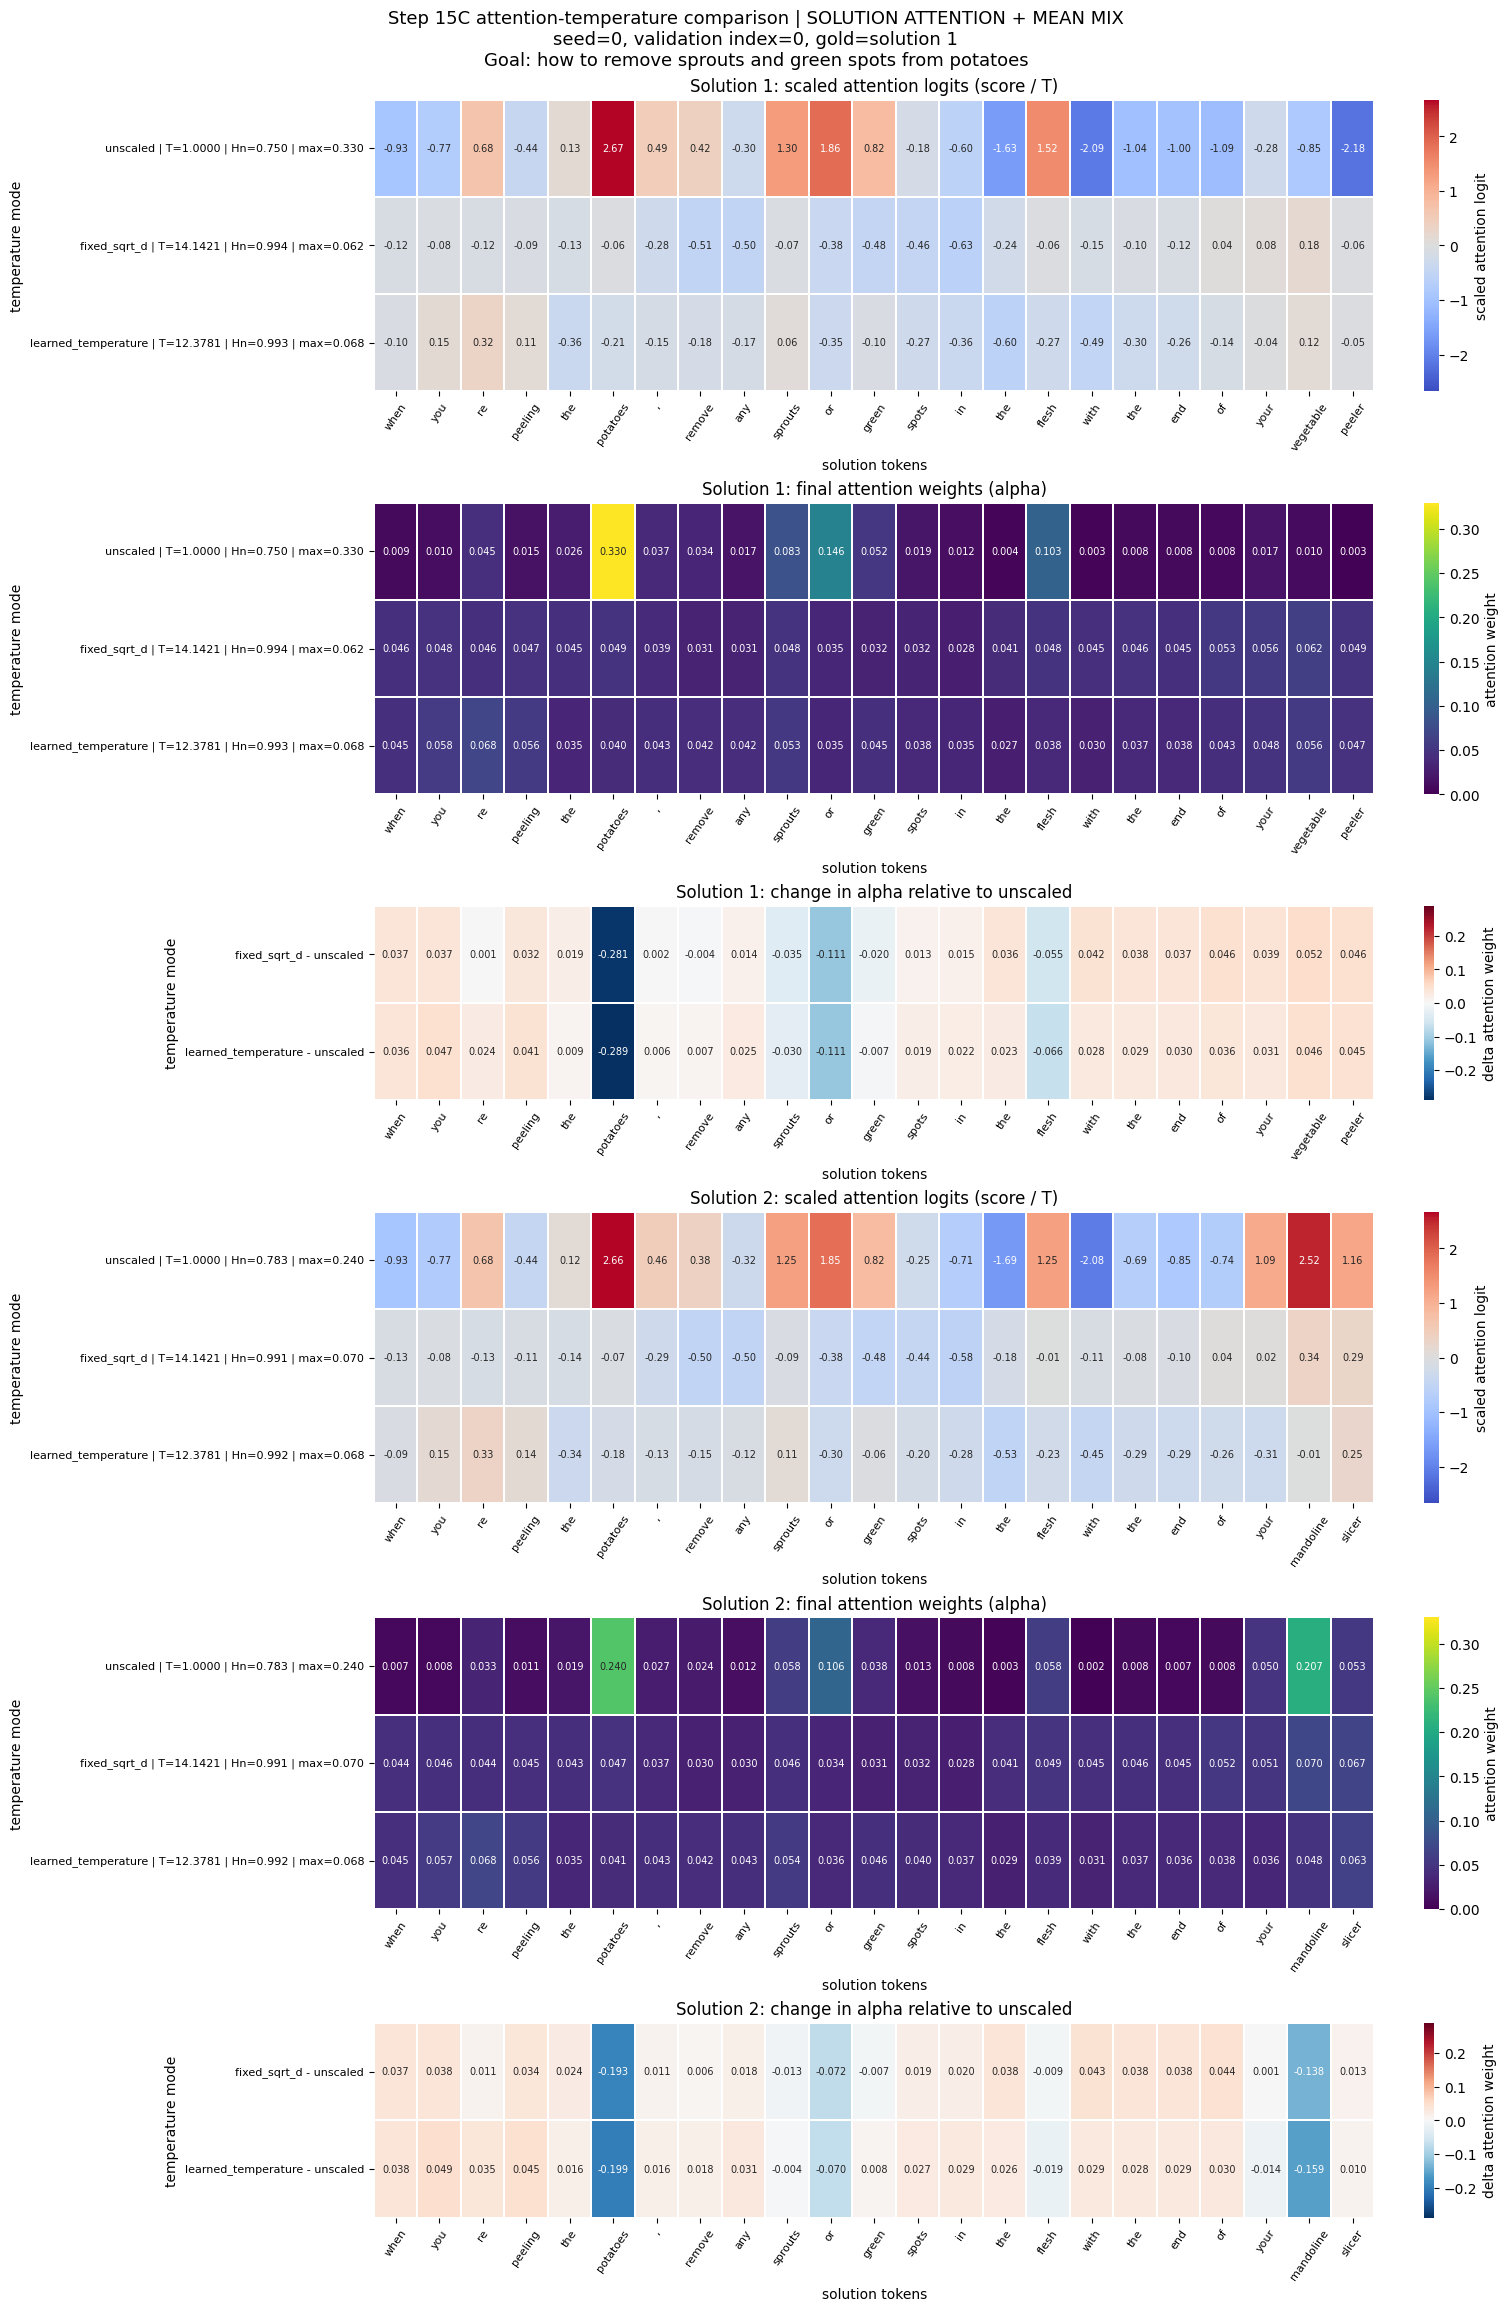

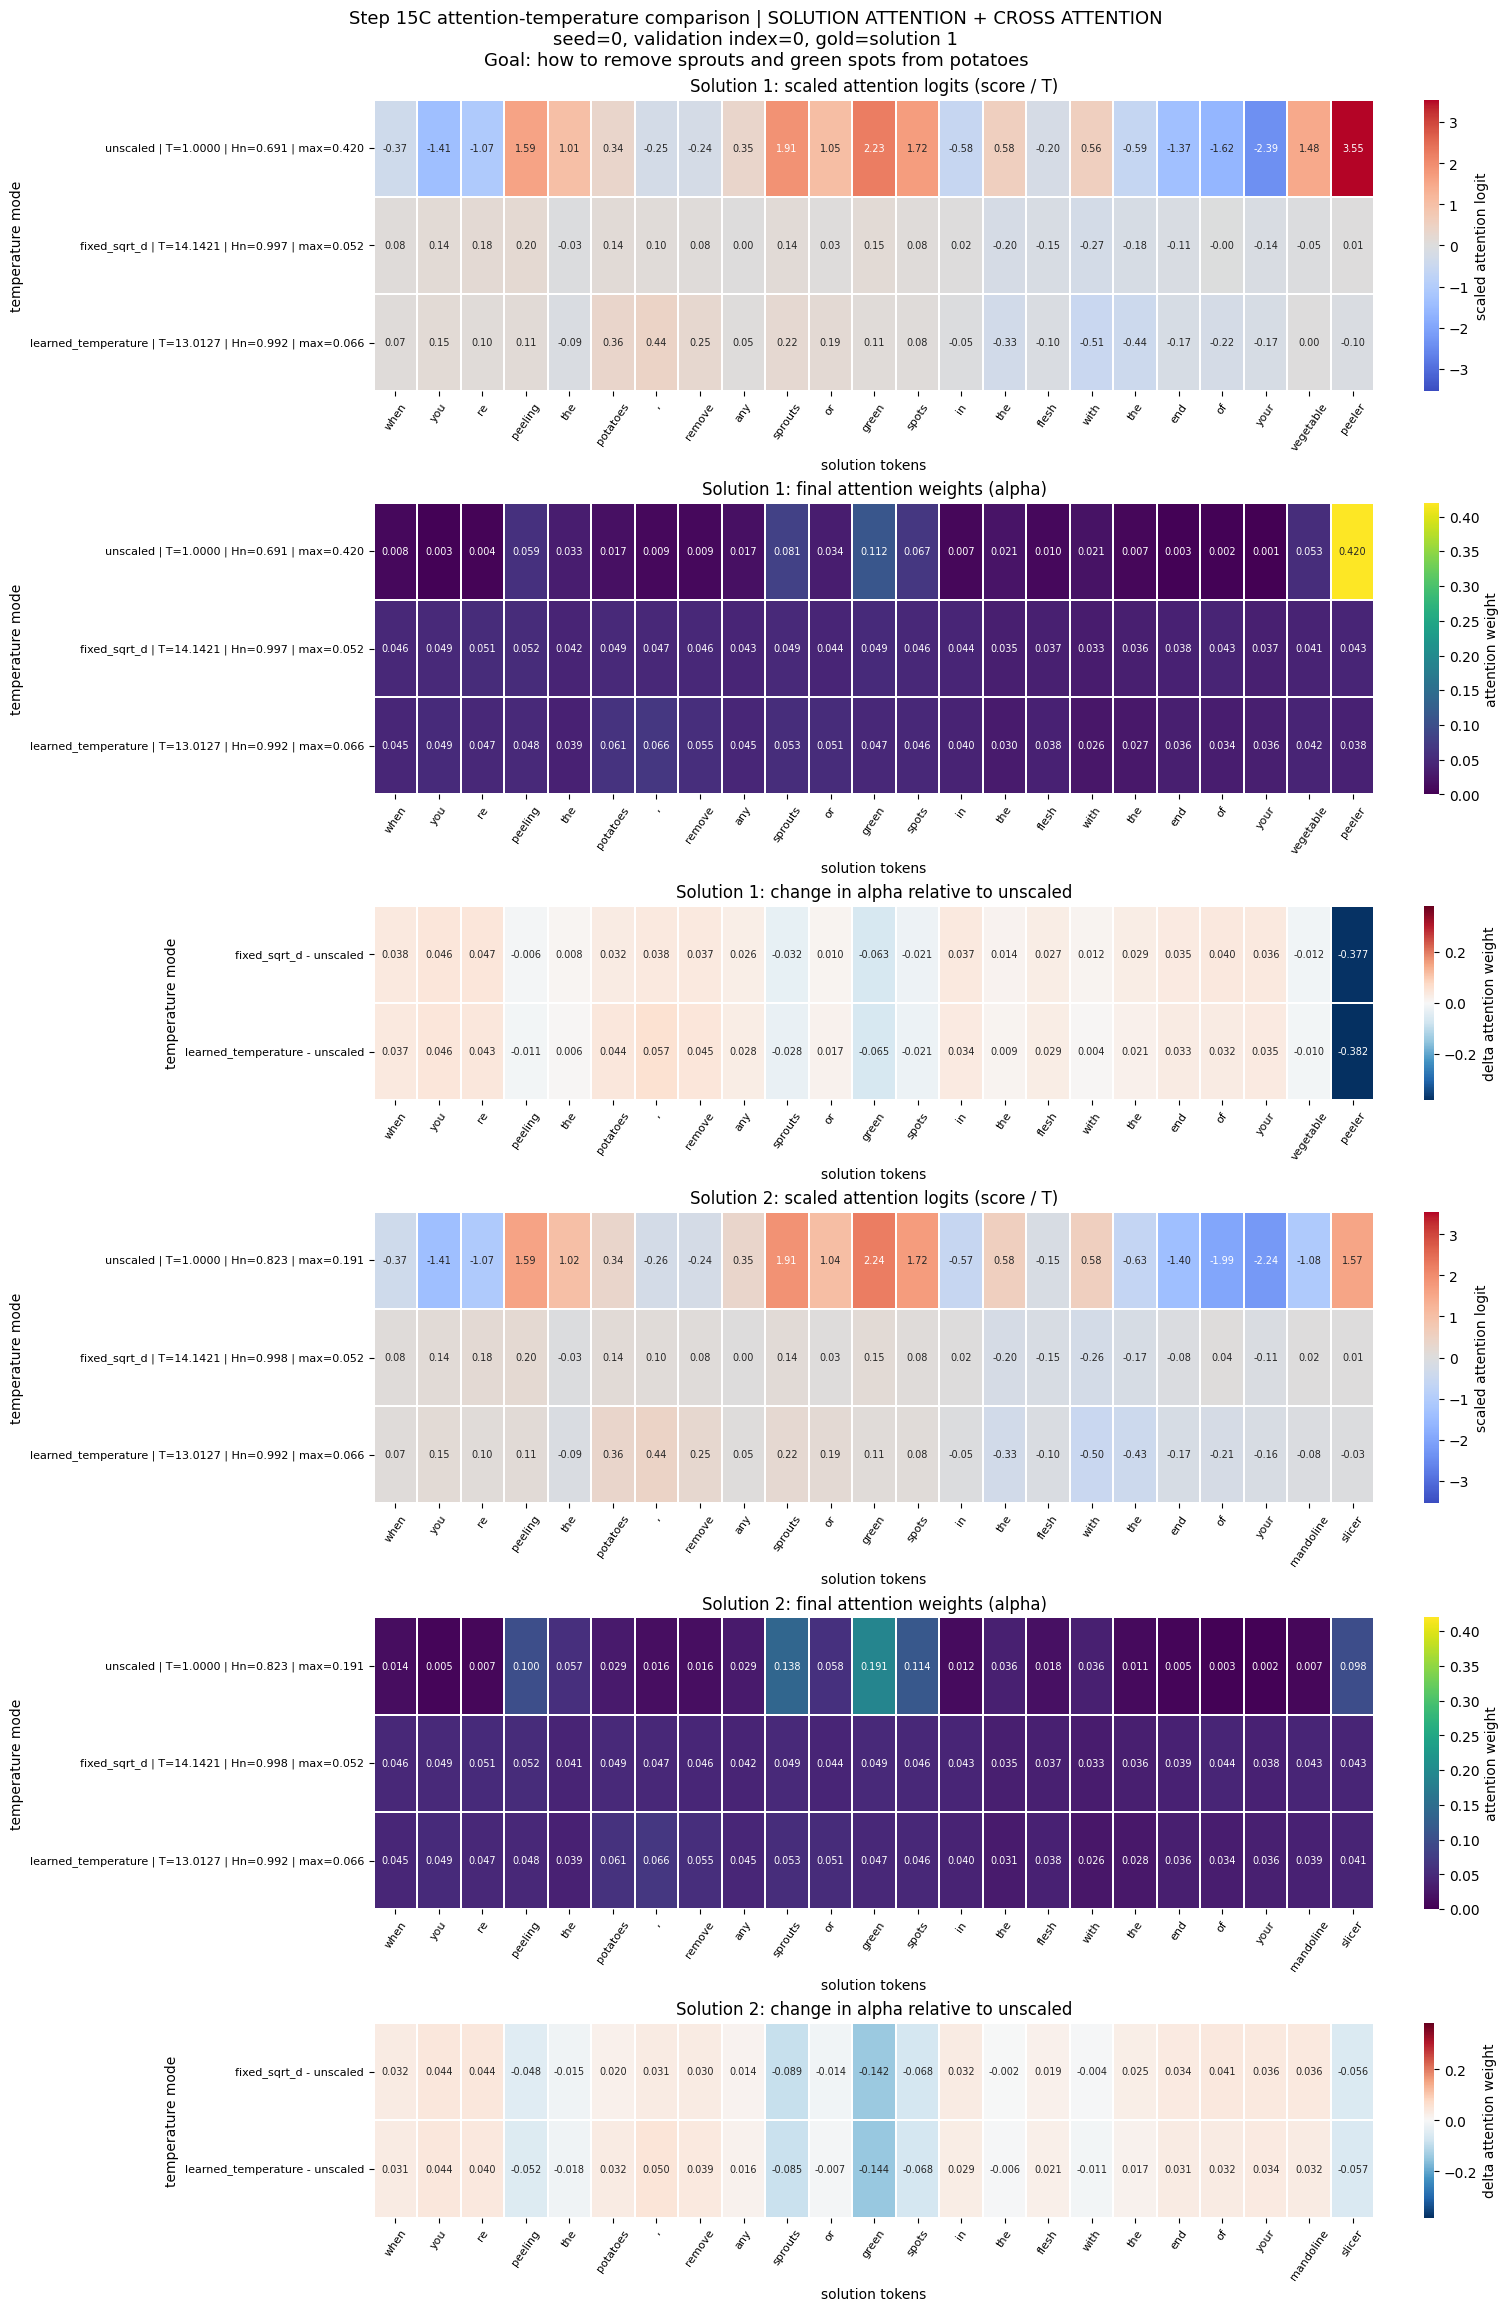

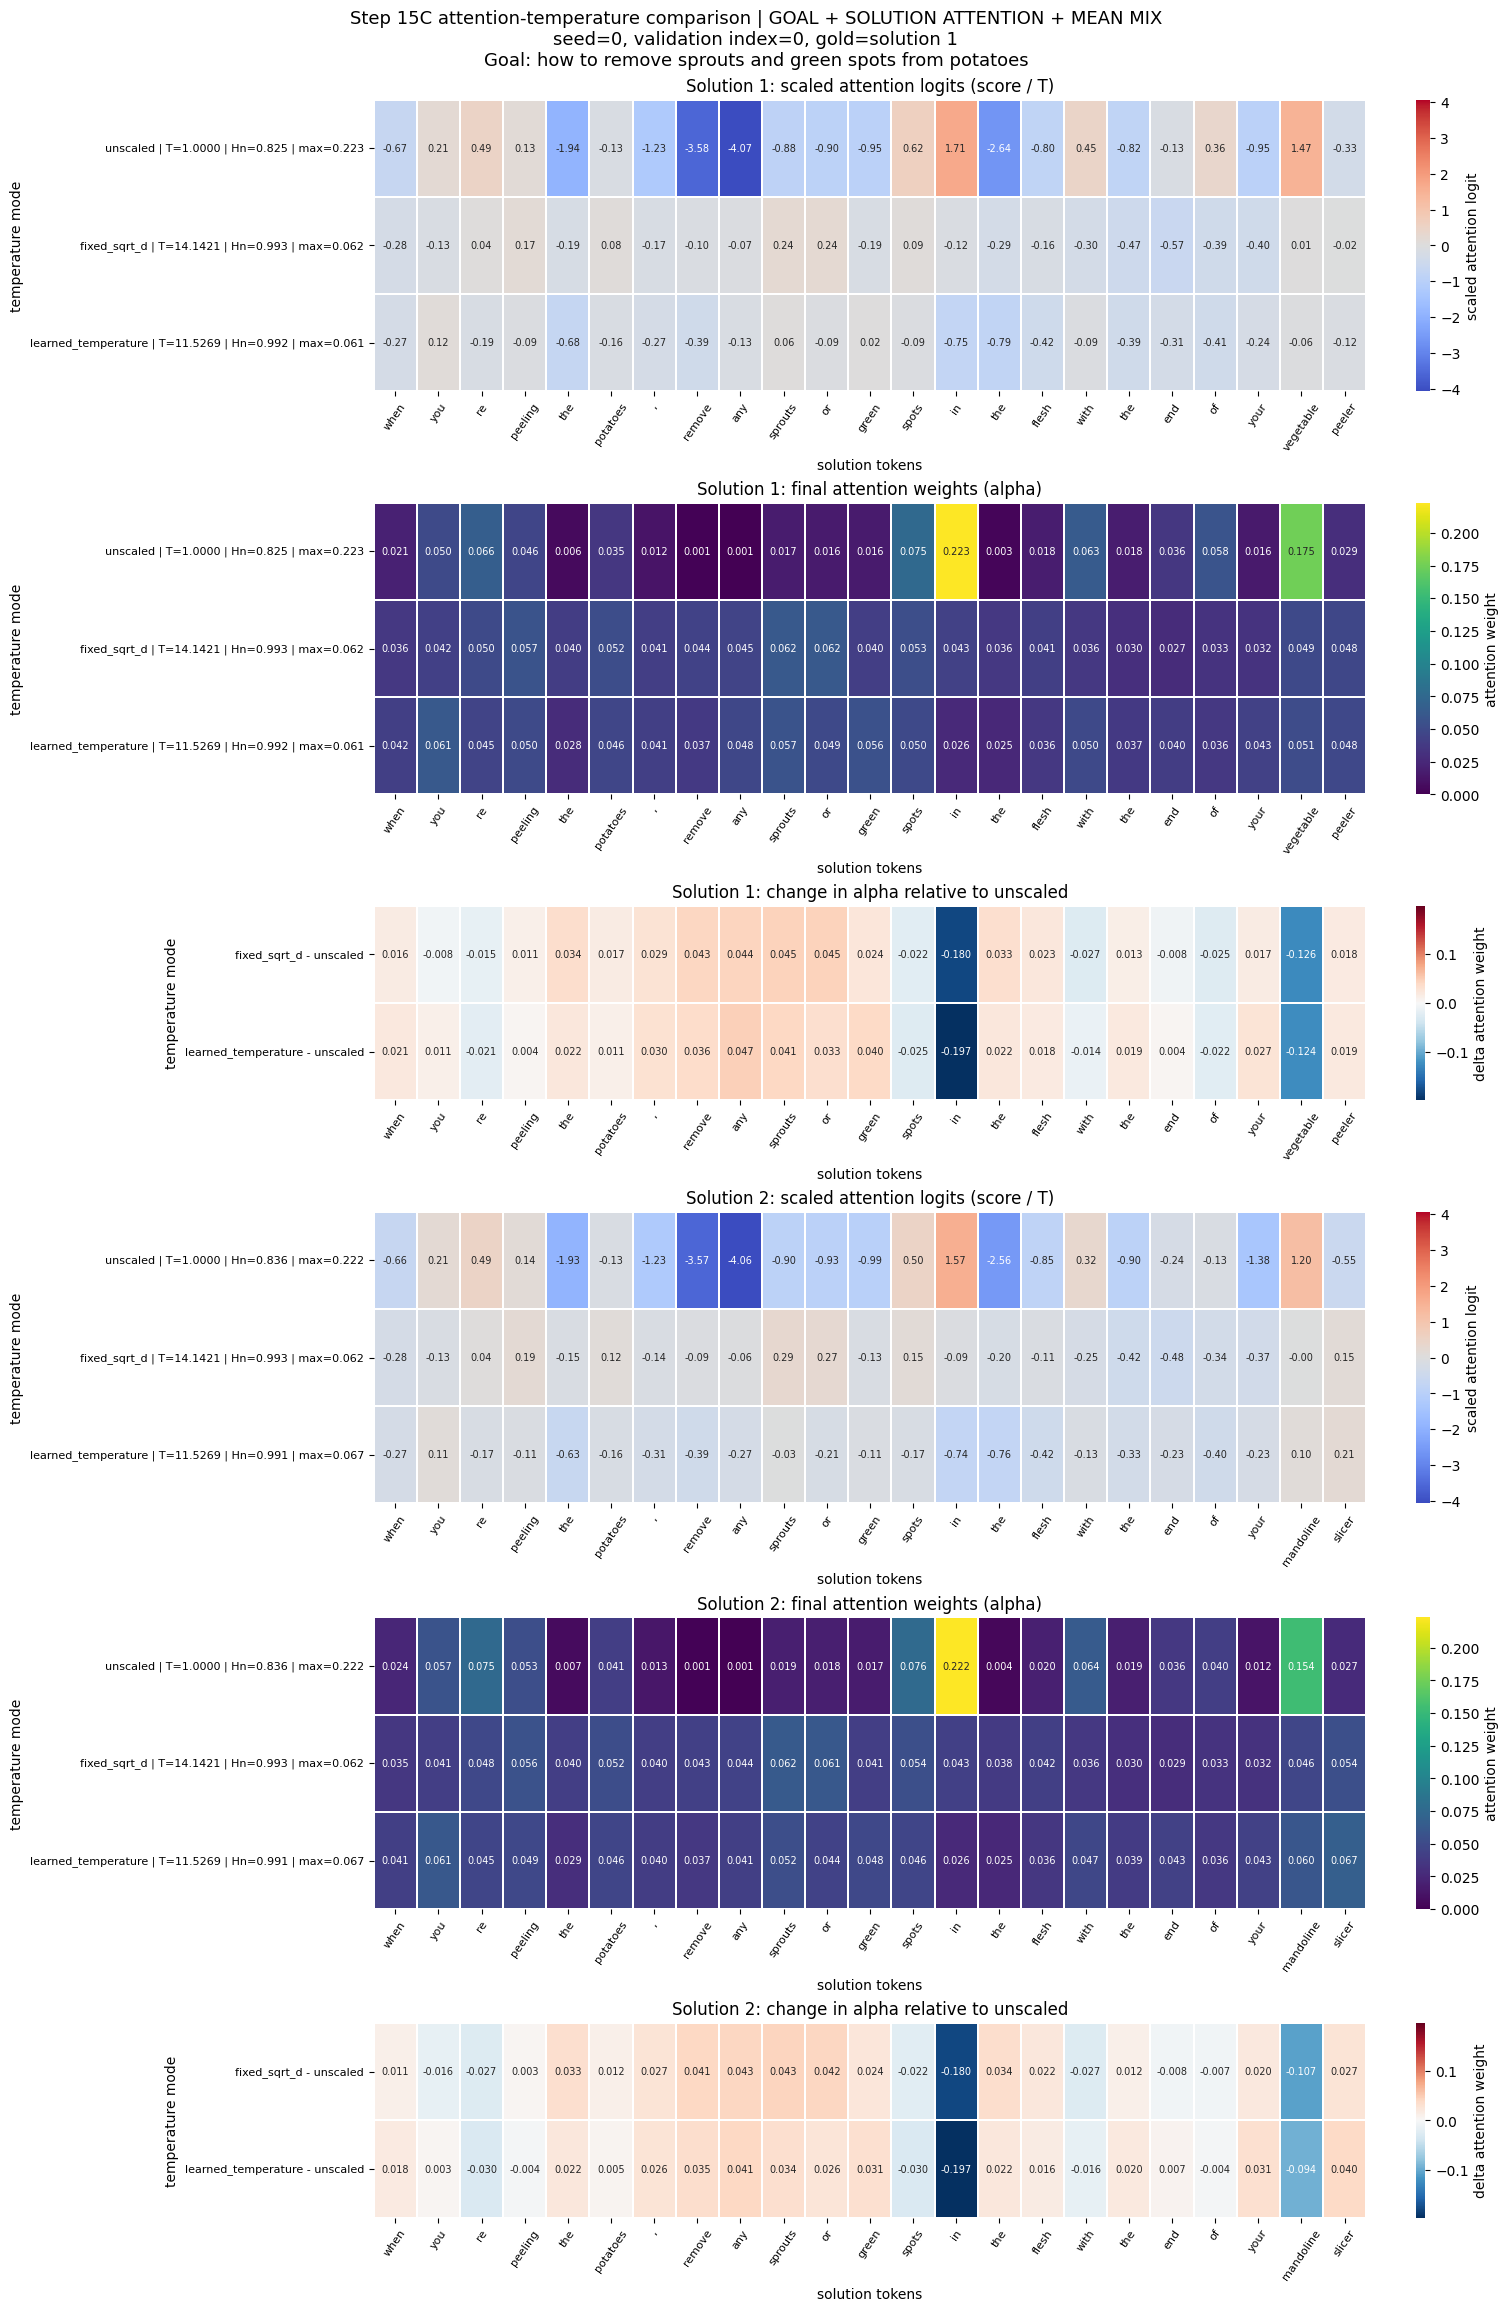

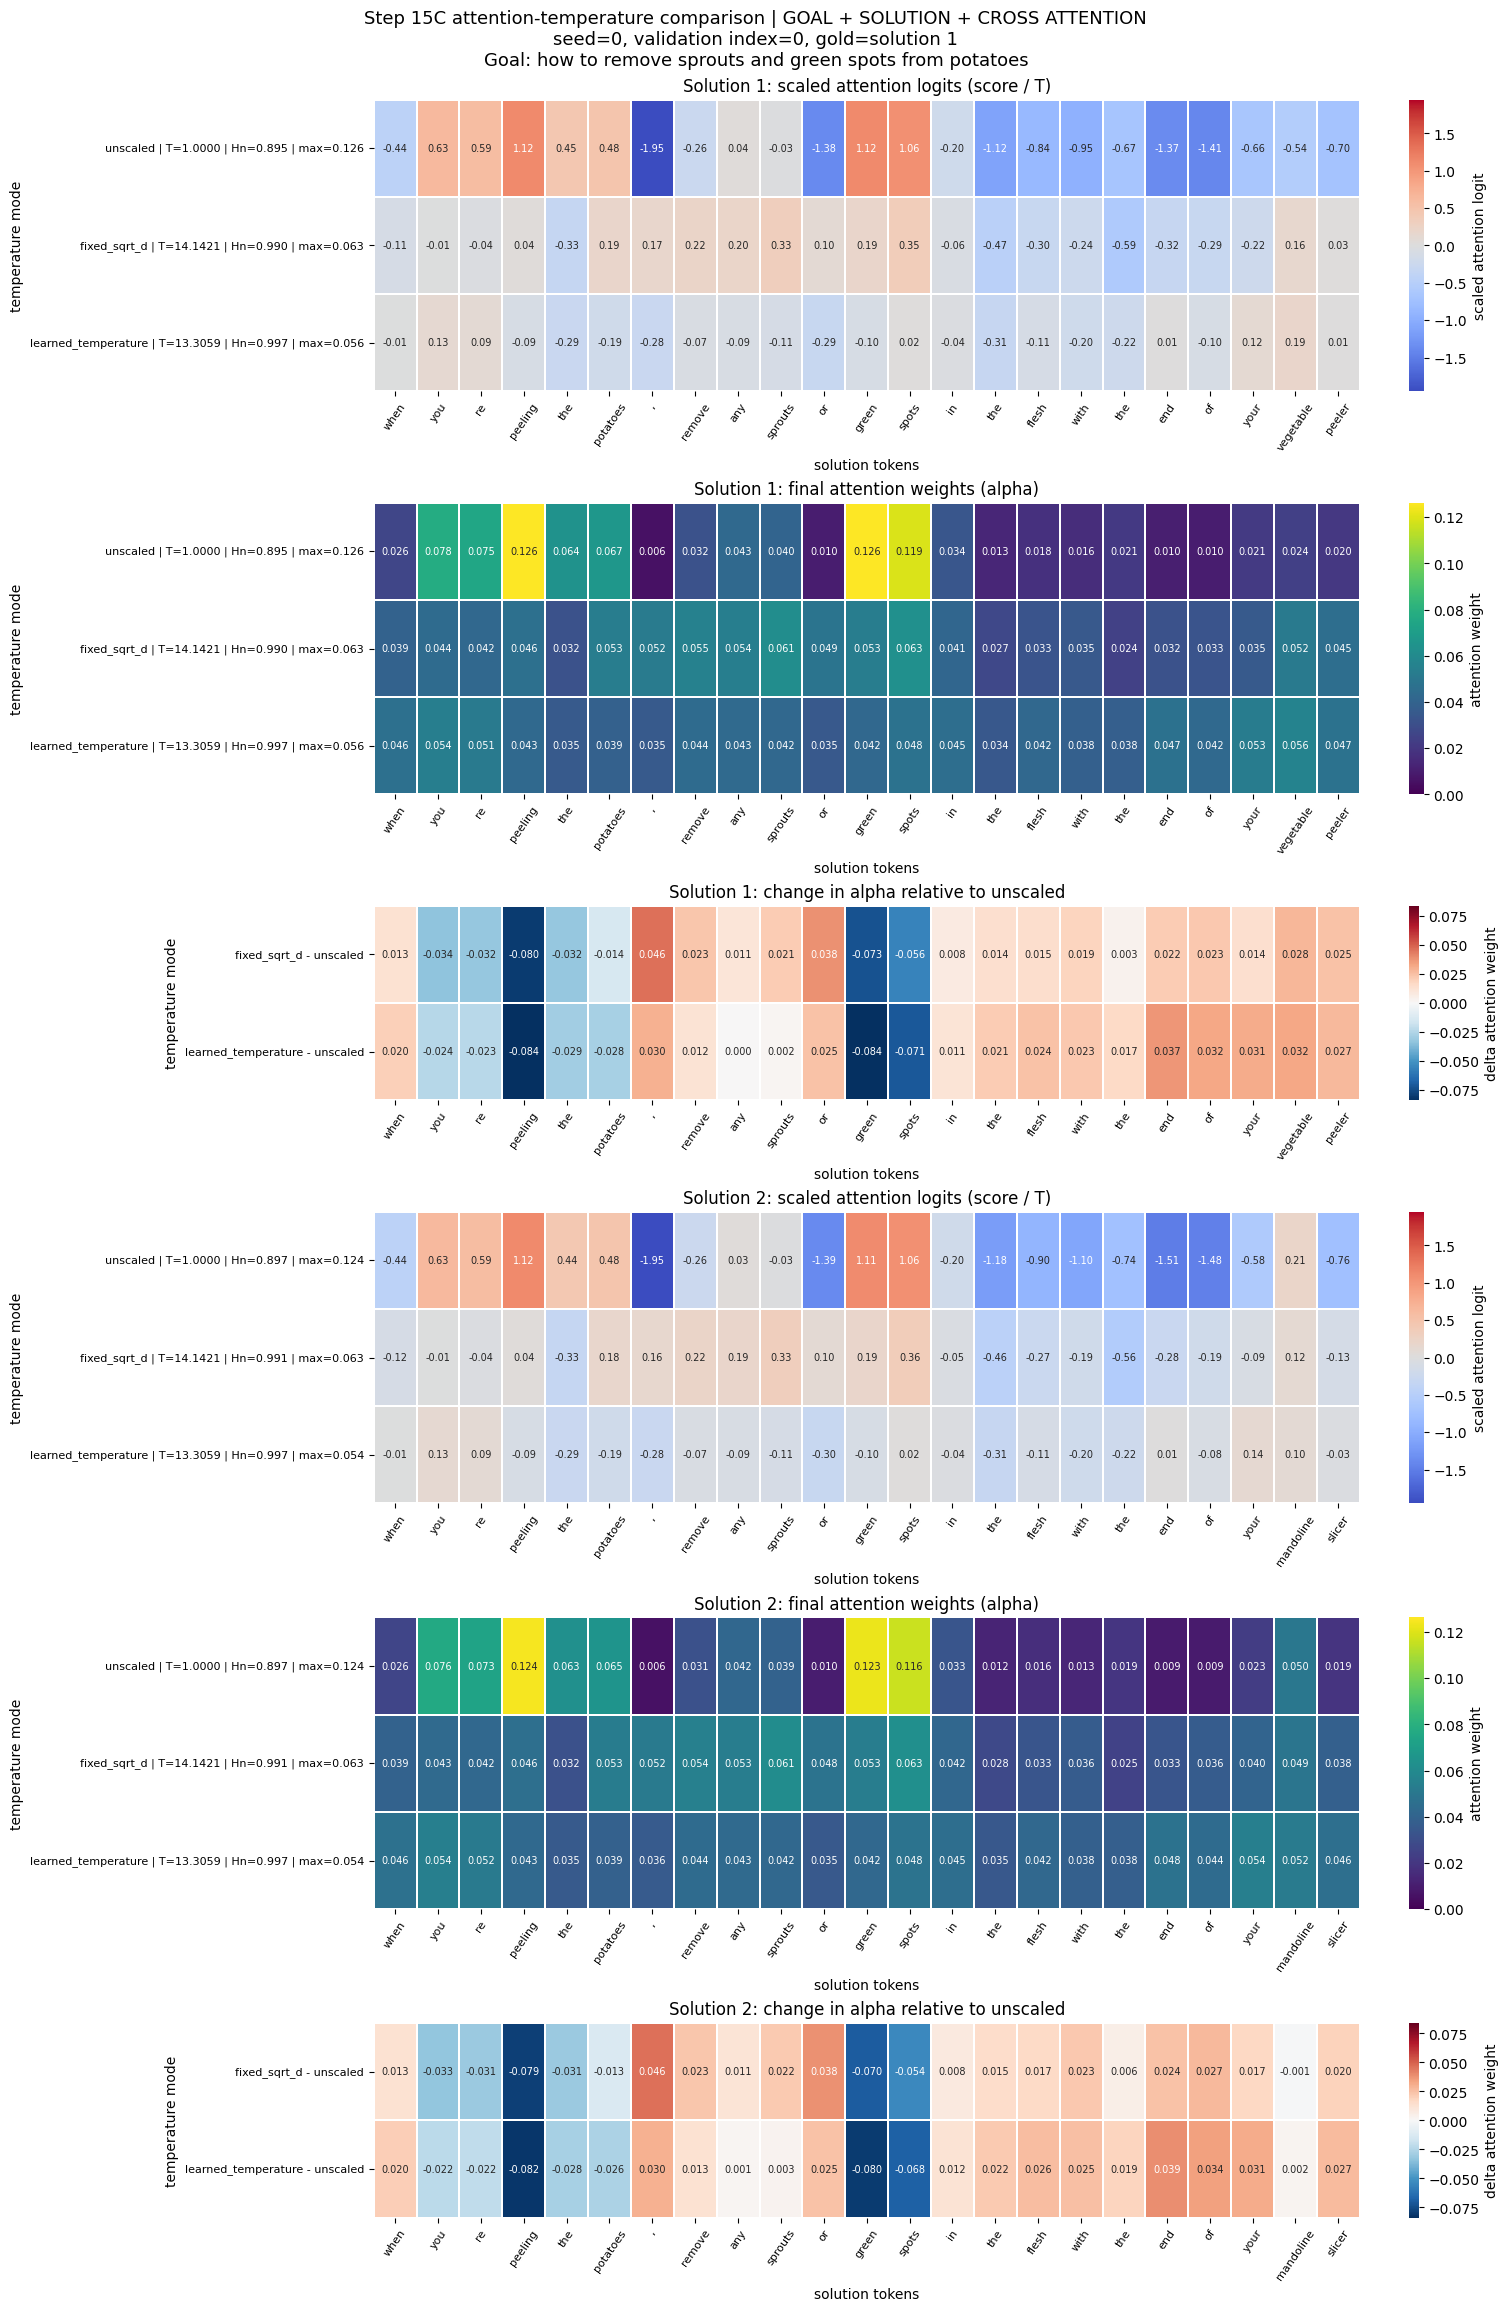

Rendered 4 Step 15C comparison figure(s).


In [6]:
# @title Step 13C.5: Standalone attention-temperature comparison heat maps from Google Drive
# Fresh-runtime cell: restore PIQA, load one complete Step 15C run, and compare A1 attention.

from collections import Counter, defaultdict
from pathlib import Path
import hashlib
import io
import json
import math
import os
import re
import textwrap
import zipfile

import gdown
import google.auth
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from sklearn.model_selection import train_test_split


# Modify these three values to select configurations, seed, and validation sample.
STEP15C_HEATMAP_CONFIGS = [
    "goal_guided_solution_attention_mean_mix",
    "goal_guided_solution_attention_mean_mix_with_cross_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention",
]
STEP15C_HEATMAP_SEED = 0
STEP15C_HEATMAP_SAMPLE_INDEX = 0

STEP15C_ALL_BASE_CONFIGS = (
    "goal_guided_solution_attention_mean_mix",
    "goal_guided_solution_attention_mean_mix_with_cross_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention",
)
STEP15C_TEMPERATURE_MODES = (
    "unscaled",
    "fixed_sqrt_d",
    "learned_temperature",
)
STEP15C_DISPLAY_NAMES = {
    "goal_guided_solution_attention_mean_mix":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention":
        "GOAL + SOLUTION + CROSS ATTENTION",
}

if not isinstance(STEP15C_HEATMAP_CONFIGS, list) or not STEP15C_HEATMAP_CONFIGS:
    raise ValueError("STEP15C_HEATMAP_CONFIGS must be a non-empty list.")
if len(set(STEP15C_HEATMAP_CONFIGS)) != len(STEP15C_HEATMAP_CONFIGS):
    raise ValueError("STEP15C_HEATMAP_CONFIGS must not contain duplicates.")
unknown_step15c_configs = [
    name for name in STEP15C_HEATMAP_CONFIGS
    if name not in STEP15C_ALL_BASE_CONFIGS
]
if unknown_step15c_configs:
    raise ValueError(
        "Unknown Step 15C heat-map configurations: "
        + ", ".join(unknown_step15c_configs)
    )
try:
    STEP15C_HEATMAP_SEED = int(STEP15C_HEATMAP_SEED)
    STEP15C_HEATMAP_SAMPLE_INDEX = int(STEP15C_HEATMAP_SAMPLE_INDEX)
except (TypeError, ValueError) as exc:
    raise ValueError(
        "STEP15C_HEATMAP_SEED and STEP15C_HEATMAP_SAMPLE_INDEX must be integers."
    ) from exc


# ---------------------------------------------------------------------
# 1. Restore the PIQA validation split in a fresh runtime.
# ---------------------------------------------------------------------

PIQA_DATA_FILE_ID = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
PIQA_DATA_DIR = Path("/content/piqa_step15c_heatmap_data")
PIQA_FILENAMES = (
    "train.jsonl",
    "train-labels.lst",
    "test.jsonl",
    "test-labels.lst",
)


def ensure_step15c_piqa_data():
    """Download the public PIQA archive once and return its data paths."""
    PIQA_DATA_DIR.mkdir(parents=True, exist_ok=True)
    located = {
        name: next(iter(PIQA_DATA_DIR.rglob(name)), None)
        for name in PIQA_FILENAMES
    }
    if any(path is None for path in located.values()):
        archive_path = PIQA_DATA_DIR / "piqa_data.zip"
        downloaded_path = gdown.download(
            id=PIQA_DATA_FILE_ID,
            output=str(archive_path),
            quiet=False,
        )
        if downloaded_path is None or not archive_path.is_file():
            raise RuntimeError("PIQA data download failed.")
        try:
            with zipfile.ZipFile(archive_path) as archive:
                archive.extractall(PIQA_DATA_DIR)
        except (OSError, zipfile.BadZipFile) as exc:
            raise RuntimeError("The downloaded PIQA archive is invalid.") from exc
        located = {
            name: next(iter(PIQA_DATA_DIR.rglob(name)), None)
            for name in PIQA_FILENAMES
        }
    missing = [name for name, path in located.items() if path is None]
    if missing:
        raise RuntimeError("PIQA archive is missing: " + ", ".join(missing))
    return located


def step15c_clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?'\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()


def read_step15c_piqa(data_path, label_path):
    with open(data_path, encoding="utf-8") as data_file:
        data_lines = data_file.readlines()
    with open(label_path, encoding="utf-8") as label_file:
        label_lines = label_file.readlines()
    rows = []
    for line, label in zip(data_lines, label_lines):
        if not label.strip():
            continue
        item = json.loads(line)
        rows.append({
            "goal": item["goal"],
            "sol1": item["sol1"],
            "sol2": item["sol2"],
            "label": int(label.strip()),
        })
    return rows


def build_step15c_vocabulary(rows, min_count=2):
    word_count = Counter()
    for item in rows:
        word_count.update(step15c_clean_str(item["goal"]).split())
        word_count.update(step15c_clean_str(item["sol1"]).split())
        word_count.update(step15c_clean_str(item["sol2"]).split())
    result = {"<pad>": 0, "<unk>": 1}
    for word, count in word_count.most_common():
        if count >= min_count:
            result[word] = len(result)
    return result


def step15c_words_to_index(words, vocabulary, maxlength):
    indices = np.zeros(maxlength, dtype=np.int64)
    for index, word in enumerate(words[:maxlength]):
        indices[index] = vocabulary.get(word, 1)
    return indices


def make_step15c_batch_input(rows, vocabulary, maxgoal=20, maxsol=60):
    size = len(rows)
    goal = np.zeros((size, maxgoal), dtype=np.int64)
    sol1 = np.zeros((size, maxsol), dtype=np.int64)
    sol2 = np.zeros((size, maxsol), dtype=np.int64)
    labels = np.zeros(size, dtype=np.int64)
    for index, item in enumerate(rows):
        goal[index] = step15c_words_to_index(
            step15c_clean_str(item["goal"]).split(), vocabulary, maxgoal
        )
        sol1[index] = step15c_words_to_index(
            step15c_clean_str(item["sol1"]).split(), vocabulary, maxsol
        )
        sol2[index] = step15c_words_to_index(
            step15c_clean_str(item["sol2"]).split(), vocabulary, maxsol
        )
        labels[index] = item["label"]
    return goal, sol1, sol2, labels


step15c_piqa_paths = ensure_step15c_piqa_data()
step15c_all_train_rows = read_step15c_piqa(
    step15c_piqa_paths["train.jsonl"],
    step15c_piqa_paths["train-labels.lst"],
)
step15c_all_labels = [item["label"] for item in step15c_all_train_rows]
step15c_train_rows, step15c_validation_rows = train_test_split(
    step15c_all_train_rows,
    test_size=0.15,
    random_state=0,
    stratify=step15c_all_labels,
)
step15c_vocabulary = build_step15c_vocabulary(step15c_train_rows, min_count=2)
step15c_validation_input = make_step15c_batch_input(
    step15c_validation_rows,
    step15c_vocabulary,
)
step15c_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not 0 <= STEP15C_HEATMAP_SAMPLE_INDEX < len(step15c_validation_rows):
    raise IndexError(
        "STEP15C_HEATMAP_SAMPLE_INDEX must be between 0 and "
        f"{len(step15c_validation_rows) - 1}."
    )

step15c_goal_array, step15c_sol1_array, step15c_sol2_array, step15c_label_array = (
    step15c_validation_input
)
step15c_sample_slice = slice(
    STEP15C_HEATMAP_SAMPLE_INDEX,
    STEP15C_HEATMAP_SAMPLE_INDEX + 1,
)
step15c_goal_tensor = torch.as_tensor(
    step15c_goal_array[step15c_sample_slice],
    dtype=torch.long,
    device=step15c_device,
)
step15c_sol1_tensor = torch.as_tensor(
    step15c_sol1_array[step15c_sample_slice],
    dtype=torch.long,
    device=step15c_device,
)
step15c_sol2_tensor = torch.as_tensor(
    step15c_sol2_array[step15c_sample_slice],
    dtype=torch.long,
    device=step15c_device,
)
step15c_sample_row = step15c_validation_rows[STEP15C_HEATMAP_SAMPLE_INDEX]
step15c_gold = int(step15c_label_array[STEP15C_HEATMAP_SAMPLE_INDEX])


# ---------------------------------------------------------------------
# 2. Rebuild the Step 15C model exactly as used during training.
# ---------------------------------------------------------------------

def step15c_masked_pool(rnn_output, index, pooling="mean"):
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        return rnn_output.masked_fill(mask == 0, -1e9).max(dim=1)[0]
    return (rnn_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)


def step15c_attention_on_goal(goal_output, goal_index, query):
    score = torch.matmul(goal_output, query)
    score = score.masked_fill(goal_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), goal_output).squeeze(1)
    return context, alpha


class PIQA_Step15C_Base_Model(nn.Module):
    def __init__(
        self, vocabulary_size, dimension=100, n_hidden_input=100,
        dropout_input=0.25, num_layers_input=1, rnn_type="LSTM",
        pooling="mean", attention_type="none", goal_attention=False,
        use_cross_attention=False, use_interaction=True, use_goal=True,
    ):
        super().__init__()
        self.pooling = pooling
        self.attention_type = attention_type
        self.goal_attention = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction = use_interaction
        self.use_goal = use_goal
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        encoder_class = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.encoder = encoder_class(
            dimension,
            n_hidden_input,
            num_layers=num_layers_input,
            batch_first=True,
            bidirectional=True,
            dropout=dropout_input if num_layers_input > 1 else 0,
        )
        self.W = nn.Linear(n_hidden_input * 2, n_hidden_input * 2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        score_input = n_hidden_input * 2 * (4 if use_interaction else 2)
        if use_cross_attention:
            score_input += n_hidden_input * 2
        self.hidden_layer = nn.Linear(score_input, n_hidden_input)
        self.score_layer = nn.Linear(n_hidden_input, 1)
        self.dropout = nn.Dropout(dropout_input)

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        if self.goal_attention:
            goal_vector, goal_alpha = step15c_attention_on_goal(
                goal_output, goal, self.goal_query
            )
        else:
            goal_vector = step15c_masked_pool(goal_output, goal, self.pooling)
            goal_alpha = None
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        score1, alpha1, align1 = self.score_one_solution(
            goal_vector, sol1_output, solution1, sol2_output, solution2
        )
        score2, alpha2, align2 = self.score_one_solution(
            goal_vector, sol2_output, solution2, sol1_output, solution1
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
        }


class PIQA_Step15C_Temperature_Model(PIQA_Step15C_Base_Model):
    VALID_TEMPERATURE_MODES = set(STEP15C_TEMPERATURE_MODES)

    def __init__(
        self,
        vocabulary_size,
        temperature_mode,
        cross_difference_pooling=None,
        **settings,
    ):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15C requires attention_type='goal'.")
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Step 15C uses masked mean as the mix fallback.")
        if temperature_mode not in self.VALID_TEMPERATURE_MODES:
            raise ValueError(f"Unknown temperature mode: {temperature_mode}")
        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configurations require masked_mean_max pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )
        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_mode = temperature_mode
        self.temperature_epsilon = 1e-6
        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            self.hidden_layer = nn.Linear(
                base_width + hidden_size * 4,
                hidden_size,
            )
        attention_dim = self.W.out_features
        sqrt_d = math.sqrt(attention_dim)
        initial_temperature = 1.0 if temperature_mode == "unscaled" else sqrt_d
        if temperature_mode == "learned_temperature":
            initial_raw = math.log(math.expm1(initial_temperature))
            self.raw_attention_temperature = nn.Parameter(
                torch.tensor(initial_raw, dtype=self.W.weight.dtype)
            )
            self.register_buffer(
                "fixed_attention_temperature",
                torch.tensor(initial_temperature, dtype=self.W.weight.dtype),
            )
        else:
            self.register_parameter("raw_attention_temperature", None)
            self.register_buffer(
                "fixed_attention_temperature",
                torch.tensor(initial_temperature, dtype=self.W.weight.dtype),
            )
        self.goal_mean_mix_logit = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        if self.temperature_mode == "learned_temperature":
            return (
                torch.nn.functional.softplus(self.raw_attention_temperature)
                + self.temperature_epsilon
            )
        return self.fixed_attention_temperature

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def score_one_solution(
        self,
        goal_vector,
        current_sol_output,
        current_sol_index,
        other_sol_output,
        other_sol_index,
    ):
        query = self.W(goal_vector)
        raw_score = torch.bmm(
            current_sol_output, query.unsqueeze(2)
        ).squeeze(2)
        raw_score = raw_score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=raw_score.device,
            dtype=raw_score.dtype,
        )
        alpha = torch.softmax(raw_score / temperature, dim=1)
        attention_context = torch.bmm(
            alpha.unsqueeze(1), current_sol_output
        ).squeeze(1)
        mean_context = step15c_masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        mix = self.goal_attention_lambda
        context = mix * attention_context + (1.0 - mix) * mean_context
        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        align = None
        if self.use_cross_attention:
            similarity = torch.bmm(
                current_sol_output,
                other_sol_output.transpose(1, 2),
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other
            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count
            max_difference = token_difference.masked_fill(
                ~current_mask,
                torch.finfo(token_difference.dtype).min,
            ).max(dim=1).values
            max_difference = torch.where(
                current_mask.any(dim=1),
                max_difference,
                torch.zeros_like(max_difference),
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        solution_score = self.score_layer(hidden).squeeze(1)
        return solution_score, alpha, align


def build_step15c_temperature_model(vocabulary_size, temperature_mode, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15C_Temperature_Model(
        vocabulary_size,
        temperature_mode=temperature_mode,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# ---------------------------------------------------------------------
# 3. Evaluate one checkpoint and independently recover its scaled logits.
# ---------------------------------------------------------------------

def step15c_attention_summary(alpha, token_indices):
    valid_mask = token_indices.ne(0)
    values = alpha[valid_mask]
    if values.numel() == 0:
        raise ValueError("Cannot summarize attention for an empty token sequence.")
    total = values.sum()
    if not torch.isfinite(total) or total.item() <= 0:
        raise ValueError("Attention weights must sum to a positive finite value.")
    values = values / total
    entropy = -(values * values.clamp_min(1e-12).log()).sum()
    normalized_entropy = (
        entropy / math.log(values.numel()) if values.numel() > 1
        else torch.zeros_like(entropy)
    )
    return {
        "normalized_entropy": float(normalized_entropy.detach().cpu()),
        "max_alpha": float(values.max().detach().cpu()),
    }


def evaluate_step15c_attention(
    model,
    goal_tensor,
    sol1_tensor,
    sol2_tensor,
):
    """Return actual scaled logits/alpha and verify alpha against forward()."""
    model.eval()
    with torch.no_grad():
        logits, forward_attention = model(
            goal_tensor,
            sol1_tensor,
            sol2_tensor,
        )
        goal_output, _ = model.encoder(model.embedding(goal_tensor))
        sol1_output, _ = model.encoder(model.embedding(sol1_tensor))
        sol2_output, _ = model.encoder(model.embedding(sol2_tensor))
        if model.goal_attention:
            goal_vector, _ = step15c_attention_on_goal(
                goal_output,
                goal_tensor,
                model.goal_query,
            )
        else:
            goal_vector = step15c_masked_pool(
                goal_output,
                goal_tensor,
                model.pooling,
            )
        if not model.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        query = model.W(goal_vector)
        temperature = model.attention_temperature.to(
            device=query.device,
            dtype=query.dtype,
        )

        solution_results = {}
        for solution_name, solution_output, solution_tensor, attention_key in (
            ("sol1", sol1_output, sol1_tensor, "sol1_alpha"),
            ("sol2", sol2_output, sol2_tensor, "sol2_alpha"),
        ):
            raw_score = torch.bmm(
                solution_output,
                query.unsqueeze(2),
            ).squeeze(2)
            masked_raw_score = raw_score.masked_fill(
                solution_tensor == 0,
                -1e9,
            )
            scaled_score = masked_raw_score / temperature
            recomputed_alpha = torch.softmax(scaled_score, dim=1)
            expected_alpha = forward_attention[attention_key]
            if not torch.allclose(
                recomputed_alpha,
                expected_alpha,
                atol=1e-6,
                rtol=1e-5,
            ):
                max_error = float(
                    (recomputed_alpha - expected_alpha).abs().max().cpu()
                )
                raise RuntimeError(
                    f"Recomputed {attention_key} does not match forward(); "
                    f"max error={max_error:.3e}."
                )
            summary = step15c_attention_summary(
                recomputed_alpha[0],
                solution_tensor[0],
            )
            solution_results[solution_name] = {
                "scaled_score": scaled_score[0].detach().cpu().numpy(),
                "alpha": recomputed_alpha[0].detach().cpu().numpy(),
                **summary,
            }
        probabilities = torch.softmax(logits, dim=1)[0]
        return {
            "temperature": float(temperature.detach().cpu()),
            "goal_attention_lambda": float(
                model.goal_attention_lambda.detach().cpu()
            ),
            "prediction": int(logits.argmax(dim=1).item()),
            "probabilities": probabilities.detach().cpu().numpy(),
            "solutions": solution_results,
        }


# ---------------------------------------------------------------------
# 4. Locate the newest complete, verified Step 15C run in Google Drive.
# ---------------------------------------------------------------------

STEP15C_DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
STEP15C_DOWNLOAD_DIR = Path("/content/step15c_attention_heatmap")
STEP15C_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)


def list_step15c_drive_files(service, folder_id):
    files = []
    page_token = None
    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            spaces="drive",
            fields=(
                "nextPageToken,files("
                "id,name,mimeType,createdTime,modifiedTime,size)"
            ),
            orderBy="createdTime desc",
            pageSize=1000,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        files.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            return files


def download_step15c_drive_bytes(service, file_id):
    buffer = io.BytesIO()
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    downloader = MediaIoBaseDownload(buffer, request)
    complete = False
    while not complete:
        _, complete = downloader.next_chunk()
    return buffer.getvalue()


def download_step15c_drive_file(service, file_id, destination):
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    with destination.open("wb") as output_file:
        downloader = MediaIoBaseDownload(output_file, request)
        complete = False
        while not complete:
            _, complete = downloader.next_chunk()


def step15c_sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as input_file:
        for chunk in iter(lambda: input_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def build_step15c_run_catalog(files, seed, read_json):
    """Group valid Step 15C JSON records by run_id and comparison key."""
    groups = defaultdict(lambda: defaultdict(list))
    rejected = []
    json_files = sorted(
        (
            item for item in files
            if item.get("name", "").startswith("step15c_")
            and item.get("name", "").endswith(".json")
        ),
        key=lambda item: (item.get("createdTime", ""), item.get("name", "")),
        reverse=True,
    )
    for json_file in json_files:
        try:
            raw_json = read_json(json_file["id"])
            if isinstance(raw_json, bytes):
                raw_json = raw_json.decode("utf-8")
            record = json.loads(raw_json)
        except Exception as exc:
            rejected.append(
                f"{json_file.get('name', '<unnamed>')}: invalid JSON ({exc})"
            )
            continue
        try:
            record_seed = int(record.get("seed", -1))
        except (TypeError, ValueError):
            rejected.append(f"{json_file['name']}: invalid seed")
            continue
        if record.get("experiment") != "step15c" or record_seed != seed:
            continue
        run_id = record.get("run_id")
        base_configuration = record.get("base_configuration")
        temperature_mode = record.get("temperature_mode")
        if not isinstance(run_id, str) or not run_id:
            rejected.append(f"{json_file['name']}: missing run_id")
            continue
        if base_configuration not in STEP15C_ALL_BASE_CONFIGS:
            rejected.append(f"{json_file['name']}: unknown base_configuration")
            continue
        if temperature_mode not in STEP15C_TEMPERATURE_MODES:
            rejected.append(f"{json_file['name']}: unknown temperature_mode")
            continue
        expected_configuration = f"{base_configuration}__{temperature_mode}"
        if record.get("configuration") != expected_configuration:
            rejected.append(f"{json_file['name']}: inconsistent configuration")
            continue
        groups[run_id][(base_configuration, temperature_mode)].append(
            (json_file, record)
        )
    return groups, rejected


def select_latest_valid_step15c_run(
    files,
    seed,
    required_keys,
    read_json,
    prepare_record,
):
    """Select one coherent run; reject the whole run if any pair is invalid."""
    groups, rejected = build_step15c_run_catalog(files, seed, read_json)
    checkpoints_by_name = defaultdict(list)
    for item in files:
        if item.get("name", "").endswith(".pt"):
            checkpoints_by_name[item["name"]].append(item)
    for candidates in checkpoints_by_name.values():
        candidates.sort(
            key=lambda item: (
                item.get("createdTime", ""),
                item.get("id", ""),
            ),
            reverse=True,
        )

    def run_sort_key(run_item):
        run_id, records_by_key = run_item
        newest_time = max(
            json_file.get("createdTime", "")
            for candidates in records_by_key.values()
            for json_file, _ in candidates
        )
        return newest_time, run_id

    for run_id, records_by_key in sorted(
        groups.items(),
        key=run_sort_key,
        reverse=True,
    ):
        missing_keys = [key for key in required_keys if key not in records_by_key]
        if missing_keys:
            rejected.append(
                f"run {run_id}: incomplete; missing {len(missing_keys)} JSON record(s)"
            )
            continue
        prepared_run = {}
        run_failure = None
        for key in required_keys:
            candidate_errors = []
            prepared_value = None
            candidate_pairs = sorted(
                records_by_key[key],
                key=lambda item: (
                    item[0].get("createdTime", ""),
                    item[0].get("name", ""),
                ),
                reverse=True,
            )
            for json_file, record in candidate_pairs:
                checkpoint_name = record.get("checkpoint_filename")
                if (
                    not isinstance(checkpoint_name, str)
                    or Path(checkpoint_name).name != checkpoint_name
                ):
                    candidate_errors.append(
                        f"{json_file['name']}: invalid checkpoint filename"
                    )
                    continue
                checkpoint_files = checkpoints_by_name.get(checkpoint_name, [])
                if not checkpoint_files:
                    candidate_errors.append(
                        f"{json_file['name']}: paired .pt is missing"
                    )
                    continue
                for checkpoint_file in checkpoint_files:
                    try:
                        result = prepare_record(
                            checkpoint_file,
                            record,
                        )
                    except Exception as exc:
                        candidate_errors.append(
                            f"{json_file['name']} + {checkpoint_file['name']}: {exc}"
                        )
                        continue
                    prepared_value = {
                        "json_file": json_file,
                        "checkpoint_file": checkpoint_file,
                        "record": record,
                        "result": result,
                    }
                    break
                if prepared_value is not None:
                    break
            if prepared_value is None:
                run_failure = (
                    f"run {run_id}, {key[0]} / {key[1]} has no valid pair: "
                    + " | ".join(candidate_errors[-4:])
                )
                break
            prepared_run[key] = prepared_value
        if run_failure is not None:
            rejected.append(run_failure)
            prepared_run.clear()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            continue
        return run_id, prepared_run, rejected

    if not groups:
        raise RuntimeError(
            f"Google Drive has no Step 15C JSON records for seed={seed}."
        )
    details = "\n".join("- " + item for item in rejected[-16:])
    raise RuntimeError(
        "No complete and valid Step 15C run was found."
        + ("\n" + details if details else "")
    )


def fetch_verified_step15c_checkpoint(service, checkpoint_file, record):
    expected = record.get("checkpoint_sha256")
    if (
        not isinstance(expected, str)
        or re.fullmatch(r"[0-9a-fA-F]{64}", expected) is None
    ):
        raise ValueError("JSON is missing a valid checkpoint_sha256")
    expected = expected.lower()
    safe_name = Path(checkpoint_file["name"]).name
    if safe_name != checkpoint_file["name"]:
        raise ValueError("Drive checkpoint has an unsafe filename")
    destination = STEP15C_DOWNLOAD_DIR / safe_name
    if destination.is_file() and step15c_sha256_file(destination) == expected:
        return destination
    temporary = destination.with_name(
        destination.name + "." + checkpoint_file["id"] + ".part"
    )
    try:
        download_step15c_drive_file(
            service,
            checkpoint_file["id"],
            temporary,
        )
        actual = step15c_sha256_file(temporary)
        if actual != expected:
            raise ValueError(
                f"SHA-256 mismatch: expected {expected}, got {actual}"
            )
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()
    return destination


def prepare_step15c_record(service, checkpoint_file, record):
    settings = record.get("settings")
    if not isinstance(settings, dict):
        raise ValueError("JSON is missing settings")
    temperature_mode = record.get("temperature_mode")
    checkpoint_path = fetch_verified_step15c_checkpoint(
        service,
        checkpoint_file,
        record,
    )
    try:
        model = build_step15c_temperature_model(
            len(step15c_vocabulary),
            temperature_mode,
            settings,
        ).to(step15c_device)
    except Exception as exc:
        raise RuntimeError("Step 15C settings cannot reconstruct the model.") from exc
    try:
        try:
            checkpoint = torch.load(
                checkpoint_path,
                map_location=step15c_device,
                weights_only=True,
            )
        except TypeError:
            checkpoint = torch.load(
                checkpoint_path,
                map_location=step15c_device,
            )
        if not isinstance(checkpoint, dict):
            raise ValueError("Checkpoint payload is not a dictionary.")
        if checkpoint.get("format") != "step15c_configuration_temperature_v2":
            raise ValueError("Checkpoint has an unexpected Step 15C format.")
        state_dict = checkpoint.get("model_state_dict")
        if not isinstance(state_dict, dict):
            raise ValueError("Checkpoint is missing model_state_dict.")
        model.load_state_dict(state_dict)
        result = evaluate_step15c_attention(
            model,
            step15c_goal_tensor,
            step15c_sol1_tensor,
            step15c_sol2_tensor,
        )
    except Exception:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        raise
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    result.update({
        "checkpoint_path": str(checkpoint_path),
        "checkpoint_name": checkpoint_file["name"],
    })
    return result


auth.authenticate_user()
step15c_drive_credentials, _ = google.auth.default()
step15c_drive_service = build(
    "drive",
    "v3",
    credentials=step15c_drive_credentials,
    cache_discovery=False,
)
step15c_drive_folder = step15c_drive_service.files().get(
    fileId=STEP15C_DRIVE_FOLDER_ID,
    fields="id,name,mimeType",
    supportsAllDrives=True,
).execute()
if step15c_drive_folder.get("mimeType") != "application/vnd.google-apps.folder":
    raise RuntimeError("The configured Google Drive target is not a folder.")
step15c_drive_files = list_step15c_drive_files(
    step15c_drive_service,
    STEP15C_DRIVE_FOLDER_ID,
)

# Require all four configurations and all three modes in one run, even if the
# display list is later shortened. This prevents cross-run comparisons.
step15c_required_keys = tuple(
    (base_configuration, temperature_mode)
    for base_configuration in STEP15C_ALL_BASE_CONFIGS
    for temperature_mode in STEP15C_TEMPERATURE_MODES
)
(
    step15c_selected_run_id,
    step15c_prepared_run,
    step15c_rejected_backups,
) = select_latest_valid_step15c_run(
    step15c_drive_files,
    STEP15C_HEATMAP_SEED,
    step15c_required_keys,
    lambda file_id: download_step15c_drive_bytes(
        step15c_drive_service,
        file_id,
    ),
    lambda checkpoint_file, record: prepare_step15c_record(
        step15c_drive_service,
        checkpoint_file,
        record,
    ),
)

for rejected_backup in step15c_rejected_backups:
    print("Skipped Drive backup:", rejected_backup)


# ---------------------------------------------------------------------
# 5. Render one comparison figure per base configuration.
# ---------------------------------------------------------------------

STEP15C_REPORT_FIGURE_TITLE_SIZE = 20
STEP15C_REPORT_SUBPLOT_TITLE_SIZE = 16
STEP15C_REPORT_AXIS_LABEL_SIZE = 14
STEP15C_REPORT_TICK_SIZE = 12
STEP15C_REPORT_ANNOTATION_SIZE = 11
STEP15C_REPORT_COLORBAR_TICK_SIZE = 11


def step15c_visible_tokens(text, index_row):
    token_count = int(np.count_nonzero(index_row))
    return step15c_clean_str(text).split()[:token_count]


def step15c_positive_limit(values, minimum=1e-9):
    finite_values = [
        np.asarray(value, dtype=float)[np.isfinite(value)]
        for value in values
    ]
    finite_values = [value for value in finite_values if value.size]
    if not finite_values:
        return minimum
    return max(minimum, max(float(np.max(np.abs(value))) for value in finite_values))


def draw_step15c_metric_heatmap(
    ax,
    values,
    tokens,
    row_labels,
    title,
    cmap,
    vmin,
    vmax,
    fmt,
    colorbar_label,
    center=None,
):
    sns.heatmap(
        np.asarray(values, dtype=float),
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        center=center,
        xticklabels=tokens,
        yticklabels=row_labels,
        annot=True,
        fmt=fmt,
        annot_kws={"fontsize": STEP15C_REPORT_ANNOTATION_SIZE},
        linewidths=0.4,
        cbar_kws={"label": colorbar_label, "shrink": 0.88, "pad": 0.02},
    )
    ax.set_title(
        title, fontsize=STEP15C_REPORT_SUBPLOT_TITLE_SIZE,
        fontweight="bold", pad=10,
    )
    ax.set_xlabel(
        "solution tokens", fontsize=STEP15C_REPORT_AXIS_LABEL_SIZE, labelpad=8
    )
    ax.set_ylabel(
        "temperature mode", fontsize=STEP15C_REPORT_AXIS_LABEL_SIZE, labelpad=10
    )
    ax.tick_params(
        axis="x", rotation=55, labelsize=STEP15C_REPORT_TICK_SIZE, pad=2
    )
    ax.tick_params(
        axis="y", rotation=0, labelsize=STEP15C_REPORT_TICK_SIZE, pad=4
    )
    for label in ax.get_yticklabels():
        label.set_linespacing(0.9)
    mappable = ax.collections[0] if ax.collections else ax.images[0]
    colorbar = mappable.colorbar
    colorbar.set_label(colorbar_label, fontsize=STEP15C_REPORT_AXIS_LABEL_SIZE)
    colorbar.ax.tick_params(labelsize=STEP15C_REPORT_COLORBAR_TICK_SIZE)


def draw_step15c_configuration_comparison(
    base_configuration,
    prepared_run,
    sol1_tokens,
    sol2_tokens,
    sample_row,
    gold,
    seed,
    sample_index,
):
    mode_results = {
        mode: prepared_run[(base_configuration, mode)]["result"]
        for mode in STEP15C_TEMPERATURE_MODES
    }
    solution_data = {}
    for solution_key, tokens in (("sol1", sol1_tokens), ("sol2", sol2_tokens)):
        scaled_scores = np.stack([
            mode_results[mode]["solutions"][solution_key]["scaled_score"][:len(tokens)]
            for mode in STEP15C_TEMPERATURE_MODES
        ])
        alphas = np.stack([
            mode_results[mode]["solutions"][solution_key]["alpha"][:len(tokens)]
            for mode in STEP15C_TEMPERATURE_MODES
        ])
        if not np.allclose(alphas.sum(axis=1), 1.0, atol=1e-6):
            raise RuntimeError(
                f"{base_configuration}/{solution_key}: attention rows do not sum to 1."
            )
        alpha_deltas = np.stack((
            alphas[1] - alphas[0],
            alphas[2] - alphas[0],
        ))
        mode_display_names = {
            "unscaled": "unscaled",
            "fixed_sqrt_d": "fixed sqrt(d)",
            "learned_temperature": "learned T",
        }
        row_labels = [
            mode_display_names[mode] for mode in STEP15C_TEMPERATURE_MODES
        ]
        solution_data[solution_key] = {
            "tokens": tokens,
            "scaled_scores": scaled_scores,
            "alphas": alphas,
            "alpha_deltas": alpha_deltas,
            "row_labels": row_labels,
        }

    score_limit = step15c_positive_limit([
        solution_data["sol1"]["scaled_scores"],
        solution_data["sol2"]["scaled_scores"],
    ])
    alpha_max = max(
        1e-9,
        float(solution_data["sol1"]["alphas"].max()),
        float(solution_data["sol2"]["alphas"].max()),
    )
    delta_limit = step15c_positive_limit([
        solution_data["sol1"]["alpha_deltas"],
        solution_data["sol2"]["alpha_deltas"],
    ])
    max_token_count = max(len(sol1_tokens), len(sol2_tokens))
    figure_width = max(11.5, min(16.0, 0.50 * max_token_count))
    figure, axes = plt.subplots(
        6,
        1,
        figsize=(figure_width, 16.5),
        dpi=150,
        gridspec_kw={"height_ratios": [3, 3, 2, 3, 3, 2]},
        constrained_layout=True,
    )
    plot_index = 0
    for solution_key, solution_title in (
        ("sol1", "Solution 1"),
        ("sol2", "Solution 2"),
    ):
        data = solution_data[solution_key]
        draw_step15c_metric_heatmap(
            axes[plot_index],
            data["scaled_scores"],
            data["tokens"],
            data["row_labels"],
            f"{solution_title}: scaled attention logits (score / T)",
            "coolwarm",
            -score_limit,
            score_limit,
            ".1f",
            "scaled attention logit",
            center=0.0,
        )
        plot_index += 1
        draw_step15c_metric_heatmap(
            axes[plot_index],
            data["alphas"],
            data["tokens"],
            data["row_labels"],
            f"{solution_title}: final attention weights (alpha)",
            "viridis",
            0.0,
            alpha_max,
            ".2f",
            "attention weight",
        )
        plot_index += 1
        draw_step15c_metric_heatmap(
            axes[plot_index],
            data["alpha_deltas"],
            data["tokens"],
            (
                "fixed sqrt(d)\nminus unscaled",
                "learned T\nminus unscaled",
            ),
            f"{solution_title}: change in alpha relative to unscaled",
            "RdBu_r",
            -delta_limit,
            delta_limit,
            ".2f",
            "delta attention weight",
            center=0.0,
        )
        plot_index += 1

    display_name = STEP15C_DISPLAY_NAMES.get(
        base_configuration,
        base_configuration,
    )
    wrapped_goal = textwrap.fill(sample_row["goal"], width=105)
    figure.suptitle(
        f"Step 15C attention-temperature comparison | {display_name}\n"
        f"seed={seed}, validation index={sample_index}, "
        f"gold=solution {gold + 1}\nGoal: {wrapped_goal}",
        fontsize=STEP15C_REPORT_FIGURE_TITLE_SIZE,
        fontweight="bold",
    )
    plt.show()
    return figure


step15c_sol1_tokens = step15c_visible_tokens(
    step15c_sample_row["sol1"],
    step15c_sol1_array[STEP15C_HEATMAP_SAMPLE_INDEX],
)
step15c_sol2_tokens = step15c_visible_tokens(
    step15c_sample_row["sol2"],
    step15c_sol2_array[STEP15C_HEATMAP_SAMPLE_INDEX],
)
if not step15c_sol1_tokens or not step15c_sol2_tokens:
    raise RuntimeError("The selected sample has an empty tokenized solution.")

print(f"Drive folder : {step15c_drive_folder.get('name')}")
print(f"Step 15C run : {step15c_selected_run_id}")
print(f"Seed         : {STEP15C_HEATMAP_SEED}")
print(f"Sample       : validation row {STEP15C_HEATMAP_SAMPLE_INDEX}")
print(f"Goal         : {step15c_sample_row['goal']}")
print(f"Solution 1   : {step15c_sample_row['sol1']}")
print(f"Solution 2   : {step15c_sample_row['sol2']}")
print(f"Gold         : solution {step15c_gold + 1}")
print(
    "Interpretation note: the three rows come from independently trained "
    "checkpoints, so differences include both temperature and learned-weight effects."
)

step15c_comparison_figures = []
for step15c_base_configuration in STEP15C_HEATMAP_CONFIGS:
    step15c_comparison_figures.append(
        draw_step15c_configuration_comparison(
            step15c_base_configuration,
            step15c_prepared_run,
            step15c_sol1_tokens,
            step15c_sol2_tokens,
            step15c_sample_row,
            step15c_gold,
            STEP15C_HEATMAP_SEED,
            STEP15C_HEATMAP_SAMPLE_INDEX,
        )
    )

print(
    f"Rendered {len(step15c_comparison_figures)} Step 15C comparison figure(s)."
)


In [14]:
# @title Step 13D.1: Configurations, model, and smoke checks
# Run after data preparation, Steps 6-8, base_settings, and Step 13A.
# Step 13D is independent of Steps 13B/13C and uses local output only.

import datetime
import inspect
import math
import os
import platform
import time
import uuid

_step15d_required = [
    "PIQA_Model", "masked_pool", "train_model", "set_seed",
    "vocabulary", "device", "np", "torch", "train_part1_input",
    "train_part2_input", "base_settings", "STEP15_SEEDS", "STEP15_EPOCHS",
    "STEP15_LEARNING_RATE", "STEP15_BATCH_SIZE", "STEP15_OUTPUT_ROOT",
]
_step15d_missing = [name for name in _step15d_required if name not in globals()]
if _step15d_missing:
    raise RuntimeError(
        "Run the data preparation, Steps 6-8, base_settings, and Step 15A cells first. Missing: "
        + ", ".join(_step15d_missing)
    )

assert tuple(STEP15_SEEDS) == (0, 1, 2), "Step 15D uses seeds 0, 1, and 2."
assert STEP15_EPOCHS == 15, "Step 15D uses 15 epochs."

_step15d_defaults = {
    name: parameter.default
    for name, parameter in inspect.signature(PIQA_Model.__init__).parameters.items()
    if name not in ("self", "vocabulary_size")
    and parameter.default is not inspect.Parameter.empty
}
_step15d_switch_matrix = [
    ("goal_guided_solution_attention_mean_mix_learned_temperature", False, False),
    ("goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature", False, True),
    ("goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature", True, False),
    ("goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature", True, True),
]
STEP15D_CONFIGS = []
for _name, _goal_attention, _cross_attention in _step15d_switch_matrix:
    _settings = dict(_step15d_defaults)
    _settings.update(base_settings)
    _settings.update({
        "attention_type": "goal",
        "goal_attention": _goal_attention,
        "use_cross_attention": _cross_attention,
        "pooling": "mean",
        "use_goal": True,
    })
    if _cross_attention:
        _settings["cross_difference_pooling"] = "masked_mean_max"
    STEP15D_CONFIGS.append((_name, _settings))

_step15d_expected_switches = {
    "goal_guided_solution_attention_mean_mix_learned_temperature": ("goal", False, False),
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature": ("goal", False, True),
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature": ("goal", True, False),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature": ("goal", True, True),
}
_step15d_actual_switches = {
    _name: (
        _settings["attention_type"],
        _settings["goal_attention"],
        _settings["use_cross_attention"],
    )
    for _name, _settings in STEP15D_CONFIGS
}
assert _step15d_actual_switches == _step15d_expected_switches
assert len(STEP15D_CONFIGS) == 4
assert len(STEP15D_CONFIGS) * len(STEP15_SEEDS) == 12
assert all(
    _settings.get("cross_difference_pooling") == (
        "masked_mean_max" if _settings["use_cross_attention"] else None
    )
    for _, _settings in STEP15D_CONFIGS
)


class PIQA_Step15D_LearnedTemperature_Model(PIQA_Model):
    """Step 15B mean-mix model with learned temperature on A1 solution attention."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15D requires attention_type='goal'.")
        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configs must use masked_mean_max difference pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Step 15D uses masked mean as the mix fallback.")

        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_epsilon = 1e-6

        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            # Cross-attention retains Step 15B's concatenated masked mean and max.
            self.hidden_layer = torch.nn.Linear(
                base_width + hidden_size * 4, hidden_size
            )

        attention_dim = self.W.out_features
        initial_temperature = math.sqrt(attention_dim)
        initial_raw = math.log(math.expm1(initial_temperature))
        self.raw_attention_temperature = torch.nn.Parameter(
            torch.tensor(initial_raw, dtype=self.W.weight.dtype)
        )

        # sigmoid(0) = 0.5. One scalar is shared by both solution branches.
        self.goal_mean_mix_logit = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        return (
            torch.nn.functional.softplus(self.raw_attention_temperature)
            + self.temperature_epsilon
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, goal_attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * goal_attention_context + (1.0 - mix) * mean_context

    def score_one_solution(
        self, goal_vector, current_sol_output, current_sol_index,
        other_sol_output, other_sol_index
    ):
        # A1 only: learned positive T is shared by solution 1 and solution 2.
        query = self.W(goal_vector)
        score = torch.bmm(
            current_sol_output, query.unsqueeze(2)
        ).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        goal_attention_context = torch.bmm(
            alpha.unsqueeze(1), current_sol_output
        ).squeeze(1)

        mean_context = masked_pool(
            current_sol_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(
            goal_attention_context, mean_context
        )

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            # A3 remains the Step 15B unscaled cross-attention alignment.
            similarity = torch.bmm(
                current_sol_output, other_sol_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_sol_output)
            token_difference = current_sol_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count

            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens, max_difference, torch.zeros_like(max_difference)
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align


def _build_step15d_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15D_LearnedTemperature_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# Run all smoke checks before creating the output directory or starting training.
assert len(vocabulary) > 10, "The vocabulary is too small to construct the Step 15D smoke-test input."
set_seed(0)
_step15d_goal_probe = torch.tensor([[1, 2, 3, 0], [4, 5, 6, 7]], device=device)
_step15d_sol1_probe = torch.tensor([[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device)
_step15d_sol2_probe = torch.tensor([[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device)
_step15d_label_probe = torch.tensor([0, 1], dtype=torch.long, device=device)
_step15d_hidden = int(base_settings.get("n_hidden_input", 100))
_step15d_attention_dim = 2 * _step15d_hidden
_step15d_sqrt_d = math.sqrt(_step15d_attention_dim)
_step15d_base_width = _step15d_attention_dim * (
    4 if base_settings.get("use_interaction", True) else 2
)

_step15d_mask_probe = torch.randn(
    2, 5, _step15d_attention_dim, device=device
)
_step15d_mask_index = torch.tensor(
    [[1, 2, 0, 0, 0], [3, 4, 5, 0, 0]], device=device
)
_step15d_masked_mean = masked_pool(
    _step15d_mask_probe, _step15d_mask_index, pooling="mean"
)
_step15d_changed_padding = _step15d_mask_probe.clone()
_step15d_changed_padding[_step15d_mask_index == 0] = 10000.0
assert torch.allclose(
    _step15d_masked_mean,
    masked_pool(_step15d_changed_padding, _step15d_mask_index, pooling="mean"),
    atol=1e-6,
), "Masked mean pooling changed when only padding vectors changed."

for _config_name, _settings in STEP15D_CONFIGS:
    set_seed(0)
    _probe_model = _build_step15d_model(
        len(vocabulary), _settings
    ).to(device)
    assert _probe_model.W.out_features == _step15d_attention_dim
    _expected_width = _step15d_base_width + (
        _step15d_hidden * 4 if _settings["use_cross_attention"] else 0
    )
    assert _probe_model.hidden_layer.in_features == _expected_width, (
        f"Bad score feature width: {_config_name}"
    )
    _initial_temperature = _probe_model.attention_temperature.detach()
    assert torch.allclose(
        _initial_temperature,
        torch.tensor(
            _step15d_sqrt_d,
            dtype=_initial_temperature.dtype,
            device=device,
        ),
        atol=1e-5,
    ), f"Temperature must start at sqrt(d) in {_config_name}."
    assert float(_initial_temperature.cpu()) > 0
    _initial_lambda = _probe_model.goal_attention_lambda.detach()
    assert torch.allclose(
        _initial_lambda,
        torch.tensor(0.5, dtype=_initial_lambda.dtype, device=device),
        atol=1e-7,
    ), f"Lambda must start at 0.5 in {_config_name}."

    _probe_model.eval()
    with torch.no_grad():
        _probe_logits, _probe_attention = _probe_model(
            _step15d_goal_probe, _step15d_sol1_probe, _step15d_sol2_probe
        )
    assert _probe_logits.shape == (2, 2)
    for _alpha_key, _indices in (
        ("sol1_alpha", _step15d_sol1_probe),
        ("sol2_alpha", _step15d_sol2_probe),
    ):
        _weights = _probe_attention[_alpha_key]
        assert torch.all(_weights[_indices == 0] == 0), (
            f"Padding received solution attention in {_config_name}/{_alpha_key}."
        )
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        ), f"Solution attention weights do not sum to one in {_config_name}."
    if _settings["goal_attention"]:
        _goal_weights = _probe_attention["goal_alpha"]
        assert torch.all(_goal_weights[_step15d_goal_probe == 0] == 0), (
            f"Padding received goal attention in {_config_name}."
        )
        assert torch.allclose(
            _goal_weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        )
    if _settings["use_cross_attention"]:
        assert _probe_attention["sol1_align"] is not None
        assert _probe_attention["sol1_align"].shape == (2, 5, 5)
        assert _probe_model.cross_difference_pooling == "masked_mean_max"
        assert _probe_model.hidden_layer.in_features == (
            _step15d_base_width + _step15d_hidden * 4
        )
    else:
        assert _probe_attention["sol1_align"] is None

    _probe_model.zero_grad(set_to_none=True)
    # cuDNN RNN backward requires the differentiable forward pass in training mode.
    _probe_model.train()
    _probe_logits, _ = _probe_model(
        _step15d_goal_probe, _step15d_sol1_probe, _step15d_sol2_probe
    )
    torch.nn.functional.cross_entropy(
        _probe_logits, _step15d_label_probe
    ).backward()
    _temperature_grad = _probe_model.raw_attention_temperature.grad
    _lambda_grad = _probe_model.goal_mean_mix_logit.grad
    assert _temperature_grad is not None and torch.isfinite(_temperature_grad).all()
    assert _temperature_grad.abs().item() > 0, (
        f"Temperature receives no training gradient in {_config_name}."
    )
    assert _lambda_grad is not None and torch.isfinite(_lambda_grad).all()
    assert _lambda_grad.abs().item() > 0, (
        f"Lambda receives no training gradient in {_config_name}."
    )
    assert float(_probe_model.attention_temperature.detach().cpu()) > 0
    del _probe_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(
    "Step 15D smoke checks passed: four A2/A3 combinations, score dimensions, "
    "padding masks, lambda/temperature initialization and gradients, and "
    "cross mean+max difference pooling."
)



Step 15D smoke checks passed: four A2/A3 combinations, score dimensions, padding masks, lambda/temperature initialization and gradients, and cross mean+max difference pooling.


In [18]:
# @title Step 13D.2: Diagnostics and local checkpoint setup

import hashlib
import json

if "_upload_attention_backup" not in globals():
    raise RuntimeError("Run Steps 13.1–13.2 in the current runtime first to enable Drive backups.")

STEP15D_MIX_FORMULA = (
    "lambda * goal_attention_context + (1 - lambda) * masked_mean_context"
)
STEP15D_TEMPERATURE_FORMULA = (
    "softmax(dot(solution_word_vector, W(goal_vector)) / T), "
    "T = softplus(raw_temperature) + epsilon"
)
_step15d_training_settings = {
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "epochs": STEP15_EPOCHS,
    "quiet": True,
}
_step15d_attention_dim = 2 * int(base_settings.get("n_hidden_input", 100))
_step15d_initial_temperature = math.sqrt(_step15d_attention_dim)


def _save_step15d_backup(checkpoint_path, checkpoint_payload, settings, row):
    """Save one local checkpoint/JSON pair, then back it up to Drive."""
    torch.save(checkpoint_payload, checkpoint_path)
    checkpoint_name = os.path.basename(checkpoint_path)
    json_path = os.path.splitext(checkpoint_path)[0] + ".json"
    json_name = os.path.basename(json_path)
    with open(checkpoint_path, "rb") as checkpoint_file:
        checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()
    record = {
        "experiment": "step15d",
        "run_id": _step15d_run_id,
        **checkpoint_payload.get("experiment_metadata", {}),
        **row,
        "settings": dict(settings),
        "training_parameters": dict(_step15d_training_settings),
        "checkpoint_filename": checkpoint_name,
        "checkpoint_sha256": checkpoint_sha256,
        "created_at_utc": datetime.datetime.now(
            datetime.timezone.utc
        ).isoformat(),
    }
    with open(json_path + ".tmp", "w", encoding="utf-8") as json_file:
        json.dump(record, json_file, indent=2, ensure_ascii=False)
    os.replace(json_path + ".tmp", json_path)
    print(f"  local backup saved: {checkpoint_path}; {json_path}")
    checkpoint_drive_file = _upload_attention_backup(
        checkpoint_path, checkpoint_name
    )
    json_drive_file = (
        _upload_attention_backup(json_path, json_name)
        if checkpoint_drive_file is not None else None
    )
    backup_info = {
        "checkpoint_sha256": checkpoint_sha256,
        "json_filename": json_name,
        "drive_checkpoint_file_id": (
            checkpoint_drive_file.get("id") if checkpoint_drive_file else None
        ),
        "drive_json_file_id": (
            json_drive_file.get("id") if json_drive_file else None
        ),
    }
    if checkpoint_drive_file is not None and json_drive_file is not None:
        print(
            f"  Drive backup saved: {checkpoint_drive_file['name']} "
            f"({checkpoint_drive_file['id']}); {json_drive_file['name']} "
            f"({json_drive_file['id']})"
        )
    else:
        print("  Drive backup incomplete; local Step 15D .pt and JSON were retained.")
    return backup_info


def _step15d_attention_stats(alpha, token_indices):
    """Average entropy and peak attention, excluding padding token index 0."""
    alpha = np.asarray(alpha, dtype=np.float64)
    token_mask = np.asarray(token_indices) != 0
    if alpha.shape != token_mask.shape:
        raise ValueError(
            f"Attention/index shape mismatch: {alpha.shape} != {token_mask.shape}"
        )
    entropies = []
    normalized_entropies = []
    max_weights = []
    for _weights, _valid in zip(alpha, token_mask):
        _valid_weights = _weights[_valid]
        if len(_valid_weights) == 0:
            continue
        _total = _valid_weights.sum()
        if not np.isfinite(_total) or _total <= 0:
            raise ValueError("Attention weights must sum to a positive finite value.")
        _valid_weights = _valid_weights / _total
        _entropy = -float(np.sum(
            _valid_weights * np.log(np.clip(_valid_weights, 1e-12, 1.0))
        ))
        _normalized_entropy = (
            _entropy / math.log(len(_valid_weights))
            if len(_valid_weights) > 1 else 0.0
        )
        entropies.append(_entropy)
        normalized_entropies.append(_normalized_entropy)
        max_weights.append(float(np.max(_valid_weights)))
    if not entropies:
        raise ValueError("No non-padding attention sequences were available.")
    return {
        "mean_entropy": float(np.mean(entropies)),
        "mean_normalized_entropy": float(np.mean(normalized_entropies)),
        "mean_max_attention_weight": float(np.mean(max_weights)),
        "sequence_count": int(len(entropies)),
    }


def _step15d_collect_attention_stats(model, validation_input):
    """Collect A1 solution attention and optional A2 goal attention on validation."""
    model.eval()
    goal, sol1, sol2, labels = validation_input
    _sol1_weights = []
    _sol2_weights = []
    _goal_weights = []
    _batch_size = 128
    with torch.no_grad():
        for _start in range(0, len(labels), _batch_size):
            _stop = _start + _batch_size
            _batch_goal = torch.from_numpy(goal[_start:_stop]).to(device)
            _batch_sol1 = torch.from_numpy(sol1[_start:_stop]).to(device)
            _batch_sol2 = torch.from_numpy(sol2[_start:_stop]).to(device)
            _, _attention = model(_batch_goal, _batch_sol1, _batch_sol2)
            _sol1_weights.append(_attention["sol1_alpha"].cpu().numpy())
            _sol2_weights.append(_attention["sol2_alpha"].cpu().numpy())
            if _attention["goal_alpha"] is not None:
                _goal_weights.append(_attention["goal_alpha"].cpu().numpy())

    _sol1_alpha = np.concatenate(_sol1_weights, axis=0)
    _sol2_alpha = np.concatenate(_sol2_weights, axis=0)
    _stats = {
        "sol1": _step15d_attention_stats(_sol1_alpha, sol1),
        "sol2": _step15d_attention_stats(_sol2_alpha, sol2),
        "both_solutions": _step15d_attention_stats(
            np.concatenate((_sol1_alpha, _sol2_alpha), axis=0),
            np.concatenate((sol1, sol2), axis=0),
        ),
        "goal": None,
    }
    if _goal_weights:
        _goal_alpha = np.concatenate(_goal_weights, axis=0)
        _stats["goal"] = _step15d_attention_stats(_goal_alpha, goal)
    return _stats


def load_step15d_checkpoint(path, model, map_location=None):
    """Load a metadata-wrapped Step 15D checkpoint into a constructed model."""
    _checkpoint = torch.load(path, map_location=map_location)
    if not isinstance(_checkpoint, dict) or "model_state_dict" not in _checkpoint:
        raise ValueError("Not a metadata-wrapped Step 15D checkpoint.")
    model.load_state_dict(_checkpoint["model_state_dict"])
    return _checkpoint.get("experiment_metadata", {})


_step15d_seed_rows = []
_step15d_summary_rows = []

_step15d_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15d_output_dir = os.path.abspath(os.path.join(
    STEP15_OUTPUT_ROOT, "step15d_learned_temperature_" + _step15d_run_id
))
os.makedirs(_step15d_output_dir, exist_ok=False)
step15d_output_dir = _step15d_output_dir
_step15d_manifest = {
    "run_id": _step15d_run_id,
    "experiment": "Step 15D: learned goal-conditioned solution-attention temperature for the Step 15B A2/A3 matrix",
    "output_directory": _step15d_output_dir,
    "attention": {
        "type": "goal-conditioned attention over solution words (A1)",
        "score_formula": STEP15D_TEMPERATURE_FORMULA,
        "dimension": _step15d_attention_dim,
        "initial_temperature": _step15d_initial_temperature,
        "temperature_scope": "one learned positive scalar per model, shared by both solution branches",
        "temperature_parameterization": "softplus(raw_temperature) + epsilon",
        "temperature_applies_to": "A1 solution attention only",
        "A2": "goal-side attention unchanged from PIQA_Model",
        "A3": "unscaled cross-attention alignment unchanged from Step 15B",
        "padding": "masked before softmax; diagnostic statistics exclude token index 0",
    },
    "context_mix": {
        "formula": STEP15D_MIX_FORMULA,
        "lambda_scope": "one learned scalar per model, shared by both solutions",
        "lambda_initial": 0.5,
        "lambda_parameterization": "sigmoid(logit), logit initialized to 0",
    },
    "cross_difference_pooling": (
        "concatenate masked mean and masked max when cross-attention is enabled"
    ),
    "seeds": list(STEP15_SEEDS),
    "training": _step15d_training_settings,
    "configurations": {
        _name: {
            "model_class": "PIQA_Step15D_LearnedTemperature_Model",
            "attention_type": _settings["attention_type"],
            "goal_attention": _settings["goal_attention"],
            "use_cross_attention": _settings["use_cross_attention"],
            "cross_difference_pooling": _settings.get("cross_difference_pooling"),
            "attention_mix": STEP15D_MIX_FORMULA,
            "temperature_mode": "learned_temperature",
            "initial_temperature": _step15d_initial_temperature,
            "settings": {
                _key: _value
                for _key, _value in _settings.items()
                if _key != "cross_difference_pooling"
            },
        }
        for _name, _settings in STEP15D_CONFIGS
    },
    "data": {
        "training_examples": len(train_part1_input[3]),
        "validation_examples": len(train_part2_input[3]),
        "input_order": ["goal", "sol1", "sol2", "label"],
        "training_shapes": [list(np.shape(part)) for part in train_part1_input],
        "validation_shapes": [list(np.shape(part)) for part in train_part2_input],
    },
    "runtime": {
        "device": str(device),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
    },
    "planned_runs": len(STEP15D_CONFIGS) * len(STEP15_SEEDS),
    "checkpoint_format": "dict with model_state_dict and experiment_metadata",
    "attention_diagnostic_guide": (
        "normalized entropy near 0 indicates concentrated weights; near 1 indicates diffuse weights; "
        "max attention weight near 1 indicates a dominant token"
    ),
    "results": [],
}
assert _step15d_manifest["planned_runs"] == 12




In [19]:
# @title [RUN] Step 13D.3: Train all configuration-seed combinations

_step15d_started = time.perf_counter()
for _config_name, _settings in STEP15D_CONFIGS:
    for _seed in STEP15_SEEDS:
        set_seed(_seed)
        _model = _build_step15d_model(len(vocabulary), _settings).to(device)
        _checkpoint_path = os.path.join(
            _step15d_output_dir,
            f"step15d_{_step15d_run_id}_{_config_name}_seed{_seed}.pt",
        )
        _train_started = time.perf_counter()
        _model, _best_accuracy = train_model(
            _model,
            train_part1_input,
            train_part2_input,
            learning_rate=STEP15_LEARNING_RATE,
            batch_size=STEP15_BATCH_SIZE,
            epochs=STEP15_EPOCHS,
            model_name=_checkpoint_path,
            quiet=True,
        )
        _training_seconds = time.perf_counter() - _train_started

        # train_model reloads the best validation-accuracy epoch before returning.
        _attention_stats = _step15d_collect_attention_stats(
            _model, train_part2_input
        )
        _learned_temperature = float(
            _model.attention_temperature.detach().cpu().item()
        )
        _learned_lambda = float(
            _model.goal_attention_lambda.detach().cpu().item()
        )
        _attention_scale = 1.0 / _learned_temperature
        _both_stats = _attention_stats["both_solutions"]
        _goal_stats = _attention_stats["goal"]
        _row = {
            "configuration": _config_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "training_seconds": float(_training_seconds),
            "attention_type": "goal",
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "attention_dim": int(_step15d_attention_dim),
            "temperature_parameterization": "softplus(raw_temperature) + epsilon",
            "initial_temperature": float(_step15d_initial_temperature),
            "learned_temperature": _learned_temperature,
            "attention_scale": _attention_scale,
            "goal_attention_lambda": _learned_lambda,
            "sol1_mean_entropy": _attention_stats["sol1"]["mean_entropy"],
            "sol1_mean_normalized_entropy": _attention_stats["sol1"]["mean_normalized_entropy"],
            "sol1_mean_max_attention_weight": _attention_stats["sol1"]["mean_max_attention_weight"],
            "sol2_mean_entropy": _attention_stats["sol2"]["mean_entropy"],
            "sol2_mean_normalized_entropy": _attention_stats["sol2"]["mean_normalized_entropy"],
            "sol2_mean_max_attention_weight": _attention_stats["sol2"]["mean_max_attention_weight"],
            "mean_entropy": _both_stats["mean_entropy"],
            "mean_normalized_entropy": _both_stats["mean_normalized_entropy"],
            "mean_max_attention_weight": _both_stats["mean_max_attention_weight"],
            "goal_mean_entropy": (
                _goal_stats["mean_entropy"] if _goal_stats is not None else None
            ),
            "goal_mean_normalized_entropy": (
                _goal_stats["mean_normalized_entropy"]
                if _goal_stats is not None else None
            ),
            "goal_mean_max_attention_weight": (
                _goal_stats["mean_max_attention_weight"]
                if _goal_stats is not None else None
            ),
            "checkpoint": _checkpoint_path,
        }
        _step15d_seed_rows.append(_row)

        _checkpoint_payload = {
            "format": "step15d_goal_attention_learned_temperature_v1",
            "model_state_dict": _model.state_dict(),
            "experiment_metadata": {
                **_row,
                "checkpoint": os.path.basename(_checkpoint_path),
                "attention_statistics": _attention_stats,
                "mix_formula": STEP15D_MIX_FORMULA,
                "temperature_formula": STEP15D_TEMPERATURE_FORMULA,
                "temperature_scope": (
                    "one learned scalar shared by both solution branches"
                ),
                "temperature_applies_to": "A1 solution attention only",
                "cross_difference_pooling": _settings.get(
                    "cross_difference_pooling"
                ),
                "training": _step15d_training_settings,
            },
        }
        _backup_info = _save_step15d_backup(
            _checkpoint_path, _checkpoint_payload, _settings, _row
        )
        _step15d_manifest["results"].append({
            **_row,
            "checkpoint": os.path.basename(_checkpoint_path),
            "attention_statistics": _attention_stats,
            **_backup_info,
        })

        print(
            f"{_config_name:88s} seed={_seed} "
            f"accuracy={_best_accuracy:.4f} train={_training_seconds:.1f}s "
            f"T={_learned_temperature:.4f} lambda={_learned_lambda:.4f} "
            f"H_norm={_both_stats['mean_normalized_entropy']:.4f} "
            f"max_alpha={_both_stats['mean_max_attention_weight']:.4f}"
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

assert len(_step15d_seed_rows) == 12, (
    f"Expected 12 seed results, found {len(_step15d_seed_rows)}."
)
_step15d_overall_seconds = time.perf_counter() - _step15d_started



  local backup saved: /content/step15_outputs/step15d_learned_temperature_20261015T034133Z_895bbe01/step15d_20261015T034133Z_895bbe01_goal_guided_solution_attention_mean_mix_learned_temperature_seed0.pt; /content/step15_outputs/step15d_learned_temperature_20261015T034133Z_895bbe01/step15d_20261015T034133Z_895bbe01_goal_guided_solution_attention_mean_mix_learned_temperature_seed0.json
  Drive backup saved: step15d_20261015T034133Z_895bbe01_goal_guided_solution_attention_mean_mix_learned_temperature_seed0.pt (1kEMXJfElnz3dwi_qGlFxngxEVJeoUxEY); step15d_20261015T034133Z_895bbe01_goal_guided_solution_attention_mean_mix_learned_temperature_seed0.json (1-2sO1md_Sk7G4g4eTIFPgNcGuzL4_TM-)
goal_guided_solution_attention_mean_mix_learned_temperature                              seed=0 accuracy=0.5983 train=83.8s T=12.3781 lambda=0.8327 H_norm=0.9818 max_alpha=0.1496
  local backup saved: /content/step15_outputs/step15d_learned_temperature_20261015T034133Z_895bbe01/step15d_20261015T034133Z_895bbe

In [20]:
# @title Step 13D.4: Summary and comparison

from IPython.display import display, Markdown
import numpy as np

for _config_name, _ in STEP15D_CONFIGS:
    _rows = [
        _row for _row in _step15d_seed_rows
        if _row["configuration"] == _config_name
    ]
    _rows.sort(key=lambda _row: int(_row["seed"]))
    assert len(_rows) == len(STEP15_SEEDS)
    for _metric_name, _stat_fn in (("mean", np.mean), ("std_population", np.std)):
        _summary = {
            "configuration": _config_name,
            "metric": _metric_name,
        }
        for _field in (
            "best_validation_accuracy", "training_seconds",
            "initial_temperature", "learned_temperature", "attention_scale",
            "goal_attention_lambda", "sol1_mean_entropy",
            "sol1_mean_normalized_entropy", "sol1_mean_max_attention_weight",
            "sol2_mean_entropy", "sol2_mean_normalized_entropy",
            "sol2_mean_max_attention_weight", "mean_entropy",
            "mean_normalized_entropy", "mean_max_attention_weight",
        ):
            _summary[_field] = float(_stat_fn([_row[_field] for _row in _rows]))
        for _field in (
            "goal_mean_entropy", "goal_mean_normalized_entropy",
            "goal_mean_max_attention_weight",
        ):
            _values = [_row[_field] for _row in _rows if _row[_field] is not None]
            _summary[_field] = (
                float(_stat_fn(_values)) if _values else None
            )
        _step15d_summary_rows.append(_summary)

_step15d_manifest["results_summary"] = _step15d_summary_rows
_step15d_manifest["overall_elapsed_seconds"] = float(_step15d_overall_seconds)

display_names = {
    "goal_guided_solution_attention_mean_mix_learned_temperature":
        "SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature":
        "SOLUTION ATTENTION + CROSS ATTENTION",
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature":
        "GOAL + SOLUTION ATTENTION + MEAN MIX",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature":
        "GOAL + SOLUTION + CROSS ATTENTION",
}

table_rows = []
for _config_name, _ in STEP15D_CONFIGS:
    _rows = [
        _row for _row in _step15d_seed_rows
        if _row["configuration"] == _config_name
    ]
    _rows.sort(key=lambda _row: int(_row["seed"]))

    _accuracies = [float(_row["best_validation_accuracy"]) for _row in _rows]
    _seed_scores = ", ".join(f"{_score:.4f}" for _score in _accuracies)
    table_rows.append(
        "| {} | {:.4f} | {:.4f} | [{}] | {:.1f}s | {:.4f} | {:.4f} | {:.4f} | {:.4f} |".format(
            display_names.get(_config_name, _config_name),
            float(np.mean(_accuracies)),
            float(np.std(_accuracies)),
            _seed_scores,
            float(np.mean([_row["training_seconds"] for _row in _rows])),
            float(np.mean([_row["learned_temperature"] for _row in _rows])),
            float(np.mean([_row["goal_attention_lambda"] for _row in _rows])),
            float(np.mean([_row["mean_normalized_entropy"] for _row in _rows])),
            float(np.mean([_row["mean_max_attention_weight"] for _row in _rows])),
        )
    )

markdown_table = "\n".join([
    "| configuration | mean | sd | seeds | train time | T | λ | H_norm | max α |",
    "|:---|---:|---:|:---|---:|---:|---:|---:|---:|",
    *table_rows,
])
display(Markdown(markdown_table))

print(f"Checkpoints and outputs: {_step15d_output_dir}")
print(f"Overall elapsed time: {_step15d_overall_seconds:.1f}s")


| configuration | mean | sd | seeds | train time | T | λ | H_norm | max α |
|:---|---:|---:|:---|---:|---:|---:|---:|---:|
| SOLUTION ATTENTION + MEAN MIX | 0.5959 | 0.0025 | [0.5983, 0.5970, 0.5925] | 79.9s | 12.4080 | 0.8313 | 0.9739 | 0.1595 |
| SOLUTION ATTENTION + CROSS ATTENTION | 0.5998 | 0.0035 | [0.6041, 0.5954, 0.5999] | 97.4s | 12.7237 | 0.7801 | 0.9827 | 0.1451 |
| GOAL + SOLUTION ATTENTION + MEAN MIX | 0.5933 | 0.0019 | [0.5954, 0.5908, 0.5937] | 82.9s | 12.2415 | 0.8284 | 0.9676 | 0.1672 |
| GOAL + SOLUTION + CROSS ATTENTION | 0.5985 | 0.0039 | [0.5954, 0.5962, 0.6041] | 101.0s | 12.5375 | 0.7943 | 0.9787 | 0.1514 |

Checkpoints and outputs: /content/step15_outputs/step15d_learned_temperature_20261015T034133Z_895bbe01
Overall elapsed time: 1122.7s


In [21]:
# @title [RUN] Step 13E.1: Configurations, model, and smoke checks (local)
#
# Step 13E adds exactly one low-rank, bias-free goal-token cross-attention
# residual before A1 pools a solution.  A2, A3 and mean pooling remain on the
# original shared-BiLSTM states.

if (
    "PIQA_Step15D_LearnedTemperature_Model" not in globals()
    or "STEP15D_CONFIGS" not in globals()
):
    raise RuntimeError(
        "Run the complete Step 15D cell before Step 15E. Step 15E extends "
        "the Step 15D model and deliberately preserves its A1/A2/A3 behavior."
    )

STEP15E_GOAL_CROSS_DIM = 64
STEP15E_GOAL_CROSS_FORMULA = (
    "softmax((H_sol W_Q)(H_goal W_K)^T / sqrt(64)) (H_goal W_V), "
    "with goal padding masked before softmax"
)
STEP15E_A1_RESIDUAL_FORMULA = (
    "H_A1 = H_sol + tanh(beta) W_O C; beta is one shared scalar initialized to 0"
)

# These values are an immutable transcription of the saved Step 15B validation
# results. Step 15E never re-runs or rewrites Step 15B to obtain its baseline.
STEP15E_STEP15B_REFERENCE = {
    "goal_guided_solution_attention_mean_mix": {
        0: 0.5900, 1: 0.5805, 2: 0.5904,
    },
    "goal_guided_solution_attention_mean_mix_with_cross_attention": {
        0: 0.5933, 1: 0.6003, 2: 0.6020,
    },
    "goal_guided_solution_attention_mean_mix_with_goal_attention": {
        0: 0.5730, 1: 0.5809, 2: 0.5933,
    },
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention": {
        0: 0.5966, 1: 0.6016, 2: 0.6024,
    },
}


class PIQA_Step15E_FullGoalAttention_Model(
    PIQA_Step15D_LearnedTemperature_Model
):
    """Step 15D with one gated, low-rank full-goal residual for A1 only."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        # Construct every inherited parameter first, so its initialization is
        # byte-for-byte the Step 15D initialization under the same seed.
        super().__init__(
            vocabulary_size,
            cross_difference_pooling=cross_difference_pooling,
            **settings,
        )
        attention_dim = self.W.out_features
        if attention_dim != 200:
            raise ValueError(
                "Step 15E is specified for the shared BiLSTM's 200-dimensional states."
            )

        self.full_goal_attention_dim = STEP15E_GOAL_CROSS_DIM
        # Linear initialization normally advances CPU RNG. Preserve both RNG
        # streams so the extra parameters cannot alter later dropout or batch
        # ordering relative to Step 15B/15D.
        _cpu_rng_state = torch.get_rng_state()
        _cuda_rng_states = (
            torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
        )
        try:
            self.full_goal_query = torch.nn.Linear(
                attention_dim, self.full_goal_attention_dim, bias=False
            )
            self.full_goal_key = torch.nn.Linear(
                attention_dim, self.full_goal_attention_dim, bias=False
            )
            self.full_goal_value = torch.nn.Linear(
                attention_dim, self.full_goal_attention_dim, bias=False
            )
            self.full_goal_output = torch.nn.Linear(
                self.full_goal_attention_dim, attention_dim, bias=False
            )
        finally:
            torch.set_rng_state(_cpu_rng_state)
            if _cuda_rng_states is not None:
                torch.cuda.set_rng_state_all(_cuda_rng_states)

        # tanh(0) is exactly zero, preserving Step 15D logits at initialization.
        # Its derivative is nonzero, allowing beta to learn from the first batch.
        self.goal_token_residual = torch.nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_token_residual_scale(self):
        return torch.tanh(self.goal_token_residual)

    def _enhance_solution_with_goal(
        self, raw_solution_output, solution_index, goal_output, goal_index
    ):
        """Return A1-only states, goal-token alignment, and the gated residual."""
        if raw_solution_output.shape[:2] != solution_index.shape:
            raise ValueError("Solution-state and solution-index shapes must agree.")
        if goal_output.shape[:2] != goal_index.shape:
            raise ValueError("Goal-state and goal-index shapes must agree.")

        query = self.full_goal_query(raw_solution_output)
        key = self.full_goal_key(goal_output)
        value = self.full_goal_value(goal_output)
        scores = torch.bmm(query, key.transpose(1, 2)) / math.sqrt(
            self.full_goal_attention_dim
        )

        goal_mask = goal_index.ne(0)
        solution_mask = solution_index.ne(0)
        scores = scores.masked_fill(
            ~goal_mask.unsqueeze(1), torch.finfo(scores.dtype).min
        )
        goal_alignment = torch.softmax(scores, dim=2)
        # Explicitly zero masked keys and padded query rows. Valid goal examples
        # always contain at least one token; the multiplication also makes an
        # all-padding defensive case return an all-zero context rather than NaNs.
        goal_alignment = goal_alignment * goal_mask.unsqueeze(1).to(
            goal_alignment.dtype
        )
        goal_alignment = goal_alignment * solution_mask.unsqueeze(2).to(
            goal_alignment.dtype
        )

        goal_context = torch.bmm(goal_alignment, value)
        projected_context = self.full_goal_output(goal_context)
        residual = self.goal_token_residual_scale * projected_context
        residual = residual.masked_fill(~solution_mask.unsqueeze(2), 0.0)
        enhanced_for_a1 = raw_solution_output + residual
        return enhanced_for_a1, goal_alignment, residual

    def _score_one_solution_with_a1_states(
        self,
        goal_vector,
        a1_solution_output,
        raw_solution_output,
        current_sol_index,
        other_raw_solution_output,
        other_sol_index,
    ):
        # A1 reads only the enhanced states.
        query = self.W(goal_vector)
        score = torch.bmm(a1_solution_output, query.unsqueeze(2)).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        goal_attention_context = torch.bmm(
            alpha.unsqueeze(1), a1_solution_output
        ).squeeze(1)

        # The Step 15D mean fallback intentionally stays on raw H_sol.
        mean_context = masked_pool(
            raw_solution_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(goal_attention_context, mean_context)

        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)

        align = None
        if self.use_cross_attention:
            # A3 deliberately sees raw shared-BiLSTM solution states.
            similarity = torch.bmm(
                raw_solution_output, other_raw_solution_output.transpose(1, 2)
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_raw_solution_output)
            token_difference = raw_solution_output - aligned_other

            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count
            max_difference = token_difference.masked_fill(
                ~current_mask, torch.finfo(token_difference.dtype).min
            ).max(dim=1).values
            has_valid_tokens = current_mask.any(dim=1)
            max_difference = torch.where(
                has_valid_tokens, max_difference, torch.zeros_like(max_difference)
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )

        combined = self.dropout(combined)
        hidden = torch.relu(self.hidden_layer(combined))
        score = self.score_layer(hidden).squeeze(1)
        return score, alpha, align

    def forward(self, goal, solution1, solution2):
        # Keep the shared encoder and A2 calculation identical to Step 15D.
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))

        goal_alpha = None
        if self.goal_attention:
            goal_vector, goal_alpha = attention_on_goal(
                goal_output, goal, self.goal_query
            )
        else:
            goal_vector = masked_pool(goal_output, goal, self.pooling)
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)

        if self.use_goal:
            sol1_a1_output, sol1_goal_alignment, _ = self._enhance_solution_with_goal(
                sol1_output, solution1, goal_output, goal
            )
            sol2_a1_output, sol2_goal_alignment, _ = self._enhance_solution_with_goal(
                sol2_output, solution2, goal_output, goal
            )
        else:
            # Preserve the original no-goal control: the new branch must not
            # leak token-level goal information when the goal is ablated.
            sol1_a1_output = sol1_output
            sol2_a1_output = sol2_output
            sol1_goal_alignment = sol1_output.new_zeros(
                sol1_output.shape[0], sol1_output.shape[1], goal_output.shape[1]
            )
            sol2_goal_alignment = sol2_output.new_zeros(
                sol2_output.shape[0], sol2_output.shape[1], goal_output.shape[1]
            )
        score1, alpha1, align1 = self._score_one_solution_with_a1_states(
            goal_vector,
            sol1_a1_output,
            sol1_output,
            solution1,
            sol2_output,
            solution2,
        )
        score2, alpha2, align2 = self._score_one_solution_with_a1_states(
            goal_vector,
            sol2_a1_output,
            sol2_output,
            solution2,
            sol1_output,
            solution1,
        )
        output = torch.stack((score1, score2), dim=1)
        attention = {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
            "sol1_goal_cross_alpha": sol1_goal_alignment,
            "sol2_goal_cross_alpha": sol2_goal_alignment,
        }
        return output, attention


def _build_step15e_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15E_FullGoalAttention_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


_step15e_baseline_for_d_name = {
    "goal_guided_solution_attention_mean_mix_learned_temperature": (
        "goal_guided_solution_attention_mean_mix"
    ),
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature": (
        "goal_guided_solution_attention_mean_mix_with_cross_attention"
    ),
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature": (
        "goal_guided_solution_attention_mean_mix_with_goal_attention"
    ),
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature": (
        "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention"
    ),
}
_step15e_d_settings = {name: settings for name, settings in STEP15D_CONFIGS}
assert set(_step15e_d_settings) == set(_step15e_baseline_for_d_name)
assert set(_step15e_baseline_for_d_name.values()) == set(STEP15E_STEP15B_REFERENCE)
STEP15E_CONFIGS = [
    (
        d_name + "_full_goal_attention",
        _step15e_baseline_for_d_name[d_name],
        dict(_step15e_d_settings[d_name]),
    )
    for d_name in _step15e_baseline_for_d_name
]
assert len(STEP15E_CONFIGS) == 4


# --- Step 15E runtime smoke checks ---
_step15e_required = (
    "vocabulary", "device", "base_settings", "train_model", "set_seed",
    "train_part1_input", "train_part2_input", "STEP15_OUTPUT_ROOT",
    "STEP15_SEEDS", "STEP15_EPOCHS", "STEP15_LEARNING_RATE", "STEP15_BATCH_SIZE",
)
_step15e_missing = [name for name in _step15e_required if name not in globals()]
if _step15e_missing:
    raise RuntimeError(
        "Run the Step 15 setup/data cells before Step 15E. Missing: "
        + ", ".join(_step15e_missing)
    )
if tuple(STEP15_SEEDS) != (0, 1, 2):
    raise RuntimeError("Step 15E is fixed to the requested seeds (0, 1, 2).")
if STEP15_EPOCHS != 15 or STEP15_LEARNING_RATE != 0.001 or STEP15_BATCH_SIZE != 32:
    raise RuntimeError("Step 15E must use 15 epochs, Adam lr=0.001, batch size=32.")
if len(vocabulary) <= 10:
    raise RuntimeError("Vocabulary is too small for the Step 15E smoke test.")

_step15e_goal_probe = torch.tensor(
    [[1, 2, 3, 0], [4, 5, 6, 7]], device=device
)
_step15e_sol1_probe = torch.tensor(
    [[1, 2, 8, 0, 0], [3, 4, 5, 6, 0]], device=device
)
_step15e_sol2_probe = torch.tensor(
    [[7, 8, 9, 0, 0], [1, 2, 3, 0, 0]], device=device
)
_step15e_label_probe = torch.tensor([0, 1], dtype=torch.long, device=device)
_step15e_hidden = int(base_settings.get("n_hidden_input", 100))
_step15e_state_dim = 2 * _step15e_hidden
_step15e_base_width = _step15e_state_dim * (
    4 if base_settings.get("use_interaction", True) else 2
)

for _step15e_config_name, _, _step15e_settings in STEP15E_CONFIGS:
    set_seed(0)
    _step15e_model = _build_step15e_model(
        len(vocabulary), _step15e_settings
    ).to(device)
    _expected_width = _step15e_base_width + (
        _step15e_hidden * 4 if _step15e_settings["use_cross_attention"] else 0
    )
    assert _step15e_model.hidden_layer.in_features == _expected_width, (
        f"Unchanged score feature width failed for {_step15e_config_name}."
    )
    assert _step15e_model.full_goal_query.weight.shape == (64, 200)
    assert _step15e_model.full_goal_key.weight.shape == (64, 200)
    assert _step15e_model.full_goal_value.weight.shape == (64, 200)
    assert _step15e_model.full_goal_output.weight.shape == (200, 64)
    assert sum(
        parameter.numel()
        for projection in (
            _step15e_model.full_goal_query,
            _step15e_model.full_goal_key,
            _step15e_model.full_goal_value,
            _step15e_model.full_goal_output,
        )
        for parameter in projection.parameters()
    ) == 51200
    _step15e_model.eval()
    with torch.no_grad():
        _step15e_logits, _step15e_attention = _step15e_model(
            _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
        )
    assert _step15e_logits.shape == (2, 2)
    for _alpha_key, _indices in (
        ("sol1_alpha", _step15e_sol1_probe),
        ("sol2_alpha", _step15e_sol2_probe),
    ):
        _weights = _step15e_attention[_alpha_key]
        assert torch.all(_weights[_indices == 0] == 0)
        assert torch.allclose(
            _weights.sum(dim=1), torch.ones(2, device=device), atol=1e-6
        )
    for _cross_key, _indices in (
        ("sol1_goal_cross_alpha", _step15e_sol1_probe),
        ("sol2_goal_cross_alpha", _step15e_sol2_probe),
    ):
        _weights = _step15e_attention[_cross_key]
        assert _weights.shape == (2, 5, 4)
        assert torch.all(_weights[:, :, _step15e_goal_probe[0] == 0][0] == 0)
        assert torch.all(_weights[:, :, _step15e_goal_probe[1] == 0][1] == 0)
        _valid_rows = _indices.ne(0)
        assert torch.all(_weights[~_valid_rows] == 0)
        assert torch.allclose(
            _weights.sum(dim=2)[_valid_rows],
            torch.ones_like(_weights.sum(dim=2)[_valid_rows]),
            atol=1e-6,
        )
    if _step15e_settings["use_cross_attention"]:
        assert _step15e_attention["sol1_align"].shape == (2, 5, 5)
    else:
        assert _step15e_attention["sol1_align"] is None
    del _step15e_model

# At beta=0, all inherited weights and logits must be exactly Step 15D.
_step15e_identity_settings = STEP15E_CONFIGS[-1][2]
set_seed(17)
_step15d_identity_model = _build_step15d_model(
    len(vocabulary), _step15e_identity_settings
).to(device)
set_seed(17)
_step15e_identity_model = _build_step15e_model(
    len(vocabulary), _step15e_identity_settings
).to(device)
for _key, _value in _step15d_identity_model.state_dict().items():
    assert torch.equal(_value, _step15e_identity_model.state_dict()[_key]), (
        f"Inherited parameter changed under identical seed: {_key}"
    )
_step15d_identity_model.eval()
_step15e_identity_model.eval()
with torch.no_grad():
    _step15d_logits, _step15d_attention = _step15d_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
    _step15e_logits, _step15e_attention = _step15e_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
assert torch.equal(_step15d_logits, _step15e_logits)
assert torch.equal(_step15d_attention["sol1_alpha"], _step15e_attention["sol1_alpha"])
assert torch.equal(_step15d_attention["sol2_alpha"], _step15e_attention["sol2_alpha"])
assert torch.equal(_step15d_attention["goal_alpha"], _step15e_attention["goal_alpha"])
assert torch.equal(_step15d_attention["sol1_align"], _step15e_attention["sol1_align"])
assert torch.equal(_step15d_attention["sol2_align"], _step15e_attention["sol2_align"])
with torch.no_grad():
    _step15e_goal_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_goal_probe)
    )
    _step15e_raw_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_sol1_probe)
    )
    _step15e_zero_enhanced, _, _step15e_zero_residual = (
        _step15e_identity_model._enhance_solution_with_goal(
            _step15e_raw_output,
            _step15e_sol1_probe,
            _step15e_goal_output,
            _step15e_goal_probe,
        )
    )
assert torch.equal(_step15e_zero_enhanced, _step15e_raw_output)
assert torch.equal(_step15e_zero_residual, torch.zeros_like(_step15e_zero_residual))
set_seed(17)
_step15e_rebuilt_model = _build_step15e_model(
    len(vocabulary), _step15e_identity_settings
).to(device)
for _key, _value in _step15e_identity_model.state_dict().items():
    # The comparison occurs before any optimizer update, so rebuilding under
    # the same seed must reproduce all inherited and new weights exactly.
    assert torch.equal(_value, _step15e_rebuilt_model.state_dict()[_key])
del _step15e_rebuilt_model

# When lambda=0, changing the E residual cannot affect raw mean pooling or A3.
with torch.no_grad():
    _step15d_identity_model.goal_mean_mix_logit.fill_(float("-inf"))
    _step15e_identity_model.goal_mean_mix_logit.fill_(float("-inf"))
    _step15e_identity_model.goal_token_residual.fill_(0.25)
    _step15d_mean_logits, _step15d_mean_attention = _step15d_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
    _step15e_mean_logits, _step15e_mean_attention = _step15e_identity_model(
        _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
    )
assert torch.equal(_step15d_mean_logits, _step15e_mean_logits)
assert torch.equal(_step15d_mean_attention["goal_alpha"], _step15e_mean_attention["goal_alpha"])
assert torch.equal(_step15d_mean_attention["sol1_align"], _step15e_mean_attention["sol1_align"])
assert torch.equal(_step15d_mean_attention["sol2_align"], _step15e_mean_attention["sol2_align"])

# Padding mutation cannot affect the new alignment/context; padded residuals are zero.
with torch.no_grad():
    _goal_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_goal_probe)
    )
    _sol_output, _ = _step15e_identity_model.encoder(
        _step15e_identity_model.embedding(_step15e_sol1_probe)
    )
    _enhanced, _goal_align, _residual = (
        _step15e_identity_model._enhance_solution_with_goal(
            _sol_output, _step15e_sol1_probe, _goal_output, _step15e_goal_probe
        )
    )
    _mutated_goal_output = _goal_output.clone()
    _mutated_goal_output[_step15e_goal_probe == 0] = 10000.0
    _enhanced_mutated, _goal_align_mutated, _residual_mutated = (
        _step15e_identity_model._enhance_solution_with_goal(
            _sol_output,
            _step15e_sol1_probe,
            _mutated_goal_output,
            _step15e_goal_probe,
        )
    )
assert torch.equal(_goal_align, _goal_align_mutated)
assert torch.equal(_residual, _residual_mutated)
assert torch.equal(_enhanced, _enhanced_mutated)
assert _residual[_step15e_sol1_probe.ne(0)].abs().sum().item() > 0
assert torch.all(_goal_align[_step15e_goal_probe.eq(0).unsqueeze(1).expand_as(_goal_align)] == 0)
assert torch.all(_goal_align[_step15e_sol1_probe.eq(0).unsqueeze(2).expand_as(_goal_align)] == 0)
assert torch.all(_residual[_step15e_sol1_probe.eq(0).unsqueeze(2).expand_as(_residual)] == 0)
assert torch.equal(
    _enhanced[_step15e_sol1_probe.eq(0)], _sol_output[_step15e_sol1_probe.eq(0)]
)

# beta must train at zero; Q/K/V/O must train once beta is nonzero.
_step15e_identity_model.train()
with torch.no_grad():
    _step15e_identity_model.goal_mean_mix_logit.zero_()
    _step15e_identity_model.goal_token_residual.zero_()
_step15e_identity_model.zero_grad(set_to_none=True)
_gradient_logits, _ = _step15e_identity_model(
    _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
)
torch.nn.functional.cross_entropy(_gradient_logits, _step15e_label_probe).backward()
_beta_grad = _step15e_identity_model.goal_token_residual.grad
assert _beta_grad is not None and torch.isfinite(_beta_grad).all()
assert _beta_grad.abs().item() > 0
with torch.no_grad():
    _step15e_identity_model.goal_token_residual.fill_(0.25)
_step15e_identity_model.zero_grad(set_to_none=True)
_gradient_logits, _ = _step15e_identity_model(
    _step15e_goal_probe, _step15e_sol1_probe, _step15e_sol2_probe
)
torch.nn.functional.cross_entropy(_gradient_logits, _step15e_label_probe).backward()
for _projection in (
    _step15e_identity_model.full_goal_query,
    _step15e_identity_model.full_goal_key,
    _step15e_identity_model.full_goal_value,
    _step15e_identity_model.full_goal_output,
):
    _gradient = _projection.weight.grad
    assert _gradient is not None and torch.isfinite(_gradient).all()
    assert _gradient.abs().sum().item() > 0
del _step15d_identity_model, _step15e_identity_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(
    "Step 15E smoke checks passed: dimensions, masks, raw A2/A3/mean paths, "
    "beta-zero Step 15D identity, and finite gradients."
)

Step 15E smoke checks passed: dimensions, masks, raw A2/A3/mean paths, beta-zero Step 15D identity, and finite gradients.


In [22]:
# @title Step 13E.2: Diagnostics and local checkpoint setup
import hashlib
import json

if "_upload_attention_backup" not in globals():
    raise RuntimeError("Run Steps 13.1–13.2 in the current runtime first to enable Drive backups.")

def _step15e_attention_stats(alpha, query_indices, key_indices=None):
    """Entropy/peak diagnostics; cross attention excludes padded queries and keys."""
    alpha = np.asarray(alpha, dtype=np.float64)
    query_mask = np.asarray(query_indices) != 0
    if key_indices is None:
        if alpha.shape != query_mask.shape:
            raise ValueError("Attention and query-index shapes must agree.")
        sequences = [
            weights[valid]
            for weights, valid in zip(alpha, query_mask)
            if np.any(valid)
        ]
    else:
        key_mask = np.asarray(key_indices) != 0
        if alpha.shape != (query_mask.shape[0], query_mask.shape[1], key_mask.shape[1]):
            raise ValueError("Cross-attention, query-index and key-index shapes disagree.")
        sequences = [
            alpha[row, token, key_mask[row]]
            for row in range(alpha.shape[0])
            for token in range(alpha.shape[1])
            if query_mask[row, token] and np.any(key_mask[row])
        ]
    entropies = []
    normalized_entropies = []
    max_weights = []
    for weights in sequences:
        total = weights.sum()
        if not np.isfinite(total) or total <= 0:
            raise ValueError("Valid attention weights must sum to a finite positive value.")
        weights = weights / total
        entropy = -float(np.sum(weights * np.log(np.clip(weights, 1e-12, 1.0))))
        entropies.append(entropy)
        normalized_entropies.append(
            entropy / math.log(len(weights)) if len(weights) > 1 else 0.0
        )
        max_weights.append(float(np.max(weights)))
    if not entropies:
        raise ValueError("No valid attention rows were available for diagnostics.")
    return {
        "mean_entropy": float(np.mean(entropies)),
        "mean_normalized_entropy": float(np.mean(normalized_entropies)),
        "mean_max_attention_weight": float(np.mean(max_weights)),
        "sequence_count": int(len(entropies)),
    }


def _step15e_branch_context_diagnostics(alpha, enhanced, raw, indices):
    a1_context = torch.bmm(alpha.unsqueeze(1), enhanced).squeeze(1)
    raw_mean = masked_pool(raw, indices, pooling="mean")
    cosine = torch.nn.functional.cosine_similarity(
        a1_context, raw_mean, dim=1, eps=1e-12
    )
    relative_distance = torch.linalg.vector_norm(
        a1_context - raw_mean, dim=1
    ) / torch.linalg.vector_norm(raw_mean, dim=1).clamp_min(1e-12)
    mask = indices.ne(0).unsqueeze(2)
    residual = enhanced - raw
    residual_ratio = torch.linalg.vector_norm(
        residual.masked_fill(~mask, 0.0), dim=(1, 2)
    ) / torch.linalg.vector_norm(raw.masked_fill(~mask, 0.0), dim=(1, 2)).clamp_min(1e-12)
    return (
        residual_ratio.detach().cpu().numpy(),
        cosine.detach().cpu().numpy(),
        relative_distance.detach().cpu().numpy(),
    )


def _step15e_collect_attention_stats(model, validation_input):
    """Collect requested A1/A2 and full-goal diagnostics without using test data."""
    model.eval()
    goal, sol1, sol2, labels = validation_input
    sol1_alpha, sol2_alpha, goal_alpha = [], [], []
    sol1_cross, sol2_cross = [], []
    sol1_ratios, sol2_ratios = [], []
    sol1_cosines, sol2_cosines = [], []
    sol1_distances, sol2_distances = [], []
    with torch.no_grad():
        for start in range(0, len(labels), 128):
            stop = start + 128
            batch_goal = torch.from_numpy(goal[start:stop]).to(device)
            batch_sol1 = torch.from_numpy(sol1[start:stop]).to(device)
            batch_sol2 = torch.from_numpy(sol2[start:stop]).to(device)
            _, attention = model(batch_goal, batch_sol1, batch_sol2)
            sol1_alpha.append(attention["sol1_alpha"].cpu().numpy())
            sol2_alpha.append(attention["sol2_alpha"].cpu().numpy())
            sol1_cross.append(attention["sol1_goal_cross_alpha"].cpu().numpy())
            sol2_cross.append(attention["sol2_goal_cross_alpha"].cpu().numpy())
            if attention["goal_alpha"] is not None:
                goal_alpha.append(attention["goal_alpha"].cpu().numpy())

            goal_output, _ = model.encoder(model.embedding(batch_goal))
            sol1_raw, _ = model.encoder(model.embedding(batch_sol1))
            sol2_raw, _ = model.encoder(model.embedding(batch_sol2))
            sol1_enhanced, _, _ = model._enhance_solution_with_goal(
                sol1_raw, batch_sol1, goal_output, batch_goal
            )
            sol2_enhanced, _, _ = model._enhance_solution_with_goal(
                sol2_raw, batch_sol2, goal_output, batch_goal
            )
            ratio, cosine, distance = _step15e_branch_context_diagnostics(
                attention["sol1_alpha"], sol1_enhanced, sol1_raw, batch_sol1
            )
            sol1_ratios.append(ratio)
            sol1_cosines.append(cosine)
            sol1_distances.append(distance)
            ratio, cosine, distance = _step15e_branch_context_diagnostics(
                attention["sol2_alpha"], sol2_enhanced, sol2_raw, batch_sol2
            )
            sol2_ratios.append(ratio)
            sol2_cosines.append(cosine)
            sol2_distances.append(distance)

    sol1_alpha = np.concatenate(sol1_alpha, axis=0)
    sol2_alpha = np.concatenate(sol2_alpha, axis=0)
    sol1_cross = np.concatenate(sol1_cross, axis=0)
    sol2_cross = np.concatenate(sol2_cross, axis=0)
    result = {
        "sol1": _step15e_attention_stats(sol1_alpha, sol1),
        "sol2": _step15e_attention_stats(sol2_alpha, sol2),
        "both_solutions": _step15e_attention_stats(
            np.concatenate((sol1_alpha, sol2_alpha), axis=0),
            np.concatenate((sol1, sol2), axis=0),
        ),
        "goal": (
            _step15e_attention_stats(np.concatenate(goal_alpha, axis=0), goal)
            if goal_alpha else None
        ),
        "goal_cross_sol1": _step15e_attention_stats(sol1_cross, sol1, goal),
        "goal_cross_sol2": _step15e_attention_stats(sol2_cross, sol2, goal),
        "goal_cross_both": _step15e_attention_stats(
            np.concatenate((sol1_cross, sol2_cross), axis=0),
            np.concatenate((sol1, sol2), axis=0),
            np.concatenate((goal, goal), axis=0),
        ),
        "sol1_residual_ratio": float(np.mean(np.concatenate(sol1_ratios))),
        "sol2_residual_ratio": float(np.mean(np.concatenate(sol2_ratios))),
        "mean_residual_ratio": float(np.mean(np.concatenate((
            np.concatenate(sol1_ratios), np.concatenate(sol2_ratios)
        )))),
        "sol1_a1_context_cosine": float(np.mean(np.concatenate(sol1_cosines))),
        "sol2_a1_context_cosine": float(np.mean(np.concatenate(sol2_cosines))),
        "mean_a1_context_cosine": float(np.mean(np.concatenate((
            np.concatenate(sol1_cosines), np.concatenate(sol2_cosines)
        )))),
        "sol1_a1_context_relative_distance": float(
            np.mean(np.concatenate(sol1_distances))
        ),
        "sol2_a1_context_relative_distance": float(
            np.mean(np.concatenate(sol2_distances))
        ),
        "mean_a1_context_relative_distance": float(np.mean(np.concatenate((
            np.concatenate(sol1_distances), np.concatenate(sol2_distances)
        )))),
    }
    return result


_step15e_training_settings = {
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "learning_rate": STEP15_LEARNING_RATE,
    "batch_size": STEP15_BATCH_SIZE,
    "epochs": STEP15_EPOCHS,
    "quiet": True,
}


def _save_step15e_backup(checkpoint_path, checkpoint_payload, settings, row):
    """Save one local checkpoint/JSON pair, then back it up to Drive."""
    torch.save(checkpoint_payload, checkpoint_path)
    checkpoint_name = os.path.basename(checkpoint_path)
    json_path = os.path.splitext(checkpoint_path)[0] + ".json"
    json_name = os.path.basename(json_path)
    with open(checkpoint_path, "rb") as checkpoint_file:
        checkpoint_sha256 = hashlib.sha256(checkpoint_file.read()).hexdigest()
    record = {
        "experiment": "step15e",
        "run_id": _step15e_run_id,
        **checkpoint_payload.get("experiment_metadata", {}),
        **row,
        "settings": dict(settings),
        "training_parameters": dict(_step15e_training_settings),
        "checkpoint_filename": checkpoint_name,
        "checkpoint_sha256": checkpoint_sha256,
        "created_at_utc": datetime.datetime.now(
            datetime.timezone.utc
        ).isoformat(),
    }
    with open(json_path + ".tmp", "w", encoding="utf-8") as json_file:
        json.dump(record, json_file, indent=2, ensure_ascii=False)
    os.replace(json_path + ".tmp", json_path)
    print(f"  local backup saved: {checkpoint_path}; {json_path}")
    checkpoint_drive_file = _upload_attention_backup(
        checkpoint_path, checkpoint_name
    )
    json_drive_file = (
        _upload_attention_backup(json_path, json_name)
        if checkpoint_drive_file is not None else None
    )
    backup_info = {
        "checkpoint_sha256": checkpoint_sha256,
        "json_filename": json_name,
        "drive_checkpoint_file_id": (
            checkpoint_drive_file.get("id") if checkpoint_drive_file else None
        ),
        "drive_json_file_id": (
            json_drive_file.get("id") if json_drive_file else None
        ),
    }
    if checkpoint_drive_file is not None and json_drive_file is not None:
        print(
            f"  Drive backup saved: {checkpoint_drive_file['name']} "
            f"({checkpoint_drive_file['id']}); {json_drive_file['name']} "
            f"({json_drive_file['id']})"
        )
    else:
        print("  Drive backup incomplete; local Step 15E .pt and JSON were retained.")
    return backup_info
_step15e_seed_rows = []
_step15e_summary_rows = []


def load_step15e_checkpoint(path, model, map_location=None):
    """Load a metadata-wrapped Step 15E checkpoint into a constructed model."""
    checkpoint = torch.load(path, map_location=map_location)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("Not a metadata-wrapped Step 15E checkpoint.")
    model.load_state_dict(checkpoint["model_state_dict"])
    return checkpoint.get("experiment_metadata", {})


_step15e_run_id = (
    datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_" + uuid.uuid4().hex[:8]
)
_step15e_output_dir = os.path.abspath(os.path.join(
    STEP15_OUTPUT_ROOT, "step15e_full_goal_attention_" + _step15e_run_id
))
os.makedirs(_step15e_output_dir, exist_ok=False)
step15e_output_dir = _step15e_output_dir
_step15e_manifest = {
    "run_id": _step15e_run_id,
    "experiment": "Step 15E: solution-token to full-goal-token low-rank attention for A1 only",
    "output_directory": _step15e_output_dir,
    "step15d_prerequisite": "The completed Step 15D cell defines the inherited model class; Step 15E does not edit or re-run Step 15D.",
    "attention": {
        "goal_cross_formula": STEP15E_GOAL_CROSS_FORMULA,
        "a1_residual_formula": STEP15E_A1_RESIDUAL_FORMULA,
        "projections": {
            "W_Q": "200 -> 64, bias=False",
            "W_K": "200 -> 64, bias=False",
            "W_V": "200 -> 64, bias=False",
            "W_O": "64 -> 200, bias=False",
            "parameter_count": 51200,
        },
        "scope": "one shared projection set and beta for both solution branches",
        "beta_initial": 0.0,
        "A1": "uses H_A1",
        "mean_pooling": "uses raw H_sol",
        "A2": "uses raw H_goal and remains unchanged from Step 15D",
        "A3": "uses raw H_sol and remains unscaled/unchanged from Step 15D",
        "omitted": [
            "LayerNorm", "positional encoding", "attention dropout",
            "A3 scaling", "additional heads",
        ],
        "rng": "Q/K/V/O initialization saves and restores PyTorch CPU/CUDA RNG state.",
    },
    "step15b_immutable_references": {
        name: {
            "per_seed_validation_accuracy": {
                str(seed): float(value) for seed, value in values.items()
            },
            "mean_validation_accuracy": float(np.mean(list(values.values()))),
        }
        for name, values in STEP15E_STEP15B_REFERENCE.items()
    },
    "seeds": list(STEP15_SEEDS),
    "training": _step15e_training_settings,
    "configurations": {
        config_name: {
            "step15b_configuration": baseline_name,
            "model_class": "PIQA_Step15E_FullGoalAttention_Model",
            "attention_type": settings["attention_type"],
            "goal_attention": settings["goal_attention"],
            "use_cross_attention": settings["use_cross_attention"],
            "cross_difference_pooling": settings.get("cross_difference_pooling"),
            "settings": {
                key: value for key, value in settings.items()
                if key != "cross_difference_pooling"
            },
        }
        for config_name, baseline_name, settings in STEP15E_CONFIGS
    },
    "data": {
        "training_examples": len(train_part1_input[3]),
        "validation_examples": len(train_part2_input[3]),
        "input_order": ["goal", "sol1", "sol2", "label"],
        "training_shapes": [list(np.shape(part)) for part in train_part1_input],
        "validation_shapes": [list(np.shape(part)) for part in train_part2_input],
    },
    "runtime": {
        "device": str(device),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "torch": str(torch.__version__),
        "cuda": torch.version.cuda,
    },
    "planned_runs": len(STEP15E_CONFIGS) * len(STEP15_SEEDS),
    "checkpoint_format": "dict with model_state_dict and experiment_metadata",
    "test_set": "not used by this cell",
    "performance_target": "Each Step 15E mean validation accuracy must exceed its paired saved Step 15B mean.",
    "results": [],
}

assert _step15e_manifest["planned_runs"] == 12


In [25]:
# @title [RUN] Step 13E.3: Train all configuration-seed combinations (local)
# Reset results so rerunning this cell does not append stale records.
_step15e_seed_rows.clear()
_step15e_summary_rows.clear()
_step15e_manifest["results"].clear()

_step15e_started = time.perf_counter()

for _config_name, _baseline_name, _settings in STEP15E_CONFIGS:
    for _seed in STEP15_SEEDS:
        # No reseed follows construction. The model saves/restores the RNG while
        # initializing Q/K/V/O, so subsequent dropout and batch-order draws stay
        # aligned with the matched baseline random stream.
        set_seed(_seed)
        _model = _build_step15e_model(len(vocabulary), _settings).to(device)
        _checkpoint_path = os.path.join(
            _step15e_output_dir,
            f"step15e_{_step15e_run_id}_{_config_name}_seed{_seed}.pt",
        )
        _train_started = time.perf_counter()
        _model, _best_accuracy = train_model(
            _model,
            train_part1_input,
            train_part2_input,
            learning_rate=STEP15_LEARNING_RATE,
            batch_size=STEP15_BATCH_SIZE,
            epochs=STEP15_EPOCHS,
            model_name=_checkpoint_path,
            quiet=True,
        )
        _training_seconds = time.perf_counter() - _train_started
        _attention_stats = _step15e_collect_attention_stats(
            _model, train_part2_input
        )
        _both_stats = _attention_stats["both_solutions"]
        _goal_stats = _attention_stats["goal"]
        _goal_cross = _attention_stats["goal_cross_both"]
        _sol1_goal_cross = _attention_stats["goal_cross_sol1"]
        _sol2_goal_cross = _attention_stats["goal_cross_sol2"]
        _reference = float(STEP15E_STEP15B_REFERENCE[_baseline_name][_seed])
        _delta = float(_best_accuracy) - _reference
        _row = {
            "configuration": _config_name,
            "step15b_configuration": _baseline_name,
            "metric": "seed",
            "seed": int(_seed),
            "best_validation_accuracy": float(_best_accuracy),
            "step15b_reference_accuracy": _reference,
            "step15e_minus_step15b": _delta,
            "training_seconds": float(_training_seconds),
            "attention_type": "goal",
            "goal_attention": bool(_settings["goal_attention"]),
            "use_cross_attention": bool(_settings["use_cross_attention"]),
            "attention_dim": int(_step15e_state_dim),
            "goal_cross_attention_dim": STEP15E_GOAL_CROSS_DIM,
            "goal_token_residual_beta": float(_model.goal_token_residual.detach().cpu()),
            "goal_token_residual_scale": float(
                _model.goal_token_residual_scale.detach().cpu()
            ),
            "learned_temperature": float(
                _model.attention_temperature.detach().cpu()
            ),
            "attention_scale": float(
                1.0 / _model.attention_temperature.detach().cpu()
            ),
            "goal_attention_lambda": float(
                _model.goal_attention_lambda.detach().cpu()
            ),
            "sol1_mean_entropy": _attention_stats["sol1"]["mean_entropy"],
            "sol1_mean_normalized_entropy": _attention_stats["sol1"]["mean_normalized_entropy"],
            "sol1_mean_max_attention_weight": _attention_stats["sol1"]["mean_max_attention_weight"],
            "sol2_mean_entropy": _attention_stats["sol2"]["mean_entropy"],
            "sol2_mean_normalized_entropy": _attention_stats["sol2"]["mean_normalized_entropy"],
            "sol2_mean_max_attention_weight": _attention_stats["sol2"]["mean_max_attention_weight"],
            "mean_entropy": _both_stats["mean_entropy"],
            "mean_normalized_entropy": _both_stats["mean_normalized_entropy"],
            "mean_max_attention_weight": _both_stats["mean_max_attention_weight"],
            "goal_mean_entropy": (
                _goal_stats["mean_entropy"] if _goal_stats is not None else None
            ),
            "goal_mean_normalized_entropy": (
                _goal_stats["mean_normalized_entropy"] if _goal_stats is not None else None
            ),
            "goal_mean_max_attention_weight": (
                _goal_stats["mean_max_attention_weight"] if _goal_stats is not None else None
            ),
            "goal_cross_mean_entropy": _goal_cross["mean_entropy"],
            "goal_cross_mean_normalized_entropy": _goal_cross["mean_normalized_entropy"],
            "goal_cross_mean_max_attention_weight": _goal_cross["mean_max_attention_weight"],
            "sol1_goal_cross_mean_entropy": _sol1_goal_cross["mean_entropy"],
            "sol1_goal_cross_mean_normalized_entropy": _sol1_goal_cross["mean_normalized_entropy"],
            "sol1_goal_cross_mean_max_attention_weight": _sol1_goal_cross["mean_max_attention_weight"],
            "sol2_goal_cross_mean_entropy": _sol2_goal_cross["mean_entropy"],
            "sol2_goal_cross_mean_normalized_entropy": _sol2_goal_cross["mean_normalized_entropy"],
            "sol2_goal_cross_mean_max_attention_weight": _sol2_goal_cross["mean_max_attention_weight"],
            "sol1_residual_ratio": _attention_stats["sol1_residual_ratio"],
            "sol2_residual_ratio": _attention_stats["sol2_residual_ratio"],
            "mean_residual_ratio": _attention_stats["mean_residual_ratio"],
            "sol1_a1_context_cosine": _attention_stats["sol1_a1_context_cosine"],
            "sol2_a1_context_cosine": _attention_stats["sol2_a1_context_cosine"],
            "mean_a1_context_cosine": _attention_stats["mean_a1_context_cosine"],
            "sol1_a1_context_relative_distance": _attention_stats["sol1_a1_context_relative_distance"],
            "sol2_a1_context_relative_distance": _attention_stats["sol2_a1_context_relative_distance"],
            "mean_a1_context_relative_distance": _attention_stats["mean_a1_context_relative_distance"],
            "checkpoint": _checkpoint_path,
            "performance_target_met": None,
        }
        _step15e_seed_rows.append(_row)
        _checkpoint_payload = {
            "format": "step15e_full_goal_attention_v1",
            "model_state_dict": _model.state_dict(),
            "experiment_metadata": {
                **_row,
                "checkpoint": os.path.basename(_checkpoint_path),
                "attention_statistics": _attention_stats,
                "step15b_reference": {
                    "configuration": _baseline_name,
                    "seed": int(_seed),
                    "validation_accuracy": _reference,
                    "step15e_minus_step15b": _delta,
                },
                "goal_cross_formula": STEP15E_GOAL_CROSS_FORMULA,
                "a1_residual_formula": STEP15E_A1_RESIDUAL_FORMULA,
                "training": _step15e_training_settings,
            },
        }
        _backup_info = _save_step15e_backup(
            _checkpoint_path, _checkpoint_payload, _settings, _row
        )
        _step15e_manifest["results"].append({
            **_row,
            "checkpoint": os.path.basename(_checkpoint_path),
            "attention_statistics": _attention_stats,
            **_backup_info,
        })
        print(
            f"{_config_name:108s} seed={_seed} accuracy={_best_accuracy:.4f} "
            f"delta_vs_15B={_delta:+.4f} train={_training_seconds:.1f}s "
            f"beta={_row['goal_token_residual_beta']:.4f} "
            f"T={_row['learned_temperature']:.4f} "
            f"goal_H={_goal_cross['mean_normalized_entropy']:.4f}"
        )
        del _model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

assert len(_step15e_seed_rows) == 12, (
    f"Expected 12 Step 15E seed results, found {len(_step15e_seed_rows)}."
)
_step15e_overall_seconds = time.perf_counter() - _step15e_started

  local backup saved: /content/step15_outputs/step15e_full_goal_attention_20261015T042116Z_d9f514ea/step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention_seed0.pt; /content/step15_outputs/step15e_full_goal_attention_20261015T042116Z_d9f514ea/step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention_seed0.json
  Drive backup saved: step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention_seed0.pt (1u_8umyooaw_MFMWjgHj9ShAgpwOvE6GW); step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention_seed0.json (1m6b51v7t2sg3yGV3BR66j6ZLvbtgBcmr)
goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention                              seed=0 accuracy=0.6012 delta_vs_15B=+0.0112 train=119.4s beta=-0.0548 T=12.4907 goal_H=0.6092
  local backup saved: /cont

In [26]:
# @title Step 13E.4: Summary and comparison
for _config_name, _baseline_name, _ in STEP15E_CONFIGS:
    _rows = [
        row for row in _step15e_seed_rows if row["configuration"] == _config_name
    ]
    assert len(_rows) == len(STEP15_SEEDS)
    _reference_values = [
        STEP15E_STEP15B_REFERENCE[_baseline_name][seed] for seed in STEP15_SEEDS
    ]
    _reference_mean = float(np.mean(_reference_values))
    _mean_accuracy = float(np.mean([
        row["best_validation_accuracy"] for row in _rows
    ]))
    _target_met = _mean_accuracy > _reference_mean
    for row in _rows:
        row["performance_target_met"] = _target_met
    for result in _step15e_manifest["results"]:
        if result["configuration"] == _config_name:
            result["performance_target_met"] = _target_met
    for _metric_name, _stat_fn in (("mean", np.mean), ("std_population", np.std)):
        _summary = {
            "configuration": _config_name,
            "step15b_configuration": _baseline_name,
            "metric": _metric_name,
            "performance_target_met": _target_met if _metric_name == "mean" else None,
        }
        for _field in (
            "best_validation_accuracy", "step15b_reference_accuracy",
            "step15e_minus_step15b", "training_seconds",
            "goal_token_residual_beta", "goal_token_residual_scale",
            "learned_temperature", "attention_scale", "goal_attention_lambda",
            "sol1_mean_entropy", "sol1_mean_normalized_entropy",
            "sol1_mean_max_attention_weight", "sol2_mean_entropy",
            "sol2_mean_normalized_entropy", "sol2_mean_max_attention_weight",
            "mean_entropy", "mean_normalized_entropy", "mean_max_attention_weight",
            "goal_cross_mean_entropy", "goal_cross_mean_normalized_entropy",
            "goal_cross_mean_max_attention_weight", "sol1_goal_cross_mean_entropy",
            "sol1_goal_cross_mean_normalized_entropy",
            "sol1_goal_cross_mean_max_attention_weight",
            "sol2_goal_cross_mean_entropy",
            "sol2_goal_cross_mean_normalized_entropy",
            "sol2_goal_cross_mean_max_attention_weight", "sol1_residual_ratio",
            "sol2_residual_ratio", "mean_residual_ratio", "sol1_a1_context_cosine",
            "sol2_a1_context_cosine", "mean_a1_context_cosine",
            "sol1_a1_context_relative_distance",
            "sol2_a1_context_relative_distance",
            "mean_a1_context_relative_distance",
        ):
            _summary[_field] = float(_stat_fn([row[_field] for row in _rows]))
        for _field in (
            "goal_mean_entropy", "goal_mean_normalized_entropy",
            "goal_mean_max_attention_weight",
        ):
            _values = [row[_field] for row in _rows if row[_field] is not None]
            _summary[_field] = float(_stat_fn(_values)) if _values else None
        _step15e_summary_rows.append(_summary)

_step15e_manifest["results_summary"] = _step15e_summary_rows
_step15e_manifest["overall_elapsed_seconds"] = float(_step15e_overall_seconds)
_step15e_manifest["performance_target_results"] = {
    config_name: {
        "step15b_configuration": baseline_name,
        "step15b_mean_validation_accuracy": float(np.mean(list(
            STEP15E_STEP15B_REFERENCE[baseline_name].values()
        ))),
        "step15e_mean_validation_accuracy": float(np.mean([
            row["best_validation_accuracy"] for row in _step15e_seed_rows
            if row["configuration"] == config_name
        ])),
        "target_met": bool(next(
            row["performance_target_met"] for row in _step15e_summary_rows
            if row["configuration"] == config_name and row["metric"] == "mean"
        )),
    }
    for config_name, baseline_name, _ in STEP15E_CONFIGS
}

from IPython.display import display, Markdown

_step15e_table_rows = []
for _config_name, _baseline_name, _ in STEP15E_CONFIGS:
    _config_seed_rows = [
        row for row in _step15e_seed_rows
        if row["configuration"] == _config_name
    ]
    _config_seed_rows.sort(key=lambda row: int(row["seed"]))
    if len(_config_seed_rows) != len(STEP15_SEEDS):
        raise ValueError(
            f"{_config_name} has {len(_config_seed_rows)} seed results; "
            f"expected {len(STEP15_SEEDS)}."
        )

    _mean_summary = next(
        row for row in _step15e_summary_rows
        if row["configuration"] == _config_name and row["metric"] == "mean"
    )
    _std_summary = next(
        row for row in _step15e_summary_rows
        if row["configuration"] == _config_name
        and row["metric"] == "std_population"
    )
    _step15e_mean = float(_mean_summary["best_validation_accuracy"])
    _step15b_mean = float(_mean_summary["step15b_reference_accuracy"])
    _delta_vs_step15b = _step15e_mean - _step15b_mean

    # Already sorted by seed in ascending order, so the list order is seed 0, 1, 2.
    _seed_accuracies = "[{}]".format(", ".join(
        f"{float(row['best_validation_accuracy']):.4f}"
        for row in _config_seed_rows
    ))

    _step15e_table_rows.append(
        "| {} | {:.4f} | {:.4f} | {} | {:.4f} | {:+.4f} |".format(
            _config_name,
            _step15e_mean,
            float(_std_summary["best_validation_accuracy"]),
            _seed_accuracies,
            _step15b_mean,
            _delta_vs_step15b,
        )
    )

if len(_step15e_table_rows) != len(STEP15E_CONFIGS):
    raise RuntimeError("Step 15E comparison table does not contain all configurations.")

markdown_table = "\n".join([
    "| configuration | Step 15E mean | sd | seed accuracies | Step 15B mean | delta vs 15B |",
    "|:---|---:|---:|:---|---:|---:|",
    *_step15e_table_rows,
])
display(Markdown(markdown_table))
print("\nTotal elapsed: {:.1f}s".format(_step15e_overall_seconds))
print("Step 15E checkpoint output directory:", _step15e_output_dir)

| configuration | Step 15E mean | sd | seed accuracies | Step 15B mean | delta vs 15B |
|:---|---:|---:|:---|---:|---:|
| goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention | 0.5963 | 0.0034 | [0.6012, 0.5941, 0.5937] | 0.5870 | +0.0094 |
| goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention | 0.5999 | 0.0030 | [0.5987, 0.5970, 0.6041] | 0.5985 | +0.0014 |
| goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature_full_goal_attention | 0.5918 | 0.0054 | [0.5987, 0.5912, 0.5854] | 0.5824 | +0.0094 |
| goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention | 0.6042 | 0.0032 | [0.6012, 0.6086, 0.6028] | 0.6002 | +0.0040 |


Total elapsed: 1619.9s
Step 15E checkpoint output directory: /content/step15_outputs/step15e_full_goal_attention_20261015T042116Z_d9f514ea


Downloading...
From: https://drive.google.com/uc?id=1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5
To: /content/piqa_step15e5_heatmap_data/piqa_data.zip
100%|██████████| 1.29M/1.29M [00:00<00:00, 36.5MB/s]


Drive folder       : attention_heat_map_data
Step 15E run       : 20261015T042116Z_d9f514ea
Best configuration : goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention
Best mean ± SD     : 0.6042 ± 0.0032
Runner-up          : goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention
Observed mean gap  : +0.0043
Selected sample    : validation row 16 (target correct; all other configurations wrong)
Goal               : vise grip
Solution 1         : wrapped in tissue 
Solution 2         : protected by tissue 
Gold               : solution 1
Interpretation note: only Panel A supports the aggregate accuracy ranking; the attention heat maps are an illustrative, deterministically selected case.


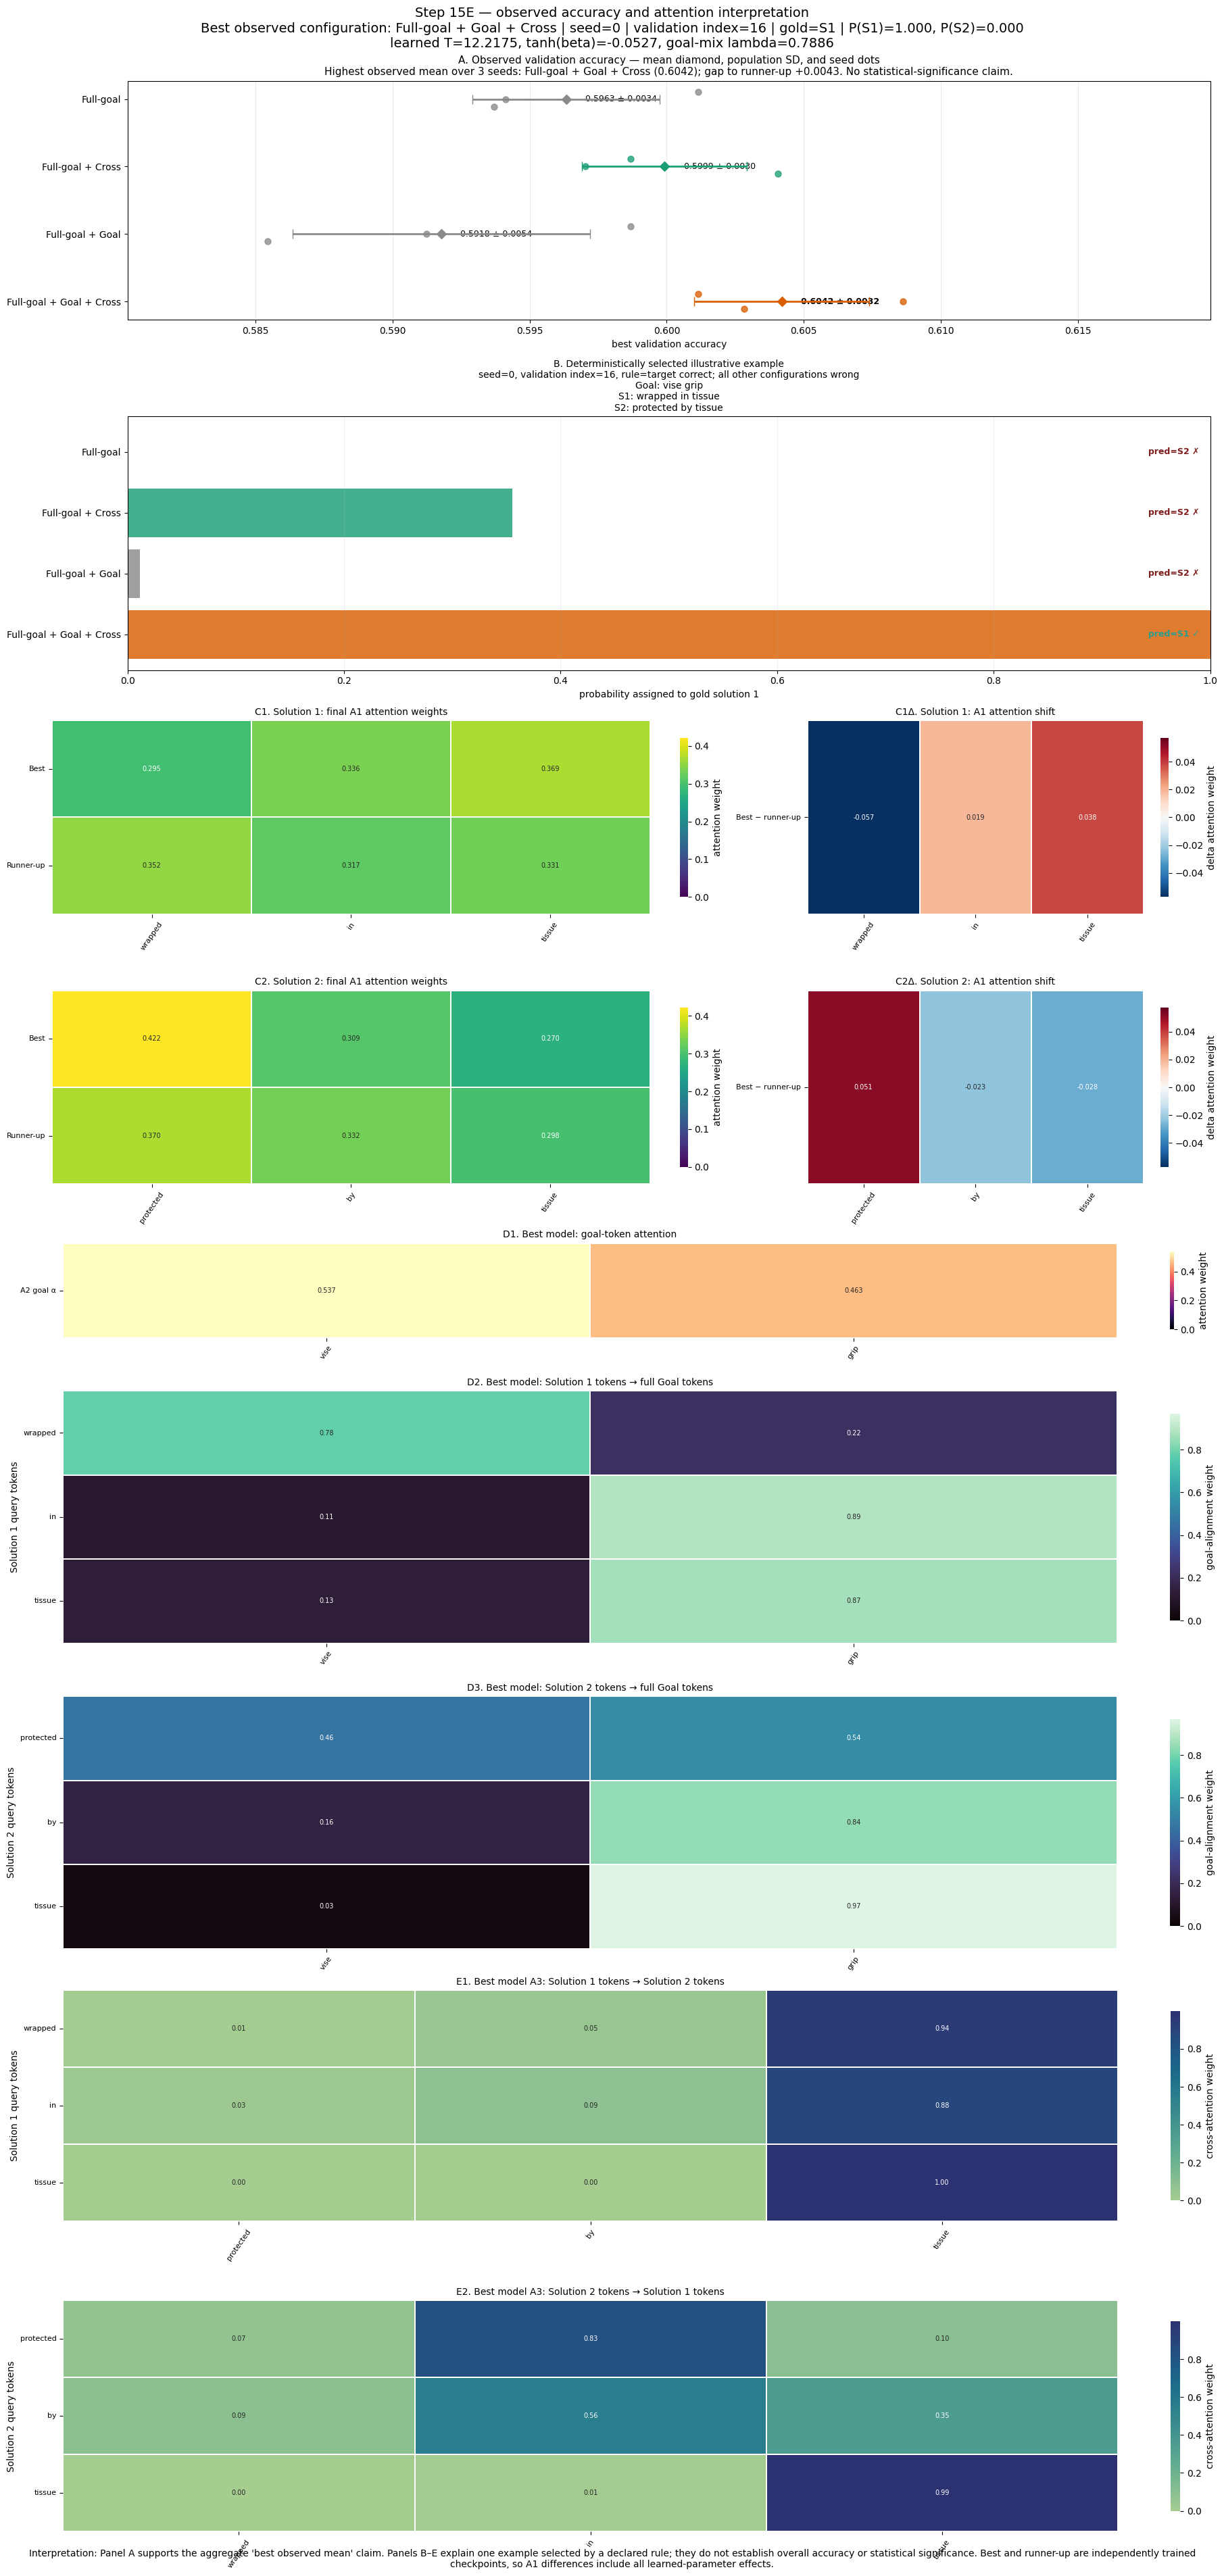

Rendered one Step 15E accuracy + attention composite figure.


In [7]:
# @title Step 13E.5: Standalone best-model attention composite from Google Drive
# Fresh-runtime cell: restore PIQA, load one complete Step 15E run, select a
# deterministic illustrative example, and render one accuracy + attention figure.

from collections import Counter, defaultdict
from pathlib import Path
import hashlib
import io
import json
import math
import os
import re
import textwrap
import zipfile

import gdown
import google.auth
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from sklearn.model_selection import train_test_split


# User controls. The sample itself is selected deterministically below.
STEP15E_HEATMAP_TARGET_CONFIG = (
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_"
    "learned_temperature_full_goal_attention"
)
STEP15E_HEATMAP_SEED = 0

STEP15E5_ALL_CONFIGS = (
    "goal_guided_solution_attention_mean_mix_learned_temperature_full_goal_attention",
    "goal_guided_solution_attention_mean_mix_with_cross_attention_learned_temperature_full_goal_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_attention_learned_temperature_full_goal_attention",
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention",
)
STEP15E5_SEEDS = (0, 1, 2)
STEP15E5_DISPLAY_NAMES = {
    STEP15E5_ALL_CONFIGS[0]: "Full-goal",
    STEP15E5_ALL_CONFIGS[1]: "Full-goal + Cross",
    STEP15E5_ALL_CONFIGS[2]: "Full-goal + Goal",
    STEP15E5_ALL_CONFIGS[3]: "Full-goal + Goal + Cross",
}

if STEP15E_HEATMAP_TARGET_CONFIG not in STEP15E5_ALL_CONFIGS:
    raise ValueError("STEP15E_HEATMAP_TARGET_CONFIG is not a supported Step 15E configuration.")
try:
    STEP15E_HEATMAP_SEED = int(STEP15E_HEATMAP_SEED)
except (TypeError, ValueError) as exc:
    raise ValueError("STEP15E_HEATMAP_SEED must be an integer.") from exc
if STEP15E_HEATMAP_SEED not in STEP15E5_SEEDS:
    raise ValueError(f"STEP15E_HEATMAP_SEED must be one of {STEP15E5_SEEDS}.")


# ---------------------------------------------------------------------
# 1. Restore the exact PIQA validation split in a fresh runtime.
# ---------------------------------------------------------------------

STEP15E5_PIQA_DATA_FILE_ID = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
STEP15E5_PIQA_DATA_DIR = Path("/content/piqa_step15e5_heatmap_data")
STEP15E5_PIQA_FILENAMES = (
    "train.jsonl",
    "train-labels.lst",
    "test.jsonl",
    "test-labels.lst",
)


def ensure_step15e5_piqa_data():
    """Download/reuse the PIQA archive and return the four expected paths."""
    STEP15E5_PIQA_DATA_DIR.mkdir(parents=True, exist_ok=True)
    located = {
        name: next(iter(STEP15E5_PIQA_DATA_DIR.rglob(name)), None)
        for name in STEP15E5_PIQA_FILENAMES
    }
    if any(path is None for path in located.values()):
        archive_path = STEP15E5_PIQA_DATA_DIR / "piqa_data.zip"
        downloaded_path = gdown.download(
            id=STEP15E5_PIQA_DATA_FILE_ID,
            output=str(archive_path),
            quiet=False,
        )
        if downloaded_path is None or not archive_path.is_file():
            raise RuntimeError("PIQA data download failed.")
        try:
            with zipfile.ZipFile(archive_path) as archive:
                archive.extractall(STEP15E5_PIQA_DATA_DIR)
        except (OSError, zipfile.BadZipFile) as exc:
            raise RuntimeError("The downloaded PIQA archive is invalid.") from exc
        located = {
            name: next(iter(STEP15E5_PIQA_DATA_DIR.rglob(name)), None)
            for name in STEP15E5_PIQA_FILENAMES
        }
    missing = [name for name, path in located.items() if path is None]
    if missing:
        raise RuntimeError("PIQA archive is missing: " + ", ".join(missing))
    return located


def step15e5_clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?'\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()


def read_step15e5_piqa(data_path, label_path):
    with open(data_path, encoding="utf-8") as data_file:
        data_lines = data_file.readlines()
    with open(label_path, encoding="utf-8") as label_file:
        label_lines = label_file.readlines()
    rows = []
    for line, label in zip(data_lines, label_lines):
        if not label.strip():
            continue
        item = json.loads(line)
        rows.append({
            "goal": item["goal"],
            "sol1": item["sol1"],
            "sol2": item["sol2"],
            "label": int(label.strip()),
        })
    return rows


def build_step15e5_vocabulary(rows, min_count=2):
    word_count = Counter()
    for item in rows:
        word_count.update(step15e5_clean_str(item["goal"]).split())
        word_count.update(step15e5_clean_str(item["sol1"]).split())
        word_count.update(step15e5_clean_str(item["sol2"]).split())
    vocabulary = {"<pad>": 0, "<unk>": 1}
    for word, count in word_count.most_common():
        if count >= min_count:
            vocabulary[word] = len(vocabulary)
    return vocabulary


def step15e5_words_to_index(words, vocabulary, maxlength):
    indices = np.zeros(maxlength, dtype=np.int64)
    for index, word in enumerate(words[:maxlength]):
        indices[index] = vocabulary.get(word, 1)
    return indices


def make_step15e5_batch_input(rows, vocabulary, maxgoal=20, maxsol=60):
    size = len(rows)
    goal = np.zeros((size, maxgoal), dtype=np.int64)
    sol1 = np.zeros((size, maxsol), dtype=np.int64)
    sol2 = np.zeros((size, maxsol), dtype=np.int64)
    labels = np.zeros(size, dtype=np.int64)
    for index, item in enumerate(rows):
        goal[index] = step15e5_words_to_index(
            step15e5_clean_str(item["goal"]).split(), vocabulary, maxgoal
        )
        sol1[index] = step15e5_words_to_index(
            step15e5_clean_str(item["sol1"]).split(), vocabulary, maxsol
        )
        sol2[index] = step15e5_words_to_index(
            step15e5_clean_str(item["sol2"]).split(), vocabulary, maxsol
        )
        labels[index] = item["label"]
    return goal, sol1, sol2, labels


step15e5_piqa_paths = ensure_step15e5_piqa_data()
step15e5_all_train_rows = read_step15e5_piqa(
    step15e5_piqa_paths["train.jsonl"],
    step15e5_piqa_paths["train-labels.lst"],
)
step15e5_all_labels = [item["label"] for item in step15e5_all_train_rows]
step15e5_train_rows, step15e5_validation_rows = train_test_split(
    step15e5_all_train_rows,
    test_size=0.15,
    random_state=0,
    stratify=step15e5_all_labels,
)
step15e5_vocabulary = build_step15e5_vocabulary(step15e5_train_rows, min_count=2)
step15e5_validation_input = make_step15e5_batch_input(
    step15e5_validation_rows,
    step15e5_vocabulary,
)
(
    step15e5_goal_array,
    step15e5_sol1_array,
    step15e5_sol2_array,
    step15e5_label_array,
) = step15e5_validation_input
step15e5_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ---------------------------------------------------------------------
# 2. Rebuild the Step 15E architecture exactly as trained.
# ---------------------------------------------------------------------

STEP15E5_GOAL_CROSS_DIM = 64


def step15e5_masked_pool(rnn_output, index, pooling="mean"):
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        return rnn_output.masked_fill(mask == 0, -1e9).max(dim=1)[0]
    return (rnn_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)


def step15e5_attention_on_goal(goal_output, goal_index, query):
    score = torch.matmul(goal_output, query)
    score = score.masked_fill(goal_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), goal_output).squeeze(1)
    return context, alpha


class PIQA_Step15E5_Base_Model(nn.Module):
    def __init__(
        self, vocabulary_size, dimension=100, n_hidden_input=100,
        dropout_input=0.25, num_layers_input=1, rnn_type="LSTM",
        pooling="mean", attention_type="none", goal_attention=False,
        use_cross_attention=False, use_interaction=True, use_goal=True,
    ):
        super().__init__()
        self.pooling = pooling
        self.attention_type = attention_type
        self.goal_attention = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction = use_interaction
        self.use_goal = use_goal
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        encoder_class = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.encoder = encoder_class(
            dimension,
            n_hidden_input,
            num_layers=num_layers_input,
            batch_first=True,
            bidirectional=True,
            dropout=dropout_input if num_layers_input > 1 else 0,
        )
        self.W = nn.Linear(n_hidden_input * 2, n_hidden_input * 2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        score_input = n_hidden_input * 2 * (4 if use_interaction else 2)
        if use_cross_attention:
            score_input += n_hidden_input * 2
        self.hidden_layer = nn.Linear(score_input, n_hidden_input)
        self.score_layer = nn.Linear(n_hidden_input, 1)
        self.dropout = nn.Dropout(dropout_input)


class PIQA_Step15E5_LearnedTemperature_Model(PIQA_Step15E5_Base_Model):
    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 15E requires attention_type='goal'.")
        use_cross_attention = bool(settings.get("use_cross_attention", False))
        if use_cross_attention and cross_difference_pooling != "masked_mean_max":
            raise ValueError(
                "Cross-attention configurations require masked_mean_max pooling."
            )
        if not use_cross_attention and cross_difference_pooling is not None:
            raise ValueError(
                "cross_difference_pooling is only valid with cross-attention."
            )
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Step 15E uses masked mean as the mix fallback.")
        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_epsilon = 1e-6
        if use_cross_attention:
            base_width = hidden_size * 2 * (4 if use_interaction else 2)
            self.hidden_layer = nn.Linear(
                base_width + hidden_size * 4,
                hidden_size,
            )
        attention_dim = self.W.out_features
        initial_temperature = math.sqrt(attention_dim)
        initial_raw = math.log(math.expm1(initial_temperature))
        self.raw_attention_temperature = nn.Parameter(
            torch.tensor(initial_raw, dtype=self.W.weight.dtype)
        )
        self.goal_mean_mix_logit = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        return (
            torch.nn.functional.softplus(self.raw_attention_temperature)
            + self.temperature_epsilon
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def mix_solution_context(self, goal_attention_context, mean_context):
        mix = self.goal_attention_lambda
        return mix * goal_attention_context + (1.0 - mix) * mean_context


class PIQA_Step15E5_FullGoalAttention_Model(
    PIQA_Step15E5_LearnedTemperature_Model
):
    """Step 15D learned-temperature model plus the Step 15E A1 residual."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        super().__init__(
            vocabulary_size,
            cross_difference_pooling=cross_difference_pooling,
            **settings,
        )
        attention_dim = self.W.out_features
        if attention_dim != 200:
            raise ValueError(
                "Step 15E checkpoints require 200-dimensional BiLSTM states."
            )
        self.full_goal_attention_dim = STEP15E5_GOAL_CROSS_DIM
        self.full_goal_query = nn.Linear(
            attention_dim, self.full_goal_attention_dim, bias=False
        )
        self.full_goal_key = nn.Linear(
            attention_dim, self.full_goal_attention_dim, bias=False
        )
        self.full_goal_value = nn.Linear(
            attention_dim, self.full_goal_attention_dim, bias=False
        )
        self.full_goal_output = nn.Linear(
            self.full_goal_attention_dim, attention_dim, bias=False
        )
        self.goal_token_residual = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_token_residual_scale(self):
        return torch.tanh(self.goal_token_residual)

    def _enhance_solution_with_goal(
        self, raw_solution_output, solution_index, goal_output, goal_index
    ):
        if raw_solution_output.shape[:2] != solution_index.shape:
            raise ValueError("Solution-state and solution-index shapes must agree.")
        if goal_output.shape[:2] != goal_index.shape:
            raise ValueError("Goal-state and goal-index shapes must agree.")
        query = self.full_goal_query(raw_solution_output)
        key = self.full_goal_key(goal_output)
        value = self.full_goal_value(goal_output)
        scores = torch.bmm(query, key.transpose(1, 2)) / math.sqrt(
            self.full_goal_attention_dim
        )
        goal_mask = goal_index.ne(0)
        solution_mask = solution_index.ne(0)
        scores = scores.masked_fill(
            ~goal_mask.unsqueeze(1), torch.finfo(scores.dtype).min
        )
        goal_alignment = torch.softmax(scores, dim=2)
        goal_alignment = goal_alignment * goal_mask.unsqueeze(1).to(
            goal_alignment.dtype
        )
        goal_alignment = goal_alignment * solution_mask.unsqueeze(2).to(
            goal_alignment.dtype
        )
        goal_context = torch.bmm(goal_alignment, value)
        projected_context = self.full_goal_output(goal_context)
        residual = self.goal_token_residual_scale * projected_context
        residual = residual.masked_fill(~solution_mask.unsqueeze(2), 0.0)
        return raw_solution_output + residual, goal_alignment, residual

    def _score_one_solution_with_a1_states(
        self,
        goal_vector,
        a1_solution_output,
        raw_solution_output,
        current_sol_index,
        other_raw_solution_output,
        other_sol_index,
    ):
        query = self.W(goal_vector)
        score = torch.bmm(a1_solution_output, query.unsqueeze(2)).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(
            device=score.device, dtype=score.dtype
        )
        alpha = torch.softmax(score / temperature, dim=1)
        goal_attention_context = torch.bmm(
            alpha.unsqueeze(1), a1_solution_output
        ).squeeze(1)
        mean_context = step15e5_masked_pool(
            raw_solution_output, current_sol_index, pooling="mean"
        )
        context = self.mix_solution_context(goal_attention_context, mean_context)
        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        align = None
        if self.use_cross_attention:
            similarity = torch.bmm(
                raw_solution_output,
                other_raw_solution_output.transpose(1, 2),
            )
            similarity = similarity.masked_fill(
                (other_sol_index == 0).unsqueeze(1), -1e9
            )
            align = torch.softmax(similarity, dim=2)
            aligned_other = torch.bmm(align, other_raw_solution_output)
            token_difference = raw_solution_output - aligned_other
            current_mask = current_sol_index.ne(0).unsqueeze(2)
            masked_difference = token_difference.masked_fill(~current_mask, 0.0)
            valid_count = current_mask.sum(dim=1).clamp(min=1).to(
                token_difference.dtype
            )
            mean_difference = masked_difference.sum(dim=1) / valid_count
            max_difference = token_difference.masked_fill(
                ~current_mask,
                torch.finfo(token_difference.dtype).min,
            ).max(dim=1).values
            max_difference = torch.where(
                current_mask.any(dim=1),
                max_difference,
                torch.zeros_like(max_difference),
            )
            combined = torch.cat(
                (combined, mean_difference, max_difference), dim=1
            )
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1), alpha, align

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        if self.goal_attention:
            goal_vector, goal_alpha = step15e5_attention_on_goal(
                goal_output, goal, self.goal_query
            )
        else:
            goal_vector = step15e5_masked_pool(goal_output, goal, self.pooling)
            goal_alpha = None
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        if self.use_goal:
            sol1_a1_output, sol1_goal_alignment, _ = (
                self._enhance_solution_with_goal(
                    sol1_output, solution1, goal_output, goal
                )
            )
            sol2_a1_output, sol2_goal_alignment, _ = (
                self._enhance_solution_with_goal(
                    sol2_output, solution2, goal_output, goal
                )
            )
        else:
            sol1_a1_output = sol1_output
            sol2_a1_output = sol2_output
            sol1_goal_alignment = sol1_output.new_zeros(
                sol1_output.shape[0], sol1_output.shape[1], goal_output.shape[1]
            )
            sol2_goal_alignment = sol2_output.new_zeros(
                sol2_output.shape[0], sol2_output.shape[1], goal_output.shape[1]
            )
        score1, alpha1, align1 = self._score_one_solution_with_a1_states(
            goal_vector,
            sol1_a1_output,
            sol1_output,
            solution1,
            sol2_output,
            solution2,
        )
        score2, alpha2, align2 = self._score_one_solution_with_a1_states(
            goal_vector,
            sol2_a1_output,
            sol2_output,
            solution2,
            sol1_output,
            solution1,
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
            "sol1_goal_cross_alpha": sol1_goal_alignment,
            "sol2_goal_cross_alpha": sol2_goal_alignment,
        }


def build_step15e5_model(vocabulary_size, settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return PIQA_Step15E5_FullGoalAttention_Model(
        vocabulary_size,
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# ---------------------------------------------------------------------
# 3. Locate the latest complete, verified Step 15E run in Google Drive.
# ---------------------------------------------------------------------

STEP15E5_DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
STEP15E5_DOWNLOAD_DIR = Path("/content/step15e5_attention_heatmap")
STEP15E5_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)


def list_step15e5_drive_files(service, folder_id):
    files = []
    page_token = None
    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            spaces="drive",
            fields=(
                "nextPageToken,files("
                "id,name,mimeType,createdTime,modifiedTime,size)"
            ),
            orderBy="createdTime desc",
            pageSize=1000,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        files.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            return files


def download_step15e5_drive_bytes(service, file_id):
    buffer = io.BytesIO()
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    downloader = MediaIoBaseDownload(buffer, request)
    complete = False
    while not complete:
        _, complete = downloader.next_chunk()
    return buffer.getvalue()


def download_step15e5_drive_file(service, file_id, destination):
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    with destination.open("wb") as output_file:
        downloader = MediaIoBaseDownload(output_file, request)
        complete = False
        while not complete:
            _, complete = downloader.next_chunk()


def step15e5_sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as input_file:
        for chunk in iter(lambda: input_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def build_step15e5_run_catalog(files, read_json):
    """Group valid Step 15E JSON records by run_id and (configuration, seed)."""
    groups = defaultdict(lambda: defaultdict(list))
    rejected = []
    json_files = sorted(
        (
            item for item in files
            if item.get("name", "").startswith("step15e_")
            and item.get("name", "").endswith(".json")
        ),
        key=lambda item: (item.get("createdTime", ""), item.get("name", "")),
        reverse=True,
    )
    for json_file in json_files:
        try:
            raw_json = read_json(json_file["id"])
            if isinstance(raw_json, bytes):
                raw_json = raw_json.decode("utf-8")
            record = json.loads(raw_json)
        except Exception as exc:
            rejected.append(
                f"{json_file.get('name', '<unnamed>')}: invalid JSON ({exc})"
            )
            continue
        if record.get("experiment") != "step15e":
            continue
        run_id = record.get("run_id")
        configuration = record.get("configuration")
        try:
            seed = int(record.get("seed", -1))
        except (TypeError, ValueError):
            rejected.append(f"{json_file['name']}: invalid seed")
            continue
        if not isinstance(run_id, str) or not run_id:
            rejected.append(f"{json_file['name']}: missing run_id")
            continue
        if configuration not in STEP15E5_ALL_CONFIGS:
            rejected.append(f"{json_file['name']}: unknown configuration")
            continue
        if seed not in STEP15E5_SEEDS:
            rejected.append(f"{json_file['name']}: unexpected seed {seed}")
            continue
        groups[run_id][(configuration, seed)].append((json_file, record))
    return groups, rejected


def step15e5_select_latest_valid_run(
    files,
    required_keys,
    read_json,
    prepare_record,
):
    """Return the newest coherent run; reject a run if any pair is invalid."""
    groups, rejected = build_step15e5_run_catalog(files, read_json)
    checkpoints_by_name = defaultdict(list)
    for item in files:
        if item.get("name", "").endswith(".pt"):
            checkpoints_by_name[item["name"]].append(item)
    for candidates in checkpoints_by_name.values():
        candidates.sort(
            key=lambda item: (item.get("createdTime", ""), item.get("id", "")),
            reverse=True,
        )

    def run_sort_key(run_item):
        run_id, records_by_key = run_item
        newest_time = max(
            json_file.get("createdTime", "")
            for candidates in records_by_key.values()
            for json_file, _ in candidates
        )
        return newest_time, run_id

    for run_id, records_by_key in sorted(
        groups.items(), key=run_sort_key, reverse=True
    ):
        missing_keys = [key for key in required_keys if key not in records_by_key]
        if missing_keys:
            rejected.append(
                f"run {run_id}: incomplete; missing {len(missing_keys)} JSON record(s)"
            )
            continue
        prepared_run = {}
        run_failure = None
        for key in required_keys:
            candidate_errors = []
            prepared_value = None
            candidate_pairs = sorted(
                records_by_key[key],
                key=lambda item: (
                    item[0].get("createdTime", ""),
                    item[0].get("name", ""),
                ),
                reverse=True,
            )
            for json_file, record in candidate_pairs:
                checkpoint_name = record.get("checkpoint_filename")
                if (
                    not isinstance(checkpoint_name, str)
                    or Path(checkpoint_name).name != checkpoint_name
                ):
                    candidate_errors.append(
                        f"{json_file['name']}: invalid checkpoint filename"
                    )
                    continue
                checkpoint_files = checkpoints_by_name.get(checkpoint_name, [])
                if not checkpoint_files:
                    candidate_errors.append(
                        f"{json_file['name']}: paired .pt is missing"
                    )
                    continue
                for checkpoint_file in checkpoint_files:
                    try:
                        result = prepare_record(checkpoint_file, record)
                    except Exception as exc:
                        candidate_errors.append(
                            f"{json_file['name']} + {checkpoint_file['name']}: {exc}"
                        )
                        continue
                    prepared_value = {
                        "json_file": json_file,
                        "checkpoint_file": checkpoint_file,
                        "record": record,
                        "result": result,
                    }
                    break
                if prepared_value is not None:
                    break
            if prepared_value is None:
                run_failure = (
                    f"run {run_id}, {key[0]} seed={key[1]} has no valid pair: "
                    + " | ".join(candidate_errors[-4:])
                )
                break
            prepared_run[key] = prepared_value
        if run_failure is not None:
            rejected.append(run_failure)
            prepared_run.clear()
            continue
        return run_id, prepared_run, rejected

    if not groups:
        raise RuntimeError("Google Drive has no Step 15E JSON records.")
    details = "\n".join("- " + item for item in rejected[-20:])
    raise RuntimeError(
        "No complete and valid Step 15E run was found."
        + ("\n" + details if details else "")
    )


def fetch_verified_step15e5_checkpoint(service, checkpoint_file, record):
    expected = record.get("checkpoint_sha256")
    if (
        not isinstance(expected, str)
        or re.fullmatch(r"[0-9a-fA-F]{64}", expected) is None
    ):
        raise ValueError("JSON is missing a valid checkpoint_sha256")
    expected = expected.lower()
    safe_name = Path(checkpoint_file["name"]).name
    if safe_name != checkpoint_file["name"]:
        raise ValueError("Drive checkpoint has an unsafe filename")
    destination = STEP15E5_DOWNLOAD_DIR / safe_name
    if destination.is_file() and step15e5_sha256_file(destination) == expected:
        return destination
    temporary = destination.with_name(
        destination.name + "." + checkpoint_file["id"] + ".part"
    )
    try:
        download_step15e5_drive_file(
            service,
            checkpoint_file["id"],
            temporary,
        )
        actual = step15e5_sha256_file(temporary)
        if actual != expected:
            raise ValueError(
                f"SHA-256 mismatch: expected {expected}, got {actual}"
            )
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()
    return destination


def step15e5_torch_load(path, map_location):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)


def prepare_step15e5_record(service, checkpoint_file, record):
    settings = record.get("settings")
    if not isinstance(settings, dict):
        raise ValueError("JSON is missing settings")
    run_id = record.get("run_id")
    configuration = record.get("configuration")
    if not isinstance(run_id, str) or not run_id:
        raise ValueError("JSON is missing a valid run_id.")
    if configuration not in STEP15E5_ALL_CONFIGS:
        raise ValueError("JSON has an unexpected Step 15E configuration.")
    try:
        seed = int(record.get("seed"))
        json_accuracy = float(record.get("best_validation_accuracy"))
    except (TypeError, ValueError) as exc:
        raise ValueError("JSON has an invalid seed or best_validation_accuracy.") from exc
    if not np.isfinite(json_accuracy) or not 0.0 <= json_accuracy <= 1.0:
        raise ValueError("JSON best_validation_accuracy must be finite and within [0, 1].")
    expected_checkpoint_name = (
        f"step15e_{run_id}_{configuration}_seed{seed}.pt"
    )
    if record.get("checkpoint_filename") != expected_checkpoint_name:
        raise ValueError("JSON checkpoint filename does not match its run/configuration/seed.")
    if checkpoint_file.get("name") != expected_checkpoint_name:
        raise ValueError("Drive checkpoint filename does not match its run/configuration/seed.")
    checkpoint_path = fetch_verified_step15e5_checkpoint(
        service,
        checkpoint_file,
        record,
    )
    checkpoint = step15e5_torch_load(checkpoint_path, map_location="cpu")
    if not isinstance(checkpoint, dict):
        raise ValueError("Checkpoint payload is not a dictionary.")
    if checkpoint.get("format") != "step15e_full_goal_attention_v1":
        raise ValueError("Checkpoint has an unexpected Step 15E format.")
    state_dict = checkpoint.get("model_state_dict")
    metadata = checkpoint.get("experiment_metadata")
    if not isinstance(state_dict, dict):
        raise ValueError("Checkpoint is missing model_state_dict.")
    if not isinstance(metadata, dict):
        raise ValueError("Checkpoint is missing experiment_metadata.")
    if metadata.get("configuration") != configuration:
        raise ValueError("Checkpoint/JSON configuration mismatch.")
    if int(metadata.get("seed", -1)) != seed:
        raise ValueError("Checkpoint/JSON seed mismatch.")
    if metadata.get("checkpoint") != expected_checkpoint_name:
        raise ValueError("Checkpoint metadata filename mismatch.")
    try:
        checkpoint_accuracy = float(metadata.get("best_validation_accuracy"))
    except (TypeError, ValueError) as exc:
        raise ValueError("Checkpoint metadata has an invalid best_validation_accuracy.") from exc
    if (
        not np.isfinite(checkpoint_accuracy)
        or not np.isclose(checkpoint_accuracy, json_accuracy, rtol=0.0, atol=1e-12)
    ):
        raise ValueError("Checkpoint/JSON best_validation_accuracy mismatch.")
    try:
        model = build_step15e5_model(len(step15e5_vocabulary), settings)
        model.load_state_dict(state_dict, strict=True)
    except Exception as exc:
        raise RuntimeError("Checkpoint does not match the reconstructed model.") from exc
    finally:
        if "model" in locals():
            del model
    return {"checkpoint_path": str(checkpoint_path)}


auth.authenticate_user()
step15e5_drive_credentials, _ = google.auth.default()
step15e5_drive_service = build(
    "drive",
    "v3",
    credentials=step15e5_drive_credentials,
    cache_discovery=False,
)
step15e5_drive_folder = step15e5_drive_service.files().get(
    fileId=STEP15E5_DRIVE_FOLDER_ID,
    fields="id,name,mimeType",
    supportsAllDrives=True,
).execute()
if step15e5_drive_folder.get("mimeType") != "application/vnd.google-apps.folder":
    raise RuntimeError("The configured Google Drive target is not a folder.")
step15e5_drive_files = list_step15e5_drive_files(
    step15e5_drive_service,
    STEP15E5_DRIVE_FOLDER_ID,
)
step15e5_required_keys = tuple(
    (configuration, seed)
    for configuration in STEP15E5_ALL_CONFIGS
    for seed in STEP15E5_SEEDS
)
(
    step15e5_selected_run_id,
    step15e5_prepared_run,
    step15e5_rejected_backups,
) = step15e5_select_latest_valid_run(
    step15e5_drive_files,
    step15e5_required_keys,
    lambda file_id: download_step15e5_drive_bytes(
        step15e5_drive_service, file_id
    ),
    lambda checkpoint_file, record: prepare_step15e5_record(
        step15e5_drive_service, checkpoint_file, record
    ),
)
for step15e5_rejected_backup in step15e5_rejected_backups:
    print("Skipped Drive backup:", step15e5_rejected_backup)


# ---------------------------------------------------------------------
# 4. Aggregate accuracy and select the illustrative validation example.
# ---------------------------------------------------------------------


def step15e5_accuracy_summary(prepared_run):
    summary = {}
    for configuration in STEP15E5_ALL_CONFIGS:
        values = []
        for seed in STEP15E5_SEEDS:
            record = prepared_run[(configuration, seed)]["record"]
            try:
                value = float(record["best_validation_accuracy"])
            except (KeyError, TypeError, ValueError) as exc:
                raise ValueError(
                    f"Invalid accuracy for {configuration}, seed={seed}."
                ) from exc
            if not np.isfinite(value) or not 0.0 <= value <= 1.0:
                raise ValueError(
                    f"Out-of-range accuracy for {configuration}, seed={seed}."
                )
            values.append(value)
        summary[configuration] = {
            "seed_values": np.asarray(values, dtype=float),
            "mean": float(np.mean(values)),
            "sd": float(np.std(values)),
        }
    return summary


def load_step15e5_model(configuration, seed, device):
    item = step15e5_prepared_run[(configuration, seed)]
    settings = item["record"].get("settings")
    model = build_step15e5_model(len(step15e5_vocabulary), settings).to(device)
    checkpoint = step15e5_torch_load(
        item["result"]["checkpoint_path"],
        map_location=device,
    )
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    return model


def predict_step15e5_validation(configuration, seed, batch_size=128):
    model = load_step15e5_model(configuration, seed, step15e5_device)
    probabilities = []
    with torch.no_grad():
        for start in range(0, len(step15e5_label_array), batch_size):
            stop = min(start + batch_size, len(step15e5_label_array))
            goal = torch.as_tensor(
                step15e5_goal_array[start:stop],
                dtype=torch.long,
                device=step15e5_device,
            )
            sol1 = torch.as_tensor(
                step15e5_sol1_array[start:stop],
                dtype=torch.long,
                device=step15e5_device,
            )
            sol2 = torch.as_tensor(
                step15e5_sol2_array[start:stop],
                dtype=torch.long,
                device=step15e5_device,
            )
            logits, _ = model(goal, sol1, sol2)
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    probabilities = np.concatenate(probabilities, axis=0)
    return probabilities, probabilities.argmax(axis=1)


def step15e5_choose_sample_index(predictions, labels, target, runner_up):
    """Prefer target-only correct; fall back to target correct/runner-up wrong."""
    labels = np.asarray(labels)
    expected = set(STEP15E5_ALL_CONFIGS)
    if set(predictions) != expected:
        missing = sorted(expected - set(predictions))
        extra = sorted(set(predictions) - expected)
        raise ValueError(f"Prediction keys mismatch; missing={missing}, extra={extra}.")
    for configuration, values in predictions.items():
        if np.asarray(values).shape != labels.shape:
            raise ValueError(
                f"Prediction shape mismatch for {configuration}: "
                f"{np.asarray(values).shape} vs {labels.shape}."
            )
    target_correct = np.asarray(predictions[target]) == labels
    all_others_wrong = np.logical_and.reduce([
        np.asarray(predictions[configuration]) != labels
        for configuration in STEP15E5_ALL_CONFIGS
        if configuration != target
    ])
    strict_matches = np.flatnonzero(target_correct & all_others_wrong)
    if strict_matches.size:
        return int(strict_matches[0]), "target correct; all other configurations wrong"
    fallback_matches = np.flatnonzero(
        target_correct & (np.asarray(predictions[runner_up]) != labels)
    )
    if fallback_matches.size:
        return int(fallback_matches[0]), "target correct; runner-up wrong (fallback)"
    raise RuntimeError(
        "No validation sample satisfies either the strict target-only rule or "
        "the target-correct/runner-up-wrong fallback rule."
    )


step15e5_accuracy = step15e5_accuracy_summary(step15e5_prepared_run)
step15e5_ranked_configs = sorted(
    STEP15E5_ALL_CONFIGS,
    key=lambda name: step15e5_accuracy[name]["mean"],
    reverse=True,
)
if step15e5_ranked_configs[0] != STEP15E_HEATMAP_TARGET_CONFIG:
    raise RuntimeError(
        "STEP15E_HEATMAP_TARGET_CONFIG is not the highest-mean configuration in the "
        f"selected run. Highest is {step15e5_ranked_configs[0]}."
    )
step15e5_runner_up_config = step15e5_ranked_configs[1]
step15e5_target_mean = step15e5_accuracy[STEP15E_HEATMAP_TARGET_CONFIG]["mean"]
step15e5_runner_mean = step15e5_accuracy[step15e5_runner_up_config]["mean"]
if not step15e5_target_mean > step15e5_runner_mean:
    raise RuntimeError("The target configuration does not have a unique highest mean.")

step15e5_probabilities = {}
step15e5_predictions = {}
for step15e5_configuration in STEP15E5_ALL_CONFIGS:
    (
        step15e5_probabilities[step15e5_configuration],
        step15e5_predictions[step15e5_configuration],
    ) = predict_step15e5_validation(
        step15e5_configuration,
        STEP15E_HEATMAP_SEED,
    )

(
    STEP15E5_SAMPLE_INDEX,
    step15e5_sample_selection_rule,
) = step15e5_choose_sample_index(
    step15e5_predictions,
    step15e5_label_array,
    STEP15E_HEATMAP_TARGET_CONFIG,
    step15e5_runner_up_config,
)


# ---------------------------------------------------------------------
# 5. Recover the selected sample's actual attention tensors.
# ---------------------------------------------------------------------


def step15e5_visible_tokens(text, index_row):
    token_count = int(np.count_nonzero(index_row))
    return step15e5_clean_str(text).split()[:token_count]


def extract_step15e5_sample_attention(configuration, sample_index):
    model = load_step15e5_model(configuration, STEP15E_HEATMAP_SEED, step15e5_device)
    sample_slice = slice(sample_index, sample_index + 1)
    goal = torch.as_tensor(
        step15e5_goal_array[sample_slice],
        dtype=torch.long,
        device=step15e5_device,
    )
    sol1 = torch.as_tensor(
        step15e5_sol1_array[sample_slice],
        dtype=torch.long,
        device=step15e5_device,
    )
    sol2 = torch.as_tensor(
        step15e5_sol2_array[sample_slice],
        dtype=torch.long,
        device=step15e5_device,
    )
    with torch.no_grad():
        logits, attention = model(goal, sol1, sol2)
        probabilities = torch.softmax(logits, dim=1)
    result = {
        "probabilities": probabilities[0].detach().cpu().numpy(),
        "temperature": float(model.attention_temperature.detach().cpu()),
        "goal_attention_lambda": float(
            model.goal_attention_lambda.detach().cpu()
        ),
        "residual_scale": float(
            model.goal_token_residual_scale.detach().cpu()
        ),
        "attention": {
            key: (
                value[0].detach().cpu().numpy()
                if value is not None else None
            )
            for key, value in attention.items()
        },
    }
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


step15e5_sample_row = step15e5_validation_rows[STEP15E5_SAMPLE_INDEX]
step15e5_gold = int(step15e5_label_array[STEP15E5_SAMPLE_INDEX])
step15e5_goal_tokens = step15e5_visible_tokens(
    step15e5_sample_row["goal"],
    step15e5_goal_array[STEP15E5_SAMPLE_INDEX],
)
step15e5_sol1_tokens = step15e5_visible_tokens(
    step15e5_sample_row["sol1"],
    step15e5_sol1_array[STEP15E5_SAMPLE_INDEX],
)
step15e5_sol2_tokens = step15e5_visible_tokens(
    step15e5_sample_row["sol2"],
    step15e5_sol2_array[STEP15E5_SAMPLE_INDEX],
)
if not step15e5_goal_tokens or not step15e5_sol1_tokens or not step15e5_sol2_tokens:
    raise RuntimeError("The selected sample contains an empty tokenized sequence.")

step15e5_target_result = extract_step15e5_sample_attention(
    STEP15E_HEATMAP_TARGET_CONFIG,
    STEP15E5_SAMPLE_INDEX,
)
step15e5_runner_result = extract_step15e5_sample_attention(
    step15e5_runner_up_config,
    STEP15E5_SAMPLE_INDEX,
)
for configuration, result in (
    (STEP15E_HEATMAP_TARGET_CONFIG, step15e5_target_result),
    (step15e5_runner_up_config, step15e5_runner_result),
):
    expected_probability = step15e5_probabilities[configuration][
        STEP15E5_SAMPLE_INDEX
    ]
    if not np.allclose(result["probabilities"], expected_probability, atol=1e-6):
        raise RuntimeError(
            f"Selected-sample probability mismatch for {configuration}."
        )


def step15e5_crop_and_validate_attention():
    target = step15e5_target_result["attention"]
    runner = step15e5_runner_result["attention"]
    goal_count = len(step15e5_goal_tokens)
    sol1_count = len(step15e5_sol1_tokens)
    sol2_count = len(step15e5_sol2_tokens)
    if target["goal_alpha"] is None:
        raise RuntimeError("The target checkpoint did not return A2 goal attention.")
    if target["sol1_align"] is None or target["sol2_align"] is None:
        raise RuntimeError("The target checkpoint did not return A3 cross-attention.")
    cropped = {
        "target_sol1": target["sol1_alpha"][:sol1_count],
        "target_sol2": target["sol2_alpha"][:sol2_count],
        "runner_sol1": runner["sol1_alpha"][:sol1_count],
        "runner_sol2": runner["sol2_alpha"][:sol2_count],
        "goal": target["goal_alpha"][:goal_count],
        "sol1_goal": target["sol1_goal_cross_alpha"][
            :sol1_count, :goal_count
        ],
        "sol2_goal": target["sol2_goal_cross_alpha"][
            :sol2_count, :goal_count
        ],
        "sol1_to_sol2": target["sol1_align"][:sol1_count, :sol2_count],
        "sol2_to_sol1": target["sol2_align"][:sol2_count, :sol1_count],
    }
    for key in ("target_sol1", "target_sol2", "runner_sol1", "runner_sol2", "goal"):
        if not np.isclose(np.sum(cropped[key]), 1.0, atol=1e-6):
            raise RuntimeError(f"{key} attention does not sum to one.")
    for key in ("sol1_goal", "sol2_goal", "sol1_to_sol2", "sol2_to_sol1"):
        if not np.allclose(np.sum(cropped[key], axis=1), 1.0, atol=1e-6):
            raise RuntimeError(f"{key} attention rows do not sum to one.")
    return cropped


step15e5_attention = step15e5_crop_and_validate_attention()


# ---------------------------------------------------------------------
# 6. Draw one vertically stacked accuracy + attention composite figure.
# ---------------------------------------------------------------------


def step15e5_heatmap(
    ax,
    values,
    x_tokens,
    y_tokens,
    title,
    cmap,
    vmin,
    vmax,
    colorbar_label,
    center=None,
    fmt=".2f",
):
    values = np.asarray(values, dtype=float)
    annotate = values.size <= 120
    sns.heatmap(
        values,
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        center=center,
        xticklabels=x_tokens,
        yticklabels=y_tokens,
        annot=annotate,
        fmt=fmt,
        annot_kws={"fontsize": 7},
        linewidths=0.2,
        cbar_kws={"label": colorbar_label, "shrink": 0.82},
    )
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=55, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)


def draw_step15e5_composite():
    target_color = "#d95f02"
    runner_color = "#1b9e77"
    neutral_color = "#8a8a8a"
    correct_color = "#2a9d8f"
    wrong_color = "#c8c8c8"
    max_tokens = max(
        len(step15e5_goal_tokens),
        len(step15e5_sol1_tokens),
        len(step15e5_sol2_tokens),
    )
    figure_width = max(18.0, min(28.0, 0.42 * max_tokens + 12.0))
    figure = plt.figure(
        figsize=(figure_width, 38),
        constrained_layout=True,
    )
    outer = figure.add_gridspec(
        5,
        1,
        height_ratios=(3.2, 3.4, 7.0, 10.0, 8.0),
    )

    # Panel A: the only panel used to establish the aggregate accuracy claim.
    accuracy_ax = figure.add_subplot(outer[0])
    display_order = list(STEP15E5_ALL_CONFIGS)
    all_accuracy_values = []
    for y_position, configuration in enumerate(display_order):
        stats = step15e5_accuracy[configuration]
        values = stats["seed_values"]
        all_accuracy_values.extend(values.tolist())
        color = (
            target_color if configuration == STEP15E_HEATMAP_TARGET_CONFIG
            else runner_color if configuration == step15e5_runner_up_config
            else neutral_color
        )
        jitter = np.linspace(-0.11, 0.11, len(values))
        accuracy_ax.scatter(
            values,
            y_position + jitter,
            color=color,
            s=42,
            alpha=0.78,
            zorder=3,
            label=None,
        )
        accuracy_ax.errorbar(
            stats["mean"],
            y_position,
            xerr=stats["sd"],
            fmt="D",
            color=color,
            ecolor=color,
            capsize=5,
            markersize=7,
            linewidth=2,
            zorder=4,
        )
        accuracy_ax.text(
            stats["mean"] + 0.0007,
            y_position,
            f"{stats['mean']:.4f} ± {stats['sd']:.4f}",
            va="center",
            fontsize=9,
            fontweight=(
                "bold" if configuration == STEP15E_HEATMAP_TARGET_CONFIG else "normal"
            ),
        )
    x_min = min(all_accuracy_values)
    x_max = max(all_accuracy_values)
    padding = max(0.004, (x_max - x_min) * 0.22)
    accuracy_ax.set_xlim(x_min - padding, x_max + padding * 2.2)
    accuracy_ax.set_yticks(range(len(display_order)))
    accuracy_ax.set_yticklabels([
        STEP15E5_DISPLAY_NAMES[name] for name in display_order
    ])
    accuracy_ax.invert_yaxis()
    accuracy_ax.set_xlabel("best validation accuracy")
    accuracy_ax.set_title(
        "A. Observed validation accuracy — mean diamond, population SD, and seed dots\n"
        f"Highest observed mean over 3 seeds: "
        f"{STEP15E5_DISPLAY_NAMES[STEP15E_HEATMAP_TARGET_CONFIG]} "
        f"({step15e5_target_mean:.4f}); gap to runner-up "
        f"{step15e5_target_mean - step15e5_runner_mean:+.4f}. "
        "No statistical-significance claim.",
        fontsize=11,
    )
    accuracy_ax.grid(axis="x", alpha=0.25)

    # Panel B: deterministic illustrative-case predictions for all configs.
    prediction_ax = figure.add_subplot(outer[1])
    prediction_order = display_order
    gold_probabilities = [
        float(step15e5_probabilities[name][STEP15E5_SAMPLE_INDEX, step15e5_gold])
        for name in prediction_order
    ]
    prediction_colors = [
        target_color if name == STEP15E_HEATMAP_TARGET_CONFIG
        else runner_color if name == step15e5_runner_up_config
        else neutral_color
        for name in prediction_order
    ]
    prediction_bars = prediction_ax.barh(
        range(len(prediction_order)),
        gold_probabilities,
        color=prediction_colors,
        alpha=0.82,
    )
    prediction_ax.set_xlim(0.0, 1.0)
    prediction_ax.set_yticks(range(len(prediction_order)))
    prediction_ax.set_yticklabels([
        STEP15E5_DISPLAY_NAMES[name] for name in prediction_order
    ])
    prediction_ax.invert_yaxis()
    prediction_ax.set_xlabel(f"probability assigned to gold solution {step15e5_gold + 1}")
    for bar, configuration in zip(prediction_bars, prediction_order):
        prediction = int(
            step15e5_predictions[configuration][STEP15E5_SAMPLE_INDEX]
        )
        correct = prediction == step15e5_gold
        prediction_ax.text(
            0.99,
            bar.get_y() + bar.get_height() / 2,
            f"pred=S{prediction + 1} {'✓' if correct else '✗'}",
            ha="right",
            va="center",
            fontsize=9,
            color=correct_color if correct else "#7f1d1d",
            fontweight="bold",
        )
    prediction_ax.set_title(
        "B. Deterministically selected illustrative example\n"
        f"seed={STEP15E_HEATMAP_SEED}, validation index={STEP15E5_SAMPLE_INDEX}, "
        f"rule={step15e5_sample_selection_rule}\n"
        f"Goal: {textwrap.fill(step15e5_sample_row['goal'], width=120)}\n"
        f"S1: {textwrap.fill(step15e5_sample_row['sol1'], width=120)}\n"
        f"S2: {textwrap.fill(step15e5_sample_row['sol2'], width=120)}",
        fontsize=10,
    )
    prediction_ax.grid(axis="x", alpha=0.2)

    # Panel C: directly comparable A1 distributions and their signed deltas.
    a1_grid = outer[2].subgridspec(2, 2, width_ratios=(3.2, 1.8))
    a1_values = [
        step15e5_attention["target_sol1"],
        step15e5_attention["target_sol2"],
        step15e5_attention["runner_sol1"],
        step15e5_attention["runner_sol2"],
    ]
    a1_max = max(1e-9, max(float(np.max(value)) for value in a1_values))
    a1_deltas = {
        "sol1": (
            step15e5_attention["target_sol1"]
            - step15e5_attention["runner_sol1"]
        ),
        "sol2": (
            step15e5_attention["target_sol2"]
            - step15e5_attention["runner_sol2"]
        ),
    }
    delta_limit = max(
        1e-9,
        max(float(np.max(np.abs(value))) for value in a1_deltas.values()),
    )
    for row_index, (solution_key, tokens, title) in enumerate((
        ("sol1", step15e5_sol1_tokens, "Solution 1"),
        ("sol2", step15e5_sol2_tokens, "Solution 2"),
    )):
        raw_ax = figure.add_subplot(a1_grid[row_index, 0])
        delta_ax = figure.add_subplot(a1_grid[row_index, 1])
        step15e5_heatmap(
            raw_ax,
            np.stack((
                step15e5_attention[f"target_{solution_key}"],
                step15e5_attention[f"runner_{solution_key}"],
            )),
            tokens,
            ("Best", "Runner-up"),
            f"C{row_index + 1}. {title}: final A1 attention weights",
            "viridis",
            0.0,
            a1_max,
            "attention weight",
            fmt=".3f",
        )
        step15e5_heatmap(
            delta_ax,
            a1_deltas[solution_key][None, :],
            tokens,
            ("Best − runner-up",),
            f"C{row_index + 1}Δ. {title}: A1 attention shift",
            "RdBu_r",
            -delta_limit,
            delta_limit,
            "delta attention weight",
            center=0.0,
            fmt=".3f",
        )

    # Panel D: target model's A2 and new full-goal-token pathway.
    goal_grid = outer[3].subgridspec(3, 1, height_ratios=(1.2, 3.2, 3.2))
    goal_alpha_ax = figure.add_subplot(goal_grid[0])
    sol1_goal_ax = figure.add_subplot(goal_grid[1])
    sol2_goal_ax = figure.add_subplot(goal_grid[2])
    step15e5_heatmap(
        goal_alpha_ax,
        step15e5_attention["goal"][None, :],
        step15e5_goal_tokens,
        ("A2 goal α",),
        "D1. Best model: goal-token attention",
        "magma",
        0.0,
        max(1e-9, float(np.max(step15e5_attention["goal"]))),
        "attention weight",
        fmt=".3f",
    )
    full_goal_max = max(
        1e-9,
        float(np.max(step15e5_attention["sol1_goal"])),
        float(np.max(step15e5_attention["sol2_goal"])),
    )
    step15e5_heatmap(
        sol1_goal_ax,
        step15e5_attention["sol1_goal"],
        step15e5_goal_tokens,
        step15e5_sol1_tokens,
        "D2. Best model: Solution 1 tokens → full Goal tokens",
        "mako",
        0.0,
        full_goal_max,
        "goal-alignment weight",
    )
    sol1_goal_ax.set_ylabel("Solution 1 query tokens")
    step15e5_heatmap(
        sol2_goal_ax,
        step15e5_attention["sol2_goal"],
        step15e5_goal_tokens,
        step15e5_sol2_tokens,
        "D3. Best model: Solution 2 tokens → full Goal tokens",
        "mako",
        0.0,
        full_goal_max,
        "goal-alignment weight",
    )
    sol2_goal_ax.set_ylabel("Solution 2 query tokens")

    # Panel E: target model's bidirectional A3 solution cross-attention.
    cross_grid = outer[4].subgridspec(2, 1)
    sol1_cross_ax = figure.add_subplot(cross_grid[0])
    sol2_cross_ax = figure.add_subplot(cross_grid[1])
    cross_max = max(
        1e-9,
        float(np.max(step15e5_attention["sol1_to_sol2"])),
        float(np.max(step15e5_attention["sol2_to_sol1"])),
    )
    step15e5_heatmap(
        sol1_cross_ax,
        step15e5_attention["sol1_to_sol2"],
        step15e5_sol2_tokens,
        step15e5_sol1_tokens,
        "E1. Best model A3: Solution 1 tokens → Solution 2 tokens",
        "crest",
        0.0,
        cross_max,
        "cross-attention weight",
    )
    sol1_cross_ax.set_ylabel("Solution 1 query tokens")
    step15e5_heatmap(
        sol2_cross_ax,
        step15e5_attention["sol2_to_sol1"],
        step15e5_sol1_tokens,
        step15e5_sol2_tokens,
        "E2. Best model A3: Solution 2 tokens → Solution 1 tokens",
        "crest",
        0.0,
        cross_max,
        "cross-attention weight",
    )
    sol2_cross_ax.set_ylabel("Solution 2 query tokens")

    target_probability = step15e5_target_result["probabilities"]
    figure.suptitle(
        "Step 15E — observed accuracy and attention interpretation\n"
        f"Best observed configuration: {STEP15E5_DISPLAY_NAMES[STEP15E_HEATMAP_TARGET_CONFIG]} | "
        f"seed={STEP15E_HEATMAP_SEED} | validation index={STEP15E5_SAMPLE_INDEX} | "
        f"gold=S{step15e5_gold + 1} | "
        f"P(S1)={target_probability[0]:.3f}, P(S2)={target_probability[1]:.3f}\n"
        f"learned T={step15e5_target_result['temperature']:.4f}, "
        f"tanh(beta)={step15e5_target_result['residual_scale']:.4f}, "
        f"goal-mix lambda={step15e5_target_result['goal_attention_lambda']:.4f}",
        fontsize=14,
    )
    figure.text(
        0.5,
        0.001,
        "Interpretation: Panel A supports the aggregate 'best observed mean' claim. "
        "Panels B–E explain one example selected by a declared rule; they do not "
        "establish overall accuracy or statistical significance. Best and runner-up "
        "are independently trained checkpoints, so A1 differences include all learned-parameter effects.",
        ha="center",
        va="bottom",
        fontsize=10,
        wrap=True,
    )
    return figure


print(f"Drive folder       : {step15e5_drive_folder.get('name')}")
print(f"Step 15E run       : {step15e5_selected_run_id}")
print(f"Best configuration : {STEP15E_HEATMAP_TARGET_CONFIG}")
print(
    f"Best mean ± SD     : {step15e5_target_mean:.4f} ± "
    f"{step15e5_accuracy[STEP15E_HEATMAP_TARGET_CONFIG]['sd']:.4f}"
)
print(f"Runner-up          : {step15e5_runner_up_config}")
print(
    f"Observed mean gap  : "
    f"{step15e5_target_mean - step15e5_runner_mean:+.4f}"
)
print(
    f"Selected sample    : validation row {STEP15E5_SAMPLE_INDEX} "
    f"({step15e5_sample_selection_rule})"
)
print(f"Goal               : {step15e5_sample_row['goal']}")
print(f"Solution 1         : {step15e5_sample_row['sol1']}")
print(f"Solution 2         : {step15e5_sample_row['sol2']}")
print(f"Gold               : solution {step15e5_gold + 1}")
print(
    "Interpretation note: only Panel A supports the aggregate accuracy ranking; "
    "the attention heat maps are an illustrative, deterministically selected case."
)

step15e5_composite_figure = draw_step15e5_composite()
plt.show()
print("Rendered one Step 15E accuracy + attention composite figure.")


=== Figure A — successful prediction ===
Configuration    : goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention
Seed             : 0
Checkpoint       : step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention_seed0.pt
Validation index : 635
Goal             : Loosen stuck drawers.
Solution 1       : Rub bar soap on drawer's handles.
Solution 2       : Rub bar soap on drawer's runners.
Gold             : Solution 2
Prediction       : Solution 2
Probabilities    : P(S1)=0.382933, P(S2)=0.617067

=== Figure B — failed prediction ===
Configuration    : goal_guided_solution_attention_mean_mix
Seed             : 0
Checkpoint       : step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.pt
Validation index : 635
Goal             : Loosen stuck drawers.
Solution 1       : Rub bar soap on drawer's handles.
Solution 2       : R

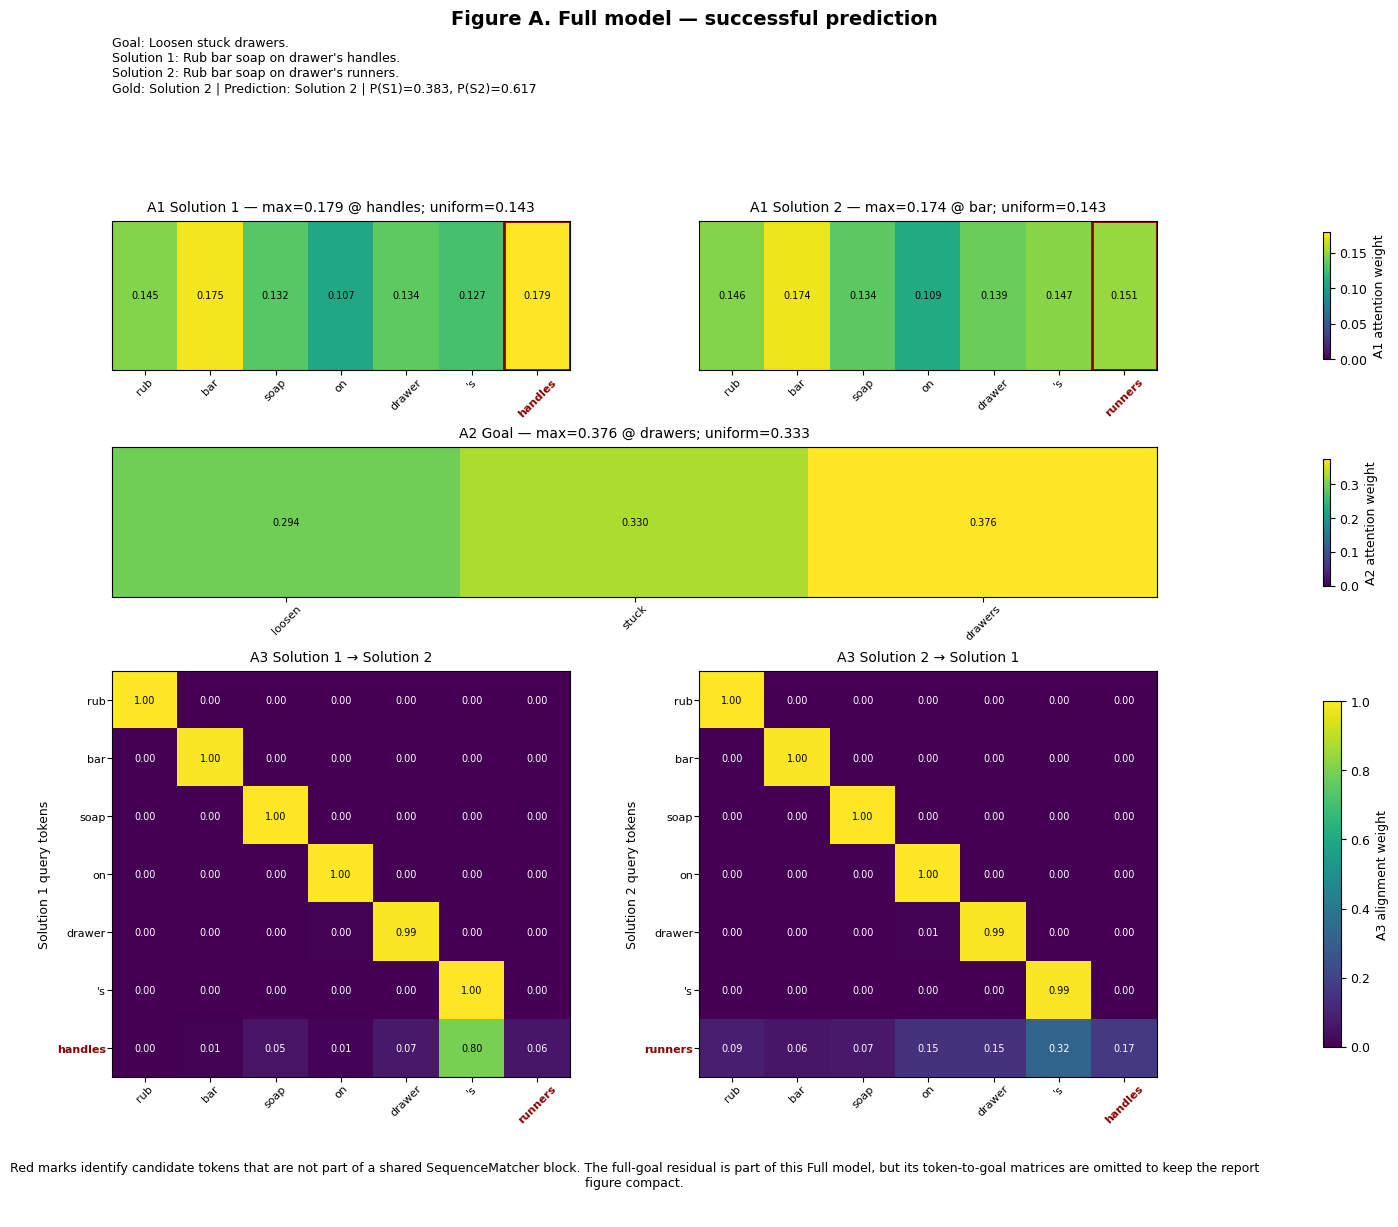

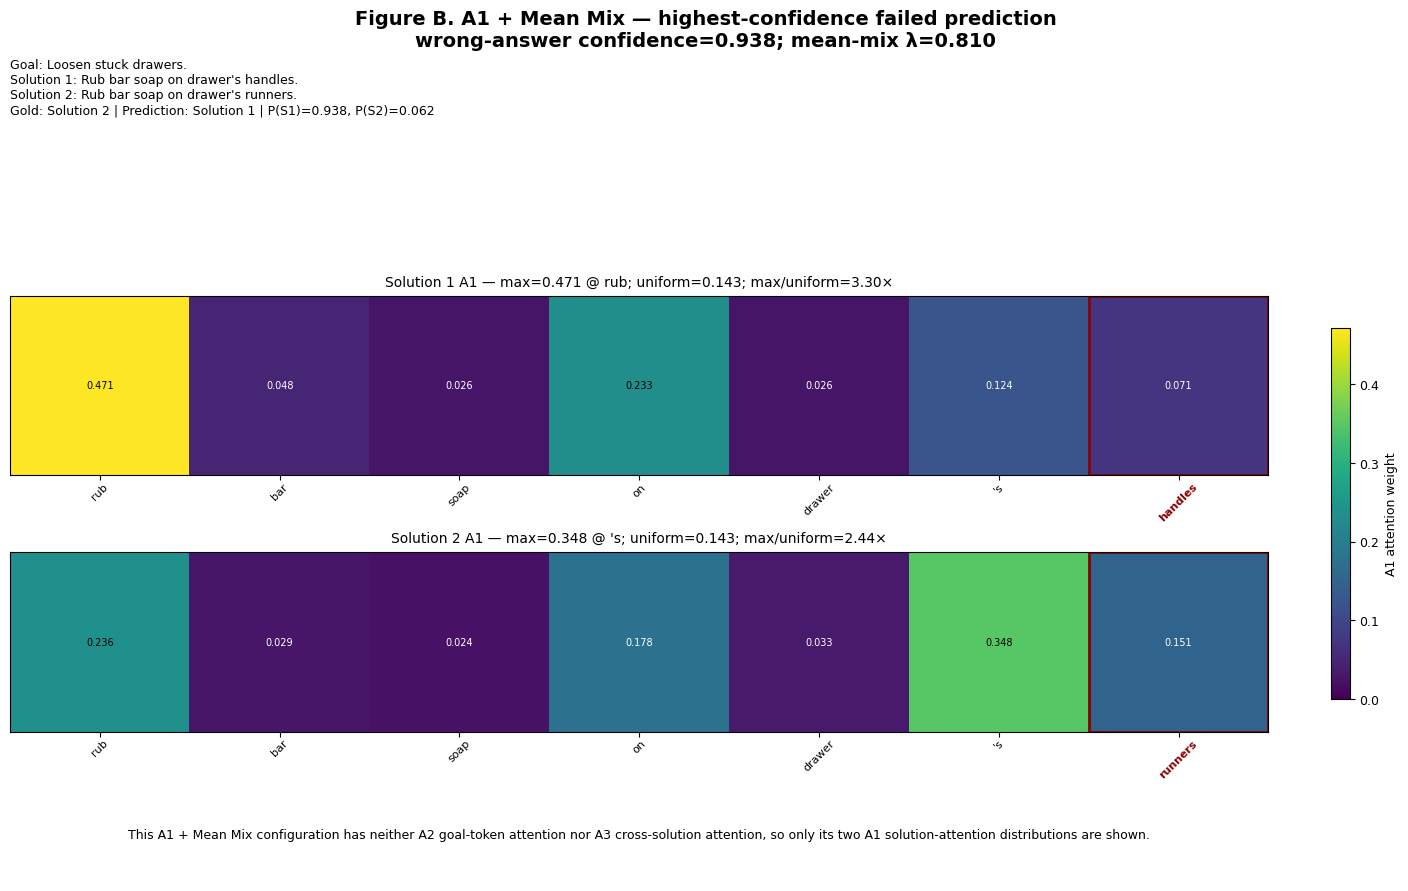

In [27]:
# @title Standalone report attention heat maps (Full success + A1 Mean Mix failure)

from collections import Counter
from difflib import SequenceMatcher
from pathlib import Path
import hashlib
import io
import json
import math
import os
import re
import textwrap
import zipfile

import gdown
import google.auth
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import torch
import torch.nn as nn
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from sklearn.model_selection import train_test_split


# -----------------------------------------------------------------------------
# Fixed report inputs
# -----------------------------------------------------------------------------

SEED = 0
SUCCESS_INDEX = 635
FAILURE_INDEX = 635
PIQA_DATA_FILE_ID = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
CACHE_DIR = Path("/content/report_attention_heatmaps")
DATA_DIR = CACHE_DIR / "piqa"
CHECKPOINT_DIR = CACHE_DIR / "checkpoints"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

FAILURE_CONFIG = "goal_guided_solution_attention_mean_mix"
FULL_CONFIG = "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention"

CHECKPOINT_SPECS = {
    "failure": {
        "experiment": "step15b",
        "configuration": FAILURE_CONFIG,
        "seed": SEED,
        "checkpoint_filename": "step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.pt",
        "json_filename": "step15b_20261014T135613Z_6607aab6_goal_guided_solution_attention_mean_mix_seed0.json",
    },
    "full": {
        "experiment": "step15e",
        "configuration": FULL_CONFIG,
        "seed": SEED,
        "checkpoint_filename": "step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention_seed0.pt",
        "json_filename": "step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention_seed0.json",
    },
}


# -----------------------------------------------------------------------------
# Exact Step 13B.5 / Step 13E.5 preprocessing
# -----------------------------------------------------------------------------

def ensure_piqa_data():
    filenames = (
        "train.jsonl",
        "train-labels.lst",
        "test.jsonl",
        "test-labels.lst",
    )
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    located = {name: next(iter(DATA_DIR.rglob(name)), None) for name in filenames}
    if any(path is None for path in located.values()):
        archive_path = DATA_DIR / "piqa_data.zip"
        downloaded = gdown.download(
            id=PIQA_DATA_FILE_ID,
            output=str(archive_path),
            quiet=True,
        )
        if downloaded is None or not archive_path.is_file():
            raise RuntimeError("PIQA data download failed.")
        try:
            with zipfile.ZipFile(archive_path) as archive:
                archive.extractall(DATA_DIR)
        except (OSError, zipfile.BadZipFile) as exc:
            raise RuntimeError("The downloaded PIQA archive is invalid.") from exc
        located = {name: next(iter(DATA_DIR.rglob(name)), None) for name in filenames}
    missing = [name for name, path in located.items() if path is None]
    if missing:
        raise RuntimeError("PIQA archive is missing: " + ", ".join(missing))
    return located


def clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()


def read_piqa(data_path, label_path):
    with open(data_path, encoding="utf-8") as data_file:
        data_lines = data_file.readlines()
    with open(label_path, encoding="utf-8") as label_file:
        label_lines = label_file.readlines()
    rows = []
    for line, label in zip(data_lines, label_lines):
        if label.strip():
            item = json.loads(line)
            rows.append({
                "goal": item["goal"],
                "sol1": item["sol1"],
                "sol2": item["sol2"],
                "label": int(label.strip()),
            })
    return rows


def build_vocabulary(rows, min_count=2):
    counts = Counter()
    for row in rows:
        counts += Counter(clean_str(row["goal"]).split())
        counts += Counter(clean_str(row["sol1"]).split())
        counts += Counter(clean_str(row["sol2"]).split())
    vocabulary = {"<pad>": 0, "<unk>": 1}
    for token, count in counts.most_common():
        if count >= min_count:
            vocabulary[token] = len(vocabulary)
    return vocabulary


def words_to_indices(words, vocabulary, maximum_length):
    result = np.zeros(maximum_length, dtype=np.int64)
    for position, word in enumerate(words[:maximum_length]):
        result[position] = vocabulary.get(word, 1)
    return result


def make_batch_input(rows, vocabulary, maxgoal=20, maxsol=60):
    size = len(rows)
    goals = np.zeros((size, maxgoal), dtype=np.int64)
    sol1 = np.zeros((size, maxsol), dtype=np.int64)
    sol2 = np.zeros((size, maxsol), dtype=np.int64)
    labels = np.zeros(size, dtype=np.int64)
    for index, row in enumerate(rows):
        goals[index] = words_to_indices(
            clean_str(row["goal"]).split(), vocabulary, maxgoal
        )
        sol1[index] = words_to_indices(
            clean_str(row["sol1"]).split(), vocabulary, maxsol
        )
        sol2[index] = words_to_indices(
            clean_str(row["sol2"]).split(), vocabulary, maxsol
        )
        labels[index] = row["label"]
    return goals, sol1, sol2, labels


piqa_paths = ensure_piqa_data()
all_rows = read_piqa(piqa_paths["train.jsonl"], piqa_paths["train-labels.lst"])
all_labels = [row["label"] for row in all_rows]
training_rows, validation_rows = train_test_split(
    all_rows,
    test_size=0.15,
    random_state=0,
    stratify=all_labels,
)
vocabulary = build_vocabulary(training_rows, min_count=2)
validation_input = make_batch_input(validation_rows, vocabulary, maxgoal=20, maxsol=60)
goal_array, sol1_array, sol2_array, label_array = validation_input
if not len(validation_rows) == 2417:
    raise RuntimeError(f"Expected 2,417 validation rows, found {len(validation_rows):,}.")
if not len(vocabulary) == 11488:
    raise RuntimeError(f"Expected vocabulary size 11,488, found {len(vocabulary):,}.")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# -----------------------------------------------------------------------------
# Exact checkpoint-compatible model definitions
# -----------------------------------------------------------------------------

def masked_pool(rnn_output, index, pooling="mean"):
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        return rnn_output.masked_fill(mask == 0, -1e9).max(dim=1)[0]
    return (rnn_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)


def attention_on_solution(solution_output, solution_index, query):
    if query.dim() == 1:
        score = torch.matmul(solution_output, query)
    else:
        score = torch.bmm(solution_output, query.unsqueeze(2)).squeeze(2)
    score = score.masked_fill(solution_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), solution_output).squeeze(1)
    return context, alpha


def attention_on_goal(goal_output, goal_index, query):
    score = torch.matmul(goal_output, query)
    score = score.masked_fill(goal_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), goal_output).squeeze(1)
    return context, alpha


class BaseModel(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        dimension=100,
        n_hidden_input=100,
        dropout_input=0.25,
        num_layers_input=1,
        rnn_type="LSTM",
        pooling="mean",
        attention_type="none",
        goal_attention=False,
        use_cross_attention=False,
        use_interaction=True,
        use_goal=True,
    ):
        super().__init__()
        self.pooling = pooling
        self.attention_type = attention_type
        self.goal_attention = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction = use_interaction
        self.use_goal = use_goal
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        encoder_class = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.encoder = encoder_class(
            dimension,
            n_hidden_input,
            num_layers=num_layers_input,
            batch_first=True,
            bidirectional=True,
            dropout=dropout_input if num_layers_input > 1 else 0,
        )
        self.W = nn.Linear(n_hidden_input * 2, n_hidden_input * 2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        score_width = n_hidden_input * 2 * (4 if use_interaction else 2)
        if use_cross_attention:
            score_width += n_hidden_input * 2
        self.hidden_layer = nn.Linear(score_width, n_hidden_input)
        self.score_layer = nn.Linear(n_hidden_input, 1)
        self.dropout = nn.Dropout(dropout_input)


class A1MeanMixModel(BaseModel):
    """Step 13B A1 + Mean Mix model (unscaled)."""

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 13B checkpoint requires attention_type='goal'.")
        if settings.get("use_cross_attention", False):
            raise ValueError("The selected failure checkpoint must not contain A3.")
        if settings.get("goal_attention", False):
            raise ValueError("The selected failure checkpoint must not contain A2.")
        if cross_difference_pooling is not None:
            raise ValueError("A1 + Mean Mix must not use cross-difference pooling.")
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.goal_mean_mix_logit = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    def score_one_solution(
        self,
        goal_vector,
        current_sol_output,
        current_sol_index,
        other_sol_output,
        other_sol_index,
    ):
        del other_sol_output, other_sol_index
        query = self.W(goal_vector)
        attended_context, alpha = attention_on_solution(
            current_sol_output, current_sol_index, query
        )
        mean_context = masked_pool(current_sol_output, current_sol_index, "mean")
        mix = self.goal_attention_lambda
        context = mix * attended_context + (1.0 - mix) * mean_context
        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1), alpha, None

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        goal_vector = masked_pool(goal_output, goal, self.pooling)
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        score1, alpha1, _ = self.score_one_solution(
            goal_vector, sol1_output, solution1, sol2_output, solution2
        )
        score2, alpha2, _ = self.score_one_solution(
            goal_vector, sol2_output, solution2, sol1_output, solution1
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": None,
            "sol1_align": None,
            "sol2_align": None,
        }


class FullGoalAttentionModel(BaseModel):
    """Step 13E full model: A1+A2+A3+mix+temperature+goal residual."""

    GOAL_CROSS_DIM = 64

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Step 13E checkpoint requires attention_type='goal'.")
        if not settings.get("goal_attention", False):
            raise ValueError("The selected full checkpoint must contain A2.")
        if not settings.get("use_cross_attention", False):
            raise ValueError("The selected full checkpoint must contain A3.")
        if cross_difference_pooling != "masked_mean_max":
            raise ValueError("The selected full checkpoint requires masked_mean_max.")
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("The selected full checkpoint requires mean fallback pooling.")
        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_epsilon = 1e-6
        base_width = hidden_size * 2 * (4 if use_interaction else 2)
        self.hidden_layer = nn.Linear(base_width + hidden_size * 4, hidden_size)
        attention_dim = self.W.out_features
        initial_temperature = math.sqrt(attention_dim)
        initial_raw = math.log(math.expm1(initial_temperature))
        self.raw_attention_temperature = nn.Parameter(
            torch.tensor(initial_raw, dtype=self.W.weight.dtype)
        )
        self.goal_mean_mix_logit = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )
        if attention_dim != 200:
            raise ValueError("Step 13E checkpoint requires 200-dimensional BiLSTM states.")
        self.full_goal_attention_dim = self.GOAL_CROSS_DIM
        self.full_goal_query = nn.Linear(attention_dim, 64, bias=False)
        self.full_goal_key = nn.Linear(attention_dim, 64, bias=False)
        self.full_goal_value = nn.Linear(attention_dim, 64, bias=False)
        self.full_goal_output = nn.Linear(64, attention_dim, bias=False)
        self.goal_token_residual = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        return (
            torch.nn.functional.softplus(self.raw_attention_temperature)
            + self.temperature_epsilon
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    @property
    def goal_token_residual_scale(self):
        return torch.tanh(self.goal_token_residual)

    def enhance_solution_with_goal(
        self, raw_solution_output, solution_index, goal_output, goal_index
    ):
        query = self.full_goal_query(raw_solution_output)
        key = self.full_goal_key(goal_output)
        value = self.full_goal_value(goal_output)
        scores = torch.bmm(query, key.transpose(1, 2)) / math.sqrt(
            self.full_goal_attention_dim
        )
        goal_mask = goal_index.ne(0)
        solution_mask = solution_index.ne(0)
        scores = scores.masked_fill(
            ~goal_mask.unsqueeze(1), torch.finfo(scores.dtype).min
        )
        goal_alignment = torch.softmax(scores, dim=2)
        goal_alignment = goal_alignment * goal_mask.unsqueeze(1).to(scores.dtype)
        goal_alignment = goal_alignment * solution_mask.unsqueeze(2).to(scores.dtype)
        goal_context = torch.bmm(goal_alignment, value)
        projected_context = self.full_goal_output(goal_context)
        residual = self.goal_token_residual_scale * projected_context
        residual = residual.masked_fill(~solution_mask.unsqueeze(2), 0.0)
        return raw_solution_output + residual, goal_alignment

    def score_one_solution(
        self,
        goal_vector,
        a1_solution_output,
        raw_solution_output,
        current_sol_index,
        other_raw_solution_output,
        other_sol_index,
    ):
        query = self.W(goal_vector)
        score = torch.bmm(a1_solution_output, query.unsqueeze(2)).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(score.device, score.dtype)
        alpha = torch.softmax(score / temperature, dim=1)
        attended_context = torch.bmm(
            alpha.unsqueeze(1), a1_solution_output
        ).squeeze(1)
        mean_context = masked_pool(raw_solution_output, current_sol_index, "mean")
        mix = self.goal_attention_lambda
        context = mix * attended_context + (1.0 - mix) * mean_context
        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        similarity = torch.bmm(
            raw_solution_output, other_raw_solution_output.transpose(1, 2)
        )
        similarity = similarity.masked_fill(
            (other_sol_index == 0).unsqueeze(1), -1e9
        )
        align = torch.softmax(similarity, dim=2)
        aligned_other = torch.bmm(align, other_raw_solution_output)
        token_difference = raw_solution_output - aligned_other
        current_mask = current_sol_index.ne(0).unsqueeze(2)
        masked_difference = token_difference.masked_fill(~current_mask, 0.0)
        valid_count = current_mask.sum(dim=1).clamp(min=1).to(token_difference.dtype)
        mean_difference = masked_difference.sum(dim=1) / valid_count
        max_difference = token_difference.masked_fill(
            ~current_mask, torch.finfo(token_difference.dtype).min
        ).max(dim=1).values
        max_difference = torch.where(
            current_mask.any(dim=1), max_difference, torch.zeros_like(max_difference)
        )
        combined = torch.cat((combined, mean_difference, max_difference), dim=1)
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1), alpha, align

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        goal_vector, goal_alpha = attention_on_goal(
            goal_output, goal, self.goal_query
        )
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        sol1_a1_output, sol1_goal_alignment = self.enhance_solution_with_goal(
            sol1_output, solution1, goal_output, goal
        )
        sol2_a1_output, sol2_goal_alignment = self.enhance_solution_with_goal(
            sol2_output, solution2, goal_output, goal
        )
        score1, alpha1, align1 = self.score_one_solution(
            goal_vector,
            sol1_a1_output,
            sol1_output,
            solution1,
            sol2_output,
            solution2,
        )
        score2, alpha2, align2 = self.score_one_solution(
            goal_vector,
            sol2_a1_output,
            sol2_output,
            solution2,
            sol1_output,
            solution1,
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
            "sol1_goal_cross_alpha": sol1_goal_alignment,
            "sol2_goal_cross_alpha": sol2_goal_alignment,
        }


def build_failure_model(settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return A1MeanMixModel(
        len(vocabulary),
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


def build_full_model(settings):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    return FullGoalAttentionModel(
        len(vocabulary),
        cross_difference_pooling=difference_pooling,
        **model_settings,
    )


# -----------------------------------------------------------------------------
# Read-only Google Drive restore and verification
# -----------------------------------------------------------------------------

def list_drive_files(service):
    files = []
    page_token = None
    while True:
        response = service.files().list(
            q=f"'{DRIVE_FOLDER_ID}' in parents and trashed = false",
            spaces="drive",
            fields="nextPageToken,files(id,name,createdTime,size)",
            orderBy="createdTime desc",
            pageSize=1000,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        files.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            return files


def exact_drive_file(files, filename):
    matches = [item for item in files if item.get("name") == filename]
    if not matches:
        raise RuntimeError(f"Drive file not found: {filename}")
    return sorted(
        matches,
        key=lambda item: (item.get("createdTime", ""), item.get("id", "")),
        reverse=True,
    )[0]


def download_drive_bytes(service, file_id):
    buffer = io.BytesIO()
    request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
    downloader = MediaIoBaseDownload(buffer, request)
    finished = False
    while not finished:
        _, finished = downloader.next_chunk()
    return buffer.getvalue()


def sha256_file(path):
    with path.open("rb") as input_file:
        return hashlib.sha256(input_file.read()).hexdigest()


def download_verified_checkpoint(service, drive_file, expected_sha):
    filename = drive_file["name"]
    if Path(filename).name != filename:
        raise ValueError("Unsafe checkpoint filename.")
    destination = CHECKPOINT_DIR / filename
    if destination.is_file() and sha256_file(destination) == expected_sha:
        return destination
    temporary = destination.with_name(destination.name + ".part")
    try:
        request = service.files().get_media(
            fileId=drive_file["id"], supportsAllDrives=True
        )
        with temporary.open("wb") as output_file:
            downloader = MediaIoBaseDownload(output_file, request)
            finished = False
            while not finished:
                _, finished = downloader.next_chunk()
        actual_sha = sha256_file(temporary)
        if actual_sha != expected_sha:
            raise ValueError(
                f"SHA-256 mismatch for {filename}: expected {expected_sha}, got {actual_sha}."
            )
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()
    return destination


def torch_load(path, map_location):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)


def restore_model(service, drive_files, spec, model_builder):
    json_file = exact_drive_file(drive_files, spec["json_filename"])
    raw_json = download_drive_bytes(service, json_file["id"])
    record = json.loads(raw_json.decode("utf-8"))
    try:
        record_seed = int(record.get("seed", -1))
    except (TypeError, ValueError) as exc:
        raise ValueError("Checkpoint JSON has an invalid seed.") from exc
    expected_fields = {
        "experiment": spec["experiment"],
        "configuration": spec["configuration"],
        "seed": spec["seed"],
        "checkpoint_filename": spec["checkpoint_filename"],
    }
    actual_fields = {
        "experiment": record.get("experiment"),
        "configuration": record.get("configuration"),
        "seed": record_seed,
        "checkpoint_filename": record.get("checkpoint_filename"),
    }
    if actual_fields != expected_fields:
        raise ValueError(
            f"Checkpoint JSON metadata mismatch. Expected {expected_fields}, got {actual_fields}."
        )
    expected_sha = record.get("checkpoint_sha256")
    if not isinstance(expected_sha, str) or re.fullmatch(r"[0-9a-fA-F]{64}", expected_sha) is None:
        raise ValueError("Checkpoint JSON is missing a valid SHA-256.")
    expected_sha = expected_sha.lower()
    settings = record.get("settings")
    if not isinstance(settings, dict):
        raise ValueError("Checkpoint JSON is missing model settings.")
    checkpoint_file = exact_drive_file(drive_files, spec["checkpoint_filename"])
    checkpoint_path = download_verified_checkpoint(
        service, checkpoint_file, expected_sha
    )
    payload = torch_load(checkpoint_path, map_location=device)
    if spec["experiment"] == "step15b":
        if not isinstance(payload, dict):
            raise ValueError("Step 13B checkpoint is not a state_dict.")
        state_dict = payload
    else:
        if not isinstance(payload, dict) or payload.get("format") != "step15e_full_goal_attention_v1":
            raise ValueError("Step 13E checkpoint has an unexpected format.")
        state_dict = payload.get("model_state_dict")
        metadata = payload.get("experiment_metadata")
        if not isinstance(state_dict, dict) or not isinstance(metadata, dict):
            raise ValueError("Step 13E checkpoint is missing state or metadata.")
        if metadata.get("configuration") != spec["configuration"]:
            raise ValueError("Step 13E checkpoint/JSON configuration mismatch.")
        if int(metadata.get("seed", -1)) != spec["seed"]:
            raise ValueError("Step 13E checkpoint/JSON seed mismatch.")
        if metadata.get("checkpoint") != spec["checkpoint_filename"]:
            raise ValueError("Step 13E checkpoint filename metadata mismatch.")
    model = model_builder(settings).to(device)
    model.load_state_dict(state_dict, strict=True)
    model.eval()
    return model, record, checkpoint_path


auth.authenticate_user()
credentials, _ = google.auth.default()
drive_service = build(
    "drive", "v3", credentials=credentials, cache_discovery=False
)
drive_files = list_drive_files(drive_service)
failure_model, failure_record, failure_checkpoint = restore_model(
    drive_service,
    drive_files,
    CHECKPOINT_SPECS["failure"],
    build_failure_model,
)
full_model, full_record, full_checkpoint = restore_model(
    drive_service,
    drive_files,
    CHECKPOINT_SPECS["full"],
    build_full_model,
)


# -----------------------------------------------------------------------------
# Deterministic example selection and attention extraction
# -----------------------------------------------------------------------------

def predict_validation(model, batch_size=128):
    probability_batches = []
    with torch.no_grad():
        for start in range(0, len(label_array), batch_size):
            stop = min(start + batch_size, len(label_array))
            goal = torch.as_tensor(
                goal_array[start:stop], dtype=torch.long, device=device
            )
            sol1 = torch.as_tensor(
                sol1_array[start:stop], dtype=torch.long, device=device
            )
            sol2 = torch.as_tensor(
                sol2_array[start:stop], dtype=torch.long, device=device
            )
            logits, _ = model(goal, sol1, sol2)
            probability_batches.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(probability_batches, axis=0)


def choose_failure_index(probabilities, labels):
    probabilities = np.asarray(probabilities)
    labels = np.asarray(labels)
    predictions = probabilities.argmax(axis=1)
    wrong_indices = np.flatnonzero(predictions != labels)
    if wrong_indices.size == 0:
        raise RuntimeError("The A1 + Mean Mix model made no validation errors.")
    wrong_confidences = probabilities[wrong_indices, predictions[wrong_indices]]
    ranked = np.lexsort((wrong_indices, -wrong_confidences))



def extract_sample(model, sample_index):
    sample_slice = slice(sample_index, sample_index + 1)
    goal = torch.as_tensor(
        goal_array[sample_slice], dtype=torch.long, device=device
    )
    sol1 = torch.as_tensor(
        sol1_array[sample_slice], dtype=torch.long, device=device
    )
    sol2 = torch.as_tensor(
        sol2_array[sample_slice], dtype=torch.long, device=device
    )
    with torch.no_grad():
        logits, attention = model(goal, sol1, sol2)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
    return probabilities, {
        key: None if value is None else value[0].detach().cpu().numpy()
        for key, value in attention.items()
    }


failure_probabilities_all = predict_validation(failure_model)
failure_predictions_all = failure_probabilities_all.argmax(axis=1)
failure_index = FAILURE_INDEX
temprank =  choose_failure_index(failure_probabilities_all, label_array)
#choose_failure_index(failure_probabilities_all, label_array)
failure_wrong_indices = np.flatnonzero(failure_predictions_all != label_array)
# Add these two lines
failure_wrong_confidences = failure_probabilities_all[
    failure_wrong_indices, failure_predictions_all[failure_wrong_indices]
]
failure_confidence = float(
    failure_probabilities_all[failure_index, failure_predictions_all[failure_index]]
)
if failure_predictions_all[failure_index] == label_array[failure_index]:
    raise RuntimeError("Deterministic failure selection returned a correct example.")
# if not failure_confidence == float(np.max(failure_wrong_confidences)):
#     raise RuntimeError("Selected failure is not the highest-confidence error.")
ties = failure_wrong_indices[failure_wrong_confidences == failure_confidence]
# if failure_index != int(np.min(ties)):
#     raise RuntimeError("Failure tie-breaking did not choose the lowest validation index.")

full_probabilities, full_attention_raw = extract_sample(full_model, SUCCESS_INDEX)
failure_probabilities, failure_attention_raw = extract_sample(
    failure_model, failure_index
)
if not np.allclose(
    failure_probabilities,
    failure_probabilities_all[failure_index],
    rtol=0.0,
    atol=1e-6,
):
    raise RuntimeError("Selected failure probabilities changed during re-extraction.")
full_prediction = int(np.argmax(full_probabilities))
full_gold = int(label_array[SUCCESS_INDEX])
failure_prediction = int(np.argmax(failure_probabilities))
failure_gold = int(label_array[failure_index])
if full_prediction != full_gold:
    raise RuntimeError(
        "Validation row 16 is expected to have gold=Solution 1 and prediction=Solution 1."
    )
if failure_prediction == failure_gold:
    raise RuntimeError("The selected A1 + Mean Mix example is not a failure.")


def visible_tokens(text, index_row):
    token_count = int(np.count_nonzero(index_row))
    return clean_str(text).split()[:token_count]


def different_token_indices(left_tokens, right_tokens):
    left_different = set()
    right_different = set()
    matcher = SequenceMatcher(a=left_tokens, b=right_tokens, autojunk=False)
    for tag, left_start, left_stop, right_start, right_stop in matcher.get_opcodes():
        if tag != "equal":
            left_different |= set(range(left_start, left_stop))
            right_different |= set(range(right_start, right_stop))
    return left_different, right_different


def tokens_for_row(index):
    row = validation_rows[index]
    return (
        visible_tokens(row["goal"], goal_array[index]),
        visible_tokens(row["sol1"], sol1_array[index]),
        visible_tokens(row["sol2"], sol2_array[index]),
    )


full_goal_tokens, full_sol1_tokens, full_sol2_tokens = tokens_for_row(SUCCESS_INDEX)
failure_goal_tokens, failure_sol1_tokens, failure_sol2_tokens = tokens_for_row(
    failure_index
)
full_sol1_different, full_sol2_different = different_token_indices(
    full_sol1_tokens, full_sol2_tokens
)
failure_sol1_different, failure_sol2_different = different_token_indices(
    failure_sol1_tokens, failure_sol2_tokens
)


def crop_attention(raw_attention, goal_tokens, sol1_tokens, sol2_tokens):
    goal_count = len(goal_tokens)
    sol1_count = len(sol1_tokens)
    sol2_count = len(sol2_tokens)
    return {
        "sol1_alpha": raw_attention["sol1_alpha"][:sol1_count],
        "sol2_alpha": raw_attention["sol2_alpha"][:sol2_count],
        "goal_alpha": (
            None
            if raw_attention["goal_alpha"] is None
            else raw_attention["goal_alpha"][:goal_count]
        ),
        "sol1_align": (
            None
            if raw_attention["sol1_align"] is None
            else raw_attention["sol1_align"][:sol1_count, :sol2_count]
        ),
        "sol2_align": (
            None
            if raw_attention["sol2_align"] is None
            else raw_attention["sol2_align"][:sol2_count, :sol1_count]
        ),
    }


full_attention = crop_attention(
    full_attention_raw, full_goal_tokens, full_sol1_tokens, full_sol2_tokens
)
failure_attention = crop_attention(
    failure_attention_raw,
    failure_goal_tokens,
    failure_sol1_tokens,
    failure_sol2_tokens,
)


def assert_distribution(name, values):
    values = np.asarray(values)
    if values.size == 0 or not np.all(np.isfinite(values)):
        raise RuntimeError(f"{name} is empty or non-finite.")
    if not np.isclose(values.sum(), 1.0, atol=1e-6):
        raise RuntimeError(f"{name} does not sum to one.")


for name in ("sol1_alpha", "sol2_alpha", "goal_alpha"):
    assert_distribution(f"Full {name}", full_attention[name])
for name in ("sol1_alpha", "sol2_alpha"):
    assert_distribution(f"A1 + Mean Mix {name}", failure_attention[name])
for name in ("sol1_align", "sol2_align"):
    matrix = full_attention[name]
    if matrix.ndim != 2 or not np.allclose(matrix.sum(axis=1), 1.0, atol=1e-6):
        raise RuntimeError(f"Full {name} rows do not sum to one.")
if full_attention["sol1_align"].shape != (
    len(full_sol1_tokens), len(full_sol2_tokens)
):
    raise RuntimeError("A3 Solution 1→2 matrix still contains padding.")
if full_attention["sol2_align"].shape != (
    len(full_sol2_tokens), len(full_sol1_tokens)
):
    raise RuntimeError("A3 Solution 2→1 matrix still contains padding.")

failure_lambda = float(failure_model.goal_attention_lambda.detach().cpu())


def print_case_metadata(label, configuration, checkpoint, index, probabilities, prediction):
    row = validation_rows[index]
    gold = int(label_array[index])
    print(f"=== {label} ===")
    print(f"Configuration    : {configuration}")
    print(f"Seed             : {SEED}")
    print(f"Checkpoint       : {checkpoint.name}")
    print(f"Validation index : {index}")
    print(f"Goal             : {row['goal']}")
    print(f"Solution 1       : {row['sol1']}")
    print(f"Solution 2       : {row['sol2']}")
    print(f"Gold             : Solution {gold + 1}")
    print(f"Prediction       : Solution {prediction + 1}")
    print(f"Probabilities    : P(S1)={probabilities[0]:.6f}, P(S2)={probabilities[1]:.6f}")


print_case_metadata(
    "Figure A — successful prediction",
    FULL_CONFIG,
    full_checkpoint,
    SUCCESS_INDEX,
    full_probabilities,
    full_prediction,
)
print()
print_case_metadata(
    "Figure B — failed prediction",
    FAILURE_CONFIG,
    failure_checkpoint,
    failure_index,
    failure_probabilities,
    failure_prediction,
)
print(f"Mean-mix lambda  : {failure_lambda:.6f}")


# -----------------------------------------------------------------------------
# Shared report plotting helpers
# -----------------------------------------------------------------------------

REPORT_BASE_FONT_SIZE = 12
REPORT_SUBPLOT_TITLE_SIZE = 14
REPORT_FIGURE_TITLE_SIZE = 18
REPORT_TICK_FONT_SIZE = 12
REPORT_CELL_FONT_SIZE = 11
REPORT_COLORBAR_TICK_SIZE = 11

plt.rcParams["font.size"] = REPORT_BASE_FONT_SIZE
plt.rcParams["axes.titlesize"] = REPORT_SUBPLOT_TITLE_SIZE
plt.rcParams["axes.labelsize"] = REPORT_BASE_FONT_SIZE
plt.rcParams["figure.titlesize"] = REPORT_FIGURE_TITLE_SIZE
DIFFERENCE_COLOR = "#8B0000"


def maximum_summary(values, tokens):
    index = int(np.argmax(values))
    maximum = float(values[index])
    uniform = 1.0 / len(tokens)
    return maximum, tokens[index], uniform


def mark_token_differences(ax, x_indices=(), y_indices=()):
    for token_index in x_indices:
        ax.add_patch(Rectangle(
            (token_index - 0.5, -0.5),
            1.0,
            1.0,
            fill=False,
            edgecolor=DIFFERENCE_COLOR,
            linewidth=2.0,
        ))
    for token_index, label in enumerate(ax.get_xticklabels()):
        if token_index in x_indices:
            label.set_color(DIFFERENCE_COLOR)
            label.set_fontweight("bold")
    for token_index, label in enumerate(ax.get_yticklabels()):
        if token_index in y_indices:
            label.set_color(DIFFERENCE_COLOR)
            label.set_fontweight("bold")


def draw_token_heatmap(
    ax,
    values,
    tokens,
    title,
    vmax,
    difference_indices=(),
):
    values = np.asarray(values, dtype=float)
    image = ax.imshow(
        values[None, :],
        cmap="viridis",
        vmin=0.0,
        vmax=vmax,
        aspect="auto",
    )
    ax.set_xticks(np.arange(len(tokens)), labels=tokens)
    ax.set_yticks([])
    ax.tick_params(axis="x", labelrotation=45, labelsize=REPORT_TICK_FONT_SIZE, pad=2)
    ax.set_title(title, pad=8, fontsize=REPORT_SUBPLOT_TITLE_SIZE)
    for column, value in enumerate(values):
        color = "white" if value < vmax * 0.45 else "black"
        ax.text(
            column, 0, f"{value:.2f}", ha="center", va="center",
            color=color, fontsize=REPORT_CELL_FONT_SIZE,
        )
    mark_token_differences(ax, set(difference_indices), set())
    return image


def draw_matrix_heatmap(
    ax,
    values,
    x_tokens,
    y_tokens,
    title,
    different_x,
    different_y,
):
    values = np.asarray(values, dtype=float)
    image = ax.imshow(
        values,
        cmap="viridis",
        vmin=0.0,
        vmax=1.0,
        aspect="auto",
    )
    ax.set_xticks(np.arange(len(x_tokens)), labels=x_tokens)
    ax.set_yticks(np.arange(len(y_tokens)), labels=y_tokens)
    ax.tick_params(axis="x", labelrotation=45, labelsize=REPORT_TICK_FONT_SIZE, pad=2)
    ax.tick_params(axis="y", labelrotation=0, labelsize=REPORT_TICK_FONT_SIZE, pad=2)
    ax.set_title(title, pad=8, fontsize=REPORT_SUBPLOT_TITLE_SIZE)
    if values.size <= 120:
        for row in range(values.shape[0]):
            for column in range(values.shape[1]):
                value = values[row, column]
                color = "white" if value < 0.45 else "black"
                ax.text(
                    column,
                    row,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    color=color,
                    fontsize=REPORT_CELL_FONT_SIZE,
                )
    for index, label in enumerate(ax.get_xticklabels()):
        if index in different_x:
            label.set_color(DIFFERENCE_COLOR)
            label.set_fontweight("bold")
    for index, label in enumerate(ax.get_yticklabels()):
        if index in different_y:
            label.set_color(DIFFERENCE_COLOR)
            label.set_fontweight("bold")
    return image


def wrapped_case_text(row, gold, prediction, probabilities, width=112):
    lines = [
        "Goal: " + row["goal"],
        "Solution 1: " + row["sol1"],
        "Solution 2: " + row["sol2"],
        (
            f"Gold: Solution {gold + 1} | Prediction: Solution {prediction + 1} | "
            f"P(S1)={probabilities[0]:.3f}, P(S2)={probabilities[1]:.3f}"
        ),
    ]
    return "\n".join(textwrap.fill(line, width=width) for line in lines)


def add_report_colorbar(figure, image, axes, label):
    colorbar = figure.colorbar(image, ax=axes, shrink=0.82, pad=0.025)
    colorbar.set_label(label, fontsize=REPORT_BASE_FONT_SIZE)
    colorbar.ax.tick_params(labelsize=REPORT_COLORBAR_TICK_SIZE)
    return colorbar


# Figure A: Full model successful prediction.
success_max_tokens = max(
    len(full_goal_tokens), len(full_sol1_tokens), len(full_sol2_tokens)
)
success_width = max(10.5, min(18.0, 7.0 + 0.50 * success_max_tokens))
success_height = max(
    9.2,
    min(14.0, 7.4 + 0.26 * max(len(full_sol1_tokens), len(full_sol2_tokens))),
)
success_figure = plt.figure(
    figsize=(success_width, success_height), dpi=150, constrained_layout=True
)
success_grid = success_figure.add_gridspec(
    5, 2, height_ratios=(1.3, 1.25, 1.25, 3.4, 0.7)
)
success_info_ax = success_figure.add_subplot(success_grid[0, :])
success_a1_sol1_ax = success_figure.add_subplot(success_grid[1, 0])
success_a1_sol2_ax = success_figure.add_subplot(success_grid[1, 1])
success_a2_ax = success_figure.add_subplot(success_grid[2, :])
success_a3_12_ax = success_figure.add_subplot(success_grid[3, 0])
success_a3_21_ax = success_figure.add_subplot(success_grid[3, 1])
success_caption_ax = success_figure.add_subplot(success_grid[4, :])

success_figure.suptitle(
    "Figure A. Full model — successful prediction",
    fontweight="bold",
    fontsize=REPORT_FIGURE_TITLE_SIZE,
)
success_info_ax.axis("off")
success_info_ax.text(
    0.0,
    1.0,
    wrapped_case_text(
        validation_rows[SUCCESS_INDEX],
        full_gold,
        full_prediction,
        full_probabilities,
    ),
    ha="left",
    va="top",
)

success_a1_max = max(
    float(np.max(full_attention["sol1_alpha"])),
    float(np.max(full_attention["sol2_alpha"])),
)
sol1_max, sol1_max_token, sol1_uniform = maximum_summary(
    full_attention["sol1_alpha"], full_sol1_tokens
)
sol2_max, sol2_max_token, sol2_uniform = maximum_summary(
    full_attention["sol2_alpha"], full_sol2_tokens
)
success_a1_image = draw_token_heatmap(
    success_a1_sol1_ax,
    full_attention["sol1_alpha"],
    full_sol1_tokens,
    f"A1 Solution 1 — max={sol1_max:.3f} @ {sol1_max_token}\nuniform={sol1_uniform:.3f}",
    success_a1_max,
    full_sol1_different,
)
draw_token_heatmap(
    success_a1_sol2_ax,
    full_attention["sol2_alpha"],
    full_sol2_tokens,
    f"A1 Solution 2 — max={sol2_max:.3f} @ {sol2_max_token}\nuniform={sol2_uniform:.3f}",
    success_a1_max,
    full_sol2_different,
)
add_report_colorbar(
    success_figure,
    success_a1_image,
    [success_a1_sol1_ax, success_a1_sol2_ax],
    "A1 attention weight",
)

goal_max, goal_max_token, goal_uniform = maximum_summary(
    full_attention["goal_alpha"], full_goal_tokens
)
success_a2_image = draw_token_heatmap(
    success_a2_ax,
    full_attention["goal_alpha"],
    full_goal_tokens,
    f"A2 Goal — max={goal_max:.3f} @ {goal_max_token}; uniform={goal_uniform:.3f}",
    goal_max,
)
add_report_colorbar(
    success_figure,
    success_a2_image,
    success_a2_ax,
    "A2 attention weight",
)

success_a3_image = draw_matrix_heatmap(
    success_a3_12_ax,
    full_attention["sol1_align"],
    full_sol2_tokens,
    full_sol1_tokens,
    "A3 Solution 1 → Solution 2",
    full_sol2_different,
    full_sol1_different,
)
draw_matrix_heatmap(
    success_a3_21_ax,
    full_attention["sol2_align"],
    full_sol1_tokens,
    full_sol2_tokens,
    "A3 Solution 2 → Solution 1",
    full_sol1_different,
    full_sol2_different,
)
success_a3_12_ax.set_ylabel("Solution 1 query tokens")
success_a3_21_ax.set_ylabel("Solution 2 query tokens")
add_report_colorbar(
    success_figure,
    success_a3_image,
    [success_a3_12_ax, success_a3_21_ax],
    "A3 alignment weight",
)
success_caption_ax.axis("off")
success_caption_ax.text(
    0.5,
    0.5,
    "Red marks identify candidate tokens that are not part of a shared SequenceMatcher block. "
    "The full-goal residual is part of this Full model, but its token-to-goal matrices are omitted "
    "to keep the report figure compact.",
    ha="center",
    va="center",
    wrap=True,
)


# Figure B: A1 + Mean Mix highest-confidence failed prediction.
failure_max_tokens = max(len(failure_sol1_tokens), len(failure_sol2_tokens))
failure_width = max(10.5, min(18.0, 7.0 + 0.50 * failure_max_tokens))
failure_figure = plt.figure(
    figsize=(failure_width, 7.2), dpi=150, constrained_layout=True
)
failure_grid = failure_figure.add_gridspec(
    4, 1, height_ratios=(1.45, 1.25, 1.25, 0.65)
)
failure_info_ax = failure_figure.add_subplot(failure_grid[0])
failure_sol1_ax = failure_figure.add_subplot(failure_grid[1])
failure_sol2_ax = failure_figure.add_subplot(failure_grid[2])
failure_caption_ax = failure_figure.add_subplot(failure_grid[3])

failure_figure.suptitle(
    "Figure B. A1 + Mean Mix — highest-confidence failed prediction\n"
    f"wrong-answer confidence={failure_confidence:.3f}; mean-mix λ={failure_lambda:.3f}",
    fontweight="bold",
    fontsize=REPORT_FIGURE_TITLE_SIZE,
)
failure_info_ax.axis("off")
failure_info_ax.text(
    0.0,
    1.0,
    wrapped_case_text(
        validation_rows[failure_index],
        failure_gold,
        failure_prediction,
        failure_probabilities,
    ),
    ha="left",
    va="top",
)

failure_a1_max = max(
    float(np.max(failure_attention["sol1_alpha"])),
    float(np.max(failure_attention["sol2_alpha"])),
)
failure_sol1_max, failure_sol1_token, failure_sol1_uniform = maximum_summary(
    failure_attention["sol1_alpha"], failure_sol1_tokens
)
failure_sol2_max, failure_sol2_token, failure_sol2_uniform = maximum_summary(
    failure_attention["sol2_alpha"], failure_sol2_tokens
)
failure_image = draw_token_heatmap(
    failure_sol1_ax,
    failure_attention["sol1_alpha"],
    failure_sol1_tokens,
    (
        f"Solution 1 A1 — max={failure_sol1_max:.3f} @ {failure_sol1_token}; "
        f"uniform={failure_sol1_uniform:.3f}; max/uniform={failure_sol1_max / failure_sol1_uniform:.2f}×"
    ),
    failure_a1_max,
    failure_sol1_different,
)
draw_token_heatmap(
    failure_sol2_ax,
    failure_attention["sol2_alpha"],
    failure_sol2_tokens,
    (
        f"Solution 2 A1 — max={failure_sol2_max:.3f} @ {failure_sol2_token}; "
        f"uniform={failure_sol2_uniform:.3f}; max/uniform={failure_sol2_max / failure_sol2_uniform:.2f}×"
    ),
    failure_a1_max,
    failure_sol2_different,
)
add_report_colorbar(
    failure_figure,
    failure_image,
    [failure_sol1_ax, failure_sol2_ax],
    "A1 attention weight",
)
failure_caption_ax.axis("off")
failure_caption_ax.text(
    0.5,
    0.5,
    "This A1 + Mean Mix configuration has neither A2 goal-token attention nor A3 cross-solution "
    "attention, so only its two A1 solution-attention distributions are shown.",
    ha="center",
    va="center",
    wrap=True,
)

plt.show()


In [29]:
# @title [RUN ONCE] Step 14: Test-set evaluation: No attention vs Full model

# Fresh-runtime evaluation cell. It restores six fixed report checkpoints from
# Google Drive and evaluates them on all 1,838 labelled PIQA test examples.
# It never trains, updates parameters, or writes to Google Drive.

from collections import Counter, defaultdict
from pathlib import Path
import hashlib
import io
import json
import math
import os
import re
import zipfile

import gdown
import google.auth
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from sklearn.model_selection import train_test_split


# -----------------------------------------------------------------------------
# Fixed report inputs
# -----------------------------------------------------------------------------

TEST_EVAL_SEEDS = (0, 1, 2)
TEST_EVAL_NO_ATTENTION_RUN_ID = "20261014T125621Z_e5d231e1"
TEST_EVAL_FULL_RUN_ID = "20261015T042116Z_d9f514ea"
TEST_EVAL_NO_ATTENTION_CONFIG = "no_attention"
TEST_EVAL_FULL_CONFIG = (
    "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_"
    "learned_temperature_full_goal_attention"
)
TEST_EVAL_DRIVE_FOLDER_ID = "1eVVJJ4aybeezxTQPTTfPI9jeYpPh8-N0"
TEST_EVAL_PIQA_DATA_FILE_ID = "1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5"
TEST_EVAL_DATA_DIR = Path("/content/piqa_test_evaluation_data")
TEST_EVAL_DOWNLOAD_DIR = Path("/content/piqa_test_evaluation_checkpoints")
TEST_EVAL_BATCH_SIZE = 128


def test_eval_checkpoint_filenames(model_key, seed):
    """Return the fixed report JSON/checkpoint filenames for one model and seed."""
    seed = int(seed)
    if seed not in (0, 1, 2):
        raise ValueError("seed must be one of 0, 1, 2")
    if model_key == "no_attention":
        stem = (
            "attention_ablation_20261014T125621Z_e5d231e1_"
            f"no_attention_seed{seed}"
        )
    elif model_key == "full_model":
        stem = (
            "step15e_20261015T042116Z_d9f514ea_"
            "goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_"
            f"learned_temperature_full_goal_attention_seed{seed}"
        )
    else:
        raise ValueError(f"Unknown model key: {model_key!r}")
    return stem + ".json", stem + ".pt"


# -----------------------------------------------------------------------------
# Exact data restoration: vocabulary from train-part-1, evaluation on test only
# -----------------------------------------------------------------------------

TEST_EVAL_PIQA_FILENAMES = (
    "train.jsonl",
    "train-labels.lst",
    "test.jsonl",
    "test-labels.lst",
)


def test_eval_ensure_piqa_data():
    TEST_EVAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
    located = {
        name: next(iter(TEST_EVAL_DATA_DIR.rglob(name)), None)
        for name in TEST_EVAL_PIQA_FILENAMES
    }
    if any(path is None for path in located.values()):
        archive_path = TEST_EVAL_DATA_DIR / "piqa_data.zip"
        downloaded_path = gdown.download(
            id=TEST_EVAL_PIQA_DATA_FILE_ID,
            output=str(archive_path),
            quiet=False,
        )
        if downloaded_path is None or not archive_path.is_file():
            raise RuntimeError("PIQA data download failed.")
        try:
            with zipfile.ZipFile(archive_path) as archive:
                archive.extractall(TEST_EVAL_DATA_DIR)
        except (OSError, zipfile.BadZipFile) as exc:
            raise RuntimeError("The downloaded PIQA archive is invalid.") from exc
        located = {
            name: next(iter(TEST_EVAL_DATA_DIR.rglob(name)), None)
            for name in TEST_EVAL_PIQA_FILENAMES
        }
    missing = [name for name, path in located.items() if path is None]
    if missing:
        raise RuntimeError("PIQA archive is missing: " + ", ".join(missing))
    return located


def test_eval_clean_str(string):
    string = re.sub(r"[^A-Za-z0-9,!?\']", " ", string)
    string = re.sub(r"\'s", " \'s", string)
    string = re.sub(r"\'ve", " \'ve", string)
    string = re.sub(r"n\'t", " n\'t", string)
    string = re.sub(r"\'re", " \'re", string)
    string = re.sub(r"\'d", " \'d", string)
    string = re.sub(r"\'ll", " \'ll", string)
    string = re.sub(r",", " , ", string)
    string = re.sub(r"!", " ! ", string)
    string = re.sub(r"\s{2,}", " ", string)
    return string.strip().lower()


def test_eval_read_piqa(data_path, label_path):
    with open(data_path, encoding="utf-8") as data_file:
        data_lines = data_file.readlines()
    with open(label_path, encoding="utf-8") as label_file:
        label_lines = label_file.readlines()
    if len(data_lines) != len(label_lines):
        raise ValueError(
            f"PIQA text/label length mismatch: {len(data_lines)} vs {len(label_lines)}"
        )
    rows = []
    for line, label in zip(data_lines, label_lines):
        if not label.strip():
            continue
        item = json.loads(line)
        numeric_label = int(label.strip())
        if numeric_label not in (0, 1):
            raise ValueError(f"Unexpected PIQA label: {numeric_label}")
        rows.append({
            "goal": item["goal"],
            "sol1": item["sol1"],
            "sol2": item["sol2"],
            "label": numeric_label,
        })
    return rows


def test_eval_build_vocabulary(rows, min_count=2):
    counts = Counter()
    for row in rows:
        counts += Counter(test_eval_clean_str(row["goal"]).split())
        counts += Counter(test_eval_clean_str(row["sol1"]).split())
        counts += Counter(test_eval_clean_str(row["sol2"]).split())
    vocabulary = {"<pad>": 0, "<unk>": 1}
    for token, count in counts.most_common():
        if count >= min_count:
            vocabulary[token] = len(vocabulary)
    return vocabulary


def test_eval_words_to_indices(words, vocabulary, maximum_length):
    result = np.zeros(maximum_length, dtype=np.int64)
    for position, word in enumerate(words[:maximum_length]):
        result[position] = vocabulary.get(word, 1)
    return result


def test_eval_make_batch_input(rows, vocabulary, maxgoal=20, maxsol=60):
    size = len(rows)
    goals = np.zeros((size, maxgoal), dtype=np.int64)
    sol1 = np.zeros((size, maxsol), dtype=np.int64)
    sol2 = np.zeros((size, maxsol), dtype=np.int64)
    labels = np.zeros(size, dtype=np.int64)
    for index, row in enumerate(rows):
        goals[index] = test_eval_words_to_indices(
            test_eval_clean_str(row["goal"]).split(), vocabulary, maxgoal
        )
        sol1[index] = test_eval_words_to_indices(
            test_eval_clean_str(row["sol1"]).split(), vocabulary, maxsol
        )
        sol2[index] = test_eval_words_to_indices(
            test_eval_clean_str(row["sol2"]).split(), vocabulary, maxsol
        )
        labels[index] = row["label"]
    return goals, sol1, sol2, labels


def test_eval_restore_test_input():
    paths = test_eval_ensure_piqa_data()
    all_train_rows = test_eval_read_piqa(
        paths["train.jsonl"], paths["train-labels.lst"]
    )
    all_train_labels = [row["label"] for row in all_train_rows]
    training_rows, validation_rows = train_test_split(
        all_train_rows,
        test_size=0.15,
        random_state=0,
        stratify=all_train_labels,
    )
    vocabulary = test_eval_build_vocabulary(training_rows, min_count=2)
    test_rows = test_eval_read_piqa(
        paths["test.jsonl"], paths["test-labels.lst"]
    )
    if len(training_rows) != 13696 or len(validation_rows) != 2417:
        raise RuntimeError(
            "Unexpected PIQA train/validation split: "
            f"{len(training_rows):,}/{len(validation_rows):,}."
        )
    if len(vocabulary) != 11488:
        raise RuntimeError(
            f"Expected vocabulary size 11,488, found {len(vocabulary):,}."
        )
    if len(test_rows) != 1838:
        raise RuntimeError(f"Expected 1,838 test rows, found {len(test_rows):,}.")
    test_input = test_eval_make_batch_input(test_rows, vocabulary)
    return vocabulary, test_rows, test_input


# -----------------------------------------------------------------------------
# Checkpoint-compatible model definitions
# -----------------------------------------------------------------------------

def test_eval_masked_pool(rnn_output, index, pooling="mean"):
    mask = (index != 0).float().unsqueeze(2)
    if pooling == "max":
        return rnn_output.masked_fill(mask == 0, -1e9).max(dim=1)[0]
    return (rnn_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)


def test_eval_attention_on_goal(goal_output, goal_index, query):
    score = torch.matmul(goal_output, query)
    score = score.masked_fill(goal_index == 0, -1e9)
    alpha = torch.softmax(score, dim=1)
    context = torch.bmm(alpha.unsqueeze(1), goal_output).squeeze(1)
    return context, alpha


class TestEvalBaseModel(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        dimension=100,
        n_hidden_input=100,
        dropout_input=0.25,
        num_layers_input=1,
        rnn_type="LSTM",
        pooling="mean",
        attention_type="none",
        goal_attention=False,
        use_cross_attention=False,
        use_interaction=True,
        use_goal=True,
    ):
        super().__init__()
        self.pooling = pooling
        self.attention_type = attention_type
        self.goal_attention = goal_attention
        self.use_cross_attention = use_cross_attention
        self.use_interaction = use_interaction
        self.use_goal = use_goal
        self.embedding = nn.Embedding(vocabulary_size, dimension, padding_idx=0)
        encoder_class = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.encoder = encoder_class(
            dimension,
            n_hidden_input,
            num_layers=num_layers_input,
            batch_first=True,
            bidirectional=True,
            dropout=dropout_input if num_layers_input > 1 else 0,
        )
        self.W = nn.Linear(n_hidden_input * 2, n_hidden_input * 2, bias=False)
        self.pool_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        self.goal_query = nn.Parameter(torch.randn(n_hidden_input * 2) * 0.1)
        score_width = n_hidden_input * 2 * (4 if use_interaction else 2)
        if use_cross_attention:
            score_width += n_hidden_input * 2
        self.hidden_layer = nn.Linear(score_width, n_hidden_input)
        self.score_layer = nn.Linear(n_hidden_input, 1)
        self.dropout = nn.Dropout(dropout_input)


class TestEvalNoAttentionModel(TestEvalBaseModel):
    def __init__(self, vocabulary_size, **settings):
        if settings.get("attention_type", "none") != "none":
            raise ValueError("No-attention checkpoint must use attention_type='none'.")
        if settings.get("goal_attention", False):
            raise ValueError("No-attention checkpoint must disable goal attention.")
        if settings.get("use_cross_attention", False):
            raise ValueError("No-attention checkpoint must disable cross-attention.")
        super().__init__(vocabulary_size, **settings)

    def score_one_solution(self, goal_vector, solution_output, solution_index):
        context = test_eval_masked_pool(
            solution_output, solution_index, self.pooling
        )
        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1)

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        goal_vector = test_eval_masked_pool(goal_output, goal, self.pooling)
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        score1 = self.score_one_solution(goal_vector, sol1_output, solution1)
        score2 = self.score_one_solution(goal_vector, sol2_output, solution2)
        return torch.stack((score1, score2), dim=1), {}


class TestEvalFullGoalAttentionModel(TestEvalBaseModel):
    """Step 13E Full model: A1+A2+A3+mix+temperature+goal residual."""

    GOAL_CROSS_DIM = 64

    def __init__(self, vocabulary_size, cross_difference_pooling=None, **settings):
        if settings.get("attention_type") != "goal":
            raise ValueError("Full checkpoint requires attention_type='goal'.")
        if not settings.get("goal_attention", False):
            raise ValueError("Full checkpoint must contain A2 goal attention.")
        if not settings.get("use_cross_attention", False):
            raise ValueError("Full checkpoint must contain A3 cross-attention.")
        if cross_difference_pooling != "masked_mean_max":
            raise ValueError("Full checkpoint requires masked_mean_max pooling.")
        if settings.get("pooling", "mean") != "mean":
            raise ValueError("Full checkpoint requires mean fallback pooling.")
        hidden_size = int(settings.get("n_hidden_input", 100))
        use_interaction = bool(settings.get("use_interaction", True))
        super().__init__(vocabulary_size, **settings)
        self.cross_difference_pooling = cross_difference_pooling
        self.temperature_epsilon = 1e-6
        base_width = hidden_size * 2 * (4 if use_interaction else 2)
        self.hidden_layer = nn.Linear(base_width + hidden_size * 4, hidden_size)
        attention_dim = self.W.out_features
        initial_temperature = math.sqrt(attention_dim)
        initial_raw = math.log(math.expm1(initial_temperature))
        self.raw_attention_temperature = nn.Parameter(
            torch.tensor(initial_raw, dtype=self.W.weight.dtype)
        )
        self.goal_mean_mix_logit = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )
        if attention_dim != 200:
            raise ValueError("Full checkpoint requires 200-dimensional BiLSTM states.")
        self.full_goal_attention_dim = self.GOAL_CROSS_DIM
        self.full_goal_query = nn.Linear(attention_dim, 64, bias=False)
        self.full_goal_key = nn.Linear(attention_dim, 64, bias=False)
        self.full_goal_value = nn.Linear(attention_dim, 64, bias=False)
        self.full_goal_output = nn.Linear(64, attention_dim, bias=False)
        self.goal_token_residual = nn.Parameter(
            torch.zeros((), dtype=self.W.weight.dtype)
        )

    @property
    def attention_temperature(self):
        return (
            torch.nn.functional.softplus(self.raw_attention_temperature)
            + self.temperature_epsilon
        )

    @property
    def goal_attention_lambda(self):
        return torch.sigmoid(self.goal_mean_mix_logit)

    @property
    def goal_token_residual_scale(self):
        return torch.tanh(self.goal_token_residual)

    def enhance_solution_with_goal(
        self, raw_solution_output, solution_index, goal_output, goal_index
    ):
        query = self.full_goal_query(raw_solution_output)
        key = self.full_goal_key(goal_output)
        value = self.full_goal_value(goal_output)
        scores = torch.bmm(query, key.transpose(1, 2)) / math.sqrt(
            self.full_goal_attention_dim
        )
        goal_mask = goal_index.ne(0)
        solution_mask = solution_index.ne(0)
        scores = scores.masked_fill(
            ~goal_mask.unsqueeze(1), torch.finfo(scores.dtype).min
        )
        goal_alignment = torch.softmax(scores, dim=2)
        goal_alignment = goal_alignment * goal_mask.unsqueeze(1).to(scores.dtype)
        goal_alignment = goal_alignment * solution_mask.unsqueeze(2).to(scores.dtype)
        goal_context = torch.bmm(goal_alignment, value)
        projected_context = self.full_goal_output(goal_context)
        residual = self.goal_token_residual_scale * projected_context
        residual = residual.masked_fill(~solution_mask.unsqueeze(2), 0.0)
        return raw_solution_output + residual, goal_alignment

    def score_one_solution(
        self,
        goal_vector,
        a1_solution_output,
        raw_solution_output,
        current_sol_index,
        other_raw_solution_output,
        other_sol_index,
    ):
        query = self.W(goal_vector)
        score = torch.bmm(a1_solution_output, query.unsqueeze(2)).squeeze(2)
        score = score.masked_fill(current_sol_index == 0, -1e9)
        temperature = self.attention_temperature.to(score.device, score.dtype)
        alpha = torch.softmax(score / temperature, dim=1)
        attended_context = torch.bmm(
            alpha.unsqueeze(1), a1_solution_output
        ).squeeze(1)
        mean_context = test_eval_masked_pool(
            raw_solution_output, current_sol_index, "mean"
        )
        mix = self.goal_attention_lambda
        context = mix * attended_context + (1.0 - mix) * mean_context
        if self.use_interaction:
            combined = torch.cat((
                goal_vector,
                context,
                goal_vector * context,
                torch.abs(goal_vector - context),
            ), dim=1)
        else:
            combined = torch.cat((goal_vector, context), dim=1)
        similarity = torch.bmm(
            raw_solution_output, other_raw_solution_output.transpose(1, 2)
        )
        similarity = similarity.masked_fill(
            (other_sol_index == 0).unsqueeze(1), -1e9
        )
        align = torch.softmax(similarity, dim=2)
        aligned_other = torch.bmm(align, other_raw_solution_output)
        token_difference = raw_solution_output - aligned_other
        current_mask = current_sol_index.ne(0).unsqueeze(2)
        masked_difference = token_difference.masked_fill(~current_mask, 0.0)
        valid_count = current_mask.sum(dim=1).clamp(min=1).to(
            token_difference.dtype
        )
        mean_difference = masked_difference.sum(dim=1) / valid_count
        max_difference = token_difference.masked_fill(
            ~current_mask, torch.finfo(token_difference.dtype).min
        ).max(dim=1).values
        max_difference = torch.where(
            current_mask.any(dim=1),
            max_difference,
            torch.zeros_like(max_difference),
        )
        combined = torch.cat(
            (combined, mean_difference, max_difference), dim=1
        )
        hidden = torch.relu(self.hidden_layer(self.dropout(combined)))
        return self.score_layer(hidden).squeeze(1), alpha, align

    def forward(self, goal, solution1, solution2):
        goal_output, _ = self.encoder(self.embedding(goal))
        sol1_output, _ = self.encoder(self.embedding(solution1))
        sol2_output, _ = self.encoder(self.embedding(solution2))
        goal_vector, goal_alpha = test_eval_attention_on_goal(
            goal_output, goal, self.goal_query
        )
        if not self.use_goal:
            goal_vector = torch.zeros_like(goal_vector)
        sol1_a1_output, sol1_goal_alignment = self.enhance_solution_with_goal(
            sol1_output, solution1, goal_output, goal
        )
        sol2_a1_output, sol2_goal_alignment = self.enhance_solution_with_goal(
            sol2_output, solution2, goal_output, goal
        )
        score1, alpha1, align1 = self.score_one_solution(
            goal_vector,
            sol1_a1_output,
            sol1_output,
            solution1,
            sol2_output,
            solution2,
        )
        score2, alpha2, align2 = self.score_one_solution(
            goal_vector,
            sol2_a1_output,
            sol2_output,
            solution2,
            sol1_output,
            solution1,
        )
        return torch.stack((score1, score2), dim=1), {
            "sol1_alpha": alpha1,
            "sol2_alpha": alpha2,
            "goal_alpha": goal_alpha,
            "sol1_align": align1,
            "sol2_align": align2,
            "sol1_goal_cross_alpha": sol1_goal_alignment,
            "sol2_goal_cross_alpha": sol2_goal_alignment,
        }


def test_eval_build_model(model_key, settings, vocabulary_size):
    model_settings = dict(settings)
    difference_pooling = model_settings.pop("cross_difference_pooling", None)
    if model_key == "no_attention":
        if difference_pooling is not None:
            raise ValueError(
                "No-attention checkpoint must not set cross_difference_pooling."
            )
        return TestEvalNoAttentionModel(vocabulary_size, **model_settings)
    if model_key == "full_model":
        return TestEvalFullGoalAttentionModel(
            vocabulary_size,
            cross_difference_pooling=difference_pooling,
            **model_settings,
        )
    raise ValueError(f"Unknown model key: {model_key!r}")


# -----------------------------------------------------------------------------
# Read-only Google Drive restore with metadata and SHA-256 verification
# -----------------------------------------------------------------------------

def test_eval_list_drive_files(service, folder_id):
    files = []
    page_token = None
    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            spaces="drive",
            fields=(
                "nextPageToken,files("
                "id,name,mimeType,createdTime,modifiedTime,size)"
            ),
            orderBy="createdTime desc",
            pageSize=1000,
            pageToken=page_token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        files.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            return files


def test_eval_download_drive_bytes(service, file_id):
    buffer = io.BytesIO()
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    downloader = MediaIoBaseDownload(buffer, request)
    complete = False
    while not complete:
        _, complete = downloader.next_chunk()
    return buffer.getvalue()


def test_eval_download_drive_file(service, file_id, destination):
    request = service.files().get_media(
        fileId=file_id,
        supportsAllDrives=True,
    )
    with destination.open("wb") as output_file:
        downloader = MediaIoBaseDownload(output_file, request)
        complete = False
        while not complete:
            _, complete = downloader.next_chunk()


def test_eval_sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as input_file:
        for chunk in iter(lambda: input_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def test_eval_validate_record(model_key, seed, record, checkpoint_name):
    try:
        record_seed = int(record.get("seed", -1))
    except (TypeError, ValueError) as exc:
        raise ValueError("Checkpoint JSON has an invalid seed.") from exc
    expected_configuration = (
        TEST_EVAL_NO_ATTENTION_CONFIG
        if model_key == "no_attention"
        else TEST_EVAL_FULL_CONFIG
    )
    if record.get("configuration") != expected_configuration:
        raise ValueError("Checkpoint JSON configuration mismatch.")
    if record_seed != int(seed):
        raise ValueError("Checkpoint JSON seed mismatch.")
    if record.get("checkpoint_filename") != checkpoint_name:
        raise ValueError("Checkpoint JSON filename mismatch.")
    try:
        validation_accuracy = float(record.get("best_validation_accuracy"))
    except (TypeError, ValueError) as exc:
        raise ValueError(
            "Checkpoint JSON has an invalid best_validation_accuracy."
        ) from exc
    if not 0.0 <= validation_accuracy <= 1.0:
        raise ValueError(
            "Checkpoint JSON best_validation_accuracy must be within [0, 1]."
        )
    if model_key == "no_attention":
        settings = record.get("cache_spec", {}).get("settings")
    elif model_key == "full_model":
        if record.get("experiment") != "step15e":
            raise ValueError("Full-model JSON experiment mismatch.")
        if record.get("run_id") != TEST_EVAL_FULL_RUN_ID:
            raise ValueError("Full-model JSON run_id mismatch.")
        settings = record.get("settings")
    else:
        raise ValueError(f"Unknown model key: {model_key!r}")
    if not isinstance(settings, dict):
        raise ValueError("Checkpoint JSON is missing model settings.")
    expected_sha256 = record.get("checkpoint_sha256")
    if (
        not isinstance(expected_sha256, str)
        or re.fullmatch(r"[0-9a-fA-F]{64}", expected_sha256) is None
    ):
        raise ValueError("Checkpoint JSON is missing a valid SHA-256.")
    return settings, expected_sha256.lower()


def test_eval_fetch_verified_checkpoint(
    service, checkpoint_file, checkpoint_name, expected_sha256
):
    safe_name = Path(checkpoint_name).name
    if safe_name != checkpoint_name or checkpoint_file.get("name") != checkpoint_name:
        raise ValueError("Drive checkpoint filename is unsafe or unexpected.")
    destination = TEST_EVAL_DOWNLOAD_DIR / safe_name
    if destination.is_file() and test_eval_sha256_file(destination) == expected_sha256:
        return destination
    temporary = destination.with_name(
        destination.name + "." + checkpoint_file["id"] + ".part"
    )
    try:
        test_eval_download_drive_file(
            service,
            checkpoint_file["id"],
            temporary,
        )
        actual_sha256 = test_eval_sha256_file(temporary)
        if actual_sha256 != expected_sha256:
            raise ValueError(
                f"SHA-256 mismatch: expected {expected_sha256}, got {actual_sha256}"
            )
        os.replace(temporary, destination)
    finally:
        if temporary.exists():
            temporary.unlink()
    return destination


def test_eval_index_drive_files(files):
    by_name = defaultdict(list)
    for item in files:
        name = item.get("name")
        if isinstance(name, str) and name:
            by_name[name].append(item)
    for candidates in by_name.values():
        candidates.sort(
            key=lambda item: (item.get("createdTime", ""), item.get("id", "")),
            reverse=True,
        )
    return by_name


def test_eval_select_checkpoint_pair(service, files_by_name, model_key, seed):
    json_name, checkpoint_name = test_eval_checkpoint_filenames(model_key, seed)
    json_candidates = files_by_name.get(json_name, [])
    checkpoint_candidates = files_by_name.get(checkpoint_name, [])
    if not json_candidates:
        raise RuntimeError(f"Google Drive is missing {json_name}.")
    if not checkpoint_candidates:
        raise RuntimeError(f"Google Drive is missing {checkpoint_name}.")
    rejected = []
    for json_file in json_candidates:
        try:
            raw_json = test_eval_download_drive_bytes(service, json_file["id"])
            record = json.loads(raw_json.decode("utf-8"))
            settings, expected_sha256 = test_eval_validate_record(
                model_key,
                seed,
                record,
                checkpoint_name,
            )
        except Exception as exc:
            rejected.append(f"{json_name} ({json_file.get('id')}): {exc}")
            continue
        for checkpoint_file in checkpoint_candidates:
            try:
                checkpoint_path = test_eval_fetch_verified_checkpoint(
                    service,
                    checkpoint_file,
                    checkpoint_name,
                    expected_sha256,
                )
            except Exception as exc:
                rejected.append(
                    f"{checkpoint_name} ({checkpoint_file.get('id')}): {exc}"
                )
                continue
            json_path = TEST_EVAL_DOWNLOAD_DIR / json_name
            json_temporary = json_path.with_name(
                json_path.name + "." + json_file["id"] + ".part"
            )
            try:
                with json_temporary.open("w", encoding="utf-8") as output_file:
                    json.dump(record, output_file, indent=2, ensure_ascii=False)
                os.replace(json_temporary, json_path)
            finally:
                if json_temporary.exists():
                    json_temporary.unlink()
            return {
                "record": record,
                "settings": settings,
                "checkpoint_path": checkpoint_path,
                "checkpoint_drive_file": checkpoint_file,
                "json_drive_file": json_file,
            }
    details = "\n".join("- " + item for item in rejected[-12:])
    raise RuntimeError(
        f"No valid JSON/checkpoint pair found for {model_key}, seed={seed}."
        + ("\n" + details if details else "")
    )


def test_eval_torch_load(path, map_location):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)


def test_eval_restore_model(
    service, files_by_name, model_key, seed, vocabulary_size, device
):
    selected = test_eval_select_checkpoint_pair(
        service,
        files_by_name,
        model_key,
        seed,
    )
    checkpoint_path = selected["checkpoint_path"]
    payload = test_eval_torch_load(checkpoint_path, map_location=device)
    if model_key == "no_attention":
        if not isinstance(payload, dict) or "model_state_dict" in payload:
            raise ValueError("No-attention checkpoint is not a raw state_dict.")
        state_dict = payload
    elif model_key == "full_model":
        if (
            not isinstance(payload, dict)
            or payload.get("format") != "step15e_full_goal_attention_v1"
        ):
            raise ValueError("Full-model checkpoint has an unexpected format.")
        state_dict = payload.get("model_state_dict")
        metadata = payload.get("experiment_metadata")
        if not isinstance(state_dict, dict) or not isinstance(metadata, dict):
            raise ValueError("Full-model checkpoint is missing state or metadata.")
        if metadata.get("configuration") != TEST_EVAL_FULL_CONFIG:
            raise ValueError("Full-model checkpoint configuration mismatch.")
        if int(metadata.get("seed", -1)) != int(seed):
            raise ValueError("Full-model checkpoint seed mismatch.")
        if metadata.get("checkpoint") != checkpoint_path.name:
            raise ValueError("Full-model checkpoint filename metadata mismatch.")
        try:
            checkpoint_accuracy = float(metadata.get("best_validation_accuracy"))
            json_accuracy = float(
                selected["record"].get("best_validation_accuracy")
            )
        except (TypeError, ValueError) as exc:
            raise ValueError(
                "Full-model checkpoint has invalid validation accuracy metadata."
            ) from exc
        if not math.isclose(
            checkpoint_accuracy,
            json_accuracy,
            rel_tol=0.0,
            abs_tol=1e-12,
        ):
            raise ValueError(
                "Full-model checkpoint/JSON validation accuracy mismatch."
            )
    else:
        raise ValueError(f"Unknown model key: {model_key!r}")
    model = test_eval_build_model(
        model_key,
        selected["settings"],
        vocabulary_size,
    ).to(device)
    model.load_state_dict(state_dict, strict=True)
    model.eval()
    return model, selected


# -----------------------------------------------------------------------------
# Test-set inference and comparison
# -----------------------------------------------------------------------------

def test_eval_predict_accuracy(model, batch_input, device, batch_size=128):
    goal_array, sol1_array, sol2_array, labels = batch_input
    total = len(labels)
    if total == 0:
        raise ValueError("Cannot evaluate an empty dataset.")
    if batch_size < 1:
        raise ValueError("batch_size must be positive.")
    correct = 0
    model.eval()
    with torch.no_grad():
        for start in range(0, total, batch_size):
            stop = min(start + batch_size, total)
            goal = torch.as_tensor(
                goal_array[start:stop], dtype=torch.long, device=device
            )
            sol1 = torch.as_tensor(
                sol1_array[start:stop], dtype=torch.long, device=device
            )
            sol2 = torch.as_tensor(
                sol2_array[start:stop], dtype=torch.long, device=device
            )
            logits, _ = model(goal, sol1, sol2)
            predictions = logits.argmax(dim=1).detach().cpu().numpy()
            correct += int(np.sum(predictions == labels[start:stop]))
    return correct, total, correct / total


def run_test_evaluation():
    TEST_EVAL_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
    vocabulary, test_rows, test_input = test_eval_restore_test_input()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(
        f"PIQA test restored: {len(test_rows):,} rows; "
        f"vocabulary={len(vocabulary):,}; device={device}"
    )

    auth.authenticate_user()
    drive_credentials, _ = google.auth.default()
    drive_service = build(
        "drive",
        "v3",
        credentials=drive_credentials,
        cache_discovery=False,
    )
    drive_folder = drive_service.files().get(
        fileId=TEST_EVAL_DRIVE_FOLDER_ID,
        fields="id,name,mimeType",
        supportsAllDrives=True,
    ).execute()
    if drive_folder.get("mimeType") != "application/vnd.google-apps.folder":
        raise RuntimeError("The configured Google Drive target is not a folder.")
    drive_files = test_eval_list_drive_files(
        drive_service,
        TEST_EVAL_DRIVE_FOLDER_ID,
    )
    files_by_name = test_eval_index_drive_files(drive_files)
    print(f"Drive folder: {drive_folder.get('name')}")

    result_rows = []
    model_specs = (
        ("no_attention", "No attention", TEST_EVAL_NO_ATTENTION_CONFIG),
        ("full_model", "Full model", TEST_EVAL_FULL_CONFIG),
    )
    for model_key, display_name, configuration in model_specs:
        for seed in TEST_EVAL_SEEDS:
            model, selected = test_eval_restore_model(
                drive_service,
                files_by_name,
                model_key,
                seed,
                len(vocabulary),
                device,
            )
            correct, total, test_accuracy = test_eval_predict_accuracy(
                model,
                test_input,
                device,
                batch_size=TEST_EVAL_BATCH_SIZE,
            )
            checkpoint_name = selected["checkpoint_path"].name
            result_rows.append({
                "model": display_name,
                "configuration": configuration,
                "seed": seed,
                "checkpoint": checkpoint_name,
                "correct": correct,
                "total": total,
                "test_accuracy": test_accuracy,
            })
            print(
                f"{display_name:12s} seed={seed}: "
                f"{correct}/{total} = {test_accuracy:.4f} | {checkpoint_name}"
            )
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results_df = pd.DataFrame(result_rows)
    if len(results_df) != 6:
        raise RuntimeError(f"Expected six test results, found {len(results_df)}.")
    summary_rows = []
    for display_name in ("No attention", "Full model"):
        accuracies = results_df.loc[
            results_df["model"] == display_name,
            "test_accuracy",
        ].to_numpy(dtype=float)
        if len(accuracies) != 3:
            raise RuntimeError(
                f"Expected three seeds for {display_name}, found {len(accuracies)}."
            )
        summary_rows.append({
            "model": display_name,
            "test_mean": float(np.mean(accuracies)),
            "test_sd": float(np.std(accuracies, ddof=0)),
            "seed_accuracies": [float(value) for value in accuracies],
        })
    summary_df = pd.DataFrame(summary_rows)
    no_attention_mean = float(
        summary_df.loc[
            summary_df["model"] == "No attention", "test_mean"
        ].iloc[0]
    )
    full_mean = float(
        summary_df.loc[
            summary_df["model"] == "Full model", "test_mean"
        ].iloc[0]
    )
    accuracy_delta = full_mean - no_attention_mean

    print("\nPer-seed PIQA test accuracy")
    print(
        results_df[
            ["model", "seed", "correct", "total", "test_accuracy", "checkpoint"]
        ].to_string(index=False)
    )
    print("\nPIQA test summary (population SD across seeds)")
    print(summary_df.to_string(index=False))
    print(f"\nFull model mean - No attention mean: {accuracy_delta:+.4f}")
    return results_df, summary_df, accuracy_delta


(
    test_eval_results_df,
    test_eval_summary_df,
    test_eval_accuracy_delta,
) = run_test_evaluation()


Downloading...
From: https://drive.google.com/uc?id=1g38leqF4Z_9_rOKvfMsStgLNO0yabfH5
To: /content/piqa_test_evaluation_data/piqa_data.zip
100%|██████████| 1.29M/1.29M [00:00<00:00, 103MB/s]


PIQA test restored: 1,838 rows; vocabulary=11,488; device=cuda


Drive folder: attention_heat_map_data
No attention seed=0: 1074/1838 = 0.5843 | attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed0.pt
No attention seed=1: 1062/1838 = 0.5778 | attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed1.pt
No attention seed=2: 1103/1838 = 0.6001 | attention_ablation_20261014T125621Z_e5d231e1_no_attention_seed2.pt
Full model   seed=0: 1134/1838 = 0.6170 | step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention_seed0.pt
Full model   seed=1: 1092/1838 = 0.5941 | step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention_seed1.pt
Full model   seed=2: 1117/1838 = 0.6077 | step15e_20261015T042116Z_d9f514ea_goal_guided_solution_attention_mean_mix_with_goal_and_cross_attention_learned_temperature_full_goal_attention_seed2.pt

Per-seed PIQA test accuracy
       model  seed  c